In [2]:

import numpy as np

# Load training data
train_data = np.load("train_data.npy", allow_pickle=True)

# Basic checks
print("Number of clients:", len(train_data))
print("Client 0 keys:", list(train_data[0].keys()))

# Convert lists to NumPy arrays
images = np.asarray(train_data[0]["images"])
labels = np.asarray(train_data[0]["labels"])

print("Client 0 images shape:", images.shape)
print("Client 0 labels shape:", labels.shape)
print("Client 0 image dtype:", images.dtype)
print("Client 0 pixel range:", images.min(), images.max())
print("Client 0 label range:", labels.min(), labels.max())


Number of clients: 100
Client 0 keys: ['images', 'labels']
Client 0 images shape: (344, 28, 28)
Client 0 labels shape: (344,)
Client 0 image dtype: float32
Client 0 pixel range: 0.0 1.0
Client 0 label range: 0 61


=== Overall Dataset ===
Total samples: 31825
Number of classes: 62
Minimum class count: 56
Maximum class count: 1837
Imbalance ratio: 32.8

=== Selected Clients ===
Client 0: samples=344, classes=56, most_common_class=40
Client 20: samples=336, classes=57, most_common_class=47
Client 40: samples=342, classes=58, most_common_class=14
Client 60: samples=352, classes=60, most_common_class=55
Client 80: samples=351, classes=57, most_common_class=40


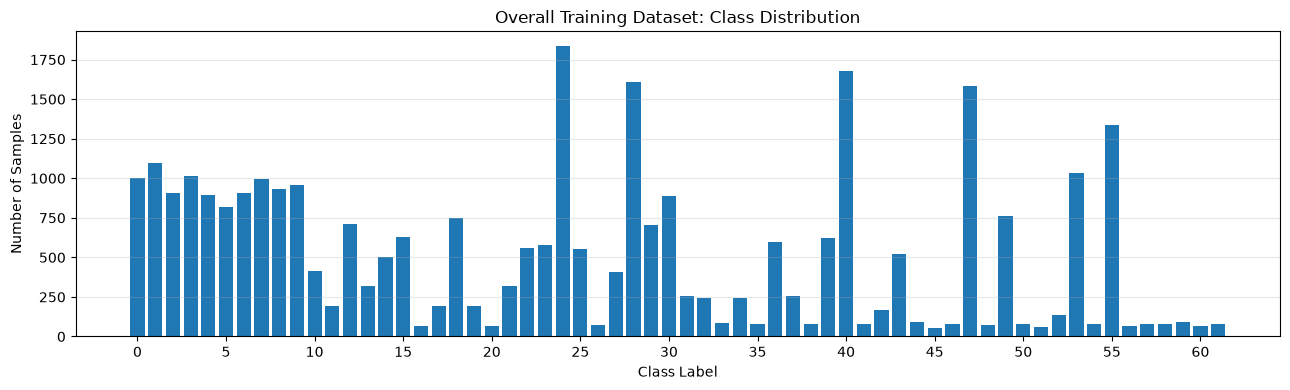

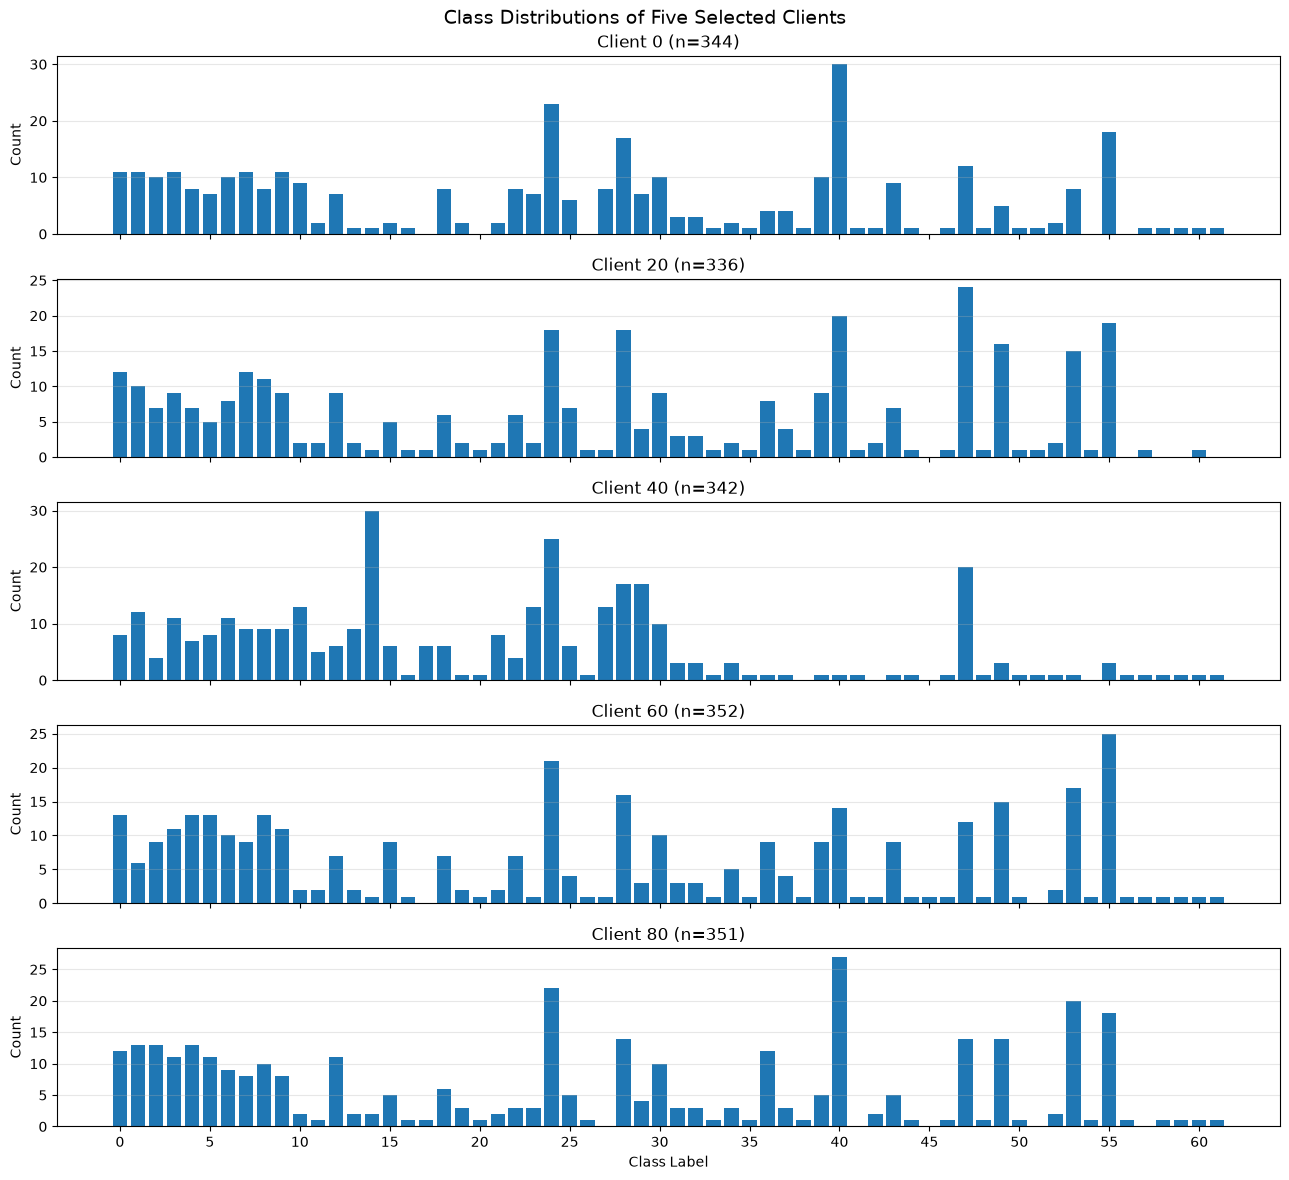


Figures saved to Output/


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Step 1.2: Class distribution analysis

num_classes = 62
selected_clients = [0, 20, 40, 60, 80]

# Count class frequencies for all clients
global_counts = np.zeros(num_classes, dtype=np.int64)
client_counts = {}

for client_id in range(len(train_data)):
    labels = np.asarray(train_data[client_id]["labels"], dtype=np.int64)

    assert np.all((labels >= 0) & (labels < num_classes))

    counts = np.bincount(labels, minlength=num_classes)
    global_counts += counts

    if client_id in selected_clients:
        client_counts[client_id] = counts

# Print statistics
print("=== Overall Dataset ===")
print("Total samples:", global_counts.sum())
print("Number of classes:", np.count_nonzero(global_counts))
print("Minimum class count:", global_counts.min())
print("Maximum class count:", global_counts.max())
print("Imbalance ratio:", round(global_counts.max() / global_counts.min(), 2))

print("\n=== Selected Clients ===")
for client_id in selected_clients:
    counts = client_counts[client_id]
    print(
        f"Client {client_id}: "
        f"samples={counts.sum()}, "
        f"classes={np.count_nonzero(counts)}, "
        f"most_common_class={np.argmax(counts)}"
    )

# Create output directory
output_dir = Path("Output")
output_dir.mkdir(exist_ok=True)

# Figure 1: Overall class distribution
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(np.arange(num_classes), global_counts)
ax.set_title("Overall Training Dataset: Class Distribution")
ax.set_xlabel("Class Label")
ax.set_ylabel("Number of Samples")
ax.set_xticks(np.arange(0, num_classes, 5))
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "overall_class_distribution.png", dpi=200)
plt.show()
plt.close(fig)

# Figure 2: Five selected clients
fig, axes = plt.subplots(5, 1, figsize=(13, 12), sharex=True)

for ax, client_id in zip(axes, selected_clients):
    counts = client_counts[client_id]
    ax.bar(np.arange(num_classes), counts)
    ax.set_title(f"Client {client_id} (n={counts.sum()})")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.3)

axes[-1].set_xlabel("Class Label")
axes[-1].set_xticks(np.arange(0, num_classes, 5))

fig.suptitle("Class Distributions of Five Selected Clients", fontsize=14)
fig.tight_layout()
fig.savefig(output_dir / "five_clients_class_distribution.png", dpi=200)
plt.show()
plt.close(fig)

print("\nFigures saved to Output/")


In [4]:

import numpy as np

# Step 2: Local training and validation split

NUM_CLIENTS = len(train_data)
SEED = 42
TRAIN_RATIO = 0.8

client_splits = {}

total_train = 0
total_val = 0

for client_id in range(NUM_CLIENTS):
    # Number of local samples
    n_samples = len(train_data[client_id]["labels"])

    # Independent and reproducible random split
    rng = np.random.default_rng(SEED + client_id)
    indices = rng.permutation(n_samples)

    n_train = int(TRAIN_RATIO * n_samples)

    train_idx = indices[:n_train]
    val_idx = indices[n_train:]

    # Store indices without copying images
    client_splits[client_id] = {
        "train_idx": train_idx,
        "val_idx": val_idx
    }

    total_train += len(train_idx)
    total_val += len(val_idx)

# Verify all local splits
for client_id in range(NUM_CLIENTS):
    train_idx = client_splits[client_id]["train_idx"]
    val_idx = client_splits[client_id]["val_idx"]

    n_samples = len(train_data[client_id]["labels"])

    assert len(train_idx) > 0
    assert len(val_idx) > 0
    assert len(train_idx) + len(val_idx) == n_samples
    assert len(np.unique(np.concatenate([train_idx, val_idx]))) == n_samples
    assert np.all(train_idx >= 0) and np.all(train_idx < n_samples)
    assert np.all(val_idx >= 0) and np.all(val_idx < n_samples)

# Global summary
print("=== Data Split Summary ===")
print("Number of clients:", NUM_CLIENTS)
print("Original samples:", total_train + total_val)
print("Training samples:", total_train)
print("Validation samples:", total_val)
print("Training ratio:", f"{total_train / (total_train + total_val):.2%}")
print("Validation ratio:", f"{total_val / (total_train + total_val):.2%}")

print("\n=== Selected Client Splits ===")
for client_id in [0, 20, 40, 60, 80]:
    split = client_splits[client_id]
    print(
        f"Client {client_id}: "
        f"Train={len(split['train_idx'])}, "
        f"Val={len(split['val_idx'])}"
    )

print("\nAll client split checks: PASSED")


=== Data Split Summary ===
Number of clients: 100
Original samples: 31825
Training samples: 25418
Validation samples: 6407
Training ratio: 79.87%
Validation ratio: 20.13%

=== Selected Client Splits ===
Client 0: Train=275, Val=69
Client 20: Train=268, Val=68
Client 40: Train=273, Val=69
Client 60: Train=281, Val=71
Client 80: Train=280, Val=71

All client split checks: PASSED


In [5]:

import numpy as np
import torch
import torch.nn as nn

# Step 3.1: Define the required neural network

class FEMNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 62)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x


# Reproducible initialization
torch.manual_seed(42)

# Use CPU for this small validation test
model = FEMNISTMLP().cpu()
criterion = nn.CrossEntropyLoss()

print("=== Model Architecture ===")
print(model)

# Count trainable parameters
num_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", num_parameters)

# Use 8 real training samples from Client 0
client_id = 0
sample_idx = client_splits[client_id]["train_idx"][:8]

images = np.asarray(
    [train_data[client_id]["images"][i] for i in sample_idx],
    dtype=np.float32
)

labels = np.asarray(
    [train_data[client_id]["labels"][i] for i in sample_idx],
    dtype=np.int64
)

x = torch.from_numpy(images)
y = torch.from_numpy(labels)

# Forward pass
logits = model(x)
loss = criterion(logits, y)

print("\n=== Forward Pass ===")
print("Input shape:", tuple(x.shape))
print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 6))

# Backward pass
model.zero_grad(set_to_none=True)
loss.backward()

gradients_valid = all(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    for p in model.parameters()
)

# Verification
assert logits.shape == (8, 62)
assert torch.isfinite(loss).item()
assert gradients_valid
assert num_parameters == 108478

print("\n=== Verification ===")
print("Output dimension: PASSED")
print("Finite loss: PASSED")
print("Gradient check:", "PASSED" if gradients_valid else "FAILED")
print("Parameter count: PASSED")
print("Model validation: PASSED")

# Clear gradients after validation
model.zero_grad(set_to_none=True)


=== Model Architecture ===
FEMNISTMLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=62, bias=True)
)

Trainable parameters: 108478

=== Forward Pass ===
Input shape: (8, 28, 28)
Output shape: (8, 62)
Loss: 4.200576

=== Verification ===
Output dimension: PASSED
Finite loss: PASSED
Gradient check: PASSED
Parameter count: PASSED
Model validation: PASSED


In [6]:

import numpy as np
import torch
import torch.nn as nn

# ==========================================================
# Step 4: FedAvg Core Implementation (Part 1.1)
# Serial implementation - No Ray
# ==========================================================

# 1. Random client selection

def select_clients(round_id, client_fraction=0.10, seed=42):

    num_clients = len(client_splits)

    if not (0 < client_fraction <= 0.10):
        raise ValueError("Client fraction must be in (0, 0.10].")

    num_selected = max(1, int(round(num_clients * client_fraction)))

    rng = np.random.default_rng(seed + round_id)

    selected = rng.choice(
        num_clients,
        size=num_selected,
        replace=False
    )

    return selected.tolist()


# 2. Local client training using SGD

def train_one_client(
    client_id,
    global_state,
    local_epochs=1,
    learning_rate=0.01,
    batch_size=32,
    round_id=0
):

    if local_epochs < 1 or batch_size < 1 or learning_rate <= 0:
        raise ValueError("Invalid training hyperparameters.")

    # Access only this client's training data
    indices = client_splits[client_id]["train_idx"]
    client_data = train_data[client_id]

    images = np.asarray(
        [client_data["images"][i] for i in indices],
        dtype=np.float32
    )
    labels = np.asarray(
        [client_data["labels"][i] for i in indices],
        dtype=np.int64
    )

    x_train = torch.from_numpy(images)
    y_train = torch.from_numpy(labels)

    n_samples = len(indices)

    # Initialize local model from global parameters
    local_model = FEMNISTMLP().cpu()
    local_model.load_state_dict(global_state)
    local_model.train()

    optimizer = torch.optim.SGD(
        local_model.parameters(),
        lr=learning_rate
    )
    criterion = nn.CrossEntropyLoss()

    # Reproducible minibatch ordering
    generator = torch.Generator()
    generator.manual_seed(42 + round_id * 1000 + client_id)

    total_loss = 0.0
    total_processed = 0

    for epoch in range(local_epochs):

        permutation = torch.randperm(
            n_samples,
            generator=generator
        )

        for start in range(0, n_samples, batch_size):

            batch_idx = permutation[start:start + batch_size]

            x_batch = x_train[batch_idx]
            y_batch = y_train[batch_idx]

            optimizer.zero_grad(set_to_none=True)

            logits = local_model(x_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            batch_n = len(batch_idx)
            total_loss += loss.item() * batch_n
            total_processed += batch_n

    mean_local_loss = total_loss / total_processed

    # Return updated weights, never raw client data
    updated_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in local_model.state_dict().items()
    }

    return updated_state, n_samples, mean_local_loss


# 3. Sample-size-weighted FedAvg aggregation

def fedavg_aggregate(client_updates):

    if not client_updates:
        raise ValueError("Client updates cannot be empty.")

    total_samples = sum(
        n_samples for state, n_samples in client_updates
    )

    if total_samples <= 0:
        raise ValueError("Total sample count must be positive.")

    reference_state = client_updates[0][0]

    aggregated_state = {
        name: torch.zeros_like(tensor)
        for name, tensor in reference_state.items()
    }

    for state, n_samples in client_updates:

        weight = n_samples / total_samples

        for name in aggregated_state:
            aggregated_state[name].add_(
                state[name],
                alpha=weight
            )

    return aggregated_state


# ==========================================================
# Basic correctness checks
# ==========================================================

# Check A: Client selection
selected = select_clients(round_id=0, client_fraction=0.10)

assert len(selected) == 10
assert len(set(selected)) == 10
assert all(0 <= cid < 100 for cid in selected)

print("=== Client Selection ===")
print("Selected clients:", selected)
print("Number of clients:", len(selected))
print("Selection verification: PASSED")


# Check B: Weighted aggregation with known values
toy_updates = [
    ({"weight": torch.tensor([1.0])}, 1),
    ({"weight": torch.tensor([3.0])}, 3)
]

toy_result = fedavg_aggregate(toy_updates)

# Expected: (1*1 + 3*3) / (1+3) = 2.5
assert torch.allclose(
    toy_result["weight"],
    torch.tensor([2.5])
)

print("\n=== Weighted Aggregation ===")
print("Expected result: 2.5")
print("Actual result:", toy_result["weight"].item())
print("Aggregation verification: PASSED")

print("\nFedAvg core functions defined successfully.")
print("No client training has been executed.")


=== Client Selection ===
Selected clients: [96, 71, 8, 60, 41, 94, 68, 9, 19, 82]
Number of clients: 10
Selection verification: PASSED

=== Weighted Aggregation ===
Expected result: 2.5
Actual result: 2.5
Aggregation verification: PASSED

FedAvg core functions defined successfully.
No client training has been executed.


In [7]:

import numpy as np
import torch

# ==========================================================
# Step 4.2: Local Client Training Verification
# ==========================================================

CLIENT_ID = 0
LOCAL_EPOCHS = 1
LEARNING_RATE = 0.01
BATCH_SIZE = 32

# Initialize a reproducible global model
torch.manual_seed(42)
global_model = FEMNISTMLP().cpu()

# Save original global parameters
global_state = {
    name: tensor.detach().clone()
    for name, tensor in global_model.state_dict().items()
}

print("=== Local Training Configuration ===")
print("Client ID:", CLIENT_ID)
print("Local epochs:", LOCAL_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)

# Execute one local training update
local_state, n_samples, mean_loss = train_one_client(
    client_id=CLIENT_ID,
    global_state=global_state,
    local_epochs=LOCAL_EPOCHS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    round_id=0
)

print("\n=== Local Training Results ===")
print("Training samples:", n_samples)
print("Mean local training loss:", round(mean_loss, 6))

# Check whether local parameters changed
parameter_changes = {}

for name in global_state:
    difference = (
        local_state[name] - global_state[name]
    )

    parameter_changes[name] = (
        torch.linalg.vector_norm(difference).item()
    )

print("\n=== Parameter Changes ===")
for name, change in parameter_changes.items():
    print(f"{name}: {change:.8f}")

# Verify global parameters remain unchanged
global_unchanged = all(
    torch.equal(global_model.state_dict()[name], global_state[name])
    for name in global_state
)

# Verify updated parameters are finite
parameters_finite = all(
    torch.isfinite(tensor).all().item()
    for tensor in local_state.values()
)

# Verify at least one parameter changed
parameters_updated = any(
    change > 0 for change in parameter_changes.values()
)

# Final verification
assert n_samples == len(client_splits[CLIENT_ID]["train_idx"])
assert np.isfinite(mean_loss)
assert parameters_updated
assert parameters_finite
assert global_unchanged

print("\n=== Verification ===")
print("Correct training sample count: PASSED")
print("Finite local loss: PASSED")
print("Local parameters updated: PASSED")
print("All updated parameters finite: PASSED")
print("Global model unchanged: PASSED")
print("\nLocal training verification: PASSED")


=== Local Training Configuration ===
Client ID: 0
Local epochs: 1
Learning rate: 0.01
Batch size: 32

=== Local Training Results ===
Training samples: 275
Mean local training loss: 4.091142

=== Parameter Changes ===
fc1.weight: 0.11090010
fc1.bias: 0.00402100
fc2.weight: 0.05420267
fc2.bias: 0.01124796

=== Verification ===
Correct training sample count: PASSED
Finite local loss: PASSED
Local parameters updated: PASSED
All updated parameters finite: PASSED
Global model unchanged: PASSED

Local training verification: PASSED


In [8]:

import numpy as np
import torch

# ==========================================================
# Step 4.3: Full FedAvg Communication Round Verification
# Serial FedAvg - No Ray
# ==========================================================

ROUND_ID = 0
CLIENT_FRACTION = 0.10
LOCAL_EPOCHS = 1
LEARNING_RATE = 0.01
BATCH_SIZE = 32

# ----------------------------------------------------------
# 1. Initialize the global model
# ----------------------------------------------------------

torch.manual_seed(42)

round_model = FEMNISTMLP().cpu()

initial_state = {
    name: tensor.detach().clone()
    for name, tensor in round_model.state_dict().items()
}

# ----------------------------------------------------------
# 2. Select clients
# ----------------------------------------------------------

selected_clients = select_clients(
    round_id=ROUND_ID,
    client_fraction=CLIENT_FRACTION
)

assert len(selected_clients) == 10
assert len(set(selected_clients)) == 10

print("=== Communication Round Configuration ===")
print("Round:", ROUND_ID)
print("Selected clients:", selected_clients)
print("Number selected:", len(selected_clients))
print("Local epochs:", LOCAL_EPOCHS)

# ----------------------------------------------------------
# 3. Execute independent local training
# ----------------------------------------------------------

client_updates = []
client_losses = []

print("\n=== Local Client Training ===")

for client_id in selected_clients:

    local_state, n_samples, mean_loss = train_one_client(
        client_id=client_id,
        global_state=initial_state,
        local_epochs=LOCAL_EPOCHS,
        learning_rate=LEARNING_RATE,
        batch_size=BATCH_SIZE,
        round_id=ROUND_ID
    )

    assert n_samples == len(
        client_splits[client_id]["train_idx"]
    )
    assert np.isfinite(mean_loss)

    client_updates.append((local_state, n_samples))
    client_losses.append(mean_loss)

    print(
        f"Client {client_id:3d} | "
        f"Samples: {n_samples:3d} | "
        f"Local Loss: {mean_loss:.6f}"
    )

# ----------------------------------------------------------
# 4. Server weighted aggregation
# ----------------------------------------------------------

total_samples = sum(n for _, n in client_updates)

weights = [
    n / total_samples
    for _, n in client_updates
]

assert np.isclose(sum(weights), 1.0)

aggregated_state = fedavg_aggregate(client_updates)

# Verify aggregation independently using float64
for name in aggregated_state:

    expected = sum(
        (
            state[name].to(torch.float64) * (n / total_samples)
            for state, n in client_updates
        )
    )

    assert torch.allclose(
        aggregated_state[name].to(torch.float64),
        expected,
        atol=1e-6,
        rtol=1e-5
    )

# ----------------------------------------------------------
# 5. Update global model
# ----------------------------------------------------------

round_model.load_state_dict(aggregated_state)

parameter_changes = {}

for name in initial_state:
    difference = (
        round_model.state_dict()[name] - initial_state[name]
    )

    parameter_changes[name] = (
        torch.linalg.vector_norm(difference).item()
    )

global_updated = any(
    value > 0 for value in parameter_changes.values()
)

parameters_finite = all(
    torch.isfinite(tensor).all().item()
    for tensor in round_model.state_dict().values()
)

# Weighted average of local training losses
weighted_local_loss = sum(
    loss * n
    for loss, (_, n) in zip(client_losses, client_updates)
) / total_samples

# ----------------------------------------------------------
# 6. Results and verification
# ----------------------------------------------------------

print("\n=== Server Aggregation ===")
print("Total participating training samples:", total_samples)
print("Sum of aggregation weights:", round(sum(weights), 8))
print("Weighted local training loss:", round(weighted_local_loss, 6))

print("\n=== Global Parameter Changes ===")
for name, value in parameter_changes.items():
    print(f"{name}: {value:.8f}")

assert global_updated
assert parameters_finite

print("\n=== Verification ===")
print("Client selection: PASSED")
print("Local training: PASSED")
print("Aggregation weights: PASSED")
print("Weighted aggregation: PASSED")
print("Global model updated: PASSED")
print("All global parameters finite: PASSED")

print("\nFull communication round verification: PASSED")


=== Communication Round Configuration ===
Round: 0
Selected clients: [96, 71, 8, 60, 41, 94, 68, 9, 19, 82]
Number selected: 10
Local epochs: 1

=== Local Client Training ===
Client  96 | Samples: 223 | Local Loss: 4.089575
Client  71 | Samples: 264 | Local Loss: 4.062369
Client   8 | Samples: 305 | Local Loss: 4.072754
Client  60 | Samples: 281 | Local Loss: 4.092990
Client  41 | Samples: 228 | Local Loss: 4.045460
Client  94 | Samples: 309 | Local Loss: 4.078128
Client  68 | Samples: 216 | Local Loss: 4.076318
Client   9 | Samples: 240 | Local Loss: 4.124426
Client  19 | Samples: 249 | Local Loss: 4.100834
Client  82 | Samples: 267 | Local Loss: 4.076866

=== Server Aggregation ===
Total participating training samples: 2582
Sum of aggregation weights: 1.0
Weighted local training loss: 4.081814

=== Global Parameter Changes ===
fc1.weight: 0.08822081
fc1.bias: 0.00322414
fc2.weight: 0.04280823
fc2.bias: 0.00914927

=== Verification ===
Client selection: PASSED
Local training: PASSED
A

In [9]:

import numpy as np
import torch
import torch.nn.functional as F

# ==========================================================
# Step 5.1: Global Model Evaluation
# ==========================================================

def evaluate_global_model(
    model,
    split="train",
    batch_size=128
):
    if split not in ("train", "val"):
        raise ValueError("split must be 'train' or 'val'.")

    if batch_size < 1:
        raise ValueError("batch_size must be positive.")

    index_key = (
        "train_idx" if split == "train" else "val_idx"
    )

    was_training = model.training
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    # No gradients needed during evaluation
    with torch.inference_mode():

        for client_id in range(len(train_data)):

            indices = client_splits[client_id][index_key]
            client_data = train_data[client_id]

            # Evaluate one client in small batches
            for start in range(0, len(indices), batch_size):

                batch_indices = indices[start:start + batch_size]

                images = np.asarray(
                    [
                        client_data["images"][int(i)]
                        for i in batch_indices
                    ],
                    dtype=np.float32
                )

                labels = np.asarray(
                    [
                        client_data["labels"][int(i)]
                        for i in batch_indices
                    ],
                    dtype=np.int64
                )

                x = torch.from_numpy(images)
                y = torch.from_numpy(labels)

                # Forward pass using the global model
                logits = model(x)

                # Sum cross-entropy over samples
                loss_sum = F.cross_entropy(
                    logits,
                    y,
                    reduction="sum"
                )

                predictions = torch.argmax(logits, dim=1)

                total_loss += loss_sum.item()
                total_correct += (
                    predictions == y
                ).sum().item()

                total_samples += len(batch_indices)

    model.train(was_training)

    if total_samples == 0:
        raise RuntimeError("No evaluation samples found.")

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "correct": total_correct,
        "samples": total_samples
    }


# ==========================================================
# Verify evaluation using the Step 4.3 global model
# ==========================================================

# Save global parameters before evaluation
state_before = {
    name: tensor.detach().clone()
    for name, tensor in round_model.state_dict().items()
}

print("=== Global Model Evaluation ===")
print("Model: Global model after communication round 0")

# Training evaluation
train_metrics = evaluate_global_model(
    round_model,
    split="train",
    batch_size=128
)

# Validation evaluation
val_metrics = evaluate_global_model(
    round_model,
    split="val",
    batch_size=128
)

print("\n=== Training Metrics ===")
print("Samples:", train_metrics["samples"])
print("Loss:", round(train_metrics["loss"], 6))
print("Accuracy:", f"{train_metrics['accuracy']:.4%}")

print("\n=== Validation Metrics ===")
print("Samples:", val_metrics["samples"])
print("Loss:", round(val_metrics["loss"], 6))
print("Accuracy:", f"{val_metrics['accuracy']:.4%}")

# ==========================================================
# Correctness verification
# ==========================================================

assert train_metrics["samples"] == 25418
assert val_metrics["samples"] == 6407

assert np.isfinite(train_metrics["loss"])
assert np.isfinite(val_metrics["loss"])

assert 0 <= train_metrics["accuracy"] <= 1
assert 0 <= val_metrics["accuracy"] <= 1

# Evaluation must not modify the global model
model_unchanged = all(
    torch.equal(
        round_model.state_dict()[name],
        state_before[name]
    )
    for name in state_before
)

assert model_unchanged

print("\n=== Verification ===")
print("Training sample count: PASSED")
print("Validation sample count: PASSED")
print("Finite losses: PASSED")
print("Valid accuracy ranges: PASSED")
print("Global model unchanged: PASSED")
print("\nGlobal evaluation verification: PASSED")


=== Global Model Evaluation ===
Model: Global model after communication round 0

=== Training Metrics ===
Samples: 25418
Loss: 4.025
Accuracy: 4.2372%

=== Validation Metrics ===
Samples: 6407
Loss: 4.02563
Accuracy: 4.3702%

=== Verification ===
Training sample count: PASSED
Validation sample count: PASSED
Finite losses: PASSED
Valid accuracy ranges: PASSED
Global model unchanged: PASSED

Global evaluation verification: PASSED


In [11]:

import os
import csv
import json
import time
import hashlib
import shutil
from pathlib import Path

import numpy as np
import torch

# ==========================================================
# Step 5.2: Formal FedAvg Baseline Training
# Part 1.1 - Serial FedAvg
# ==========================================================

CONFIG = {
    "num_clients": 100,
    "client_fraction": 0.10,
    "local_epochs": 1,
    "learning_rate": 0.01,
    "batch_size": 32,
    "seed": 42,
    "planned_rounds": 400
}

# Run the first 100 rounds.
# Later change to 200, 300, or 400 to continue.
TARGET_ROUND = 400
SAVE_EVERY = 10

output_dir = Path("Output/FedAvg_Baseline_C10_E1")
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = output_dir / "latest_checkpoint.pt"
best_path = output_dir / "best_checkpoint.pt"
history_path = output_dir / "training_history.csv"
config_path = output_dir / "training_config.json"

# ----------------------------------------------------------
# 1. Environment and data checks
# ----------------------------------------------------------

assert len(train_data) == CONFIG["num_clients"]
assert len(client_splits) == CONFIG["num_clients"]
assert 0 <= TARGET_ROUND <= CONFIG["planned_rounds"]

torch.set_num_threads(min(4, os.cpu_count() or 1))

# Fingerprint of the fixed train/validation split
split_hash = hashlib.sha256()

for cid in range(CONFIG["num_clients"]):
    for key in ("train_idx", "val_idx"):
        indices = np.asarray(
            client_splits[cid][key], dtype=np.int64
        )
        split_hash.update(indices.tobytes())

split_fingerprint = split_hash.hexdigest()

free_gb = shutil.disk_usage(output_dir).free / (1024 ** 3)

print("=== Environment ===")
print("PyTorch:", torch.__version__)
print("CPU threads:", torch.get_num_threads())
print("Available disk space (GB):", round(free_gb, 2))
print("Checkpoint directory:", output_dir)

if free_gb < 0.2:
    raise RuntimeError("Insufficient disk space.")

# ----------------------------------------------------------
# 2. Check configuration consistency
# ----------------------------------------------------------

if config_path.exists():
    with open(config_path, "r") as f:
        saved_config = json.load(f)

    assert saved_config == CONFIG, (
        "Configuration changed. Use a separate experiment folder."
    )
else:
    if checkpoint_path.exists():
        raise RuntimeError(
            "Checkpoint exists but configuration file is missing."
        )

    with open(config_path, "w") as f:
        json.dump(CONFIG, f, indent=4)

# ----------------------------------------------------------
# 3. Initialize or restore training
# ----------------------------------------------------------

if checkpoint_path.exists():

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["config"] == CONFIG
    assert checkpoint["split_fingerprint"] == split_fingerprint

    global_model = FEMNISTMLP().cpu()
    global_model.load_state_dict(checkpoint["model_state"])

    history = checkpoint["history"]
    best_state = checkpoint["best_state"]

    best_val_acc = checkpoint["best_val_acc"]
    best_val_loss = checkpoint["best_val_loss"]
    best_round = checkpoint["best_round"]

    last_round = checkpoint["last_round"]

    assert history[-1]["round"] == last_round

    print("\n=== Resuming Training ===")
    print("Last completed round:", last_round)
    print("Best validation accuracy:", f"{best_val_acc:.4%}")

else:

    if history_path.exists() or best_path.exists():
        raise RuntimeError(
            "Existing results found without a checkpoint. "
            "Use a new experiment folder."
        )

    torch.manual_seed(CONFIG["seed"])
    np.random.seed(CONFIG["seed"])

    global_model = FEMNISTMLP().cpu()

    print("\n=== Initial Model Evaluation ===")

    initial_train = evaluate_global_model(
        global_model, split="train", batch_size=128
    )
    initial_val = evaluate_global_model(
        global_model, split="val", batch_size=128
    )

    history = [{
        "round": 0,
        "train_loss": float(initial_train["loss"]),
        "val_loss": float(initial_val["loss"]),
        "train_accuracy": float(initial_train["accuracy"]),
        "val_accuracy": float(initial_val["accuracy"]),
        "selected_clients": 0,
        "participating_samples": 0
    }]

    best_val_acc = float(initial_val["accuracy"])
    best_val_loss = float(initial_val["loss"])
    best_round = 0

    best_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in global_model.state_dict().items()
    }

    last_round = 0

    print("Initial training loss:", round(initial_train["loss"], 6))
    print("Initial validation loss:", round(initial_val["loss"], 6))
    print("Initial training accuracy:",
          f"{initial_train['accuracy']:.4%}")
    print("Initial validation accuracy:",
          f"{initial_val['accuracy']:.4%}")

# ----------------------------------------------------------
# 4. Atomic checkpoint and history saving
# ----------------------------------------------------------

fieldnames = [
    "round",
    "train_loss",
    "val_loss",
    "train_accuracy",
    "val_accuracy",
    "selected_clients",
    "participating_samples"
]

def save_progress(completed_round):

    checkpoint_data = {
        "last_round": completed_round,
        "model_state": {
            name: tensor.detach().cpu().clone()
            for name, tensor in global_model.state_dict().items()
        },
        "best_state": best_state,
        "best_val_acc": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_round": best_round,
        "history": history,
        "config": CONFIG,
        "split_fingerprint": split_fingerprint
    }

    # Save to temporary files first, then replace atomically.
    tmp_checkpoint = checkpoint_path.with_suffix(".tmp")
    torch.save(checkpoint_data, tmp_checkpoint)
    os.replace(tmp_checkpoint, checkpoint_path)

    tmp_best = best_path.with_suffix(".tmp")
    torch.save({
        "round": best_round,
        "model_state": best_state,
        "val_accuracy": best_val_acc,
        "val_loss": best_val_loss,
        "config": CONFIG
    }, tmp_best)
    os.replace(tmp_best, best_path)

    tmp_history = history_path.with_suffix(".tmp")

    with open(tmp_history, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(history)

    os.replace(tmp_history, history_path)


# Save round 0 before starting any local training.
if last_round == 0 and not checkpoint_path.exists():
    save_progress(0)

# ----------------------------------------------------------
# 5. Formal FedAvg training loop
# ----------------------------------------------------------

print("\n=== Formal FedAvg Training ===")
print("Starting from round:", last_round)
print("Target round:", TARGET_ROUND)
print("Client fraction:", CONFIG["client_fraction"])
print("Local epochs:", CONFIG["local_epochs"])

training_start = time.perf_counter()

for round_number in range(last_round + 1, TARGET_ROUND + 1):

    # The first communication round uses round_id=0.
    round_id = round_number - 1

    selected_clients = select_clients(
        round_id=round_id,
        client_fraction=CONFIG["client_fraction"],
        seed=CONFIG["seed"]
    )

    # Snapshot shared by all selected clients
    global_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in global_model.state_dict().items()
    }

    client_updates = []
    participating_samples = 0

    # Sequential local training
    for client_id in selected_clients:

        local_state, n_samples, local_loss = train_one_client(
            client_id=client_id,
            global_state=global_state,
            local_epochs=CONFIG["local_epochs"],
            learning_rate=CONFIG["learning_rate"],
            batch_size=CONFIG["batch_size"],
            round_id=round_id
        )

        client_updates.append((local_state, n_samples))
        participating_samples += n_samples

    # Server weighted aggregation
    aggregated_state = fedavg_aggregate(client_updates)
    global_model.load_state_dict(aggregated_state)

    # Evaluate the updated global model
    train_metrics = evaluate_global_model(
        global_model, split="train", batch_size=128
    )

    val_metrics = evaluate_global_model(
        global_model, split="val", batch_size=128
    )

    assert train_metrics["samples"] == 25418
    assert val_metrics["samples"] == 6407

    for metric in (train_metrics, val_metrics):
        assert np.isfinite(metric["loss"])
        assert np.isfinite(metric["accuracy"])

    # Record the round
    record = {
        "round": round_number,
        "train_loss": float(train_metrics["loss"]),
        "val_loss": float(val_metrics["loss"]),
        "train_accuracy": float(train_metrics["accuracy"]),
        "val_accuracy": float(val_metrics["accuracy"]),
        "selected_clients": len(selected_clients),
        "participating_samples": participating_samples
    }

    history.append(record)

    # Select the best model using validation data only
    current_acc = record["val_accuracy"]
    current_loss = record["val_loss"]

    if (
        current_acc > best_val_acc
        or (
            current_acc == best_val_acc
            and current_loss < best_val_loss
        )
    ):

        best_val_acc = current_acc
        best_val_loss = current_loss
        best_round = round_number

        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in global_model.state_dict().items()
        }

    # Periodic checkpoint
    if (
        round_number % SAVE_EVERY == 0
        or round_number == TARGET_ROUND
    ):

        save_progress(round_number)

        elapsed = time.perf_counter() - training_start

        print(
            f"Round {round_number:3d} | "
            f"Train Loss: {record['train_loss']:.4f} | "
            f"Val Loss: {record['val_loss']:.4f} | "
            f"Train Acc: {record['train_accuracy']:.2%} | "
            f"Val Acc: {record['val_accuracy']:.2%} | "
            f"Best Val Acc: {best_val_acc:.2%} | "
            f"Elapsed: {elapsed:.1f}s"
        )

# ----------------------------------------------------------
# 6. Final summary
# ----------------------------------------------------------

print("\n=== Training Summary ===")
print("Last completed round:", history[-1]["round"])
print("Best round:", best_round)
print("Best validation accuracy:", f"{best_val_acc:.4%}")
print("Best validation loss:", round(best_val_loss, 6))
print("History records:", len(history))

print("\n=== Saved Files ===")
print(checkpoint_path)
print(best_path)
print(history_path)
print(config_path)

print("\nTraining segment completed successfully.")


=== Environment ===
PyTorch: 2.14.1+cu126
CPU threads: 4
Available disk space (GB): 606.2
Checkpoint directory: Output\FedAvg_Baseline_C10_E1

=== Resuming Training ===
Last completed round: 100
Best validation accuracy: 16.1074%

=== Formal FedAvg Training ===
Starting from round: 100
Target round: 400
Client fraction: 0.1
Local epochs: 1
Round 110 | Train Loss: 3.5574 | Val Loss: 3.5598 | Train Acc: 13.88% | Val Acc: 14.52% | Best Val Acc: 16.81% | Elapsed: 10.9s
Round 120 | Train Loss: 3.5336 | Val Loss: 3.5345 | Train Acc: 14.13% | Val Acc: 14.28% | Best Val Acc: 16.81% | Elapsed: 20.9s
Round 130 | Train Loss: 3.4957 | Val Loss: 3.4973 | Train Acc: 14.61% | Val Acc: 15.23% | Best Val Acc: 17.23% | Elapsed: 30.6s
Round 140 | Train Loss: 3.4663 | Val Loss: 3.4668 | Train Acc: 13.85% | Val Acc: 14.61% | Best Val Acc: 18.82% | Elapsed: 40.3s
Round 150 | Train Loss: 3.4280 | Val Loss: 3.4298 | Train Acc: 14.69% | Val Acc: 15.34% | Best Val Acc: 19.95% | Elapsed: 51.1s
Round 160 | Train 

=== Training History Preview ===
   round  train_loss  val_loss  train_accuracy  val_accuracy  \
0      0    4.145731  4.148088        0.022268      0.018730   
1      1    4.025000  4.025630        0.042372      0.043702   
2      2    3.937960  3.937295        0.042096      0.041049   
3      3    3.870681  3.868647        0.046935      0.045263   
4      4    3.825474  3.822144        0.057204      0.059466   

   selected_clients  participating_samples  
0                 0                      0  
1                10                   2582  
2                10                   2635  
3                10                   2656  
4                10                   2459  

=== Training History Summary ===
Number of records: 401
Rounds covered: 0 to 400


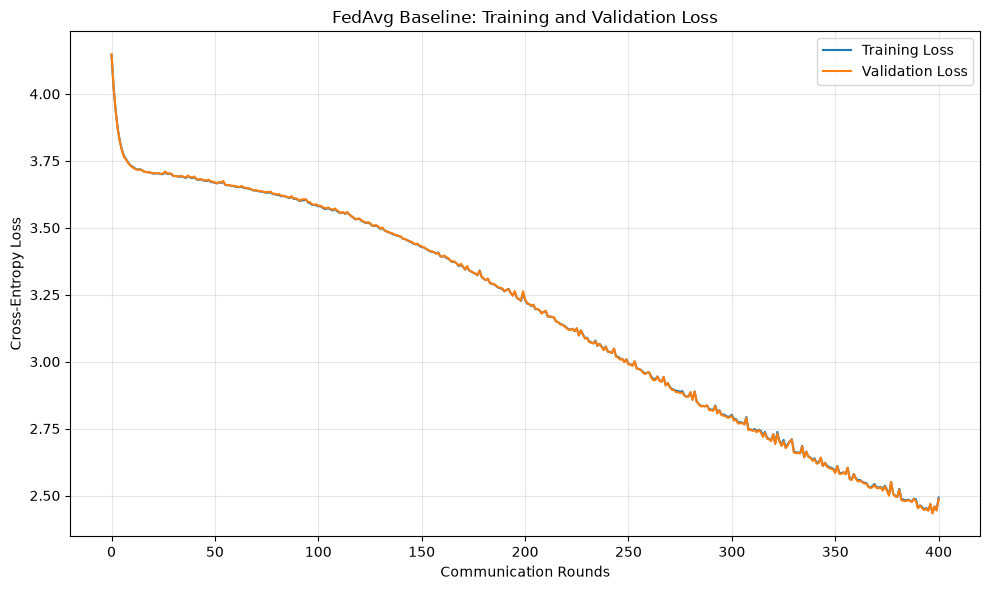

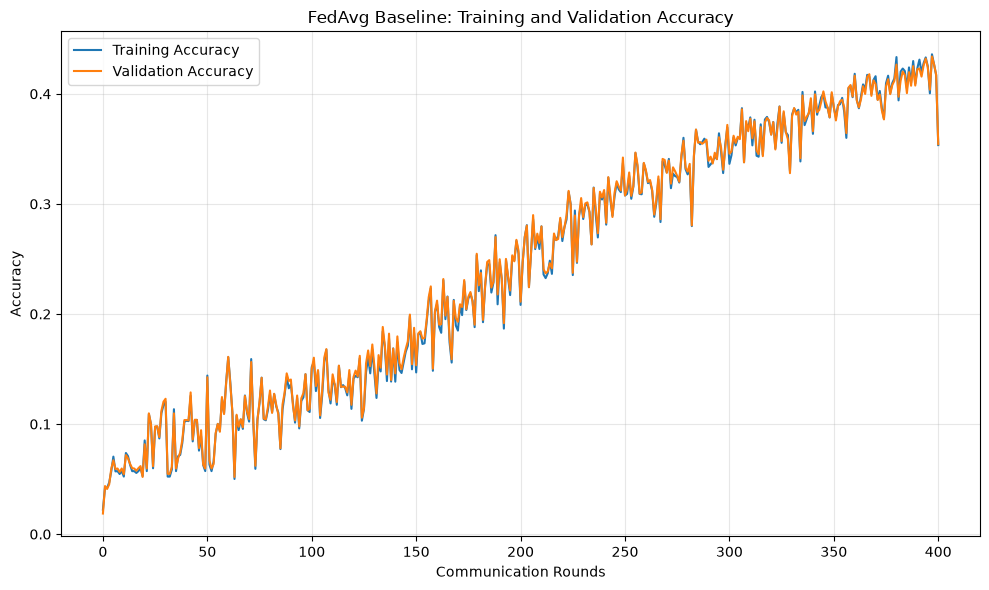


=== Best Validation Round ===
Best round: 397
Training loss: 2.43532
Validation loss: 2.432762
Training accuracy: 43.5912%
Validation accuracy: 43.3900%

Figures saved:
Output\Q2_loss_vs_rounds.png
Output\Q2_accuracy_vs_rounds.png


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================================
# Q2: Plot aggregated training and validation curves
# ==========================================================

history_path = Path("Output/FedAvg_Baseline_C10_E1/training_history.csv")
output_dir = Path("Output")
output_dir.mkdir(exist_ok=True)

# Load history
history = pd.read_csv(history_path)

print("=== Training History Preview ===")
print(history.head())

print("\n=== Training History Summary ===")
print("Number of records:", len(history))
print("Rounds covered:", history["round"].min(), "to", history["round"].max())

# ----------------------------------------------------------
# Figure 1: Training and Validation Loss
# ----------------------------------------------------------

plt.figure(figsize=(10, 6))
plt.plot(history["round"], history["train_loss"], label="Training Loss")
plt.plot(history["round"], history["val_loss"], label="Validation Loss")
plt.xlabel("Communication Rounds")
plt.ylabel("Cross-Entropy Loss")
plt.title("FedAvg Baseline: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "Q2_loss_vs_rounds.png", dpi=200)
plt.show()
plt.close()

# ----------------------------------------------------------
# Figure 2: Training and Validation Accuracy
# ----------------------------------------------------------

plt.figure(figsize=(10, 6))
plt.plot(history["round"], history["train_accuracy"], label="Training Accuracy")
plt.plot(history["round"], history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Communication Rounds")
plt.ylabel("Accuracy")
plt.title("FedAvg Baseline: Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "Q2_accuracy_vs_rounds.png", dpi=200)
plt.show()
plt.close()

# ----------------------------------------------------------
# Optional: identify the best validation round
# ----------------------------------------------------------

best_idx = history["val_accuracy"].idxmax()
best_row = history.loc[best_idx]

print("\n=== Best Validation Round ===")
print("Best round:", int(best_row["round"]))
print("Training loss:", round(best_row["train_loss"], 6))
print("Validation loss:", round(best_row["val_loss"], 6))
print("Training accuracy:", f"{best_row['train_accuracy']:.4%}")
print("Validation accuracy:", f"{best_row['val_accuracy']:.4%}")

print("\nFigures saved:")
print(output_dir / "Q2_loss_vs_rounds.png")
print(output_dir / "Q2_accuracy_vs_rounds.png")

In [13]:

import os
import csv
import json
import time
import hashlib
import shutil
from pathlib import Path

import numpy as np
import torch

# ==========================================================
# Q4: Reusable FedAvg Experiment Runner
# Serial FedAvg - No Ray
# ==========================================================

def run_q4_experiment(
    client_fraction,
    local_epochs,
    experiment_name,
    target_round=400,
    save_every=10
):
    config = {
        "num_clients": 100,
        "client_fraction": client_fraction,
        "local_epochs": local_epochs,
        "learning_rate": 0.01,
        "batch_size": 32,
        "seed": 42,
        "planned_rounds": 400
    }

    output_dir = Path("Output") / experiment_name
    output_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = output_dir / "latest_checkpoint.pt"
    best_path = output_dir / "best_checkpoint.pt"
    history_path = output_dir / "training_history.csv"
    config_path = output_dir / "training_config.json"

    assert len(train_data) == 100
    assert len(client_splits) == 100
    assert 0 <= target_round <= 400
    assert 0 < client_fraction <= 0.10
    assert local_epochs >= 1

    torch.set_num_threads(min(4, os.cpu_count() or 1))

    free_gb = shutil.disk_usage(output_dir).free / (1024 ** 3)
    if free_gb < 0.2:
        raise RuntimeError("Insufficient disk space.")

    # Verify fixed training/validation split
    split_hash = hashlib.sha256()

    for cid in range(100):
        for key in ("train_idx", "val_idx"):
            indices = np.asarray(
                client_splits[cid][key], dtype=np.int64
            )
            split_hash.update(indices.tobytes())

    split_fingerprint = split_hash.hexdigest()

    print("=== Experiment Configuration ===")
    print("Experiment:", experiment_name)
    print("Client fraction:", client_fraction)
    print("Local epochs:", local_epochs)
    print("Target rounds:", target_round)
    print("Learning rate:", config["learning_rate"])
    print("Batch size:", config["batch_size"])
    print("Device: CPU")
    print("Available disk (GB):", round(free_gb, 2))

    # Configuration consistency
    if config_path.exists():
        with open(config_path, "r") as f:
            assert json.load(f) == config
    else:
        if checkpoint_path.exists():
            raise RuntimeError(
                "Checkpoint exists without configuration."
            )
        with open(config_path, "w") as f:
            json.dump(config, f, indent=4)

    # ------------------------------------------------------
    # Initialize or resume
    # ------------------------------------------------------

    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["config"] == config
        assert checkpoint["split_fingerprint"] == split_fingerprint

        global_model = FEMNISTMLP().cpu()
        global_model.load_state_dict(checkpoint["model_state"])

        history = checkpoint["history"]
        best_state = checkpoint["best_state"]
        best_val_acc = checkpoint["best_val_acc"]
        best_val_loss = checkpoint["best_val_loss"]
        best_round = checkpoint["best_round"]
        last_round = checkpoint["last_round"]

        assert history[-1]["round"] == last_round

        print("\n=== Resuming Training ===")
        print("Last completed round:", last_round)

    else:
        if history_path.exists() or best_path.exists():
            raise RuntimeError(
                "Existing results found without checkpoint."
            )

        torch.manual_seed(config["seed"])
        np.random.seed(config["seed"])

        global_model = FEMNISTMLP().cpu()

        initial_train = evaluate_global_model(
            global_model, split="train", batch_size=128
        )
        initial_val = evaluate_global_model(
            global_model, split="val", batch_size=128
        )

        history = [{
            "round": 0,
            "train_loss": float(initial_train["loss"]),
            "val_loss": float(initial_val["loss"]),
            "train_accuracy": float(initial_train["accuracy"]),
            "val_accuracy": float(initial_val["accuracy"]),
            "selected_clients": 0,
            "participating_samples": 0
        }]

        best_val_acc = float(initial_val["accuracy"])
        best_val_loss = float(initial_val["loss"])
        best_round = 0

        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in global_model.state_dict().items()
        }

        last_round = 0

        print("\n=== Initial Model ===")
        print("Train accuracy:", f"{initial_train['accuracy']:.4%}")
        print("Validation accuracy:", f"{initial_val['accuracy']:.4%}")

    # ------------------------------------------------------
    # Checkpoint saving
    # ------------------------------------------------------

    fieldnames = [
        "round", "train_loss", "val_loss",
        "train_accuracy", "val_accuracy",
        "selected_clients", "participating_samples"
    ]

    def save_progress(completed_round):
        checkpoint_data = {
            "last_round": completed_round,
            "model_state": {
                name: tensor.detach().cpu().clone()
                for name, tensor in global_model.state_dict().items()
            },
            "best_state": best_state,
            "best_val_acc": best_val_acc,
            "best_val_loss": best_val_loss,
            "best_round": best_round,
            "history": history,
            "config": config,
            "split_fingerprint": split_fingerprint
        }

        tmp = checkpoint_path.with_suffix(".tmp")
        torch.save(checkpoint_data, tmp)
        os.replace(tmp, checkpoint_path)

        tmp = best_path.with_suffix(".tmp")
        torch.save({
            "round": best_round,
            "model_state": best_state,
            "val_accuracy": best_val_acc,
            "val_loss": best_val_loss,
            "config": config
        }, tmp)
        os.replace(tmp, best_path)

        tmp = history_path.with_suffix(".tmp")
        with open(tmp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writeheader()
            writer.writerows(history)
        os.replace(tmp, history_path)

    if last_round == 0 and not checkpoint_path.exists():
        save_progress(0)

    # ------------------------------------------------------
    # Formal FedAvg training
    # ------------------------------------------------------

    print("\n=== Training ===")
    print("Starting round:", last_round)
    print("Target round:", target_round)

    start_time = time.perf_counter()

    for round_number in range(last_round + 1, target_round + 1):
        round_id = round_number - 1

        selected_clients = select_clients(
            round_id=round_id,
            client_fraction=client_fraction,
            seed=config["seed"]
        )

        global_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in global_model.state_dict().items()
        }

        client_updates = []
        participating_samples = 0

        for client_id in selected_clients:
            local_state, n_samples, local_loss = train_one_client(
                client_id=client_id,
                global_state=global_state,
                local_epochs=local_epochs,
                learning_rate=config["learning_rate"],
                batch_size=config["batch_size"],
                round_id=round_id
            )

            client_updates.append((local_state, n_samples))
            participating_samples += n_samples

        aggregated_state = fedavg_aggregate(client_updates)
        global_model.load_state_dict(aggregated_state)

        train_metrics = evaluate_global_model(
            global_model, split="train", batch_size=128
        )
        val_metrics = evaluate_global_model(
            global_model, split="val", batch_size=128
        )

        assert train_metrics["samples"] == 25418
        assert val_metrics["samples"] == 6407
        assert np.isfinite(train_metrics["loss"])
        assert np.isfinite(val_metrics["loss"])
        assert np.isfinite(train_metrics["accuracy"])
        assert np.isfinite(val_metrics["accuracy"])

        record = {
            "round": round_number,
            "train_loss": float(train_metrics["loss"]),
            "val_loss": float(val_metrics["loss"]),
            "train_accuracy": float(train_metrics["accuracy"]),
            "val_accuracy": float(val_metrics["accuracy"]),
            "selected_clients": len(selected_clients),
            "participating_samples": participating_samples
        }

        history.append(record)

        current_acc = record["val_accuracy"]
        current_loss = record["val_loss"]

        if (
            current_acc > best_val_acc
            or (
                current_acc == best_val_acc
                and current_loss < best_val_loss
            )
        ):
            best_val_acc = current_acc
            best_val_loss = current_loss
            best_round = round_number

            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in global_model.state_dict().items()
            }

        if (
            round_number % save_every == 0
            or round_number == target_round
        ):
            save_progress(round_number)

            elapsed = time.perf_counter() - start_time

            print(
                f"Round {round_number:3d} | "
                f"Train Loss: {record['train_loss']:.4f} | "
                f"Val Loss: {record['val_loss']:.4f} | "
                f"Train Acc: {record['train_accuracy']:.2%} | "
                f"Val Acc: {record['val_accuracy']:.2%} | "
                f"Best Val Acc: {best_val_acc:.2%} | "
                f"Elapsed: {elapsed:.1f}s"
            )

    # ------------------------------------------------------
    # Final summary
    # ------------------------------------------------------

    print("\n=== Training Summary ===")
    print("Experiment:", experiment_name)
    print("Last completed round:", history[-1]["round"])
    print("Best round:", best_round)
    print("Best validation accuracy:", f"{best_val_acc:.4%}")
    print("Best validation loss:", round(best_val_loss, 6))
    print("History records:", len(history))
    print("Total segment time (s):",
          round(time.perf_counter() - start_time, 2))

    print("\nResults saved to:", output_dir)
    print("Training segment completed successfully.")

    return history


# ==========================================================
# Experiment 1: C=5%, E=1, R=400
# ==========================================================

history_C05_E1 = run_q4_experiment(
    client_fraction=0.05,
    local_epochs=1,
    experiment_name="FedAvg_C05_E1",
    target_round=400,
    save_every=10
)


=== Experiment Configuration ===
Experiment: FedAvg_C05_E1
Client fraction: 0.05
Local epochs: 1
Target rounds: 400
Learning rate: 0.01
Batch size: 32
Device: CPU
Available disk (GB): 606.2

=== Initial Model ===
Train accuracy: 2.2268%
Validation accuracy: 1.8730%

=== Training ===
Starting round: 0
Target round: 400
Round  10 | Train Loss: 3.7276 | Val Loss: 3.7273 | Train Acc: 5.70% | Val Acc: 5.82% | Best Val Acc: 5.98% | Elapsed: 7.8s
Round  20 | Train Loss: 3.7203 | Val Loss: 3.7227 | Train Acc: 5.72% | Val Acc: 5.96% | Best Val Acc: 10.91% | Elapsed: 16.3s
Round  30 | Train Loss: 3.6992 | Val Loss: 3.6998 | Train Acc: 6.85% | Val Acc: 7.15% | Best Val Acc: 10.91% | Elapsed: 25.1s
Round  40 | Train Loss: 3.6859 | Val Loss: 3.6862 | Train Acc: 5.73% | Val Acc: 5.98% | Best Val Acc: 13.22% | Elapsed: 32.3s
Round  50 | Train Loss: 3.6891 | Val Loss: 3.6908 | Train Acc: 8.10% | Val Acc: 8.10% | Best Val Acc: 13.22% | Elapsed: 40.1s
Round  60 | Train Loss: 3.6562 | Val Loss: 3.6595 | 

In [14]:

# ==========================================================
# Experiment 2: C=10%, E=3, R=400
# ==========================================================

history_C10_E3 = run_q4_experiment(
    client_fraction=0.10,
    local_epochs=3,
    experiment_name="FedAvg_C10_E3",
    target_round=400,
    save_every=10
)


=== Experiment Configuration ===
Experiment: FedAvg_C10_E3
Client fraction: 0.1
Local epochs: 3
Target rounds: 400
Learning rate: 0.01
Batch size: 32
Device: CPU
Available disk (GB): 606.2

=== Initial Model ===
Train accuracy: 2.2268%
Validation accuracy: 1.8730%

=== Training ===
Starting round: 0
Target round: 400
Round  10 | Train Loss: 3.7044 | Val Loss: 3.7025 | Train Acc: 5.80% | Val Acc: 6.04% | Best Val Acc: 9.33% | Elapsed: 19.0s
Round  20 | Train Loss: 3.6505 | Val Loss: 3.6497 | Train Acc: 13.82% | Val Acc: 13.72% | Best Val Acc: 13.72% | Elapsed: 38.1s
Round  30 | Train Loss: 3.6011 | Val Loss: 3.6024 | Train Acc: 14.51% | Val Acc: 14.41% | Best Val Acc: 14.41% | Elapsed: 57.6s
Round  40 | Train Loss: 3.5613 | Val Loss: 3.5653 | Train Acc: 14.46% | Val Acc: 14.81% | Best Val Acc: 16.70% | Elapsed: 76.6s
Round  50 | Train Loss: 3.4176 | Val Loss: 3.4187 | Train Acc: 22.30% | Val Acc: 22.29% | Best Val Acc: 22.29% | Elapsed: 94.5s
Round  60 | Train Loss: 3.2874 | Val Loss: 3

In [15]:

# ==========================================================
# Experiment 3: C=10%, E=5, R=400
# ==========================================================

history_C10_E5 = run_q4_experiment(
    client_fraction=0.10,
    local_epochs=5,
    experiment_name="FedAvg_C10_E5",
    target_round=400,
    save_every=10
)


=== Experiment Configuration ===
Experiment: FedAvg_C10_E5
Client fraction: 0.1
Local epochs: 5
Target rounds: 400
Learning rate: 0.01
Batch size: 32
Device: CPU
Available disk (GB): 606.14

=== Initial Model ===
Train accuracy: 2.2268%
Validation accuracy: 1.8730%

=== Training ===
Starting round: 0
Target round: 400
Round  10 | Train Loss: 3.6873 | Val Loss: 3.6859 | Train Acc: 6.00% | Val Acc: 6.21% | Best Val Acc: 8.76% | Elapsed: 20.3s
Round  20 | Train Loss: 3.5734 | Val Loss: 3.5732 | Train Acc: 14.00% | Val Acc: 14.52% | Best Val Acc: 14.52% | Elapsed: 48.5s
Round  30 | Train Loss: 3.4291 | Val Loss: 3.4303 | Train Acc: 13.56% | Val Acc: 13.92% | Best Val Acc: 18.29% | Elapsed: 76.3s
Round  40 | Train Loss: 3.2692 | Val Loss: 3.2719 | Train Acc: 20.52% | Val Acc: 20.68% | Best Val Acc: 26.60% | Elapsed: 103.2s
Round  50 | Train Loss: 2.9811 | Val Loss: 2.9782 | Train Acc: 30.30% | Val Acc: 30.34% | Best Val Acc: 30.34% | Elapsed: 132.0s
Round  60 | Train Loss: 2.7565 | Val Loss

=== History Verification ===
C10_E1: 401 records, rounds 0-400 - PASSED
C05_E1: 401 records, rounds 0-400 - PASSED
C10_E3: 401 records, rounds 0-400 - PASSED
C10_E5: 401 records, rounds 0-400 - PASSED


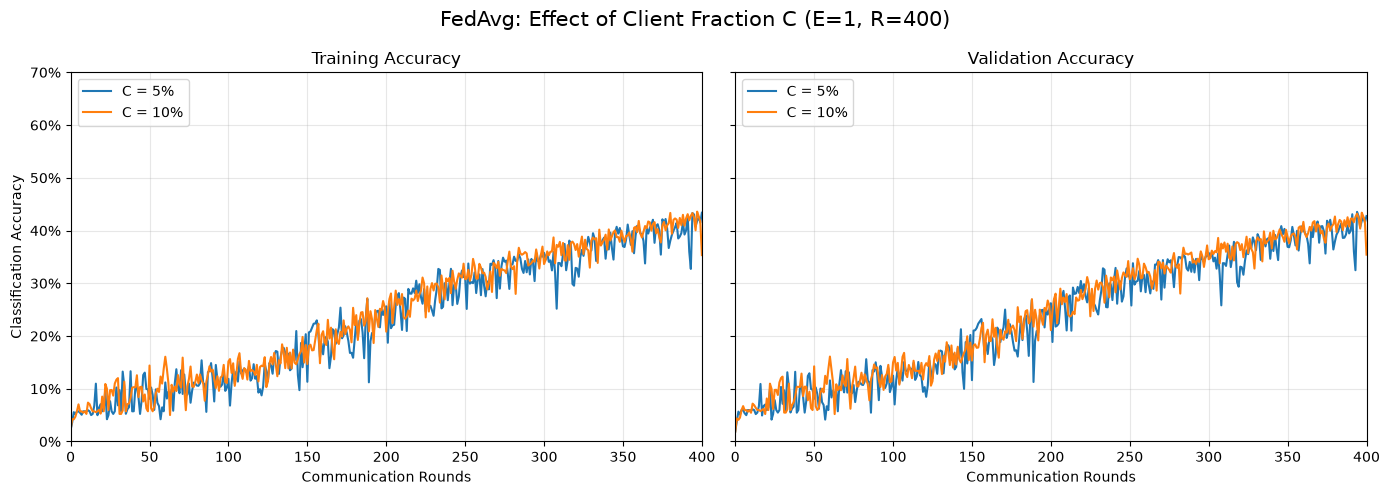

Figure saved: Output\Q4_client_fraction_comparison.png


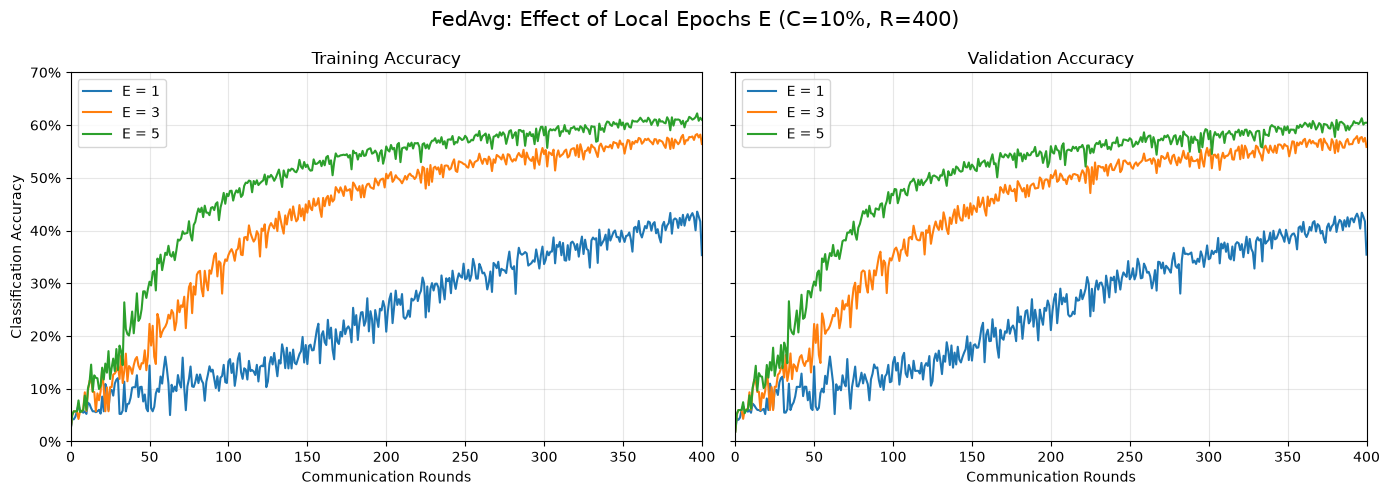

Figure saved: Output\Q4_local_epochs_comparison.png

=== Q4 Experiment Comparison ===
Experiment  Best Round  Best Val Acc (%)  Final Train Acc (%)  Final Val Acc (%)  Final Val Loss
    C10_E1         397           43.3900              35.3450            35.4300        2.487446
    C05_E1         394           43.5461              43.3787            42.7501        2.445307
    C10_E3         394           57.9054              56.4206            55.8608        1.700212
    C10_E5         397           61.2923              60.9961            60.4495        1.505449

Summary saved: Output\Q4_experiment_summary.csv

Q4 visualization completed successfully.


In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# ==========================================================
# Q4: Hyperparameter Comparison Plots
# ==========================================================

output_dir = Path("Output")
output_dir.mkdir(exist_ok=True)

experiment_paths = {
    "C10_E1": output_dir / "FedAvg_Baseline_C10_E1" / "training_history.csv",
    "C05_E1": output_dir / "FedAvg_C05_E1" / "training_history.csv",
    "C10_E3": output_dir / "FedAvg_C10_E3" / "training_history.csv",
    "C10_E5": output_dir / "FedAvg_C10_E5" / "training_history.csv"
}

# ----------------------------------------------------------
# 1. Load and validate experimental histories
# ----------------------------------------------------------

histories = {}

required_columns = [
    "round", "train_loss", "val_loss",
    "train_accuracy", "val_accuracy"
]

for name, path in experiment_paths.items():

    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(path)

    assert all(col in df.columns for col in required_columns)
    assert len(df) == 401
    assert np.array_equal(df["round"].to_numpy(), np.arange(401))
    assert df[required_columns].notna().all().all()

    for metric in ["train_accuracy", "val_accuracy"]:
        assert df[metric].between(0, 1).all()

    histories[name] = df

print("=== History Verification ===")
for name, df in histories.items():
    print(f"{name}: {len(df)} records, rounds 0-400 - PASSED")

# ----------------------------------------------------------
# 2. Reusable plotting function
# ----------------------------------------------------------

def plot_accuracy_comparison(experiments, title, filename):

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5), sharex=True, sharey=True
    )

    metrics = [
        ("train_accuracy", "Training Accuracy"),
        ("val_accuracy", "Validation Accuracy")
    ]

    for ax, (metric, subtitle) in zip(axes, metrics):

        for label, experiment_key in experiments.items():

            df = histories[experiment_key]

            ax.plot(
                df["round"],
                df[metric],
                linewidth=1.5,
                label=label
            )

        ax.set_title(subtitle)
        ax.set_xlabel("Communication Rounds")
        ax.set_xlim(0, 400)
        ax.set_xticks(np.arange(0, 401, 50))
        ax.set_ylim(0, 0.70)
        ax.yaxis.set_major_formatter(
            PercentFormatter(xmax=1.0)
        )
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left")

    axes[0].set_ylabel("Classification Accuracy")

    fig.suptitle(title, fontsize=15)
    fig.tight_layout()

    save_path = output_dir / filename

    fig.savefig(
        save_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", save_path)


# ----------------------------------------------------------
# 3. Figure 1: Effect of client fraction C
# ----------------------------------------------------------

plot_accuracy_comparison(
    experiments={
        "C = 5%": "C05_E1",
        "C = 10%": "C10_E1"
    },
    title="FedAvg: Effect of Client Fraction C (E=1, R=400)",
    filename="Q4_client_fraction_comparison.png"
)


# ----------------------------------------------------------
# 4. Figure 2: Effect of local epochs E
# ----------------------------------------------------------

plot_accuracy_comparison(
    experiments={
        "E = 1": "C10_E1",
        "E = 3": "C10_E3",
        "E = 5": "C10_E5"
    },
    title="FedAvg: Effect of Local Epochs E (C=10%, R=400)",
    filename="Q4_local_epochs_comparison.png"
)


# ----------------------------------------------------------
# 5. Quantitative comparison summary
# ----------------------------------------------------------

summary = []

for name, df in histories.items():

    best_idx = df["val_accuracy"].idxmax()
    best_row = df.loc[best_idx]
    final_row = df.iloc[-1]

    summary.append({
        "Experiment": name,
        "Best Round": int(best_row["round"]),
        "Best Val Acc (%)": round(
            best_row["val_accuracy"] * 100, 4
        ),
        "Final Train Acc (%)": round(
            final_row["train_accuracy"] * 100, 4
        ),
        "Final Val Acc (%)": round(
            final_row["val_accuracy"] * 100, 4
        ),
        "Final Val Loss": round(
            final_row["val_loss"], 6
        )
    })

summary_df = pd.DataFrame(summary)

print("\n=== Q4 Experiment Comparison ===")
print(summary_df.to_string(index=False))

summary_path = output_dir / "Q4_experiment_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nSummary saved:", summary_path)
print("\nQ4 visualization completed successfully.")


In [17]:

import os
import csv
import json
import time
import hashlib
import shutil
from pathlib import Path

import numpy as np
import torch

# ==========================================================
# Extended FedAvg Training: R=400 -> R=800
# C=10%, E=5, Serial FedAvg
# ==========================================================

SOURCE_DIR = Path("Output/FedAvg_C10_E5")
EXTENDED_DIR = Path("Output/FedAvg_C10_E5_R800")

TARGET_ROUND = 800
SAVE_EVERY = 10

source_checkpoint_path = SOURCE_DIR / "latest_checkpoint.pt"

checkpoint_path = EXTENDED_DIR / "latest_checkpoint.pt"
best_path = EXTENDED_DIR / "best_checkpoint.pt"
history_path = EXTENDED_DIR / "training_history.csv"
config_path = EXTENDED_DIR / "training_config.json"

assert source_checkpoint_path.exists(), (
    "Original Round 400 checkpoint not found."
)

EXTENDED_DIR.mkdir(parents=True, exist_ok=True)

torch.set_num_threads(min(4, os.cpu_count() or 1))

# ----------------------------------------------------------
# 1. Experiment configuration
# ----------------------------------------------------------

config = {
    "num_clients": 100,
    "client_fraction": 0.10,
    "local_epochs": 5,
    "learning_rate": 0.01,
    "batch_size": 32,
    "seed": 42,
    "planned_rounds": 800
}

assert len(train_data) == 100
assert len(client_splits) == 100

free_gb = shutil.disk_usage(EXTENDED_DIR).free / (1024 ** 3)

if free_gb < 0.2:
    raise RuntimeError("Insufficient disk space.")

# Verify the same client data splitting
split_hash = hashlib.sha256()

for cid in range(100):
    for key in ("train_idx", "val_idx"):
        indices = np.asarray(
            client_splits[cid][key],
            dtype=np.int64
        )
        split_hash.update(indices.tobytes())

split_fingerprint = split_hash.hexdigest()

print("=== Extended Training Configuration ===")
print("Client fraction:", config["client_fraction"])
print("Local epochs:", config["local_epochs"])
print("Learning rate:", config["learning_rate"])
print("Batch size:", config["batch_size"])
print("Target round:", TARGET_ROUND)
print("Available disk space (GB):", round(free_gb, 2))
print("Extended output directory:", EXTENDED_DIR)

# ----------------------------------------------------------
# 2. Load existing extended run or original Round 400
# ----------------------------------------------------------

if config_path.exists():
    with open(config_path, "r") as f:
        assert json.load(f) == config, (
            "Extended experiment configuration mismatch."
        )

if checkpoint_path.exists():

    # Resume an interrupted extended experiment
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["config"] == config
    assert checkpoint["split_fingerprint"] == split_fingerprint

    print("\n=== Resuming Extended Training ===")

else:

    # Start extension from the original Round 400 model
    if best_path.exists() or history_path.exists():
        raise RuntimeError(
            "Extended output files exist without a valid "
            "checkpoint. Inspect the directory before proceeding."
        )

    checkpoint = torch.load(
        source_checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    original_config = checkpoint["config"]

    assert original_config["client_fraction"] == 0.10
    assert original_config["local_epochs"] == 5
    assert original_config["planned_rounds"] == 400
    assert checkpoint["last_round"] == 400
    assert checkpoint["split_fingerprint"] == split_fingerprint

    print("\n=== Loading Original Baseline ===")
    print("Original last round:", checkpoint["last_round"])
    print("Original best round:", checkpoint["best_round"])
    print(
        "Original best validation accuracy:",
        f"{checkpoint['best_val_acc']:.4%}"
    )

# ----------------------------------------------------------
# 3. Restore model and training history
# ----------------------------------------------------------

global_model = FEMNISTMLP().cpu()
global_model.load_state_dict(checkpoint["model_state"])

history = checkpoint["history"]

best_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in checkpoint["best_state"].items()
}

best_val_acc = float(checkpoint["best_val_acc"])
best_val_loss = float(checkpoint["best_val_loss"])
best_round = int(checkpoint["best_round"])
last_round = int(checkpoint["last_round"])

assert history[-1]["round"] == last_round
assert 400 <= last_round <= TARGET_ROUND
assert len(history) == last_round + 1

print("\n=== Restored Model ===")
print("Starting from round:", last_round)
print("History records:", len(history))
print("Best round so far:", best_round)
print("Best validation accuracy:", f"{best_val_acc:.4%}")

# Save the extended configuration
with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# ----------------------------------------------------------
# 4. Checkpoint saving function
# ----------------------------------------------------------

fieldnames = [
    "round",
    "train_loss",
    "val_loss",
    "train_accuracy",
    "val_accuracy",
    "selected_clients",
    "participating_samples"
]

def save_extended_progress(completed_round):

    checkpoint_data = {
        "last_round": completed_round,
        "model_state": {
            name: tensor.detach().cpu().clone()
            for name, tensor in global_model.state_dict().items()
        },
        "best_state": best_state,
        "best_val_acc": best_val_acc,
        "best_val_loss": best_val_loss,
        "best_round": best_round,
        "history": history,
        "config": config,
        "split_fingerprint": split_fingerprint
    }

    # Atomic latest checkpoint saving
    tmp_checkpoint = checkpoint_path.with_suffix(".tmp")
    torch.save(checkpoint_data, tmp_checkpoint)
    os.replace(tmp_checkpoint, checkpoint_path)

    # Atomic best model saving
    tmp_best = best_path.with_suffix(".tmp")
    torch.save({
        "round": best_round,
        "model_state": best_state,
        "val_accuracy": best_val_acc,
        "val_loss": best_val_loss,
        "config": config
    }, tmp_best)
    os.replace(tmp_best, best_path)

    # Atomic training history saving
    tmp_history = history_path.with_suffix(".tmp")

    with open(tmp_history, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(history)

    os.replace(tmp_history, history_path)


# Preserve the Round 400 starting point in the new folder
if not checkpoint_path.exists():
    save_extended_progress(last_round)

# ----------------------------------------------------------
# 5. Continue formal FedAvg training
# ----------------------------------------------------------

print("\n=== Extended FedAvg Training ===")
print("Starting round:", last_round)
print("Target round:", TARGET_ROUND)

start_time = time.perf_counter()

for round_number in range(last_round + 1, TARGET_ROUND + 1):

    round_id = round_number - 1

    # Randomly select 10% of all clients
    selected_clients = select_clients(
        round_id=round_id,
        client_fraction=config["client_fraction"],
        seed=config["seed"]
    )

    assert len(selected_clients) == 10

    # All clients receive the same global model
    global_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in global_model.state_dict().items()
    }

    client_updates = []
    participating_samples = 0

    # Local SGD training
    for client_id in selected_clients:

        local_state, n_samples, local_loss = train_one_client(
            client_id=client_id,
            global_state=global_state,
            local_epochs=config["local_epochs"],
            learning_rate=config["learning_rate"],
            batch_size=config["batch_size"],
            round_id=round_id
        )

        assert np.isfinite(local_loss)

        client_updates.append((local_state, n_samples))
        participating_samples += n_samples

    # Server performs sample-size-weighted FedAvg
    aggregated_state = fedavg_aggregate(client_updates)
    global_model.load_state_dict(aggregated_state)

    # Evaluate global model on all clients
    train_metrics = evaluate_global_model(
        global_model,
        split="train",
        batch_size=128
    )

    val_metrics = evaluate_global_model(
        global_model,
        split="val",
        batch_size=128
    )

    assert train_metrics["samples"] == 25418
    assert val_metrics["samples"] == 6407

    for metrics in (train_metrics, val_metrics):
        assert np.isfinite(metrics["loss"])
        assert np.isfinite(metrics["accuracy"])

    # Record current communication round
    record = {
        "round": round_number,
        "train_loss": float(train_metrics["loss"]),
        "val_loss": float(val_metrics["loss"]),
        "train_accuracy": float(train_metrics["accuracy"]),
        "val_accuracy": float(val_metrics["accuracy"]),
        "selected_clients": len(selected_clients),
        "participating_samples": participating_samples
    }

    history.append(record)

    # Update the best validation checkpoint
    current_acc = record["val_accuracy"]
    current_loss = record["val_loss"]

    if (
        current_acc > best_val_acc
        or (
            current_acc == best_val_acc
            and current_loss < best_val_loss
        )
    ):

        best_val_acc = current_acc
        best_val_loss = current_loss
        best_round = round_number

        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in global_model.state_dict().items()
        }

    # Periodic checkpoint and progress output
    if (
        round_number % SAVE_EVERY == 0
        or round_number == TARGET_ROUND
    ):

        save_extended_progress(round_number)

        elapsed = time.perf_counter() - start_time

        print(
            f"Round {round_number:3d} | "
            f"Train Loss: {record['train_loss']:.4f} | "
            f"Val Loss: {record['val_loss']:.4f} | "
            f"Train Acc: {record['train_accuracy']:.2%} | "
            f"Val Acc: {record['val_accuracy']:.2%} | "
            f"Best Val Acc: {best_val_acc:.2%} | "
            f"Elapsed: {elapsed:.1f}s"
        )

# ----------------------------------------------------------
# 6. Final summary
# ----------------------------------------------------------

print("\n=== Extended Training Summary ===")
print("Last completed round:", history[-1]["round"])
print("Best round:", best_round)
print("Best validation accuracy:", f"{best_val_acc:.4%}")
print("Best validation loss:", round(best_val_loss, 6))
print("History records:", len(history))
print(
    "Extended segment time (s):",
    round(time.perf_counter() - start_time, 2)
)

print("\n=== Saved Files ===")
print(checkpoint_path)
print(best_path)
print(history_path)
print(config_path)

print("\nExtended FedAvg training completed successfully.")


=== Extended Training Configuration ===
Client fraction: 0.1
Local epochs: 5
Learning rate: 0.01
Batch size: 32
Target round: 800
Available disk space (GB): 606.15
Extended output directory: Output\FedAvg_C10_E5_R800

=== Loading Original Baseline ===
Original last round: 400
Original best round: 397
Original best validation accuracy: 61.2923%

=== Restored Model ===
Starting from round: 400
History records: 401
Best round so far: 397
Best validation accuracy: 61.2923%

=== Extended FedAvg Training ===
Starting round: 400
Target round: 800
Round 410 | Train Loss: 1.4381 | Val Loss: 1.4856 | Train Acc: 61.90% | Val Acc: 61.28% | Best Val Acc: 61.67% | Elapsed: 25.0s
Round 420 | Train Loss: 1.4343 | Val Loss: 1.4793 | Train Acc: 61.78% | Val Acc: 60.43% | Best Val Acc: 61.67% | Elapsed: 50.9s
Round 430 | Train Loss: 1.4217 | Val Loss: 1.4727 | Train Acc: 62.07% | Val Acc: 61.11% | Best Val Acc: 61.67% | Elapsed: 79.0s
Round 440 | Train Loss: 1.4317 | Val Loss: 1.4803 | Train Acc: 61.75% 

In [18]:

import os
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

# ==========================================================
# Part 1.1 - Q5: Final Held-out Test Evaluation
# Selected FedAvg model: C=10%, E=5, R=800
# ==========================================================

MODEL_DIR = Path("Output/FedAvg_C10_E5_R800")
CHECKPOINT_PATH = MODEL_DIR / "best_checkpoint.pt"
TEST_PATH = Path("test_data.npy")
RESULT_PATH = MODEL_DIR / "final_test_results.json"

BATCH_SIZE = 128
DEVICE = torch.device("cpu")

torch.set_num_threads(min(4, os.cpu_count() or 1))

# ----------------------------------------------------------
# 1. Load the best validation checkpoint
# ----------------------------------------------------------

assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

config = checkpoint["config"]

best_round = int(checkpoint["round"])
best_val_acc = float(checkpoint["val_accuracy"])
best_val_loss = float(checkpoint["val_loss"])

# Verify selected experiment
assert np.isclose(config["client_fraction"], 0.10)
assert config["local_epochs"] == 5
assert config["planned_rounds"] == 800
assert best_round == 796

# Restore the selected model
test_model = FEMNISTMLP().to(DEVICE)
test_model.load_state_dict(checkpoint["model_state"])
test_model.eval()

assert all(
    torch.isfinite(p).all().item()
    for p in test_model.parameters()
)

print("=== Selected FedAvg Model ===")
print("Client fraction:", config["client_fraction"])
print("Local epochs:", config["local_epochs"])
print("Training rounds:", config["planned_rounds"])
print("Best checkpoint round:", best_round)
print("Validation accuracy:", f"{best_val_acc:.4%}")
print("Validation loss:", f"{best_val_loss:.6f}")

# ----------------------------------------------------------
# 2. Load independent held-out test data
# ----------------------------------------------------------

assert TEST_PATH.exists(), (
    f"Test data not found: {TEST_PATH}"
)

heldout_data = np.load(TEST_PATH, allow_pickle=True)

# Dataset structure follows the provided README
test_images = heldout_data[0]["images"]
test_labels = heldout_data[0]["labels"]

num_test_samples = len(test_labels)

assert num_test_samples > 0
assert len(test_images) == num_test_samples

print("\n=== Held-out Test Dataset ===")
print("Number of test samples:", num_test_samples)
print("Evaluation batch size:", BATCH_SIZE)

# ----------------------------------------------------------
# 3. Evaluate without gradient computation
# ----------------------------------------------------------

total_loss = 0.0
total_correct = 0
total_samples = 0

with torch.inference_mode():

    for start in range(0, num_test_samples, BATCH_SIZE):

        end = min(
            start + BATCH_SIZE,
            num_test_samples
        )

        # Load only the current batch
        images = np.asarray(
            test_images[start:end],
            dtype=np.float32
        )

        labels = np.asarray(
            test_labels[start:end],
            dtype=np.int64
        )

        # Validate data
        assert images.ndim == 3
        assert images.shape[1:] == (28, 28)
        assert np.isfinite(images).all()
        assert np.all((labels >= 0) & (labels < 62))

        x = torch.from_numpy(images).to(DEVICE)
        y = torch.from_numpy(labels).to(DEVICE)

        # Forward pass only
        logits = test_model(x)

        assert logits.shape == (len(labels), 62)

        # Sample-summed cross-entropy
        batch_loss = F.cross_entropy(
            logits,
            y,
            reduction="sum"
        )

        predictions = torch.argmax(logits, dim=1)

        total_loss += batch_loss.item()
        total_correct += int(
            (predictions == y).sum().item()
        )
        total_samples += len(labels)

# ----------------------------------------------------------
# 4. Compute final test metrics
# ----------------------------------------------------------

test_loss = total_loss / total_samples
test_accuracy = total_correct / total_samples

assert total_samples == num_test_samples
assert np.isfinite(test_loss)
assert 0.0 <= test_accuracy <= 1.0

accuracy_gap_pp = (
    best_val_acc - test_accuracy
) * 100

print("\n=== Final Held-out Test Results ===")
print("Total test samples:", total_samples)
print("Correct predictions:", total_correct)
print("Test loss:", f"{test_loss:.6f}")
print("Test accuracy:", f"{test_accuracy:.4%}")

print("\n=== Validation vs Test ===")
print("Validation accuracy:", f"{best_val_acc:.4%}")
print("Test accuracy:", f"{test_accuracy:.4%}")
print(
    "Validation - Test accuracy gap:",
    f"{accuracy_gap_pp:.4f} percentage points"
)

# ----------------------------------------------------------
# 5. Save reproducible final results
# ----------------------------------------------------------

results = {
    "experiment": "FedAvg_C10_E5_R800",
    "client_fraction": float(config["client_fraction"]),
    "local_epochs": int(config["local_epochs"]),
    "communication_rounds": int(config["planned_rounds"]),
    "selected_round": best_round,
    "validation_accuracy": best_val_acc,
    "validation_loss": best_val_loss,
    "test_samples": int(total_samples),
    "correct_predictions": int(total_correct),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "validation_test_gap_pp": float(accuracy_gap_pp)
}

tmp_path = RESULT_PATH.with_suffix(".tmp")

with open(tmp_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4)

os.replace(tmp_path, RESULT_PATH)

# ----------------------------------------------------------
# 6. Final verification
# ----------------------------------------------------------

print("\n=== Final Verification ===")
print("Best checkpoint loaded: PASSED")
print("Correct model configuration: PASSED")
print("Held-out test evaluation: PASSED")
print("Test sample count: PASSED")
print("Finite evaluation metrics: PASSED")
print("Results saved:", RESULT_PATH)

print("\nFinal held-out evaluation completed successfully.")


=== Selected FedAvg Model ===
Client fraction: 0.1
Local epochs: 5
Training rounds: 800
Best checkpoint round: 796
Validation accuracy: 66.2088%
Validation loss: 1.287287

=== Held-out Test Dataset ===
Number of test samples: 3621
Evaluation batch size: 128

=== Final Held-out Test Results ===
Total test samples: 3621
Correct predictions: 2431
Test loss: 1.278622
Test accuracy: 67.1362%

=== Validation vs Test ===
Validation accuracy: 66.2088%
Test accuracy: 67.1362%
Validation - Test accuracy gap: -0.9273 percentage points

=== Final Verification ===
Best checkpoint loaded: PASSED
Correct model configuration: PASSED
Held-out test evaluation: PASSED
Test sample count: PASSED
Finite evaluation metrics: PASSED
Results saved: Output\FedAvg_C10_E5_R800\final_test_results.json

Final held-out evaluation completed successfully.


In [19]:

import numpy as np
import pandas as pd

# ==========================================================
# Part 1.1 - Edge Cases: Data and Sampling Audit
# No model training or checkpoint loading
# ==========================================================

NUM_CLIENTS = 100
NUM_CLASSES = 62
BATCH_SIZE = 32

assert len(train_data) == NUM_CLIENTS
assert len(client_splits) == NUM_CLIENTS

client_records = []

# ----------------------------------------------------------
# 1. Audit client datasets and train/validation splits
# ----------------------------------------------------------

for cid in range(NUM_CLIENTS):

    labels = np.asarray(
        train_data[cid]["labels"],
        dtype=np.int64
    )

    n_total = len(labels)
    n_images = len(train_data[cid]["images"])

    train_idx = np.asarray(
        client_splits[cid]["train_idx"],
        dtype=np.int64
    )

    val_idx = np.asarray(
        client_splits[cid]["val_idx"],
        dtype=np.int64
    )

    # Data consistency
    assert n_images == n_total, (
        f"Client {cid}: image/label count mismatch"
    )

    assert n_total > 0, (
        f"Client {cid}: empty original dataset"
    )

    assert np.all(
        (labels >= 0) & (labels < NUM_CLASSES)
    ), f"Client {cid}: invalid class labels"

    # Train/validation must both contain data
    assert len(train_idx) > 0, (
        f"Client {cid}: empty training split"
    )

    assert len(val_idx) > 0, (
        f"Client {cid}: empty validation split"
    )

    # Validate index ranges
    assert np.all(
        (train_idx >= 0) & (train_idx < n_total)
    )

    assert np.all(
        (val_idx >= 0) & (val_idx < n_total)
    )

    # Check no duplicated indices
    assert len(np.unique(train_idx)) == len(train_idx)
    assert len(np.unique(val_idx)) == len(val_idx)

    # Check no training/validation leakage
    overlap = np.intersect1d(train_idx, val_idx)

    assert len(overlap) == 0, (
        f"Client {cid}: overlapping train/val indices"
    )

    # Check all original samples are accounted for
    combined = np.concatenate([train_idx, val_idx])

    assert np.array_equal(
        np.sort(combined),
        np.arange(n_total)
    ), f"Client {cid}: split does not cover all samples"

    # Measure class coverage
    unique_classes = np.unique(labels)
    train_classes = np.unique(labels[train_idx])

    client_records.append({
        "client_id": cid,
        "total_samples": n_total,
        "train_samples": len(train_idx),
        "val_samples": len(val_idx),
        "unique_classes": len(unique_classes),
        "train_classes": len(train_classes),
        "missing_train_classes": (
            NUM_CLASSES - len(train_classes)
        ),
        "last_batch_size": (
            (len(train_idx) - 1) % BATCH_SIZE + 1
        ),
        "has_partial_batch": (
            len(train_idx) % BATCH_SIZE != 0
        )
    })

audit_df = pd.DataFrame(client_records)

# ----------------------------------------------------------
# 2. Summarize dataset edge cases
# ----------------------------------------------------------

print("=== Edge Case 1: Client Dataset Sizes ===")

print(
    "Minimum local training samples:",
    audit_df["train_samples"].min()
)
print(
    "Maximum local training samples:",
    audit_df["train_samples"].max()
)
print(
    "Minimum local validation samples:",
    audit_df["val_samples"].min()
)

print(
    "Total training samples:",
    audit_df["train_samples"].sum()
)
print(
    "Total validation samples:",
    audit_df["val_samples"].sum()
)

print("\nEmpty training/validation splits: 0")
print("All client splits valid: PASSED")

# ----------------------------------------------------------
# 3. Non-IID and missing classes
# ----------------------------------------------------------

print("\n=== Edge Case 2: Missing Local Classes ===")

print(
    "Minimum training classes per client:",
    audit_df["train_classes"].min()
)
print(
    "Maximum training classes per client:",
    audit_df["train_classes"].max()
)

print(
    "Clients missing at least one training class:",
    int((audit_df["missing_train_classes"] > 0).sum())
)

print(
    "Clients with only one training class:",
    int((audit_df["train_classes"] == 1).sum())
)

# ----------------------------------------------------------
# 4. Partial mini-batches
# ----------------------------------------------------------

print("\n=== Edge Case 3: Incomplete Mini-batches ===")

partial_count = int(
    audit_df["has_partial_batch"].sum()
)

print(
    "Clients with incomplete final mini-batch:",
    partial_count
)
print(
    "Minimum final batch size:",
    audit_df["last_batch_size"].min()
)
print(
    "Maximum final batch size:",
    audit_df["last_batch_size"].max()
)

# ----------------------------------------------------------
# 5. Client sampling boundaries
# ----------------------------------------------------------

print("\n=== Edge Case 4: Client Sampling ===")

for fraction in [0.01, 0.05, 0.10]:

    expected_count = max(
        1, round(NUM_CLIENTS * fraction)
    )

    for round_id in range(20):

        selected = np.asarray(
            select_clients(
                round_id=round_id,
                client_fraction=fraction,
                seed=42
            ),
            dtype=np.int64
        )

        # Correct number of clients
        assert len(selected) == expected_count

        # No duplicate clients
        assert len(np.unique(selected)) == len(selected)

        # Valid client IDs
        assert np.all(
            (selected >= 0) &
            (selected < NUM_CLIENTS)
        )

        # Reproducibility for identical inputs
        repeated = np.asarray(
            select_clients(
                round_id=round_id,
                client_fraction=fraction,
                seed=42
            )
        )

        assert np.array_equal(
            selected, repeated
        )

    print(
        f"C={fraction:.0%}: "
        f"{expected_count} clients per round, "
        "20 rounds checked - PASSED"
    )

# ----------------------------------------------------------
# 6. Summary
# ----------------------------------------------------------

print("\n=== Edge Case Audit Summary ===")

print("Client datasets checked:", len(audit_df))
print("Train/validation isolation: PASSED")
print("Class label validity: PASSED")
print("Client participation boundaries: PASSED")
print("Sampling reproducibility: PASSED")

print("\n=== Sample Client Statistics ===")
print(
    audit_df[
        [
            "client_id",
            "train_samples",
            "val_samples",
            "train_classes",
            "last_batch_size"
        ]
    ].head(10).to_string(index=False)
)

print("\nData-level edge case audit completed.")


=== Edge Case 1: Client Dataset Sizes ===
Minimum local training samples: 94
Maximum local training samples: 314
Minimum local validation samples: 24
Total training samples: 25418
Total validation samples: 6407

Empty training/validation splits: 0
All client splits valid: PASSED

=== Edge Case 2: Missing Local Classes ===
Minimum training classes per client: 37
Maximum training classes per client: 58
Clients missing at least one training class: 100
Clients with only one training class: 0

=== Edge Case 3: Incomplete Mini-batches ===
Clients with incomplete final mini-batch: 95
Minimum final batch size: 1
Maximum final batch size: 32

=== Edge Case 4: Client Sampling ===
C=1%: 1 clients per round, 20 rounds checked - PASSED
C=5%: 5 clients per round, 20 rounds checked - PASSED
C=10%: 10 clients per round, 20 rounds checked - PASSED

=== Edge Case Audit Summary ===
Client datasets checked: 100
Train/validation isolation: PASSED
Class label validity: PASSED
Client participation boundaries

In [20]:

import json
import math
import torch
import numpy as np

from pathlib import Path
from unittest.mock import patch

# ==========================================================
# Part 1.1 - Edge Cases: Algorithm-Level Verification
# No formal experiment retraining
# ==========================================================

OUTPUT_DIR = Path("Output")
OUTPUT_DIR.mkdir(exist_ok=True)

BATCH_SIZE = 32
NUM_CLASSES = 62

# Preserve global PyTorch RNG state
saved_rng_state = torch.get_rng_state()

results = {}

try:
    torch.manual_seed(2026)

    probe_model = FEMNISTMLP().cpu()

    initial_state = {
        k: v.detach().clone()
        for k, v in probe_model.state_dict().items()
    }

    # ------------------------------------------------------
    # Test 1: Incomplete mini-batch is not discarded
    # ------------------------------------------------------

    print("=== Test 1: Partial Mini-batch ===")

    # Select a real client whose final batch has size 1
    partial_candidates = [
        cid for cid in range(100)
        if len(client_splits[cid]["train_idx"]) % BATCH_SIZE == 1
    ]

    assert len(partial_candidates) > 0, (
        "No client with a final batch of size 1."
    )

    partial_cid = partial_candidates[0]
    n_train = len(client_splits[partial_cid]["train_idx"])

    local_epochs = 2
    expected_batches_per_epoch = math.ceil(n_train / BATCH_SIZE)
    expected_steps = expected_batches_per_epoch * local_epochs

    observed_batch_sizes = []
    observed_output_widths = []
    optimizer_steps = [0]

    original_forward = FEMNISTMLP.forward
    original_step = torch.optim.SGD.step

    def traced_forward(self, x):
        output = original_forward(self, x)
        observed_batch_sizes.append(int(x.shape[0]))
        observed_output_widths.append(int(output.shape[1]))
        return output

    def traced_step(self, *args, **kwargs):
        optimizer_steps[0] += 1
        return original_step(self, *args, **kwargs)

    with (
        patch.object(FEMNISTMLP, "forward", traced_forward),
        patch.object(torch.optim.SGD, "step", traced_step)
    ):
        partial_state, partial_n, partial_loss = train_one_client(
            client_id=partial_cid,
            global_state=initial_state,
            local_epochs=local_epochs,
            learning_rate=0.01,
            batch_size=BATCH_SIZE,
            round_id=0
        )

    assert partial_n == n_train
    assert len(observed_batch_sizes) == expected_steps
    assert optimizer_steps[0] == expected_steps

    # Every training example must be used in each epoch
    assert sum(observed_batch_sizes) == n_train * local_epochs

    # Exactly one size-1 batch should occur per epoch
    assert observed_batch_sizes.count(1) == local_epochs
    assert set(observed_output_widths) == {NUM_CLASSES}
    assert np.isfinite(partial_loss)

    print("Client ID:", partial_cid)
    print("Training samples:", n_train)
    print("Local epochs:", local_epochs)
    print("Expected optimizer steps:", expected_steps)
    print("Observed optimizer steps:", optimizer_steps[0])
    print("Size-1 batches processed:", observed_batch_sizes.count(1))
    print("All training samples processed: PASSED")
    print("Partial mini-batch handling: PASSED")

    results["partial_minibatch"] = {
        "client_id": partial_cid,
        "train_samples": n_train,
        "local_epochs": local_epochs,
        "expected_steps": expected_steps,
        "observed_steps": optimizer_steps[0],
        "size_one_batches": observed_batch_sizes.count(1),
        "passed": True
    }

    # ------------------------------------------------------
    # Test 2: Missing local classes
    # ------------------------------------------------------

    print("\n=== Test 2: Missing Local Classes ===")

    client_class_counts = []

    for cid in range(100):
        train_indices = client_splits[cid]["train_idx"]

        labels = np.asarray(
            train_data[cid]["labels"],
            dtype=np.int64
        )

        n_classes = len(np.unique(labels[train_indices]))
        client_class_counts.append(n_classes)

    missing_cid = int(np.argmin(client_class_counts))
    present_classes = client_class_counts[missing_cid]
    missing_classes = NUM_CLASSES - present_classes

    missing_state, missing_n, missing_loss = train_one_client(
        client_id=missing_cid,
        global_state=initial_state,
        local_epochs=1,
        learning_rate=0.01,
        batch_size=BATCH_SIZE,
        round_id=0
    )

    assert missing_n == len(client_splits[missing_cid]["train_idx"])
    assert np.isfinite(missing_loss)

    # Local update must retain the global model architecture
    for key in initial_state:
        assert missing_state[key].shape == initial_state[key].shape
        assert torch.isfinite(missing_state[key]).all()

    local_model = FEMNISTMLP().cpu()
    local_model.load_state_dict(missing_state)
    local_model.eval()

    sample_idx = client_splits[missing_cid]["train_idx"][0]

    sample = np.asarray(
        train_data[missing_cid]["images"][sample_idx],
        dtype=np.float32
    ).reshape(1, 28, 28)

    with torch.inference_mode():
        logits = local_model(torch.from_numpy(sample))

    assert logits.shape == (1, NUM_CLASSES)
    assert torch.isfinite(logits).all()

    print("Client ID:", missing_cid)
    print("Present training classes:", present_classes)
    print("Missing training classes:", missing_classes)
    print("Model output classes:", logits.shape[1])
    print("Local training loss:", round(float(missing_loss), 6))
    print("Finite model parameters: PASSED")
    print("Full 62-class output preserved: PASSED")

    results["missing_classes"] = {
        "client_id": missing_cid,
        "present_classes": present_classes,
        "missing_classes": missing_classes,
        "output_classes": int(logits.shape[1]),
        "local_loss": float(missing_loss),
        "passed": True
    }

    # ------------------------------------------------------
    # Test 3: Sample-size-weighted FedAvg
    # ------------------------------------------------------

    print("\n=== Test 3: Weighted FedAvg Aggregation ===")

    # Construct two synthetic model updates
    # Client A: one sample, parameters = 1
    # Client B: three samples, parameters = 3
    #
    # Expected FedAvg:
    # (1*1 + 3*3) / (1+3) = 2.5

    state_a = {
        k: torch.ones_like(v)
        for k, v in initial_state.items()
    }

    state_b = {
        k: torch.full_like(v, 3.0)
        for k, v in initial_state.items()
    }

    aggregated = fedavg_aggregate([
        (state_a, 1),
        (state_b, 3)
    ])

    expected_value = 2.5

    for key, tensor in aggregated.items():
        assert torch.allclose(
            tensor,
            torch.full_like(tensor, expected_value),
            rtol=1e-6,
            atol=1e-6
        )

    # Reverse client order: result must remain unchanged
    reversed_aggregate = fedavg_aggregate([
        (state_b, 3),
        (state_a, 1)
    ])

    for key in aggregated:
        assert torch.allclose(
            aggregated[key],
            reversed_aggregate[key],
            rtol=1e-6,
            atol=1e-6
        )

    print("Client A samples: 1, parameter value: 1.0")
    print("Client B samples: 3, parameter value: 3.0")
    print("Expected aggregate:", expected_value)
    print("Weighted aggregation: PASSED")
    print("Client-order invariance: PASSED")

    # ------------------------------------------------------
    # Test 4: Single-client FedAvg
    # ------------------------------------------------------

    print("\n=== Test 4: Single-client Aggregation ===")

    single_aggregate = fedavg_aggregate([
        (partial_state, partial_n)
    ])

    for key in partial_state:
        assert torch.allclose(
            single_aggregate[key],
            partial_state[key],
            rtol=1e-6,
            atol=1e-6
        )

    # Verify local update changed model parameters
    changed_parameters = any(
        not torch.equal(
            partial_state[key],
            initial_state[key]
        )
        for key in initial_state
    )

    assert changed_parameters

    # Verify the original input state remains unchanged
    for key in initial_state:
        assert torch.equal(
            initial_state[key],
            probe_model.state_dict()[key]
        )

    print("Participating clients: 1")
    print("Aggregated model equals local model: PASSED")
    print("Local model parameters updated: PASSED")
    print("Original input model unchanged: PASSED")

    results["weighted_fedavg"] = {
        "client_a_samples": 1,
        "client_b_samples": 3,
        "expected_value": expected_value,
        "passed": True
    }

    results["single_client"] = {
        "client_id": partial_cid,
        "train_samples": partial_n,
        "passed": True
    }

finally:
    # Do not alter the RNG state used by other experiments
    torch.set_rng_state(saved_rng_state)

# ----------------------------------------------------------
# Save results
# ----------------------------------------------------------

save_path = OUTPUT_DIR / "edge_case_algorithm_checks.json"

with open(save_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4)

print("\n=== Algorithm-Level Edge Case Summary ===")
print("Partial mini-batch processing: PASSED")
print("Missing local classes: PASSED")
print("Sample-size-weighted aggregation: PASSED")
print("Client order invariance: PASSED")
print("Single-client aggregation: PASSED")
print("Original model isolation: PASSED")
print("Results saved:", save_path)

print("\nAlgorithm-level edge case verification completed.")


=== Test 1: Partial Mini-batch ===
Client ID: 22
Training samples: 257
Local epochs: 2
Expected optimizer steps: 18
Observed optimizer steps: 18
Size-1 batches processed: 2
All training samples processed: PASSED
Partial mini-batch handling: PASSED

=== Test 2: Missing Local Classes ===
Client ID: 25
Present training classes: 37
Missing training classes: 25
Model output classes: 62
Local training loss: 4.141411
Finite model parameters: PASSED
Full 62-class output preserved: PASSED

=== Test 3: Weighted FedAvg Aggregation ===
Client A samples: 1, parameter value: 1.0
Client B samples: 3, parameter value: 3.0
Expected aggregate: 2.5
Weighted aggregation: PASSED
Client-order invariance: PASSED

=== Test 4: Single-client Aggregation ===
Participating clients: 1
Aggregated model equals local model: PASSED
Local model parameters updated: PASSED
Original input model unchanged: PASSED

=== Algorithm-Level Edge Case Summary ===
Partial mini-batch processing: PASSED
Missing local classes: PASSED


In [21]:

import json
import numpy as np
import torch
import torch.nn.functional as F

from pathlib import Path

# ==========================================================
# Validation Test 1:
# FedAvg vs. Centralized Full-batch SGD
#
# Prediction:
# E=1 + one full batch per client + weighted FedAvg
# must match one centralized SGD update.
# ==========================================================

OUTPUT_DIR = Path("Output")
OUTPUT_DIR.mkdir(exist_ok=True)

LEARNING_RATE = 0.01
NUM_CLASSES = 62

saved_rng_state = torch.get_rng_state()

try:
    # ------------------------------------------------------
    # 1. Select two real clients with different data sizes
    # ------------------------------------------------------

    client_sizes = np.array([
        len(client_splits[cid]["train_idx"])
        for cid in range(100)
    ])

    small_client = int(np.argmin(client_sizes))
    large_client = int(np.argmax(client_sizes))

    selected_clients = [small_client, large_client]

    n_small = int(client_sizes[small_client])
    n_large = int(client_sizes[large_client])

    assert small_client != large_client
    assert n_small < n_large

    print("=== Controlled Experiment ===")
    print("Small client ID:", small_client)
    print("Small client samples:", n_small)
    print("Large client ID:", large_client)
    print("Large client samples:", n_large)
    print("Learning rate:", LEARNING_RATE)
    print("Local epochs: 1")
    print("Local batch size: full client dataset")

    # ------------------------------------------------------
    # 2. Create a common initial model
    # ------------------------------------------------------

    torch.manual_seed(2026)

    initial_model = FEMNISTMLP().cpu()

    initial_state = {
        key: value.detach().clone()
        for key, value in initial_model.state_dict().items()
    }

    # ------------------------------------------------------
    # 3. Independent FedAvg computation
    # ------------------------------------------------------

    print("\n=== Path A: Federated SGD + FedAvg ===")

    client_updates = []
    all_images = []
    all_labels = []

    for cid in selected_clients:

        train_idx = np.asarray(
            client_splits[cid]["train_idx"],
            dtype=np.int64
        )

        # Use one batch containing all local samples
        local_batch_size = len(train_idx)

        local_state, local_n, local_loss = train_one_client(
            client_id=cid,
            global_state=initial_state,
            local_epochs=1,
            learning_rate=LEARNING_RATE,
            batch_size=local_batch_size,
            round_id=0
        )

        assert local_n == local_batch_size
        assert np.isfinite(local_loss)

        client_updates.append(
            (local_state, local_n)
        )

        # Collect exactly the same training examples
        images = np.asarray(
            [
                train_data[cid]["images"][int(i)]
                for i in train_idx
            ],
            dtype=np.float32
        )

        labels = np.asarray(
            [
                train_data[cid]["labels"][int(i)]
                for i in train_idx
            ],
            dtype=np.int64
        )

        assert images.shape == (
            local_n, 28, 28
        )

        assert np.all(
            (labels >= 0) & (labels < NUM_CLASSES)
        )

        all_images.append(images)
        all_labels.append(labels)

        print(
            f"Client {cid}: "
            f"n={local_n}, "
            f"local loss={local_loss:.6f}"
        )

    fedavg_state = fedavg_aggregate(client_updates)

    # ------------------------------------------------------
    # 4. Independent centralized SGD computation
    # ------------------------------------------------------

    print("\n=== Path B: Centralized Full-batch SGD ===")

    X = torch.from_numpy(
        np.concatenate(all_images, axis=0)
    )

    y = torch.from_numpy(
        np.concatenate(all_labels, axis=0)
    )

    assert X.shape[0] == n_small + n_large

    central_model = FEMNISTMLP().cpu()
    central_model.load_state_dict(initial_state)

    central_optimizer = torch.optim.SGD(
        central_model.parameters(),
        lr=LEARNING_RATE
    )

    central_model.eval()

    with torch.no_grad():
        initial_loss = F.cross_entropy(
            central_model(X),
            y
        ).item()

    # One single SGD update on the combined dataset
    central_model.train()
    central_optimizer.zero_grad(set_to_none=True)

    central_loss = F.cross_entropy(
        central_model(X),
        y
    )

    central_loss.backward()
    central_optimizer.step()

    central_state = {
        key: value.detach().clone()
        for key, value in central_model.state_dict().items()
    }

    central_model.eval()

    with torch.no_grad():
        final_central_loss = F.cross_entropy(
            central_model(X),
            y
        ).item()

    # ------------------------------------------------------
    # 5. Compare parameters between the two paths
    # ------------------------------------------------------

    print("\n=== Theoretical Equivalence Check ===")

    max_abs_difference = 0.0
    squared_difference = 0.0
    parameter_count = 0

    for key in initial_state:

        difference = (
            fedavg_state[key].double()
            - central_state[key].double()
        )

        max_abs_difference = max(
            max_abs_difference,
            float(difference.abs().max())
        )

        squared_difference += float(
            torch.sum(difference ** 2)
        )

        parameter_count += difference.numel()

    parameter_rmse = np.sqrt(
        squared_difference / parameter_count
    )

    # Allow only small floating-point differences
    TOLERANCE = 2e-6

    assert max_abs_difference < TOLERANCE, (
        "FedAvg and centralized SGD do not match."
    )

    print("Parameters compared:", parameter_count)
    print(
        "Maximum absolute difference:",
        f"{max_abs_difference:.10e}"
    )
    print(
        "Parameter RMSE:",
        f"{parameter_rmse:.10e}"
    )
    print("Tolerance:", TOLERANCE)
    print("FedAvg/centralized equivalence: PASSED")

    # ------------------------------------------------------
    # 6. Negative control: unweighted average
    # ------------------------------------------------------

    print("\n=== Negative Control: Unweighted Average ===")

    unweighted_state = {}

    for key in initial_state:
        unweighted_state[key] = (
            client_updates[0][0][key]
            + client_updates[1][0][key]
        ) / 2.0

    unweighted_max_difference = max(
        float(
            (
                unweighted_state[key]
                - central_state[key]
            ).abs().max()
        )
        for key in initial_state
    )

    print(
        "Unweighted vs centralized max difference:",
        f"{unweighted_max_difference:.10e}"
    )

    assert unweighted_max_difference > max_abs_difference, (
        "Negative control did not show a larger "
        "parameter discrepancy."
    )

    print(
        "Weighted FedAvg is closer than "
        "unweighted averaging: PASSED"
    )

    # ------------------------------------------------------
    # 7. Check predicted learning behavior
    # ------------------------------------------------------

    fedavg_model = FEMNISTMLP().cpu()
    fedavg_model.load_state_dict(fedavg_state)
    fedavg_model.eval()

    with torch.inference_mode():
        final_fedavg_loss = F.cross_entropy(
            fedavg_model(X),
            y
        ).item()

    print("\n=== Learning Behavior ===")
    print("Loss before SGD:", f"{initial_loss:.6f}")
    print(
        "Loss after centralized SGD:",
        f"{final_central_loss:.6f}"
    )
    print(
        "Loss after weighted FedAvg:",
        f"{final_fedavg_loss:.6f}"
    )

    assert final_central_loss < initial_loss, (
        "Controlled SGD step did not reduce loss."
    )

    assert abs(
        final_fedavg_loss - final_central_loss
    ) < 1e-5

    print("Controlled one-step loss reduction: PASSED")
    print("FedAvg/centralized loss agreement: PASSED")

    # ------------------------------------------------------
    # 8. Preserve quantitative evidence
    # ------------------------------------------------------

    validation_result = {
        "test": "FedAvg vs Centralized Full-batch SGD",
        "selected_clients": selected_clients,
        "client_sample_counts": [n_small, n_large],
        "local_epochs": 1,
        "learning_rate": LEARNING_RATE,
        "parameters_compared": parameter_count,
        "max_absolute_difference": max_abs_difference,
        "parameter_rmse": float(parameter_rmse),
        "tolerance": TOLERANCE,
        "unweighted_max_difference": unweighted_max_difference,
        "initial_loss": initial_loss,
        "final_centralized_loss": final_central_loss,
        "final_fedavg_loss": final_fedavg_loss,
        "passed": True
    }

    result_path = (
        OUTPUT_DIR
        / "validation_fedavg_centralized_equivalence.json"
    )

    with open(result_path, "w", encoding="utf-8") as f:
        json.dump(validation_result, f, indent=4)

    print("\n=== Validation Test 1 Summary ===")
    print("Theoretical parameter equivalence: PASSED")
    print("Weighted vs unweighted control: PASSED")
    print("Expected loss reduction: PASSED")
    print("Results saved:", result_path)

finally:
    # Restore the global random state
    torch.set_rng_state(saved_rng_state)


=== Controlled Experiment ===
Small client ID: 25
Small client samples: 94
Large client ID: 67
Large client samples: 314
Learning rate: 0.01
Local epochs: 1
Local batch size: full client dataset

=== Path A: Federated SGD + FedAvg ===
Client 25: n=94, local loss=4.157676
Client 67: n=314, local loss=4.154355

=== Path B: Centralized Full-batch SGD ===

=== Theoretical Equivalence Check ===
Parameters compared: 108478
Maximum absolute difference: 7.4505805969e-09
Parameter RMSE: 8.0397534268e-10
Tolerance: 2e-06
FedAvg/centralized equivalence: PASSED

=== Negative Control: Unweighted Average ===
Unweighted vs centralized max difference: 3.0647590756e-04
Weighted FedAvg is closer than unweighted averaging: PASSED

=== Learning Behavior ===
Loss before SGD: 4.155120
Loss after centralized SGD: 4.133907
Loss after weighted FedAvg: 4.133907
Controlled one-step loss reduction: PASSED
FedAvg/centralized loss agreement: PASSED

=== Validation Test 1 Summary ===
Theoretical parameter equivalenc

In [23]:

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from pathlib import Path

# ==========================================================
# Part 1.1 - Validation Test 2
# Controlled FedAvg Training Dynamics
#
# Test 2A: Controlled loss reduction
# Test 2B: Deterministic reproducibility
# Test 2C: Zero-learning-rate negative control
#
# Independent diagnostic experiment:
# - No formal experiment retraining
# - No checkpoint loading
# - No held-out test data
# ==========================================================

OUTPUT_DIR = Path("Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_ROUNDS = 10
LOCAL_EPOCHS = 1
BATCH_SIZE = 32
LEARNING_RATE = 0.01
SEED = 2026

# Preserve PyTorch RNG state
saved_torch_rng = torch.get_rng_state()

try:

    # ======================================================
    # 1. Select five fixed clients
    # ======================================================

    fixed_clients = [
        int(cid)
        for cid in select_clients(
            round_id=0,
            client_fraction=0.05,
            seed=42
        )
    ]

    assert len(fixed_clients) == 5
    assert len(set(fixed_clients)) == 5

    print("=== Controlled FedAvg Configuration ===")
    print("Selected clients:", fixed_clients)
    print("Communication rounds:", N_ROUNDS)
    print("Local epochs:", LOCAL_EPOCHS)
    print("Batch size:", BATCH_SIZE)
    print("Learning rate:", LEARNING_RATE)

    # ======================================================
    # 2. Prepare selected clients' training data
    # ======================================================

    image_parts = []
    label_parts = []
    client_training_data = {}

    for cid in fixed_clients:

        indices = np.asarray(
            client_splits[cid]["train_idx"],
            dtype=np.int64
        )

        images = np.asarray(
            [
                train_data[cid]["images"][int(i)]
                for i in indices
            ],
            dtype=np.float32
        )

        labels = np.asarray(
            [
                train_data[cid]["labels"][int(i)]
                for i in indices
            ],
            dtype=np.int64
        )

        assert images.shape == (len(indices), 28, 28)
        assert len(images) == len(labels)
        assert np.all((labels >= 0) & (labels < 62))

        image_parts.append(images)
        label_parts.append(labels)

        client_training_data[cid] = (
            torch.from_numpy(images),
            torch.from_numpy(labels)
        )

    X = torch.from_numpy(
        np.concatenate(image_parts, axis=0)
    )

    y = torch.from_numpy(
        np.concatenate(label_parts, axis=0)
    )

    total_training_samples = len(y)

    print(
        "Total selected training samples:",
        total_training_samples
    )

    # ======================================================
    # 3. Create shared initial model
    # ======================================================

    torch.manual_seed(SEED)

    initial_model = FEMNISTMLP().cpu()

    initial_state = {
        key: value.detach().clone()
        for key, value in initial_model.state_dict().items()
    }

    # ======================================================
    # 4. Evaluation function
    # ======================================================

    def controlled_evaluate(model):

        model.eval()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        with torch.inference_mode():

            for start in range(0, len(y), 128):

                end = min(start + 128, len(y))

                batch_x = X[start:end]
                batch_y = y[start:end]

                logits = model(batch_x)

                batch_loss = F.cross_entropy(
                    logits,
                    batch_y,
                    reduction="sum"
                )

                predictions = logits.argmax(dim=1)

                total_loss += batch_loss.item()

                total_correct += int(
                    (predictions == batch_y).sum().item()
                )

                total_samples += len(batch_y)

        assert total_samples == total_training_samples

        return {
            "loss": total_loss / total_samples,
            "accuracy": total_correct / total_samples
        }

    # ======================================================
    # 5. Controlled FedAvg training function
    # ======================================================

    def run_controlled_fedavg():

        # Reset seed for identical initial conditions
        torch.manual_seed(SEED)

        model = FEMNISTMLP().cpu()
        model.load_state_dict(initial_state)

        history = []

        # Round 0: before training
        initial_metrics = controlled_evaluate(model)

        history.append({
            "round": 0,
            "loss": initial_metrics["loss"],
            "accuracy": initial_metrics["accuracy"]
        })

        for round_number in range(1, N_ROUNDS + 1):

            # Copy the same global weights to all clients
            global_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }

            client_updates = []

            for cid in fixed_clients:

                local_state, n_samples, local_loss = (
                    train_one_client(
                        client_id=cid,
                        global_state=global_state,
                        local_epochs=LOCAL_EPOCHS,
                        learning_rate=LEARNING_RATE,
                        batch_size=BATCH_SIZE,
                        round_id=round_number - 1
                    )
                )

                assert np.isfinite(local_loss)

                client_updates.append(
                    (local_state, n_samples)
                )

            # Sample-size-weighted FedAvg
            aggregated_state = fedavg_aggregate(
                client_updates
            )

            model.load_state_dict(aggregated_state)

            # Evaluate the global model
            metrics = controlled_evaluate(model)

            assert np.isfinite(metrics["loss"])
            assert 0.0 <= metrics["accuracy"] <= 1.0

            history.append({
                "round": round_number,
                "loss": metrics["loss"],
                "accuracy": metrics["accuracy"]
            })

        final_state = {
            key: value.detach().clone()
            for key, value in model.state_dict().items()
        }

        return pd.DataFrame(history), final_state

    # ======================================================
    # Test 2A: Controlled Training Dynamics
    # ======================================================

    print("\n=== Test 2A: Controlled Training Dynamics ===")

    history_a, final_state_a = run_controlled_fedavg()

    for _, row in history_a.iterrows():

        print(
            f"Round {int(row['round']):2d} | "
            f"Loss: {row['loss']:.6f} | "
            f"Accuracy: {row['accuracy']:.2%}"
        )

    initial_loss = float(
        history_a.iloc[0]["loss"]
    )

    final_loss = float(
        history_a.iloc[-1]["loss"]
    )

    initial_accuracy = float(
        history_a.iloc[0]["accuracy"]
    )

    final_accuracy = float(
        history_a.iloc[-1]["accuracy"]
    )

    loss_reduction = initial_loss - final_loss

    # Test the overall trend, not monotonic loss
    assert final_loss < initial_loss, (
        "Controlled FedAvg did not reduce overall loss."
    )

    loss_changes = np.diff(
        history_a["loss"].to_numpy()
    )

    decreasing_rounds = int(
        np.sum(loss_changes < 0)
    )

    print("\nInitial loss:", f"{initial_loss:.6f}")
    print("Final loss:", f"{final_loss:.6f}")
    print("Loss reduction:", f"{loss_reduction:.6f}")

    print(
        "Initial accuracy:",
        f"{initial_accuracy:.4%}"
    )

    print(
        "Final accuracy:",
        f"{final_accuracy:.4%}"
    )

    print(
        "Rounds with decreasing loss:",
        f"{decreasing_rounds}/{N_ROUNDS}"
    )

    print("Controlled loss reduction: PASSED")

    # ======================================================
    # Test 2B: Deterministic Reproducibility
    # ======================================================

    print("\n=== Test 2B: Reproducibility ===")

    # Repeat entire experiment from the same model
    history_b, final_state_b = run_controlled_fedavg()

    loss_trace_difference = float(
        np.max(
            np.abs(
                history_a["loss"].to_numpy()
                - history_b["loss"].to_numpy()
            )
        )
    )

    accuracy_trace_difference = float(
        np.max(
            np.abs(
                history_a["accuracy"].to_numpy()
                - history_b["accuracy"].to_numpy()
            )
        )
    )

    parameter_difference = max(
        float(
            (
                final_state_a[key]
                - final_state_b[key]
            ).abs().max()
        )
        for key in final_state_a
    )

    REPRO_TOLERANCE = 1e-8

    assert loss_trace_difference < REPRO_TOLERANCE
    assert accuracy_trace_difference < REPRO_TOLERANCE
    assert parameter_difference < REPRO_TOLERANCE

    print(
        "Maximum loss-trace difference:",
        f"{loss_trace_difference:.10e}"
    )

    print(
        "Maximum accuracy-trace difference:",
        f"{accuracy_trace_difference:.10e}"
    )

    print(
        "Maximum final-parameter difference:",
        f"{parameter_difference:.10e}"
    )

    print("Deterministic reproducibility: PASSED")

    # ======================================================
    # Test 2C: Corrected Zero-Learning-Rate Control
    # ======================================================

    print(
        "\n=== Test 2C: Zero-Learning-Rate Control ==="
    )

    # IMPORTANT:
    # train_one_client() intentionally rejects lr <= 0.
    # Therefore, use native PyTorch SGD with lr=0.0.
    #
    # This is an independent negative control, not a
    # modification to the formal FedAvg training function.

    zero_lr_updates = []
    zero_lr_optimizer_steps = 0
    nonzero_gradient_batches = 0

    for cid in fixed_clients:

        local_model = FEMNISTMLP().cpu()
        local_model.load_state_dict(initial_state)
        local_model.train()

        optimizer = torch.optim.SGD(
            local_model.parameters(),
            lr=0.0
        )

        client_x, client_y = client_training_data[cid]

        n_samples = len(client_y)

        # One local epoch, retaining incomplete batches
        for start in range(0, n_samples, BATCH_SIZE):

            end = min(
                start + BATCH_SIZE,
                n_samples
            )

            batch_x = client_x[start:end]
            batch_y = client_y[start:end]

            optimizer.zero_grad(set_to_none=True)

            logits = local_model(batch_x)

            loss = F.cross_entropy(
                logits,
                batch_y
            )

            assert torch.isfinite(loss).item()

            loss.backward()

            # Verify that gradients are actually computed
            gradient_sum = sum(
                float(p.grad.abs().sum().item())
                for p in local_model.parameters()
                if p.grad is not None
            )

            if gradient_sum > 0:
                nonzero_gradient_batches += 1

            # SGD step with learning rate = 0
            optimizer.step()

            zero_lr_optimizer_steps += 1

        local_state = {
            key: value.detach().clone()
            for key, value in local_model.state_dict().items()
        }

        # No parameter should change under zero LR
        for key in initial_state:

            assert torch.equal(
                local_state[key],
                initial_state[key]
            ), (
                f"Zero-LR parameters changed "
                f"for client {cid}, key {key}"
            )

        zero_lr_updates.append(
            (local_state, n_samples)
        )

    # All batches must have computed gradients
    assert (
        nonzero_gradient_batches
        == zero_lr_optimizer_steps
    )

    # FedAvg after zero-LR local updates
    zero_lr_state = fedavg_aggregate(
        zero_lr_updates
    )

    zero_lr_difference = max(
        float(
            (
                zero_lr_state[key]
                - initial_state[key]
            ).abs().max()
        )
        for key in initial_state
    )

    ZERO_LR_TOLERANCE = 1e-6

    assert zero_lr_difference < ZERO_LR_TOLERANCE

    print("Clients tested:", len(fixed_clients))

    print(
        "Optimizer steps executed:",
        zero_lr_optimizer_steps
    )

    print(
        "Batches with nonzero gradients:",
        nonzero_gradient_batches
    )

    print(
        "Max parameter difference at LR=0:",
        f"{zero_lr_difference:.10e}"
    )

    print("Zero-learning-rate control: PASSED")

    # ======================================================
    # Test 2D: Normal Parameter Update vs Negative Control
    # ======================================================

    print(
        "\n=== Test 2D: Parameter Update Comparison ==="
    )

    normal_parameter_change = max(
        float(
            (
                final_state_a[key]
                - initial_state[key]
            ).abs().max()
        )
        for key in initial_state
    )

    assert normal_parameter_change > 1e-7

    assert normal_parameter_change > zero_lr_difference

    print(
        "Normal training parameter change:",
        f"{normal_parameter_change:.10e}"
    )

    print(
        "Zero-LR parameter change:",
        f"{zero_lr_difference:.10e}"
    )

    print("Expected parameter behavior: PASSED")

    # ======================================================
    # 6. Save experimental evidence
    # ======================================================

    csv_path = (
        OUTPUT_DIR
        / "validation_controlled_fedavg_10rounds.csv"
    )

    json_path = (
        OUTPUT_DIR
        / "validation_controlled_fedavg_results.json"
    )

    history_a.to_csv(
        csv_path,
        index=False
    )

    results = {
        "test": "Controlled FedAvg Training Dynamics",
        "fixed_clients": fixed_clients,
        "training_samples": int(total_training_samples),
        "communication_rounds": int(N_ROUNDS),
        "local_epochs": int(LOCAL_EPOCHS),
        "batch_size": int(BATCH_SIZE),
        "learning_rate": float(LEARNING_RATE),
        "initial_loss": float(initial_loss),
        "final_loss": float(final_loss),
        "loss_reduction": float(loss_reduction),
        "initial_accuracy": float(initial_accuracy),
        "final_accuracy": float(final_accuracy),
        "decreasing_loss_rounds": int(decreasing_rounds),
        "max_loss_trace_difference": float(
            loss_trace_difference
        ),
        "max_accuracy_trace_difference": float(
            accuracy_trace_difference
        ),
        "max_replay_parameter_difference": float(
            parameter_difference
        ),
        "zero_lr_optimizer_steps": int(
            zero_lr_optimizer_steps
        ),
        "zero_lr_nonzero_gradient_batches": int(
            nonzero_gradient_batches
        ),
        "zero_lr_parameter_difference": float(
            zero_lr_difference
        ),
        "normal_training_parameter_change": float(
            normal_parameter_change
        ),
        "passed": True
    }

    tmp_json_path = json_path.with_suffix(".tmp")

    with open(
        tmp_json_path,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(results, f, indent=4)

    os.replace(tmp_json_path, json_path)

    # ======================================================
    # 7. Final summary
    # ======================================================

    print("\n=== Validation Test 2 Summary ===")
    print("Controlled loss reduction: PASSED")
    print("Deterministic reproducibility: PASSED")
    print("Zero-learning-rate control: PASSED")
    print("Normal parameter updates: PASSED")

    print("\nResults saved:")
    print(csv_path)
    print(json_path)

    print(
        "\nValidation Test 2 completed successfully."
    )

finally:

    # Restore original PyTorch RNG state
    torch.set_rng_state(saved_torch_rng)


=== Controlled FedAvg Configuration ===
Selected clients: [75, 43, 64, 8, 99]
Communication rounds: 10
Local epochs: 1
Batch size: 32
Learning rate: 0.01
Total selected training samples: 1320

=== Test 2A: Controlled Training Dynamics ===
Round  0 | Loss: 4.165145 | Accuracy: 3.33%
Round  1 | Loss: 4.052651 | Accuracy: 3.41%
Round  2 | Loss: 3.987367 | Accuracy: 6.89%
Round  3 | Loss: 3.936210 | Accuracy: 6.89%
Round  4 | Loss: 3.890497 | Accuracy: 6.89%
Round  5 | Loss: 3.853151 | Accuracy: 6.89%
Round  6 | Loss: 3.821566 | Accuracy: 6.89%
Round  7 | Loss: 3.796465 | Accuracy: 6.89%
Round  8 | Loss: 3.778384 | Accuracy: 6.89%
Round  9 | Loss: 3.763579 | Accuracy: 6.89%
Round 10 | Loss: 3.753241 | Accuracy: 6.89%

Initial loss: 4.165145
Final loss: 3.753241
Loss reduction: 0.411904
Initial accuracy: 3.3333%
Final accuracy: 6.8939%
Rounds with decreasing loss: 10/10
Controlled loss reduction: PASSED

=== Test 2B: Reproducibility ===
Maximum loss-trace difference: 0.0000000000e+00
Maximu

In [24]:

import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path

# ==========================================================
# Validation Test 3: Learning Rate Sensitivity
#
# Fixed clients and initial model
# C = 5%, E = 1, R = 20
# Learning rates: 0.001, 0.01, 0.05
#
# No checkpoint loading or test-set evaluation
# ==========================================================

OUTPUT_DIR = Path("Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

V3_ROUNDS = 20
V3_EPOCHS = 1
V3_BATCH_SIZE = 32
V3_SEED = 2026
V3_LRS = [0.001, 0.01, 0.05]

v3_saved_rng = torch.get_rng_state()

try:
    # ------------------------------------------------------
    # 1. Controlled client selection and initial model
    # ------------------------------------------------------

    v3_clients = [
        int(cid)
        for cid in select_clients(
            round_id=0,
            client_fraction=0.05,
            seed=42
        )
    ]

    assert len(v3_clients) == 5

    torch.manual_seed(V3_SEED)

    v3_initial_model = FEMNISTMLP().cpu()

    v3_initial_state = {
        k: v.detach().clone()
        for k, v in v3_initial_model.state_dict().items()
    }

    # Cache the selected clients' training data for evaluation
    v3_images = []
    v3_labels = []

    for cid in v3_clients:
        indices = client_splits[cid]["train_idx"]

        images = np.asarray(
            [
                train_data[cid]["images"][int(i)]
                for i in indices
            ],
            dtype=np.float32
        )

        labels = np.asarray(
            [
                train_data[cid]["labels"][int(i)]
                for i in indices
            ],
            dtype=np.int64
        )

        v3_images.append(images)
        v3_labels.append(labels)

    v3_X = torch.from_numpy(
        np.concatenate(v3_images, axis=0)
    )
    v3_y = torch.from_numpy(
        np.concatenate(v3_labels, axis=0)
    )

    print("=== Validation Test 3 Configuration ===")
    print("Selected clients:", v3_clients)
    print("Training samples:", len(v3_y))
    print("Communication rounds:", V3_ROUNDS)
    print("Local epochs:", V3_EPOCHS)
    print("Learning rates:", V3_LRS)

    # ------------------------------------------------------
    # 2. Evaluate the same controlled dataset
    # ------------------------------------------------------

    def v3_evaluate(model):

        model.eval()
        total_loss = 0.0
        total_correct = 0

        with torch.inference_mode():

            for start in range(0, len(v3_y), 128):
                end = min(start + 128, len(v3_y))

                logits = model(v3_X[start:end])
                target = v3_y[start:end]

                total_loss += F.cross_entropy(
                    logits, target, reduction="sum"
                ).item()

                total_correct += int(
                    (logits.argmax(dim=1) == target)
                    .sum().item()
                )

        return {
            "loss": total_loss / len(v3_y),
            "accuracy": total_correct / len(v3_y)
        }

    # ------------------------------------------------------
    # 3. Run independent experiments
    # ------------------------------------------------------

    v3_history_records = []
    v3_summary_records = []
    v3_final_states = {}

    for lr in V3_LRS:

        print(f"\n=== Learning Rate: {lr} ===")

        torch.manual_seed(V3_SEED)

        model = FEMNISTMLP().cpu()
        model.load_state_dict(v3_initial_state)

        initial_metrics = v3_evaluate(model)

        v3_history_records.append({
            "learning_rate": lr,
            "round": 0,
            "loss": initial_metrics["loss"],
            "accuracy": initial_metrics["accuracy"]
        })

        final_metrics = initial_metrics

        for round_number in range(1, V3_ROUNDS + 1):

            global_state = {
                k: v.detach().clone()
                for k, v in model.state_dict().items()
            }

            updates = []

            for cid in v3_clients:

                local_state, n_samples, local_loss = (
                    train_one_client(
                        client_id=cid,
                        global_state=global_state,
                        local_epochs=V3_EPOCHS,
                        learning_rate=lr,
                        batch_size=V3_BATCH_SIZE,
                        round_id=round_number - 1
                    )
                )

                assert np.isfinite(local_loss)

                updates.append((local_state, n_samples))

            aggregated_state = fedavg_aggregate(updates)
            model.load_state_dict(aggregated_state)

            final_metrics = v3_evaluate(model)

            assert np.isfinite(final_metrics["loss"])
            assert 0 <= final_metrics["accuracy"] <= 1

            v3_history_records.append({
                "learning_rate": lr,
                "round": round_number,
                "loss": final_metrics["loss"],
                "accuracy": final_metrics["accuracy"]
            })

            if round_number in (5, 10, 15, 20):
                print(
                    f"Round {round_number:2d} | "
                    f"Loss: {final_metrics['loss']:.6f} | "
                    f"Accuracy: {final_metrics['accuracy']:.2%}"
                )

        # Evaluate on all clients' validation partitions
        val_metrics = evaluate_global_model(
            model, split="val", batch_size=128
        )

        assert val_metrics["samples"] == 6407

        v3_final_states[lr] = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }

        # Maximum change relative to the initial model
        parameter_change = max(
            float(
                (
                    v3_final_states[lr][k]
                    - v3_initial_state[k]
                ).abs().max()
            )
            for k in v3_initial_state
        )

        loss_reduction = (
            initial_metrics["loss"]
            - final_metrics["loss"]
        )

        v3_summary_records.append({
            "learning_rate": lr,
            "initial_train_loss": initial_metrics["loss"],
            "final_train_loss": final_metrics["loss"],
            "loss_reduction": loss_reduction,
            "final_train_accuracy": final_metrics["accuracy"],
            "global_val_loss": val_metrics["loss"],
            "global_val_accuracy": val_metrics["accuracy"],
            "max_parameter_change": parameter_change
        })

        print("Loss reduction:", f"{loss_reduction:.6f}")
        print(
            "Global validation accuracy:",
            f"{val_metrics['accuracy']:.4%}"
        )
        print(
            "Max parameter change:",
            f"{parameter_change:.8e}"
        )

    # ------------------------------------------------------
    # 4. Verify parameter sensitivity
    # ------------------------------------------------------

    print("\n=== Parameter Sensitivity Check ===")

    def v3_state_difference(state_a, state_b):
        return max(
            float((state_a[k] - state_b[k]).abs().max())
            for k in state_a
        )

    diff_small_medium = v3_state_difference(
        v3_final_states[0.001],
        v3_final_states[0.01]
    )

    diff_medium_large = v3_state_difference(
        v3_final_states[0.01],
        v3_final_states[0.05]
    )

    assert diff_small_medium > 1e-6
    assert diff_medium_large > 1e-6

    # The original learning rate should reproduce
    # the expected controlled loss reduction.
    result_lr01 = next(
        row for row in v3_summary_records
        if np.isclose(row["learning_rate"], 0.01)
    )

    assert result_lr01["loss_reduction"] > 0

    print(
        "LR 0.001 vs 0.01 parameter difference:",
        f"{diff_small_medium:.10e}"
    )
    print(
        "LR 0.01 vs 0.05 parameter difference:",
        f"{diff_medium_large:.10e}"
    )
    print("Different learning rates affect training: PASSED")
    print("Reference learning rate reduces loss: PASSED")

    # ------------------------------------------------------
    # 5. Save complete quantitative results
    # ------------------------------------------------------

    v3_history_df = pd.DataFrame(v3_history_records)
    v3_summary_df = pd.DataFrame(v3_summary_records)

    history_path = (
        OUTPUT_DIR / "validation_lr_sensitivity_20rounds.csv"
    )

    summary_path = (
        OUTPUT_DIR / "validation_lr_sensitivity_results.json"
    )

    v3_history_df.to_csv(history_path, index=False)

    results = {
        "test": "Learning Rate Sensitivity",
        "clients": v3_clients,
        "rounds": V3_ROUNDS,
        "local_epochs": V3_EPOCHS,
        "batch_size": V3_BATCH_SIZE,
        "experiments": v3_summary_records,
        "parameter_diff_001_vs_01": diff_small_medium,
        "parameter_diff_01_vs_05": diff_medium_large,
        "passed": True
    }

    with open(summary_path, "w", encoding="utf-8") as f:
        json.dump(results, f, indent=4)

    print("\n=== Validation Test 3 Summary ===")
    print(
        v3_summary_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )

    print("\nHistory saved:", history_path)
    print("Results saved:", summary_path)
    print("Learning-rate sensitivity test completed.")

finally:
    torch.set_rng_state(v3_saved_rng)


=== Validation Test 3 Configuration ===
Selected clients: [75, 43, 64, 8, 99]
Training samples: 1320
Communication rounds: 20
Local epochs: 1
Learning rates: [0.001, 0.01, 0.05]

=== Learning Rate: 0.001 ===
Round  5 | Loss: 4.095661 | Accuracy: 3.41%
Round 10 | Loss: 4.046125 | Accuracy: 3.41%
Round 15 | Loss: 4.011067 | Accuracy: 4.24%
Round 20 | Loss: 3.983370 | Accuracy: 6.89%
Loss reduction: 0.181775
Global validation accuracy: 5.4472%
Max parameter change: 9.87077504e-03

=== Learning Rate: 0.01 ===
Round  5 | Loss: 3.853151 | Accuracy: 6.89%
Round 10 | Loss: 3.753241 | Accuracy: 6.89%
Round 15 | Loss: 3.729119 | Accuracy: 6.89%
Round 20 | Loss: 3.719788 | Accuracy: 6.89%
Loss reduction: 0.445357
Global validation accuracy: 5.4784%
Max parameter change: 3.95129398e-02

=== Learning Rate: 0.05 ===
Round  5 | Loss: 3.742944 | Accuracy: 5.45%
Round 10 | Loss: 3.721794 | Accuracy: 6.89%
Round 15 | Loss: 3.704237 | Accuracy: 6.89%
Round 20 | Loss: 3.681216 | Accuracy: 9.17%
Loss reduc

=== Selected Global Model ===
Best round: 796
Reference validation accuracy: 66.2088%
Reference validation loss: 1.287287

=== Global Evaluation Verification ===
Clients evaluated: 100
Validation samples: 6407
Recomputed pooled validation accuracy: 66.2088%
Recomputed pooled validation loss: 1.287287
Checkpoint agreement: PASSED

=== Client-Level Accuracy Statistics ===
Unweighted client mean: 65.4297%
Pooled global accuracy: 66.2088%
Median: 66.1765%
Standard deviation: 11.6077%
Minimum: 20.8333%
10th percentile: 49.0449%
90th percentile: 80.3984%
Maximum: 89.4737%
Class coverage / accuracy correlation: 0.3496


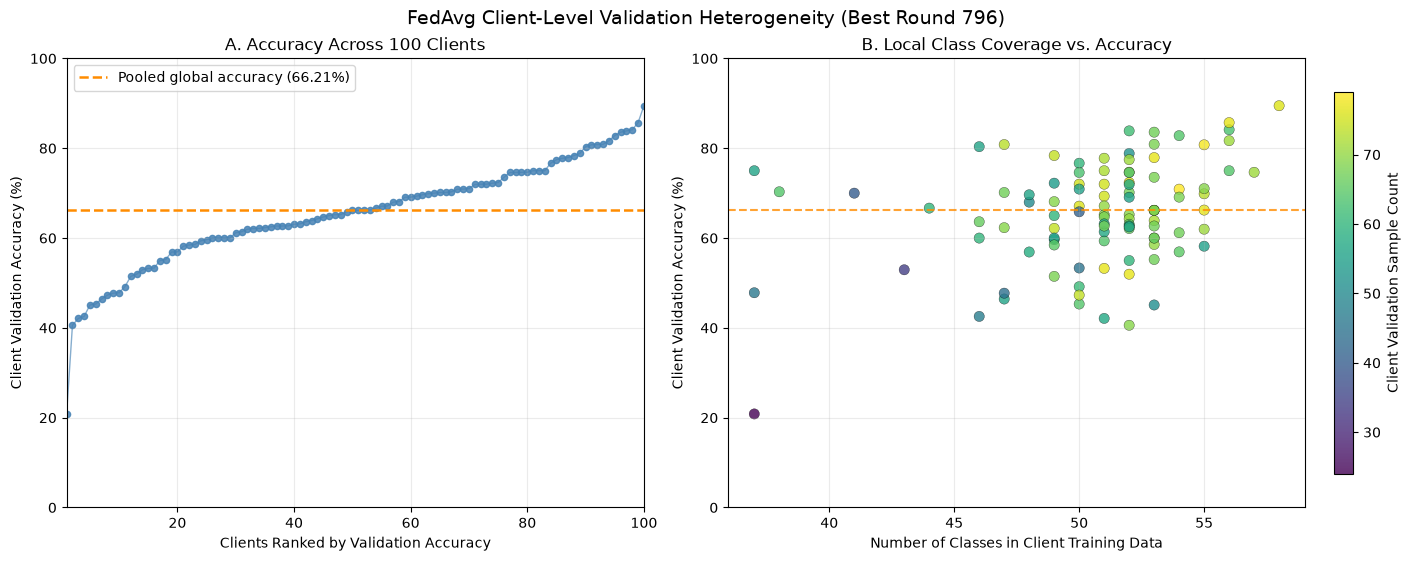


=== Non-standard Plot Summary ===
Global checkpoint agreement: PASSED
Per-client metrics computed: PASSED
Non-standard plot generated: PASSED

Saved files:
Output\client_validation_heterogeneity.png
Output\client_validation_heterogeneity.csv
Output\client_heterogeneity_summary.json

Non-standard plot completed successfully.


In [25]:

import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path

# ==========================================================
# Part 1.1 - Non-standard Plot
# Client-Level Validation Performance Heterogeneity
#
# Selected global model:
# C=10%, E=5, R=800, best round=796
#
# No training, no test data, no model modification.
# ==========================================================

OUTPUT_DIR = Path("Output")
CHECKPOINT_PATH = (
    OUTPUT_DIR / "FedAvg_C10_E5_R800"
    / "best_checkpoint.pt"
)

FIGURE_PATH = (
    OUTPUT_DIR / "client_validation_heterogeneity.png"
)

CSV_PATH = (
    OUTPUT_DIR / "client_validation_heterogeneity.csv"
)

JSON_PATH = (
    OUTPUT_DIR / "client_heterogeneity_summary.json"
)

BATCH_SIZE = 128
NUM_CLIENTS = 100
NUM_CLASSES = 62

assert CHECKPOINT_PATH.exists()
assert len(train_data) == NUM_CLIENTS
assert len(client_splits) == NUM_CLIENTS

# ----------------------------------------------------------
# 1. Load selected global model
# ----------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["config"]["client_fraction"] == 0.10
assert checkpoint["config"]["local_epochs"] == 5
assert checkpoint["config"]["planned_rounds"] == 800

model = FEMNISTMLP().cpu()
model.load_state_dict(checkpoint["model_state"])
model.eval()

best_round = int(checkpoint["round"])
reference_val_acc = float(checkpoint["val_accuracy"])
reference_val_loss = float(checkpoint["val_loss"])

print("=== Selected Global Model ===")
print("Best round:", best_round)
print(
    "Reference validation accuracy:",
    f"{reference_val_acc:.4%}"
)
print(
    "Reference validation loss:",
    f"{reference_val_loss:.6f}"
)

# ----------------------------------------------------------
# 2. Evaluate each client's validation partition
# ----------------------------------------------------------

records = []

global_correct = 0
global_samples = 0
global_loss_sum = 0.0

with torch.inference_mode():

    for cid in range(NUM_CLIENTS):

        train_idx = np.asarray(
            client_splits[cid]["train_idx"],
            dtype=np.int64
        )

        val_idx = np.asarray(
            client_splits[cid]["val_idx"],
            dtype=np.int64
        )

        all_labels = np.asarray(
            train_data[cid]["labels"],
            dtype=np.int64
        )

        train_labels = all_labels[train_idx]
        val_labels = all_labels[val_idx]

        n_train = len(train_idx)
        n_val = len(val_idx)

        assert n_train > 0
        assert n_val > 0

        # Class coverage of this client's training data
        train_class_count = len(
            np.unique(train_labels)
        )

        val_class_count = len(
            np.unique(val_labels)
        )

        # Count validation samples whose class is absent
        # from this client's own training partition
        unseen_val_count = int(
            np.sum(
                ~np.isin(
                    val_labels,
                    np.unique(train_labels)
                )
            )
        )

        correct = 0
        loss_sum = 0.0

        for start in range(0, n_val, BATCH_SIZE):

            batch_idx = val_idx[
                start:start + BATCH_SIZE
            ]

            images = np.asarray(
                [
                    train_data[cid]["images"][int(i)]
                    for i in batch_idx
                ],
                dtype=np.float32
            )

            labels = all_labels[batch_idx]

            assert images.shape == (
                len(batch_idx), 28, 28
            )

            x = torch.from_numpy(images)
            y = torch.from_numpy(labels)

            logits = model(x)

            batch_loss = F.cross_entropy(
                logits,
                y,
                reduction="sum"
            )

            predictions = logits.argmax(dim=1)

            correct += int(
                (predictions == y).sum().item()
            )

            loss_sum += float(batch_loss.item())

        accuracy = correct / n_val
        average_loss = loss_sum / n_val

        assert np.isfinite(accuracy)
        assert np.isfinite(average_loss)

        records.append({
            "client_id": cid,
            "train_samples": n_train,
            "val_samples": n_val,
            "train_classes": train_class_count,
            "val_classes": val_class_count,
            "missing_train_classes": (
                NUM_CLASSES - train_class_count
            ),
            "unseen_val_samples": unseen_val_count,
            "unseen_val_fraction": (
                unseen_val_count / n_val
            ),
            "val_correct": correct,
            "val_accuracy": accuracy,
            "val_loss": average_loss
        })

        global_correct += correct
        global_samples += n_val
        global_loss_sum += loss_sum

client_df = pd.DataFrame(records)

# ----------------------------------------------------------
# 3. Verify aggregate accuracy against checkpoint
# ----------------------------------------------------------

pooled_val_accuracy = global_correct / global_samples
pooled_val_loss = global_loss_sum / global_samples

assert global_samples == 6407

assert np.isclose(
    pooled_val_accuracy,
    reference_val_acc,
    atol=1e-6
), "Client-wise evaluation does not match checkpoint."

assert np.isclose(
    pooled_val_loss,
    reference_val_loss,
    atol=1e-5
), "Validation loss does not match checkpoint."

print("\n=== Global Evaluation Verification ===")
print("Clients evaluated:", len(client_df))
print("Validation samples:", global_samples)

print(
    "Recomputed pooled validation accuracy:",
    f"{pooled_val_accuracy:.4%}"
)

print(
    "Recomputed pooled validation loss:",
    f"{pooled_val_loss:.6f}"
)

print("Checkpoint agreement: PASSED")

# ----------------------------------------------------------
# 4. Quantify client-level performance variation
# ----------------------------------------------------------

client_accuracies = client_df[
    "val_accuracy"
].to_numpy()

train_class_counts = client_df[
    "train_classes"
].to_numpy()

mean_accuracy = float(
    np.mean(client_accuracies)
)

median_accuracy = float(
    np.median(client_accuracies)
)

std_accuracy = float(
    np.std(client_accuracies, ddof=1)
)

min_accuracy = float(
    np.min(client_accuracies)
)

max_accuracy = float(
    np.max(client_accuracies)
)

p10_accuracy = float(
    np.percentile(client_accuracies, 10)
)

p90_accuracy = float(
    np.percentile(client_accuracies, 90)
)

# Pearson correlation; descriptive, not causal
if np.std(train_class_counts) > 0:
    class_accuracy_corr = float(
        np.corrcoef(
            train_class_counts,
            client_accuracies
        )[0, 1]
    )
else:
    class_accuracy_corr = float("nan")

print("\n=== Client-Level Accuracy Statistics ===")
print("Unweighted client mean:", f"{mean_accuracy:.4%}")
print("Pooled global accuracy:", f"{pooled_val_accuracy:.4%}")
print("Median:", f"{median_accuracy:.4%}")
print("Standard deviation:", f"{std_accuracy:.4%}")
print("Minimum:", f"{min_accuracy:.4%}")
print("10th percentile:", f"{p10_accuracy:.4%}")
print("90th percentile:", f"{p90_accuracy:.4%}")
print("Maximum:", f"{max_accuracy:.4%}")
print(
    "Class coverage / accuracy correlation:",
    f"{class_accuracy_corr:.4f}"
)

# ----------------------------------------------------------
# 5. Create the non-standard visualization
# ----------------------------------------------------------

sorted_df = client_df.sort_values(
    "val_accuracy"
).reset_index(drop=True)

ranks = np.arange(1, NUM_CLIENTS + 1)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    constrained_layout=True
)

# Panel A: sorted client validation accuracy

axes[0].plot(
    ranks,
    sorted_df["val_accuracy"] * 100,
    linewidth=1.0,
    color="steelblue",
    alpha=0.65
)

axes[0].scatter(
    ranks,
    sorted_df["val_accuracy"] * 100,
    s=20,
    color="steelblue",
    alpha=0.85
)

axes[0].axhline(
    pooled_val_accuracy * 100,
    color="darkorange",
    linestyle="--",
    linewidth=1.8,
    label=(
        f"Pooled global accuracy "
        f"({pooled_val_accuracy:.2%})"
    )
)

axes[0].set_title(
    "A. Accuracy Across 100 Clients"
)

axes[0].set_xlabel(
    "Clients Ranked by Validation Accuracy"
)

axes[0].set_ylabel(
    "Client Validation Accuracy (%)"
)

axes[0].set_xlim(1, NUM_CLIENTS)
axes[0].set_ylim(0, 100)
axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper left")

# Panel B: local class coverage vs validation accuracy

scatter = axes[1].scatter(
    client_df["train_classes"],
    client_df["val_accuracy"] * 100,
    c=client_df["val_samples"],
    cmap="viridis",
    s=55,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.25
)

axes[1].axhline(
    pooled_val_accuracy * 100,
    color="darkorange",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8
)

axes[1].set_title(
    "B. Local Class Coverage vs. Accuracy"
)

axes[1].set_xlabel(
    "Number of Classes in Client Training Data"
)

axes[1].set_ylabel(
    "Client Validation Accuracy (%)"
)

axes[1].set_ylim(0, 100)
axes[1].grid(alpha=0.25)

colorbar = fig.colorbar(
    scatter,
    ax=axes[1],
    shrink=0.85
)

colorbar.set_label(
    "Client Validation Sample Count"
)

fig.suptitle(
    "FedAvg Client-Level Validation Heterogeneity "
    f"(Best Round {best_round})",
    fontsize=14
)

fig.savefig(
    FIGURE_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ----------------------------------------------------------
# 6. Save client metrics and summary
# ----------------------------------------------------------

client_df.to_csv(
    CSV_PATH,
    index=False
)

summary = {
    "experiment": "FedAvg_C10_E5_R800",
    "selected_round": best_round,
    "clients_evaluated": NUM_CLIENTS,
    "validation_samples": global_samples,
    "pooled_validation_accuracy": pooled_val_accuracy,
    "pooled_validation_loss": pooled_val_loss,
    "unweighted_client_mean_accuracy": mean_accuracy,
    "median_client_accuracy": median_accuracy,
    "std_client_accuracy": std_accuracy,
    "minimum_client_accuracy": min_accuracy,
    "percentile_10_accuracy": p10_accuracy,
    "percentile_90_accuracy": p90_accuracy,
    "maximum_client_accuracy": max_accuracy,
    "class_accuracy_pearson_correlation": (
        class_accuracy_corr
    )
}

with open(JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("\n=== Non-standard Plot Summary ===")
print("Global checkpoint agreement: PASSED")
print("Per-client metrics computed: PASSED")
print("Non-standard plot generated: PASSED")

print("\nSaved files:")
print(FIGURE_PATH)
print(CSV_PATH)
print(JSON_PATH)

print("\nNon-standard plot completed successfully.")


In [26]:

import sys
import os
import platform
import shutil
import importlib.util
import importlib.metadata
from pathlib import Path

import torch

# ==========================================================
# Part 1.2 - Step 1.1
# Ray Environment and Hardware Audit
#
# No Ray initialization
# No Actor creation
# No model training
# ==========================================================

print("=== 1. Python Environment ===")

print("Operating system:", platform.system())
print("OS version:", platform.version())
print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Platform architecture:", platform.machine())

# ----------------------------------------------------------
# 2. Ray installation
# ----------------------------------------------------------

print("\n=== 2. Ray Installation ===")

ray_spec = importlib.util.find_spec("ray")

try:
    ray_version = importlib.metadata.version("ray")
except importlib.metadata.PackageNotFoundError:
    ray_version = None

print("Ray installed:", ray_spec is not None)
print("Ray version:", ray_version or "NOT INSTALLED")

if ray_spec is None:
    print("STATUS: Ray installation required.")
else:
    print("STATUS: Ray package detected.")
    print("Ray startup has NOT been tested yet.")

# ----------------------------------------------------------
# 3. CPU resources
# ----------------------------------------------------------

print("\n=== 3. CPU Resources ===")

logical_cpus = os.cpu_count()

print("Logical CPU cores:", logical_cpus)
print("PyTorch CPU threads:", torch.get_num_threads())

try:
    import psutil

    physical_cpus = psutil.cpu_count(logical=False)
    cpu_usage = psutil.cpu_percent(interval=0.3)

    print("Physical CPU cores:", physical_cpus)
    print("Current CPU usage:", f"{cpu_usage:.1f}%")

except ImportError:
    psutil = None
    print("psutil unavailable; detailed CPU usage skipped.")

# ----------------------------------------------------------
# 4. System memory
# ----------------------------------------------------------

print("\n=== 4. System Memory ===")

available_ram_gb = None

if psutil is not None:

    memory = psutil.virtual_memory()

    total_ram_gb = memory.total / (1024 ** 3)
    available_ram_gb = memory.available / (1024 ** 3)

    print("Total RAM:", f"{total_ram_gb:.2f} GB")
    print("Available RAM:", f"{available_ram_gb:.2f} GB")
    print("Memory usage:", f"{memory.percent:.1f}%")

else:
    print("Memory statistics unavailable.")

# ----------------------------------------------------------
# 5. GPU information
# ----------------------------------------------------------

print("\n=== 5. GPU Resources ===")

print("PyTorch version:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

gpu_count = 0

if torch.cuda.is_available():

    gpu_count = torch.cuda.device_count()

    print("Detected GPU count:", gpu_count)

    for gpu_id in range(gpu_count):

        properties = torch.cuda.get_device_properties(gpu_id)

        print(f"\nGPU {gpu_id}:")
        print("Name:", properties.name)

        total_vram_gb = (
            properties.total_memory / (1024 ** 3)
        )

        print(
            "Total VRAM:",
            f"{total_vram_gb:.2f} GB"
        )

else:
    print("CPU-only execution is available.")

# ----------------------------------------------------------
# 6. Storage and current project
# ----------------------------------------------------------

print("\n=== 6. Storage and Project ===")

output_dir = Path("Output")

disk = shutil.disk_usage(Path.cwd())
disk_free_gb = disk.free / (1024 ** 3)

print("Working directory:", Path.cwd())
print("Available disk:", f"{disk_free_gb:.2f} GB")
print("Output directory exists:", output_dir.exists())

required_objects = [
    "train_data",
    "client_splits",
    "FEMNISTMLP",
    "fedavg_aggregate",
    "evaluate_global_model"
]

for name in required_objects:
    print(f"{name} available:", name in globals())

# ----------------------------------------------------------
# 7. Preliminary parallel resource recommendation
# ----------------------------------------------------------

print("\n=== 7. Preliminary Resource Assessment ===")

TARGET_ACTORS = 4

print("Requested parallel Actors:", TARGET_ACTORS)
print("Proposed CPU per Actor: 1")
print("Proposed GPU per Actor: 0")

if logical_cpus is not None and logical_cpus >= 6:
    print("CPU capacity for 4 Actors: LIKELY SUFFICIENT")
else:
    print("CPU capacity: NEEDS REVIEW")

if available_ram_gb is None:
    print("RAM capacity: UNKNOWN")
elif available_ram_gb >= 8:
    print("Available RAM: GOOD FOR INITIAL TESTING")
elif available_ram_gb >= 4:
    print("Available RAM: USE CAUTION")
else:
    print("Available RAM: LOW - REDUCE RESOURCE USAGE")

print("\nNo Ray processes or Actors were started.")
print("Environment audit completed.")


=== 1. Python Environment ===
Operating system: Windows
OS version: 10.0.26200
Python version: 3.11.15
Python executable: C:\Users\24298\miniconda3\envs\data\python.exe
Platform architecture: AMD64

=== 2. Ray Installation ===
Ray installed: False
Ray version: NOT INSTALLED
STATUS: Ray installation required.

=== 3. CPU Resources ===
Logical CPU cores: 32
PyTorch CPU threads: 4
Physical CPU cores: 24
Current CPU usage: 5.7%

=== 4. System Memory ===
Total RAM: 31.73 GB
Available RAM: 16.23 GB
Memory usage: 48.8%

=== 5. GPU Resources ===
PyTorch version: 2.14.1+cu126
CUDA build: 12.6
CUDA available: True
Detected GPU count: 1

GPU 0:
Name: NVIDIA GeForce RTX 4090 Laptop GPU
Total VRAM: 15.99 GB

=== 6. Storage and Project ===
Working directory: C:\Users\24298\Downloads\Assignment3-data\Assignment3-data
Available disk: 606.13 GB
Output directory exists: True
train_data available: True
client_splits available: True
FEMNISTMLP available: True
fedavg_aggregate available: True
evaluate_glob

In [28]:
import ray
import sys

print("=== Ray Installation Verification ===")
print("Ray version:", ray.__version__)
print("Python executable:", sys.executable)
print("Ray imported successfully: PASSED")

=== Ray Installation Verification ===
Ray version: 2.60.0
Python executable: C:\Users\24298\miniconda3\envs\data\python.exe
Ray imported successfully: PASSED


In [29]:

import ray
import os

# ==========================================================
# Part 1.2 - Step 1.3
# Initialize Local Ray Runtime
#
# CPU resources: 4
# GPU resources: 0
# No Actors or training yet
# ==========================================================

print("=== Ray Runtime Initialization ===")

if ray.is_initialized():
    print("Ray is already initialized.")
    print("Reusing the current Ray runtime.")
else:
    print("Starting a new local Ray runtime...")

    ray.init(
        address="local",
        num_cpus=4,
        num_gpus=0,
        object_store_memory=512 * 1024 * 1024,
        include_dashboard=False,
        log_to_driver=False,
    )

# ----------------------------------------------------------
# Verify Ray resources
# ----------------------------------------------------------

print("\n=== Ray Resource Verification ===")

cluster_resources = ray.cluster_resources()
available_resources = ray.available_resources()

print("Ray version:", ray.__version__)
print("Ray initialized:", ray.is_initialized())

print("\nCluster resources:")
print(cluster_resources)

print("\nAvailable resources:")
print(available_resources)

total_cpus = cluster_resources.get("CPU", 0)
total_gpus = cluster_resources.get("GPU", 0)

print("\nConfigured Ray CPUs:", total_cpus)
print("Configured Ray GPUs:", total_gpus)

assert ray.is_initialized()
assert total_cpus == 4
assert total_gpus == 0

print("\n=== Initialization Summary ===")
print("Local Ray runtime: PASSED")
print("Four CPU scheduling slots: PASSED")
print("GPU disabled for Ray: PASSED")
print("Actor creation: NOT STARTED")
print("Model training: NOT STARTED")

print("\nRay initialization completed successfully.")


2026-11-19 07:46:14,476	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-11-19 07:46:14,479	INFO authentication_token_setup.py:50 -- Generated new authentication token and saved to C:\Users\24298\.ray\auth_token


=== Ray Runtime Initialization ===
Starting a new local Ray runtime...


2026-11-19 07:46:19,966	INFO worker.py:2038 -- Started a local Ray instance.



=== Ray Resource Verification ===
Ray version: 2.60.0
Ray initialized: True

Cluster resources:
{'CPU': 4.0, 'node:127.0.0.1': 1.0, 'memory': 16287756288.0, 'node:__internal_head__': 1.0, 'object_store_memory': 536870912.0}

Available resources:
{'node:127.0.0.1': 1.0, 'CPU': 4.0, 'memory': 16287756288.0, 'node:__internal_head__': 1.0, 'object_store_memory': 536870912.0}

Configured Ray CPUs: 4.0
Configured Ray GPUs: 0

=== Initialization Summary ===
Local Ray runtime: PASSED
Four CPU scheduling slots: PASSED
GPU disabled for Ray: PASSED
Actor creation: NOT STARTED
Model training: NOT STARTED

Ray initialization completed successfully.


In [30]:

import os
import ray

# ==========================================================
# Part 1.2 - Step 1.4
# Single Ray Actor Smoke Test
#
# 1 Actor
# 1 CPU per Actor
# 0 GPU per Actor
# No FedAvg training
# ==========================================================

assert ray.is_initialized(), "Ray is not initialized."

print("=== Single Ray Actor Smoke Test ===")

driver_pid = os.getpid()
print("Jupyter driver PID:", driver_pid)

# ----------------------------------------------------------
# 1. Define an independent Ray Actor
# ----------------------------------------------------------

@ray.remote(num_cpus=1, num_gpus=0)
class RaySmokeTestActor:

    def __init__(self):
        import os
        import torch

        # Prevent CPU thread oversubscription
        torch.set_num_threads(1)

        self.pid = os.getpid()
        self.cpu_threads = torch.get_num_threads()

    def run_test(self):
        import torch

        # Small deterministic calculation on CPU
        x = torch.tensor(
            [1.0, 2.0, 3.0, 4.0],
            dtype=torch.float32,
            device="cpu"
        )

        result = torch.sum(x * x).item()

        return {
            "actor_pid": self.pid,
            "cpu_threads": self.cpu_threads,
            "result": result,
            "torch_version": torch.__version__,
            "ray_gpu_ids": ray.get_gpu_ids()
        }

# ----------------------------------------------------------
# 2. Create Actor and perform test
# ----------------------------------------------------------

actor = None

try:
    actor = RaySmokeTestActor.remote()

    result = ray.get(
        actor.run_test.remote(),
        timeout=90
    )

    print("\n=== Actor Execution Results ===")
    print("Actor PID:", result["actor_pid"])
    print("PyTorch version:", result["torch_version"])
    print("PyTorch CPU threads:", result["cpu_threads"])
    print("Assigned Ray GPU IDs:", result["ray_gpu_ids"])
    print("Calculation result:", result["result"])

    # ------------------------------------------------------
    # 3. Verify expected behavior
    # ------------------------------------------------------

    assert result["actor_pid"] != driver_pid
    assert result["cpu_threads"] == 1
    assert result["ray_gpu_ids"] == []
    assert abs(result["result"] - 30.0) < 1e-6

    print("\n=== Verification ===")
    print("Independent Actor process: PASSED")
    print("PyTorch available inside Actor: PASSED")
    print("Single PyTorch CPU thread: PASSED")
    print("No Ray GPU allocation: PASSED")
    print("Deterministic calculation: PASSED")

finally:
    # Terminate only this test Actor.
    # Keep the main Ray runtime running.
    if actor is not None:
        ray.kill(actor)
        print("\nSmoke-test Actor terminated.")

print("\n=== Final Status ===")
print("Ray runtime still initialized:", ray.is_initialized())
print("Single Actor smoke test completed successfully.")


=== Single Ray Actor Smoke Test ===
Jupyter driver PID: 28736

=== Actor Execution Results ===
Actor PID: 38560
PyTorch version: 2.14.1+cu126
PyTorch CPU threads: 1
Assigned Ray GPU IDs: []
Calculation result: 30.0

=== Verification ===
Independent Actor process: PASSED
PyTorch available inside Actor: PASSED
Single PyTorch CPU thread: PASSED
No Ray GPU allocation: PASSED
Deterministic calculation: PASSED

Smoke-test Actor terminated.

=== Final Status ===
Ray runtime still initialized: True
Single Actor smoke test completed successfully.


In [31]:

import os
import time
import ray

# ==========================================================
# Part 1.2 - Step 1.5
# Four Parallel Ray Actors - Concurrency Smoke Test
#
# 4 Actors
# 1 CPU per Actor
# 0 GPU per Actor
#
# No FEMNIST loading or FedAvg training
# ==========================================================

assert ray.is_initialized(), "Ray runtime is not initialized."

NUM_ACTORS = 4
TASK_DURATION = 3.0

print("=== Four-Actor Parallel Test ===")
print("Requested Actors:", NUM_ACTORS)
print("CPU per Actor: 1")
print("GPU per Actor: 0")

# ----------------------------------------------------------
# 1. Define Ray Actor
# ----------------------------------------------------------

@ray.remote(num_cpus=1, num_gpus=0)
class ParallelSmokeActor:

    def __init__(self, actor_id):

        import os
        import torch

        torch.set_num_threads(1)

        self.actor_id = actor_id
        self.pid = os.getpid()

    def get_info(self):

        import torch
        import ray

        return {
            "actor_id": self.actor_id,
            "pid": self.pid,
            "cpu_threads": torch.get_num_threads(),
            "gpu_ids": ray.get_gpu_ids()
        }

    def run_task(self, duration):

        import time
        import torch

        start_time = time.time()

        # Execute a small CPU calculation
        x = torch.arange(
            1, 1001,
            dtype=torch.float32,
            device="cpu"
        )

        result = float(torch.sum(x).item())

        # Controlled execution window
        time.sleep(duration)

        end_time = time.time()

        return {
            "actor_id": self.actor_id,
            "pid": self.pid,
            "result": result,
            "start_time": start_time,
            "end_time": end_time,
            "duration": end_time - start_time
        }

# ----------------------------------------------------------
# 2. Create and initialize all four Actors
# ----------------------------------------------------------

actors = []

try:

    print("\n=== Creating Four Actors ===")

    for actor_id in range(NUM_ACTORS):

        actor = ParallelSmokeActor.remote(actor_id)
        actors.append(actor)

    # Ensure all Actors are initialized before timing
    actor_infos = ray.get(
        [actor.get_info.remote() for actor in actors],
        timeout=120
    )

    print("\n=== Actor Resource Information ===")

    for info in actor_infos:

        print(
            f"Actor {info['actor_id']} | "
            f"PID: {info['pid']} | "
            f"CPU Threads: {info['cpu_threads']} | "
            f"GPU IDs: {info['gpu_ids']}"
        )

    # Verify distinct processes and resources
    pids = [info["pid"] for info in actor_infos]

    assert len(set(pids)) == NUM_ACTORS

    assert all(
        info["cpu_threads"] == 1
        for info in actor_infos
    )

    assert all(
        info["gpu_ids"] == []
        for info in actor_infos
    )

    print("\nFour independent Actor processes: PASSED")
    print("Per-Actor CPU thread limit: PASSED")
    print("GPU allocation disabled: PASSED")

    # ------------------------------------------------------
    # 3. Submit all tasks before waiting for results
    # ------------------------------------------------------

    print("\n=== Parallel Task Execution ===")

    wall_start = time.perf_counter()

    # IMPORTANT: submit all four tasks first
    task_refs = [
        actor.run_task.remote(TASK_DURATION)
        for actor in actors
    ]

    # Wait for all four tasks together
    results = ray.get(task_refs, timeout=60)

    wall_elapsed = time.perf_counter() - wall_start

    # ------------------------------------------------------
    # 4. Examine execution overlap
    # ------------------------------------------------------

    results = sorted(
        results,
        key=lambda result: result["actor_id"]
    )

    for result in results:

        print(
            f"Actor {result['actor_id']} | "
            f"PID: {result['pid']} | "
            f"Result: {result['result']:.1f} | "
            f"Duration: {result['duration']:.3f}s"
        )

    start_times = [
        result["start_time"]
        for result in results
    ]

    end_times = [
        result["end_time"]
        for result in results
    ]

    # Positive overlap means all four task intervals
    # have a common period of simultaneous execution.
    common_overlap = (
        min(end_times) - max(start_times)
    )

    assert all(
        abs(result["result"] - 500500.0) < 1e-6
        for result in results
    )

    print("\n=== Parallel Execution Analysis ===")
    print(
        "Total task wall time:",
        f"{wall_elapsed:.3f}s"
    )

    print(
        "Common execution overlap:",
        f"{common_overlap:.3f}s"
    )

    if common_overlap > 0:

        print("All four tasks overlapped: PASSED")

    else:

        raise AssertionError(
            "The four task intervals did not overlap. "
            "Parallel scheduling needs investigation."
        )

    # ------------------------------------------------------
    # 5. Verify Ray remains operational
    # ------------------------------------------------------

    print("\n=== Runtime Verification ===")

    resources = ray.cluster_resources()

    print("Configured CPUs:", resources.get("CPU", 0))
    print("Configured GPUs:", resources.get("GPU", 0))

    assert resources.get("CPU", 0) == 4
    assert resources.get("GPU", 0) == 0

    print("Ray resource configuration: PASSED")

finally:

    # Clean up test Actors even if assertions fail
    print("\n=== Actor Cleanup ===")

    for actor in actors:
        try:
            ray.kill(actor)
        except Exception as exc:
            print("Actor cleanup warning:", str(exc))

    print("Test Actor cleanup requested.")

print("\n=== Final Summary ===")
print("Independent Actor processes: PASSED")
print("Four-Actor task concurrency: PASSED")
print("CPU-only execution: PASSED")
print("Ray runtime still active:", ray.is_initialized())

print("\nFour-Actor smoke test completed successfully.")


=== Four-Actor Parallel Test ===
Requested Actors: 4
CPU per Actor: 1
GPU per Actor: 0

=== Creating Four Actors ===

=== Actor Resource Information ===
Actor 0 | PID: 40188 | CPU Threads: 1 | GPU IDs: []
Actor 1 | PID: 9204 | CPU Threads: 1 | GPU IDs: []
Actor 2 | PID: 21968 | CPU Threads: 1 | GPU IDs: []
Actor 3 | PID: 22360 | CPU Threads: 1 | GPU IDs: []

Four independent Actor processes: PASSED
Per-Actor CPU thread limit: PASSED
GPU allocation disabled: PASSED

=== Parallel Task Execution ===
Actor 0 | PID: 40188 | Result: 500500.0 | Duration: 3.013s
Actor 1 | PID: 9204 | Result: 500500.0 | Duration: 3.013s
Actor 2 | PID: 21968 | Result: 500500.0 | Duration: 3.013s
Actor 3 | PID: 22360 | Result: 500500.0 | Duration: 3.012s

=== Parallel Execution Analysis ===
Total task wall time: 3.020s
Common execution overlap: 3.012s
All four tasks overlapped: PASSED

=== Runtime Verification ===
Configured CPUs: 4.0
Configured GPUs: 0
Ray resource configuration: PASSED

=== Actor Cleanup ===
Te

In [32]:

import os
import time
import numpy as np
import torch
import ray

# ==========================================================
# Part 1.2 - Step 2.1
# Ray Client Actor + One-Round FedAvg Smoke Test
#
# 4 parallel clients, E=5, batch size=32
# No formal training, checkpoint loading, or test data
# ==========================================================

assert ray.is_initialized(), "Ray runtime is not initialized."
assert ray.cluster_resources().get("CPU", 0) >= 4

NUM_SELECTED_CLIENTS = 4
LOCAL_EPOCHS = 5
LEARNING_RATE = 0.01
BATCH_SIZE = 32
ROUND_ID = 0

saved_rng = torch.get_rng_state()

# ----------------------------------------------------------
# 1. Define self-contained Ray Client Actor
# ----------------------------------------------------------

@ray.remote(num_cpus=1, num_gpus=0)
class FEMNISTRayClientActor:

    def __init__(self, client_id, images, labels):
        import os
        import numpy as np
        import torch

        torch.set_num_threads(1)

        self.client_id = int(client_id)
        self.pid = os.getpid()

        self.images = torch.from_numpy(
            np.asarray(images, dtype=np.float32).copy()
        )

        self.labels = torch.from_numpy(
            np.asarray(labels, dtype=np.int64).copy()
        )

        assert self.images.ndim == 3
        assert self.images.shape[1:] == (28, 28)
        assert len(self.images) == len(self.labels)
        assert len(self.labels) > 0

    def train(self, global_state, local_epochs,
              learning_rate, batch_size, round_id):

        import time
        import torch
        import torch.nn as nn
        import torch.nn.functional as F
        import ray

        start = time.perf_counter()

        # Same architecture as Part 1.1 FEMNISTMLP
        class LocalMLP(nn.Module):
            def __init__(self):
                super().__init__()
                self.fc1 = nn.Linear(784, 128)
                self.fc2 = nn.Linear(128, 62)

            def forward(self, x):
                x = x.reshape(x.shape[0], -1)
                x = F.relu(self.fc1(x))
                return self.fc2(x)

        assert local_epochs >= 1
        assert learning_rate > 0
        assert batch_size >= 1

        model = LocalMLP().cpu()
        model.load_state_dict(global_state)
        model.train()

        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=learning_rate
        )

        n_samples = len(self.labels)

        generator = torch.Generator()
        generator.manual_seed(
            42 + round_id * 1000 + self.client_id
        )

        total_loss = 0.0
        total_processed = 0
        optimizer_steps = 0

        # Local mini-batch SGD
        for epoch in range(local_epochs):

            permutation = torch.randperm(
                n_samples,
                generator=generator
            )

            for start_idx in range(0, n_samples, batch_size):

                indices = permutation[
                    start_idx:start_idx + batch_size
                ]

                x = self.images[indices]
                y = self.labels[indices]

                optimizer.zero_grad(set_to_none=True)

                logits = model(x)
                loss = F.cross_entropy(logits, y)

                loss.backward()
                optimizer.step()

                total_loss += loss.item() * len(y)
                total_processed += len(y)
                optimizer_steps += 1

        updated_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        assert total_processed == n_samples * local_epochs
        assert all(
            torch.isfinite(value).all().item()
            for value in updated_state.values()
        )

        return {
            "client_id": self.client_id,
            "pid": self.pid,
            "n_samples": n_samples,
            "mean_local_loss": total_loss / total_processed,
            "optimizer_steps": optimizer_steps,
            "cpu_threads": torch.get_num_threads(),
            "gpu_ids": ray.get_gpu_ids(),
            "elapsed_seconds": time.perf_counter() - start,
            "model_state": updated_state
        }

# ----------------------------------------------------------
# 2. Select four real FEMNIST clients
# ----------------------------------------------------------

actors = []

try:
    selected_clients = [
        int(cid)
        for cid in select_clients(
            round_id=ROUND_ID,
            client_fraction=0.04,
            seed=42
        )
    ]

    assert len(selected_clients) == NUM_SELECTED_CLIENTS
    assert len(set(selected_clients)) == NUM_SELECTED_CLIENTS

    print("=== Ray FedAvg One-Round Configuration ===")
    print("Selected clients:", selected_clients)
    print("Local epochs:", LOCAL_EPOCHS)
    print("Batch size:", BATCH_SIZE)
    print("Learning rate:", LEARNING_RATE)

    # ------------------------------------------------------
    # 3. Initialize the global model
    # ------------------------------------------------------

    torch.manual_seed(42)

    global_model = FEMNISTMLP().cpu()

    initial_state = {
        key: value.detach().clone()
        for key, value in global_model.state_dict().items()
    }

    print("\nInitial model parameters:",
          sum(p.numel() for p in global_model.parameters()))

    # ------------------------------------------------------
    # 4. Create exactly four selected-client Actors
    # ------------------------------------------------------

    print("\n=== Creating Client Actors ===")

    for cid in selected_clients:

        train_indices = np.asarray(
            client_splits[cid]["train_idx"],
            dtype=np.int64
        )

        client_images = np.asarray(
            [
                train_data[cid]["images"][int(i)]
                for i in train_indices
            ],
            dtype=np.float32
        )

        client_labels = np.asarray(
            [
                train_data[cid]["labels"][int(i)]
                for i in train_indices
            ],
            dtype=np.int64
        )

        actor = FEMNISTRayClientActor.remote(
            cid,
            client_images,
            client_labels
        )

        actors.append(actor)

    print("Actors created:", len(actors))

    # ------------------------------------------------------
    # 5. Execute local SGD concurrently
    # ------------------------------------------------------

    print("\n=== Parallel Local Training ===")

    # Store global weights once in Ray object store
    global_state_ref = ray.put(initial_state)

    parallel_start = time.perf_counter()

    # Submit all tasks before waiting
    futures = [
        actor.train.remote(
            global_state_ref,
            LOCAL_EPOCHS,
            LEARNING_RATE,
            BATCH_SIZE,
            ROUND_ID
        )
        for actor in actors
    ]

    results = ray.get(futures, timeout=180)

    parallel_elapsed = time.perf_counter() - parallel_start

    # ------------------------------------------------------
    # 6. Verify individual client updates
    # ------------------------------------------------------

    print("\n=== Client Training Results ===")

    assert len(results) == NUM_SELECTED_CLIENTS
    assert len({r["pid"] for r in results}) == 4

    client_updates = []

    for result in results:

        cid = result["client_id"]
        n_samples = result["n_samples"]

        assert n_samples == len(
            client_splits[cid]["train_idx"]
        )

        assert result["cpu_threads"] == 1
        assert result["gpu_ids"] == []
        assert np.isfinite(result["mean_local_loss"])

        expected_steps = (
            LOCAL_EPOCHS
            * ((n_samples + BATCH_SIZE - 1) // BATCH_SIZE)
        )

        assert result["optimizer_steps"] == expected_steps

        assert set(result["model_state"]) == set(initial_state)

        client_updates.append(
            (result["model_state"], n_samples)
        )

        print(
            f"Client {cid:3d} | "
            f"PID {result['pid']:6d} | "
            f"Samples {n_samples:3d} | "
            f"SGD steps {result['optimizer_steps']:3d} | "
            f"Local loss {result['mean_local_loss']:.4f} | "
            f"Time {result['elapsed_seconds']:.3f}s"
        )

    # ------------------------------------------------------
    # 7. Weighted FedAvg aggregation
    # ------------------------------------------------------

    print("\n=== Server Aggregation ===")

    aggregated_state = fedavg_aggregate(client_updates)

    global_model.load_state_dict(aggregated_state)

    max_parameter_change = max(
        float(
            (
                aggregated_state[key] - initial_state[key]
            ).abs().max()
        )
        for key in initial_state
    )

    assert max_parameter_change > 0
    assert np.isfinite(max_parameter_change)

    print("Participating clients:", len(client_updates))
    print(
        "Total participating samples:",
        sum(n for _, n in client_updates)
    )
    print(
        "Maximum global parameter change:",
        f"{max_parameter_change:.8e}"
    )
    print(
        "Parallel local training wall time:",
        f"{parallel_elapsed:.3f}s"
    )

    # ------------------------------------------------------
    # 8. Evaluate the updated global model
    # ------------------------------------------------------

    print("\n=== Updated Global Model Evaluation ===")

    train_metrics = evaluate_global_model(
        global_model,
        split="train",
        batch_size=128
    )

    val_metrics = evaluate_global_model(
        global_model,
        split="val",
        batch_size=128
    )

    assert train_metrics["samples"] == 25418
    assert val_metrics["samples"] == 6407

    print(
        "Global train loss:",
        f"{train_metrics['loss']:.6f}"
    )
    print(
        "Global train accuracy:",
        f"{train_metrics['accuracy']:.4%}"
    )
    print(
        "Global validation loss:",
        f"{val_metrics['loss']:.6f}"
    )
    print(
        "Global validation accuracy:",
        f"{val_metrics['accuracy']:.4%}"
    )

    print("\n=== One-Round Verification ===")
    print("Four distinct clients selected: PASSED")
    print("Four Actor processes executed: PASSED")
    print("Local mini-batch SGD: PASSED")
    print("Correct optimizer step counts: PASSED")
    print("Sample-weighted FedAvg: EXECUTED")
    print("Global model updated: PASSED")
    print("Global train/validation evaluation: PASSED")

finally:
    print("\n=== Actor Cleanup ===")

    for actor in actors:
        try:
            ray.kill(actor)
        except Exception as exc:
            print("Cleanup warning:", str(exc))

    torch.set_rng_state(saved_rng)

    print("Client Actor cleanup requested.")
    print("Ray runtime active:", ray.is_initialized())

print("\nRay FedAvg one-round smoke test completed successfully.")


=== Ray FedAvg One-Round Configuration ===
Selected clients: [43, 8, 64, 75]
Local epochs: 5
Batch size: 32
Learning rate: 0.01

Initial model parameters: 108478

=== Creating Client Actors ===
Actors created: 4

=== Parallel Local Training ===

=== Client Training Results ===
Client  43 | PID  36644 | Samples 244 | SGD steps  40 | Local loss 3.8854 | Time 1.996s
Client   8 | PID  37368 | Samples 305 | SGD steps  50 | Local loss 3.8287 | Time 2.007s
Client  64 | PID  38676 | Samples 271 | SGD steps  45 | Local loss 3.8774 | Time 2.017s
Client  75 | PID  38620 | Samples 220 | SGD steps  35 | Local loss 3.9084 | Time 1.996s

=== Server Aggregation ===
Participating clients: 4
Total participating samples: 1040
Maximum global parameter change: 2.48434767e-02
Parallel local training wall time: 4.462s

=== Updated Global Model Evaluation ===
Global train loss: 3.818529
Global train accuracy: 5.2286%
Global validation loss: 3.812934
Global validation accuracy: 5.4784%

=== One-Round Verificat

In [33]:

import time
import numpy as np
import torch
import ray

# ==========================================================
# Part 1.2 - Step 2.2
# Serial vs. Parallel FedAvg Numerical Consistency
#
# Same clients, same model, same seeds
# C = 4%, E = 5, R = 1
#
# No checkpoint loading or held-out test data
# ==========================================================

assert ray.is_initialized()
assert "FEMNISTRayClientActor" in globals()

saved_rng = torch.get_rng_state()

try:
    # ------------------------------------------------------
    # 1. Shared experimental configuration
    # ------------------------------------------------------

    client_ids = [
        int(cid)
        for cid in select_clients(
            round_id=0,
            client_fraction=0.04,
            seed=42
        )
    ]

    local_epochs = 5
    learning_rate = 0.01
    batch_size = 32
    round_id = 0

    assert len(client_ids) == 4
    assert len(set(client_ids)) == 4

    torch.manual_seed(42)

    initial_model = FEMNISTMLP().cpu()

    shared_state = {
        k: v.detach().cpu().clone()
        for k, v in initial_model.state_dict().items()
    }

    print("=== Numerical Consistency Configuration ===")
    print("Selected clients:", client_ids)
    print("Local epochs:", local_epochs)
    print("Learning rate:", learning_rate)
    print("Batch size:", batch_size)

    # ------------------------------------------------------
    # 2. Serial FedAvg: original Part 1.1 implementation
    # ------------------------------------------------------

    print("\n=== Path A: Serial FedAvg ===")

    serial_start = time.perf_counter()

    serial_updates = {}
    serial_losses = {}

    for cid in client_ids:

        state, n_samples, local_loss = train_one_client(
            client_id=cid,
            global_state=shared_state,
            local_epochs=local_epochs,
            learning_rate=learning_rate,
            batch_size=batch_size,
            round_id=round_id
        )

        serial_updates[cid] = (state, n_samples)
        serial_losses[cid] = float(local_loss)

        assert np.isfinite(local_loss)

    serial_aggregate = fedavg_aggregate(
        [serial_updates[cid] for cid in client_ids]
    )

    serial_elapsed = time.perf_counter() - serial_start

    print("Serial training completed.")
    print("Serial elapsed:", f"{serial_elapsed:.3f}s")

    # ------------------------------------------------------
    # 3. Parallel FedAvg: Ray Actor implementation
    # ------------------------------------------------------

    print("\n=== Path B: Parallel Ray FedAvg ===")

    actors = []

    try:
        parallel_start = time.perf_counter()

        for cid in client_ids:

            indices = np.asarray(
                client_splits[cid]["train_idx"],
                dtype=np.int64
            )

            images = np.asarray(
                [
                    train_data[cid]["images"][int(i)]
                    for i in indices
                ],
                dtype=np.float32
            )

            labels = np.asarray(
                [
                    train_data[cid]["labels"][int(i)]
                    for i in indices
                ],
                dtype=np.int64
            )

            actor = FEMNISTRayClientActor.remote(
                cid, images, labels
            )

            actors.append(actor)

        state_ref = ray.put(shared_state)

        # Submit all four tasks before waiting
        futures = [
            actor.train.remote(
                state_ref,
                local_epochs,
                learning_rate,
                batch_size,
                round_id
            )
            for actor in actors
        ]

        parallel_results = ray.get(
            futures,
            timeout=180
        )

        parallel_elapsed = (
            time.perf_counter() - parallel_start
        )

    finally:
        for actor in actors:
            try:
                ray.kill(actor)
            except Exception as exc:
                print("Cleanup warning:", str(exc))

    assert len(parallel_results) == 4

    parallel_updates = {}

    for result in parallel_results:

        cid = int(result["client_id"])

        parallel_updates[cid] = (
            result["model_state"],
            int(result["n_samples"])
        )

        assert result["cpu_threads"] == 1
        assert result["gpu_ids"] == []

    parallel_aggregate = fedavg_aggregate(
        [parallel_updates[cid] for cid in client_ids]
    )

    print("Parallel training completed.")
    print("Parallel elapsed:", f"{parallel_elapsed:.3f}s")

    # ------------------------------------------------------
    # 4. Compare each local model
    # ------------------------------------------------------

    print("\n=== Local Model Comparison ===")

    def max_state_difference(state_a, state_b):

        assert set(state_a.keys()) == set(state_b.keys())

        return max(
            float(
                (
                    state_a[k].detach().double()
                    - state_b[k].detach().double()
                ).abs().max()
            )
            for k in state_a
        )

    local_differences = []

    for cid in client_ids:

        serial_state, serial_n = serial_updates[cid]
        parallel_state, parallel_n = parallel_updates[cid]

        assert serial_n == parallel_n

        difference = max_state_difference(
            serial_state,
            parallel_state
        )

        local_differences.append(difference)

        print(
            f"Client {cid:3d} | "
            f"Samples: {serial_n:3d} | "
            f"Max parameter difference: "
            f"{difference:.10e}"
        )

    # ------------------------------------------------------
    # 5. Compare aggregated global models
    # ------------------------------------------------------

    print("\n=== Global Model Comparison ===")

    global_difference = max_state_difference(
        serial_aggregate,
        parallel_aggregate
    )

    print(
        "Maximum global parameter difference:",
        f"{global_difference:.10e}"
    )

    # ------------------------------------------------------
    # 6. Compare global validation metrics
    # ------------------------------------------------------

    serial_model = FEMNISTMLP().cpu()
    serial_model.load_state_dict(serial_aggregate)

    parallel_model = FEMNISTMLP().cpu()
    parallel_model.load_state_dict(parallel_aggregate)

    serial_val = evaluate_global_model(
        serial_model,
        split="val",
        batch_size=128
    )

    parallel_val = evaluate_global_model(
        parallel_model,
        split="val",
        batch_size=128
    )

    val_loss_difference = abs(
        serial_val["loss"] - parallel_val["loss"]
    )

    val_accuracy_difference = abs(
        serial_val["accuracy"] - parallel_val["accuracy"]
    )

    print(
        "Serial validation accuracy:",
        f"{serial_val['accuracy']:.4%}"
    )

    print(
        "Parallel validation accuracy:",
        f"{parallel_val['accuracy']:.4%}"
    )

    print(
        "Validation loss difference:",
        f"{val_loss_difference:.10e}"
    )

    print(
        "Validation accuracy difference:",
        f"{val_accuracy_difference:.10e}"
    )

    # ------------------------------------------------------
    # 7. Diagnostic summary
    # ------------------------------------------------------

    TOLERANCE = 1e-5

    max_local_difference = max(local_differences)

    print("\n=== Numerical Consistency Summary ===")

    print(
        "Max local parameter difference:",
        f"{max_local_difference:.10e}"
    )

    print(
        "Max global parameter difference:",
        f"{global_difference:.10e}"
    )

    if (
        max_local_difference < TOLERANCE
        and global_difference < TOLERANCE
        and val_loss_difference < 1e-4
        and val_accuracy_difference < 1e-6
    ):
        print("Serial/Parallel numerical consistency: PASSED")
    else:
        print("Serial/Parallel numerical consistency: REVIEW NEEDED")
        print(
            "Check local shuffling, preprocessing, "
            "optimizer settings, and CPU numerical differences."
        )

    print("\nRay runtime active:", ray.is_initialized())
    print("Numerical consistency diagnostic completed.")

finally:
    torch.set_rng_state(saved_rng)


=== Numerical Consistency Configuration ===
Selected clients: [43, 8, 64, 75]
Local epochs: 5
Learning rate: 0.01
Batch size: 32

=== Path A: Serial FedAvg ===
Serial training completed.
Serial elapsed: 0.550s

=== Path B: Parallel Ray FedAvg ===
Parallel training completed.
Parallel elapsed: 4.185s

=== Local Model Comparison ===
Client  43 | Samples: 244 | Max parameter difference: 1.4901161194e-08
Client   8 | Samples: 305 | Max parameter difference: 2.9802322388e-08
Client  64 | Samples: 271 | Max parameter difference: 1.4901161194e-08
Client  75 | Samples: 220 | Max parameter difference: 2.2351741791e-08

=== Global Model Comparison ===
Maximum global parameter difference: 1.4901161194e-08
Serial validation accuracy: 5.4784%
Parallel validation accuracy: 5.4784%
Validation loss difference: 2.1434228614e-08
Validation accuracy difference: 0.0000000000e+00

=== Numerical Consistency Summary ===
Max local parameter difference: 2.9802322388e-08
Max global parameter difference: 1.49011

In [34]:

import os
import gc
import json
import time
import numpy as np
import pandas as pd
import torch
import ray
from pathlib import Path

# ==========================================================
# Part 1.2 - Step 2.3
# 10-Round Ray FedAvg Stability Test
#
# C=4%, E=5, R=10
# Four fresh Actors per communication round
# One CPU and zero GPUs per Actor
#
# No checkpoint loading or held-out test evaluation
# ==========================================================

assert ray.is_initialized()
assert "FEMNISTRayClientActor" in globals()
assert ray.cluster_resources().get("CPU", 0) >= 4

SMOKE_ROUNDS = 10
SMOKE_FRACTION = 0.04
SMOKE_EPOCHS = 5
SMOKE_LR = 0.01
SMOKE_BATCH_SIZE = 32
SMOKE_SEED = 42

SMOKE_OUTPUT = Path("Output/FedAvg_Ray_Smoke_10Rounds")
SMOKE_OUTPUT.mkdir(parents=True, exist_ok=True)

HISTORY_PATH = SMOKE_OUTPUT / "training_history.csv"
SUMMARY_PATH = SMOKE_OUTPUT / "stability_summary.json"

try:
    import psutil
except ImportError:
    psutil = None

def available_ram_gb():
    if psutil is None:
        return None
    return psutil.virtual_memory().available / (1024 ** 3)

# ----------------------------------------------------------
# 1. Initialize the controlled global model
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()

try:
    torch.manual_seed(SMOKE_SEED)

    smoke_model = FEMNISTMLP().cpu()
    smoke_model.eval()

    initial_train = evaluate_global_model(
        smoke_model, split="train", batch_size=128
    )
    initial_val = evaluate_global_model(
        smoke_model, split="val", batch_size=128
    )

    smoke_history = [{
        "round": 0,
        "train_loss": float(initial_train["loss"]),
        "val_loss": float(initial_val["loss"]),
        "train_accuracy": float(initial_train["accuracy"]),
        "val_accuracy": float(initial_val["accuracy"]),
        "selected_clients": 0,
        "participating_samples": 0,
        "actor_wall_seconds": 0.0,
        "round_wall_seconds": 0.0,
        "available_ram_gb": available_ram_gb()
    }]

    best_val_acc = float(initial_val["accuracy"])
    best_round = 0

    print("=== 10-Round Ray FedAvg Configuration ===")
    print("Communication rounds:", SMOKE_ROUNDS)
    print("Clients per round: 4")
    print("Local epochs:", SMOKE_EPOCHS)
    print("Learning rate:", SMOKE_LR)
    print("Batch size:", SMOKE_BATCH_SIZE)
    print("Initial validation accuracy:",
          f"{best_val_acc:.4%}")
    print("Initial available RAM (GB):",
          available_ram_gb())

    total_start = time.perf_counter()
    all_actor_pids = []
    actor_wall_times = []

    # ------------------------------------------------------
    # 2. Run 10 complete FedAvg communication rounds
    # ------------------------------------------------------

    for round_number in range(1, SMOKE_ROUNDS + 1):

        round_start = time.perf_counter()
        round_id = round_number - 1

        selected_clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_id,
                client_fraction=SMOKE_FRACTION,
                seed=SMOKE_SEED
            )
        ]

        assert len(selected_clients) == 4
        assert len(set(selected_clients)) == 4

        global_state = {
            key: value.detach().cpu().clone()
            for key, value in smoke_model.state_dict().items()
        }

        actors = []
        state_ref = None

        # Each round creates and terminates its own Actors.
        try:
            actor_phase_start = time.perf_counter()

            for cid in selected_clients:

                indices = np.asarray(
                    client_splits[cid]["train_idx"],
                    dtype=np.int64
                )

                images = np.asarray(
                    [
                        train_data[cid]["images"][int(i)]
                        for i in indices
                    ],
                    dtype=np.float32
                )

                labels = np.asarray(
                    [
                        train_data[cid]["labels"][int(i)]
                        for i in indices
                    ],
                    dtype=np.int64
                )

                actor = FEMNISTRayClientActor.remote(
                    cid, images, labels
                )

                actors.append(actor)

            assert len(actors) == 4

            state_ref = ray.put(global_state)

            # Submit all four updates before waiting.
            futures = [
                actor.train.remote(
                    state_ref,
                    SMOKE_EPOCHS,
                    SMOKE_LR,
                    SMOKE_BATCH_SIZE,
                    round_id
                )
                for actor in actors
            ]

            results = ray.get(futures, timeout=180)

            actor_wall = (
                time.perf_counter() - actor_phase_start
            )

            assert len(results) == 4

            returned_ids = [
                int(result["client_id"])
                for result in results
            ]

            returned_pids = [
                int(result["pid"])
                for result in results
            ]

            assert returned_ids == selected_clients
            assert len(set(returned_pids)) == 4

            all_actor_pids.extend(returned_pids)

            client_updates = []
            participating_samples = 0

            for result in results:

                cid = int(result["client_id"])
                n_samples = int(result["n_samples"])

                assert result["cpu_threads"] == 1
                assert result["gpu_ids"] == []
                assert np.isfinite(result["mean_local_loss"])

                assert n_samples == len(
                    client_splits[cid]["train_idx"]
                )

                expected_steps = SMOKE_EPOCHS * (
                    (n_samples + SMOKE_BATCH_SIZE - 1)
                    // SMOKE_BATCH_SIZE
                )

                assert result["optimizer_steps"] == expected_steps

                client_updates.append(
                    (result["model_state"], n_samples)
                )

                participating_samples += n_samples

            # --------------------------------------------------
            # 3. Aggregate the four client updates
            # --------------------------------------------------

            aggregated_state = fedavg_aggregate(
                client_updates
            )

            smoke_model.load_state_dict(aggregated_state)

        finally:
            # Always clean up the four Actors for this round.
            for actor in actors:
                try:
                    ray.kill(actor)
                except Exception as exc:
                    print("Actor cleanup warning:", str(exc))

            if state_ref is not None:
                del state_ref

            actors.clear()

        # --------------------------------------------------
        # 4. Evaluate global model after each round
        # --------------------------------------------------

        train_metrics = evaluate_global_model(
            smoke_model, split="train", batch_size=128
        )

        val_metrics = evaluate_global_model(
            smoke_model, split="val", batch_size=128
        )

        assert train_metrics["samples"] == 25418
        assert val_metrics["samples"] == 6407

        for metrics in (train_metrics, val_metrics):
            assert np.isfinite(metrics["loss"])
            assert np.isfinite(metrics["accuracy"])

        current_val_acc = float(val_metrics["accuracy"])

        if current_val_acc > best_val_acc:
            best_val_acc = current_val_acc
            best_round = round_number

        round_wall = time.perf_counter() - round_start
        actor_wall_times.append(actor_wall)

        record = {
            "round": round_number,
            "train_loss": float(train_metrics["loss"]),
            "val_loss": float(val_metrics["loss"]),
            "train_accuracy": float(train_metrics["accuracy"]),
            "val_accuracy": current_val_acc,
            "selected_clients": 4,
            "participating_samples": participating_samples,
            "actor_wall_seconds": actor_wall,
            "round_wall_seconds": round_wall,
            "available_ram_gb": available_ram_gb()
        }

        smoke_history.append(record)

        # Save diagnostics after every round.
        pd.DataFrame(smoke_history).to_csv(
            HISTORY_PATH,
            index=False
        )

        print(
            f"Round {round_number:2d} | "
            f"Clients: {selected_clients} | "
            f"Train Loss: {record['train_loss']:.4f} | "
            f"Val Loss: {record['val_loss']:.4f} | "
            f"Train Acc: {record['train_accuracy']:.2%} | "
            f"Val Acc: {record['val_accuracy']:.2%} | "
            f"Actor Wall: {actor_wall:.2f}s | "
            f"Round Wall: {round_wall:.2f}s"
        )

        # Conservative memory safety check.
        remaining_ram = available_ram_gb()

        if remaining_ram is not None and remaining_ram < 2:
            raise RuntimeError(
                "Available RAM below 2 GB. "
                "Stopping the diagnostic to protect Jupyter."
            )

    # ------------------------------------------------------
    # 5. Final stability checks
    # ------------------------------------------------------

    smoke_df = pd.DataFrame(smoke_history)

    assert len(smoke_df) == SMOKE_ROUNDS + 1
    assert np.array_equal(
        smoke_df["round"].to_numpy(),
        np.arange(SMOKE_ROUNDS + 1)
    )

    assert (smoke_df["train_loss"] > 0).all()
    assert (smoke_df["val_loss"] > 0).all()

    final_record = smoke_df.iloc[-1]

    total_elapsed = time.perf_counter() - total_start

    average_actor_wall = float(
        np.mean(actor_wall_times)
    )

    unique_actor_pids = len(set(all_actor_pids))

    print("\n=== 10-Round Stability Summary ===")
    print("Completed rounds:", SMOKE_ROUNDS)
    print("Total Actor executions:", len(all_actor_pids))
    print("Distinct Actor PIDs observed:", unique_actor_pids)
    print("Final train loss:",
          f"{final_record['train_loss']:.6f}")
    print("Final validation loss:",
          f"{final_record['val_loss']:.6f}")
    print("Final validation accuracy:",
          f"{final_record['val_accuracy']:.4%}")
    print("Best validation accuracy:",
          f"{best_val_acc:.4%}")
    print("Best round:", best_round)
    print("Average Actor phase:",
          f"{average_actor_wall:.3f}s")
    print("Total elapsed:", f"{total_elapsed:.3f}s")
    print("Available RAM (GB):", available_ram_gb())

    summary = {
        "experiment": "Ray FedAvg 10-Round Stability",
        "rounds": SMOKE_ROUNDS,
        "clients_per_round": 4,
        "local_epochs": SMOKE_EPOCHS,
        "learning_rate": SMOKE_LR,
        "batch_size": SMOKE_BATCH_SIZE,
        "actor_executions": len(all_actor_pids),
        "distinct_actor_pids_observed": unique_actor_pids,
        "initial_validation_accuracy": float(
            initial_val["accuracy"]
        ),
        "final_validation_accuracy": float(
            final_record["val_accuracy"]
        ),
        "best_validation_accuracy": best_val_acc,
        "best_round": best_round,
        "average_actor_wall_seconds": average_actor_wall,
        "total_elapsed_seconds": total_elapsed,
        "final_available_ram_gb": available_ram_gb(),
        "passed": True
    }

    with open(SUMMARY_PATH, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=4)

    print("\n=== Final Verification ===")
    print("Ten communication rounds: PASSED")
    print("Four clients selected per round: PASSED")
    print("Local training and aggregation: PASSED")
    print("Global evaluation every round: PASSED")
    print("Actor cleanup requested every round: PASSED")
    print("Ray runtime active:", ray.is_initialized())
    print("History saved:", HISTORY_PATH)
    print("Summary saved:", SUMMARY_PATH)

    print("\nRay FedAvg stability test completed successfully.")

finally:
    torch.set_rng_state(saved_rng)
    gc.collect()


=== 10-Round Ray FedAvg Configuration ===
Communication rounds: 10
Clients per round: 4
Local epochs: 5
Learning rate: 0.01
Batch size: 32
Initial validation accuracy: 1.8730%
Initial available RAM (GB): 15.625404357910156
Round  1 | Clients: [43, 8, 64, 75] | Train Loss: 3.8185 | Val Loss: 3.8129 | Train Acc: 5.23% | Val Acc: 5.48% | Actor Wall: 4.23s | Round Wall: 4.52s
Round  2 | Clients: [63, 4, 49, 39] | Train Loss: 3.7510 | Val Loss: 3.7510 | Train Acc: 5.62% | Val Acc: 5.79% | Actor Wall: 4.14s | Round Wall: 4.44s
Round  3 | Clients: [25, 64, 12, 81] | Train Loss: 3.7566 | Val Loss: 3.7565 | Train Acc: 5.87% | Val Acc: 5.96% | Actor Wall: 4.49s | Round Wall: 4.80s
Round  4 | Clients: [89, 56, 52, 72] | Train Loss: 3.7253 | Val Loss: 3.7238 | Train Acc: 5.72% | Val Acc: 5.96% | Actor Wall: 4.28s | Round Wall: 4.58s
Round  5 | Clients: [88, 7, 48, 21] | Train Loss: 3.7236 | Val Loss: 3.7239 | Train Acc: 9.79% | Val Acc: 9.91% | Actor Wall: 4.22s | Round Wall: 4.56s
Round  6 | Clie

In [35]:

import os
import gc
import json
import time
import hashlib
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import ray

try:
    import psutil
except ImportError:
    psutil = None

# ==========================================================
# Part 1.2 - Formal Parallel Ray FedAvg Training
#
# C = 4%, E = 5, R = 400
# 4 fresh Ray Actors per round
# 1 CPU, 0 GPU per Actor
#
# Checkpoint every 10 rounds
# Resume automatically after interruption
# ==========================================================

EXPERIMENT_NAME = "FedAvg_Ray_C04_E5_R800"
OUTPUT_DIR = Path("Output") / EXPERIMENT_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LATEST_PATH = OUTPUT_DIR / "latest_checkpoint.pt"
BEST_PATH = OUTPUT_DIR / "best_checkpoint.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
CONFIG_PATH = OUTPUT_DIR / "training_config.json"

TARGET_ROUNDS = 800
SAVE_EVERY = 10
NUM_CLIENTS = 100
CLIENTS_PER_ROUND = 4
LOCAL_EPOCHS = 5
LEARNING_RATE = 0.01
BATCH_SIZE = 32
SEED = 42

# ----------------------------------------------------------
# 1. Environment checks
# ----------------------------------------------------------

assert ray.is_initialized(), "Ray is not initialized."
assert "FEMNISTRayClientActor" in globals()
assert len(train_data) == NUM_CLIENTS
assert len(client_splits) == NUM_CLIENTS

assert ray.cluster_resources().get("CPU", 0) >= 4
assert ray.cluster_resources().get("GPU", 0) == 0

torch.set_num_threads(min(4, os.cpu_count() or 1))

free_disk_gb = (
    shutil.disk_usage(OUTPUT_DIR).free / (1024 ** 3)
)

assert free_disk_gb >= 1.0, "Insufficient disk space."

def get_available_ram():
    if psutil is None:
        return None
    return psutil.virtual_memory().available / (1024 ** 3)

initial_available_ram = get_available_ram()

if initial_available_ram is not None:
    assert initial_available_ram >= 4.0, (
        "Less than 4 GB of available RAM."
    )

# ----------------------------------------------------------
# 2. Fixed configuration and partition fingerprint
# ----------------------------------------------------------

config = {
    "experiment": EXPERIMENT_NAME,
    "num_clients": NUM_CLIENTS,
    "clients_per_round": CLIENTS_PER_ROUND,
    "client_fraction": 0.04,
    "local_epochs": LOCAL_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "planned_rounds": TARGET_ROUNDS,
    "num_cpus_per_actor": 1,
    "num_gpus_per_actor": 0
}

split_hasher = hashlib.sha256()

for cid in range(NUM_CLIENTS):
    for split in ("train_idx", "val_idx"):

        indices = np.asarray(
            client_splits[cid][split],
            dtype=np.int64
        )

        split_hasher.update(indices.tobytes())

split_fingerprint = split_hasher.hexdigest()

print("=== Formal Ray FedAvg Configuration ===")
print("Experiment:", EXPERIMENT_NAME)
print("Clients per round:", CLIENTS_PER_ROUND)
print("Local epochs:", LOCAL_EPOCHS)
print("Target rounds:", TARGET_ROUNDS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Device: CPU")
print("Available disk (GB):", round(free_disk_gb, 2))
print("Available RAM (GB):", initial_available_ram)

# ----------------------------------------------------------
# 3. Initialize or resume the formal experiment
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()

try:

    if LATEST_PATH.exists():

        assert CONFIG_PATH.exists(), (
            "Checkpoint exists but configuration is missing."
        )

        with open(CONFIG_PATH, "r", encoding="utf-8") as f:
            existing_config = json.load(f)

        assert existing_config == config, (
            "Checkpoint configuration mismatch."
        )

        checkpoint = torch.load(
            LATEST_PATH,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["config"] == config
        assert (
            checkpoint["split_fingerprint"]
            == split_fingerprint
        )

        model = FEMNISTMLP().cpu()
        model.load_state_dict(checkpoint["model_state"])

        history = checkpoint["history"]

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in checkpoint["best_state"].items()
        }

        best_val_acc = float(checkpoint["best_val_acc"])
        best_val_loss = float(checkpoint["best_val_loss"])
        best_round = int(checkpoint["best_round"])
        last_round = int(checkpoint["last_round"])

        assert len(history) == last_round + 1
        assert history[-1]["round"] == last_round
        assert 0 <= last_round <= TARGET_ROUNDS

        print("\n=== Resuming Existing Experiment ===")
        print("Last completed round:", last_round)
        print("Best round:", best_round)
        print(
            "Best validation accuracy:",
            f"{best_val_acc:.4%}"
        )

    else:

        # Prevent accidental overwrite of incomplete outputs
        assert not any([
            BEST_PATH.exists(),
            HISTORY_PATH.exists(),
            CONFIG_PATH.exists()
        ]), (
            "Output files exist without a latest checkpoint. "
            "Inspect the experiment folder before continuing."
        )

        torch.manual_seed(SEED)

        model = FEMNISTMLP().cpu()
        model.eval()

        print("\n=== Initial Model ===")

        initial_train = evaluate_global_model(
            model, split="train", batch_size=128
        )

        initial_val = evaluate_global_model(
            model, split="val", batch_size=128
        )

        assert initial_train["samples"] == 25418
        assert initial_val["samples"] == 6407

        history = [{
            "round": 0,
            "train_loss": float(initial_train["loss"]),
            "val_loss": float(initial_val["loss"]),
            "train_accuracy": float(initial_train["accuracy"]),
            "val_accuracy": float(initial_val["accuracy"]),
            "selected_clients": "",
            "participating_samples": 0,
            "actor_wall_seconds": 0.0,
            "round_wall_seconds": 0.0,
            "available_ram_gb": initial_available_ram
        }]

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        best_val_acc = float(initial_val["accuracy"])
        best_val_loss = float(initial_val["loss"])
        best_round = 0
        last_round = 0

        print(
            "Initial train accuracy:",
            f"{initial_train['accuracy']:.4%}"
        )

        print(
            "Initial validation accuracy:",
            f"{initial_val['accuracy']:.4%}"
        )

        with open(CONFIG_PATH, "w", encoding="utf-8") as f:
            json.dump(config, f, indent=4)

    # ------------------------------------------------------
    # 4. Checkpoint function
    # ------------------------------------------------------

    def save_ray_checkpoint(completed_round):

        current_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        checkpoint_data = {
            "last_round": completed_round,
            "model_state": current_state,
            "best_state": best_state,
            "best_val_acc": best_val_acc,
            "best_val_loss": best_val_loss,
            "best_round": best_round,
            "history": history,
            "config": config,
            "split_fingerprint": split_fingerprint
        }

        # Atomic latest checkpoint
        tmp_latest = LATEST_PATH.with_suffix(".tmp")

        torch.save(checkpoint_data, tmp_latest)
        os.replace(tmp_latest, LATEST_PATH)

        # Atomic best validation checkpoint
        best_data = {
            "round": best_round,
            "model_state": best_state,
            "val_accuracy": best_val_acc,
            "val_loss": best_val_loss,
            "config": config
        }

        tmp_best = BEST_PATH.with_suffix(".tmp")

        torch.save(best_data, tmp_best)
        os.replace(tmp_best, BEST_PATH)

        # Atomic history CSV
        tmp_history = HISTORY_PATH.with_suffix(".tmp")

        pd.DataFrame(history).to_csv(
            tmp_history,
            index=False
        )

        os.replace(tmp_history, HISTORY_PATH)

    # Save round 0 on a new run
    if not LATEST_PATH.exists():
        save_ray_checkpoint(0)

    # ------------------------------------------------------
    # 5. Formal Ray FedAvg training
    # ------------------------------------------------------

    print("\n=== Formal Parallel Training ===")
    print("Starting round:", last_round)
    print("Target round:", TARGET_ROUNDS)

    segment_start = time.perf_counter()

    for round_number in range(
        last_round + 1,
        TARGET_ROUNDS + 1
    ):

        round_start = time.perf_counter()
        round_id = round_number - 1

        # Select exactly four distinct clients
        selected_clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_id,
                client_fraction=0.04,
                seed=SEED
            )
        ]

        assert len(selected_clients) == 4
        assert len(set(selected_clients)) == 4

        # Same global model for all selected clients
        global_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        actors = []
        state_ref = None

        try:

            actor_start = time.perf_counter()

            # Create Actors only for selected clients
            for cid in selected_clients:

                indices = np.asarray(
                    client_splits[cid]["train_idx"],
                    dtype=np.int64
                )

                images = np.asarray(
                    [
                        train_data[cid]["images"][int(i)]
                        for i in indices
                    ],
                    dtype=np.float32
                )

                labels = np.asarray(
                    [
                        train_data[cid]["labels"][int(i)]
                        for i in indices
                    ],
                    dtype=np.int64
                )

                actor = FEMNISTRayClientActor.remote(
                    cid, images, labels
                )

                actors.append(actor)

            assert len(actors) == 4

            state_ref = ray.put(global_state)

            # Launch all local updates concurrently
            futures = [
                actor.train.remote(
                    state_ref,
                    LOCAL_EPOCHS,
                    LEARNING_RATE,
                    BATCH_SIZE,
                    round_id
                )
                for actor in actors
            ]

            results = ray.get(
                futures,
                timeout=240
            )

            actor_wall = (
                time.perf_counter() - actor_start
            )

            assert len(results) == 4

            returned_clients = [
                int(r["client_id"])
                for r in results
            ]

            assert returned_clients == selected_clients

            assert len({
                int(r["pid"]) for r in results
            }) == 4

            client_updates = []
            participating_samples = 0

            for result in results:

                cid = int(result["client_id"])
                n_samples = int(result["n_samples"])

                assert result["cpu_threads"] == 1
                assert result["gpu_ids"] == []
                assert np.isfinite(result["mean_local_loss"])

                assert n_samples == len(
                    client_splits[cid]["train_idx"]
                )

                expected_steps = LOCAL_EPOCHS * (
                    (n_samples + BATCH_SIZE - 1)
                    // BATCH_SIZE
                )

                assert result["optimizer_steps"] == expected_steps

                client_updates.append(
                    (result["model_state"], n_samples)
                )

                participating_samples += n_samples

            # Sample-size-weighted FedAvg
            aggregated_state = fedavg_aggregate(
                client_updates
            )

            model.load_state_dict(aggregated_state)

        finally:

            # Terminate the four Actors after each round
            for actor in actors:
                try:
                    ray.kill(actor)
                except Exception as exc:
                    print("Actor cleanup warning:", str(exc))

            actors.clear()

            if state_ref is not None:
                del state_ref

        # --------------------------------------------------
        # 6. Global training/validation evaluation
        # --------------------------------------------------

        train_metrics = evaluate_global_model(
            model, split="train", batch_size=128
        )

        val_metrics = evaluate_global_model(
            model, split="val", batch_size=128
        )

        assert train_metrics["samples"] == 25418
        assert val_metrics["samples"] == 6407

        for metrics in (train_metrics, val_metrics):
            assert np.isfinite(metrics["loss"])
            assert np.isfinite(metrics["accuracy"])

        current_val_acc = float(
            val_metrics["accuracy"]
        )

        current_val_loss = float(
            val_metrics["loss"]
        )

        # Update the best model
        if (
            current_val_acc > best_val_acc
            or (
                current_val_acc == best_val_acc
                and current_val_loss < best_val_loss
            )
        ):

            best_val_acc = current_val_acc
            best_val_loss = current_val_loss
            best_round = round_number

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        round_wall = time.perf_counter() - round_start

        current_ram = get_available_ram()

        record = {
            "round": round_number,
            "train_loss": float(train_metrics["loss"]),
            "val_loss": current_val_loss,
            "train_accuracy": float(train_metrics["accuracy"]),
            "val_accuracy": current_val_acc,
            "selected_clients": ",".join(
                str(cid) for cid in selected_clients
            ),
            "participating_samples": participating_samples,
            "actor_wall_seconds": float(actor_wall),
            "round_wall_seconds": float(round_wall),
            "available_ram_gb": current_ram
        }

        history.append(record)

        # --------------------------------------------------
        # 7. Periodic checkpoint and progress output
        # --------------------------------------------------

        if (
            round_number % SAVE_EVERY == 0
            or round_number == TARGET_ROUNDS
        ):

            save_ray_checkpoint(round_number)

            elapsed = time.perf_counter() - segment_start

            print(
                f"Round {round_number:3d} | "
                f"Train Loss: {record['train_loss']:.4f} | "
                f"Val Loss: {record['val_loss']:.4f} | "
                f"Train Acc: {record['train_accuracy']:.2%} | "
                f"Val Acc: {record['val_accuracy']:.2%} | "
                f"Best Val Acc: {best_val_acc:.2%} | "
                f"Actor Wall: {actor_wall:.2f}s | "
                f"Round Wall: {round_wall:.2f}s | "
                f"Elapsed: {elapsed:.1f}s"
            )

            # Check system RAM after saving
            if current_ram is not None and current_ram < 3.0:
                raise RuntimeError(
                    "Available RAM below 3 GB. "
                    "Progress has been saved; "
                    "stop and inspect memory usage."
                )

            gc.collect()

    # ------------------------------------------------------
    # 8. Final training summary
    # ------------------------------------------------------

    total_elapsed = time.perf_counter() - segment_start

    final_record = history[-1]

    print("\n=== Ray FedAvg Training Summary ===")
    print("Last completed round:", final_record["round"])
    print("Best round:", best_round)
    print(
        "Best validation accuracy:",
        f"{best_val_acc:.4%}"
    )
    print(
        "Best validation loss:",
        f"{best_val_loss:.6f}"
    )
    print(
        "Final validation accuracy:",
        f"{final_record['val_accuracy']:.4%}"
    )
    print("History records:", len(history))
    print("Segment elapsed (s):", round(total_elapsed, 2))

    print("\n=== Saved Files ===")
    print(LATEST_PATH)
    print(BEST_PATH)
    print(HISTORY_PATH)
    print(CONFIG_PATH)

    print("\nRay runtime still active:", ray.is_initialized())
    print("Formal Ray FedAvg training completed successfully.")

finally:
    torch.set_rng_state(saved_rng)
    gc.collect()


=== Formal Ray FedAvg Configuration ===
Experiment: FedAvg_Ray_C04_E5_R800
Clients per round: 4
Local epochs: 5
Target rounds: 800
Learning rate: 0.01
Batch size: 32
Device: CPU
Available disk (GB): 605.96
Available RAM (GB): 15.815643310546875

=== Initial Model ===
Initial train accuracy: 2.2268%
Initial validation accuracy: 1.8730%

=== Formal Parallel Training ===
Starting round: 0
Target round: 800
Round  10 | Train Loss: 3.6944 | Val Loss: 3.6930 | Train Acc: 12.94% | Val Acc: 13.53% | Best Val Acc: 13.53% | Actor Wall: 4.05s | Round Wall: 4.42s | Elapsed: 45.5s
Round  20 | Train Loss: 3.6557 | Val Loss: 3.6621 | Train Acc: 13.60% | Val Acc: 14.27% | Best Val Acc: 14.27% | Actor Wall: 4.40s | Round Wall: 4.83s | Elapsed: 90.6s
Round  30 | Train Loss: 3.4756 | Val Loss: 3.4753 | Train Acc: 18.06% | Val Acc: 18.54% | Best Val Acc: 18.54% | Actor Wall: 4.33s | Round Wall: 4.61s | Elapsed: 138.8s
Round  40 | Train Loss: 3.2526 | Val Loss: 3.2552 | Train Acc: 19.20% | Val Acc: 19.93% 

=== History Verification ===
Records: 801
Last round: 800
Best round: 791
Best validation accuracy: 65.4440%


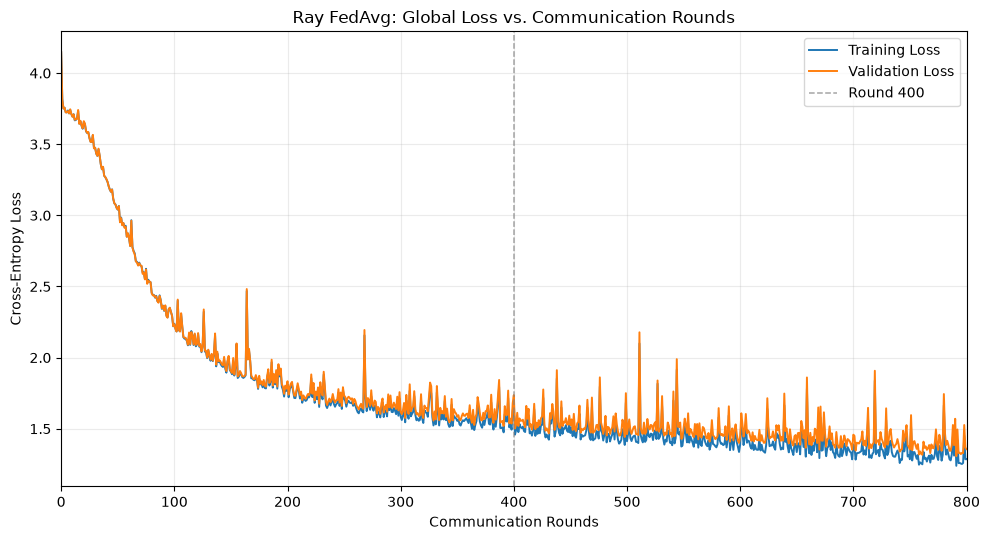

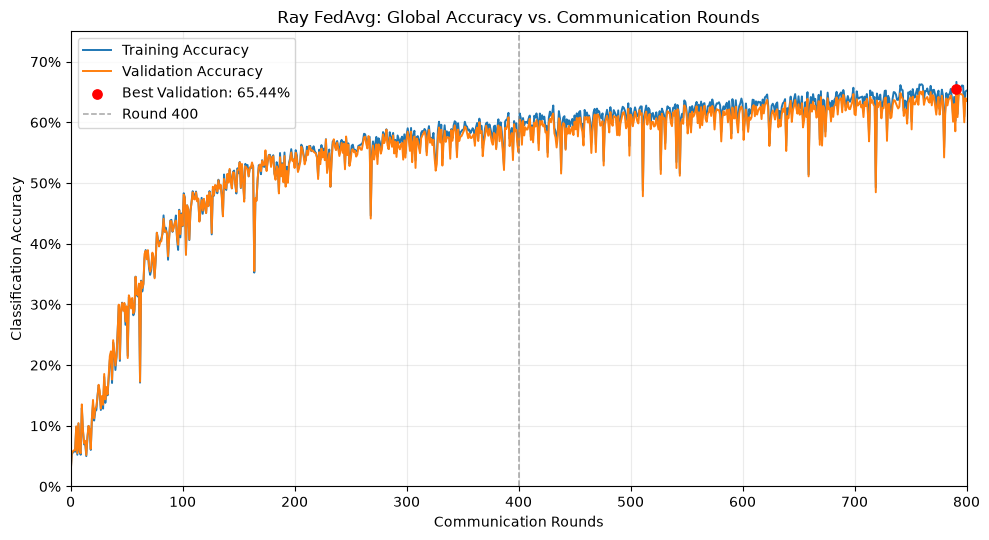


=== Figure Verification ===
Loss figure: Output\Part12_Ray_loss_vs_rounds.png
Accuracy figure: Output\Part12_Ray_accuracy_vs_rounds.png
Loss figure saved: PASSED
Accuracy figure saved: PASSED

Part 1.2 training visualization completed.


In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter
from pathlib import Path

# ==========================================================
# Part 1.2 - Ray FedAvg Training Curves
# C=4%, E=5, R=800
#
# No training or checkpoint loading
# ==========================================================

OUTPUT_DIR = Path("Output")
RUN_DIR = OUTPUT_DIR / "FedAvg_Ray_C04_E5_R800"

HISTORY_PATH = RUN_DIR / "training_history.csv"

assert HISTORY_PATH.exists()

history = pd.read_csv(HISTORY_PATH)

required_columns = [
    "round",
    "train_loss",
    "val_loss",
    "train_accuracy",
    "val_accuracy"
]

assert all(
    col in history.columns
    for col in required_columns
)

assert len(history) == 801
assert np.array_equal(
    history["round"].to_numpy(),
    np.arange(801)
)

assert history[required_columns].notna().all().all()

for col in ["train_accuracy", "val_accuracy"]:
    assert history[col].between(0, 1).all()

best_idx = history["val_accuracy"].idxmax()
best_row = history.loc[best_idx]

best_round = int(best_row["round"])
best_accuracy = float(best_row["val_accuracy"])

print("=== History Verification ===")
print("Records:", len(history))
print("Last round:", int(history["round"].iloc[-1]))
print("Best round:", best_round)
print("Best validation accuracy:", f"{best_accuracy:.4%}")

# ----------------------------------------------------------
# Figure 1: Training and validation loss
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    history["round"],
    history["train_loss"],
    label="Training Loss",
    linewidth=1.4
)

ax.plot(
    history["round"],
    history["val_loss"],
    label="Validation Loss",
    linewidth=1.4
)

ax.axvline(
    400,
    color="gray",
    linestyle="--",
    linewidth=1.1,
    alpha=0.7,
    label="Round 400"
)

ax.set_title(
    "Ray FedAvg: Global Loss vs. Communication Rounds"
)
ax.set_xlabel("Communication Rounds")
ax.set_ylabel("Cross-Entropy Loss")
ax.set_xlim(0, 800)
ax.grid(True, alpha=0.25)
ax.legend()

fig.tight_layout()

loss_path = OUTPUT_DIR / "Part12_Ray_loss_vs_rounds.png"

fig.savefig(loss_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ----------------------------------------------------------
# Figure 2: Training and validation accuracy
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    history["round"],
    history["train_accuracy"],
    label="Training Accuracy",
    linewidth=1.4
)

ax.plot(
    history["round"],
    history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=1.4
)

ax.scatter(
    [best_round],
    [best_accuracy],
    color="red",
    s=45,
    zorder=5,
    label=f"Best Validation: {best_accuracy:.2%}"
)

ax.axvline(
    400,
    color="gray",
    linestyle="--",
    linewidth=1.1,
    alpha=0.7,
    label="Round 400"
)

ax.set_title(
    "Ray FedAvg: Global Accuracy vs. Communication Rounds"
)
ax.set_xlabel("Communication Rounds")
ax.set_ylabel("Classification Accuracy")
ax.set_xlim(0, 800)
ax.set_ylim(0, 0.75)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1.0)
)

ax.grid(True, alpha=0.25)
ax.legend()

fig.tight_layout()

accuracy_path = (
    OUTPUT_DIR / "Part12_Ray_accuracy_vs_rounds.png"
)

fig.savefig(
    accuracy_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ----------------------------------------------------------
# Final verification
# ----------------------------------------------------------

assert loss_path.exists()
assert accuracy_path.exists()

print("\n=== Figure Verification ===")
print("Loss figure:", loss_path)
print("Accuracy figure:", accuracy_path)
print("Loss figure saved: PASSED")
print("Accuracy figure saved: PASSED")
print("\nPart 1.2 training visualization completed.")


In [37]:

import numpy as np
import torch
from pathlib import Path

# Part 1.2 - Final Test Preparation
# Inspect best checkpoint and held-out test dataset.
# No training and no evaluation yet.

run_dir = Path("Output/FedAvg_Ray_C04_E5_R800")
best_path = run_dir / "best_checkpoint.pt"

assert best_path.exists(), "Best checkpoint not found."

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

print("=== Best Checkpoint Verification ===")
print("Checkpoint keys:", list(checkpoint.keys()))
print("Best round:", checkpoint["round"])
print("Validation accuracy:", f"{checkpoint['val_accuracy']:.4%}")
print("Validation loss:", checkpoint["val_loss"])

assert checkpoint["round"] == 791
assert abs(checkpoint["val_accuracy"] - 0.654440) < 1e-5

model = FEMNISTMLP().cpu()
model.load_state_dict(checkpoint["model_state"])
model.eval()

print("Model loading: PASSED")

# Inspect dataset structure without evaluating it.
test_path = Path("test_data.npy")
assert test_path.exists(), "test_data.npy not found."

test_raw = np.load(test_path, allow_pickle=True)

print("\n=== Held-out Test Dataset ===")
print("Array shape:", test_raw.shape)
print("Array dtype:", test_raw.dtype)
print("Array dimensions:", test_raw.ndim)

if test_raw.ndim > 0 and len(test_raw) > 0:
    print("First element type:", type(test_raw[0]).__name__)
    if isinstance(test_raw[0], dict):
        print("First element keys:", list(test_raw[0].keys()))
elif test_raw.ndim == 0:
    item = test_raw.item()
    print("Contained object type:", type(item).__name__)
    if isinstance(item, dict):
        print("Contained keys:", list(item.keys()))

print("\nCheckpoint verification completed.")
print("Test predictions have NOT been computed.")


=== Best Checkpoint Verification ===
Checkpoint keys: ['round', 'model_state', 'val_accuracy', 'val_loss', 'config']
Best round: 791
Validation accuracy: 65.4440%
Validation loss: 1.307079801028058
Model loading: PASSED

=== Held-out Test Dataset ===
Array shape: (1,)
Array dtype: object
Array dimensions: 1
First element type: dict
First element keys: ['images', 'labels']

Checkpoint verification completed.
Test predictions have NOT been computed.


In [38]:

import json
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ==========================================================
# Part 1.2 - Final Held-out Test Evaluation
#
# Model: Best Ray FedAvg checkpoint
# C=4%, E=5, R=800
# Selected checkpoint: Round 791
#
# No training or parameter updates
# ==========================================================

RUN_DIR = Path("Output/FedAvg_Ray_C04_E5_R800")

BEST_PATH = RUN_DIR / "best_checkpoint.pt"
RESULTS_PATH = RUN_DIR / "final_test_results.json"

assert BEST_PATH.exists()
assert Path("test_data.npy").exists()

# ----------------------------------------------------------
# 1. Load the best validation-selected model
# ----------------------------------------------------------

checkpoint = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True
)

best_round = int(checkpoint["round"])
best_val_accuracy = float(checkpoint["val_accuracy"])
best_val_loss = float(checkpoint["val_loss"])

assert best_round == 791

test_model = FEMNISTMLP().cpu()
test_model.load_state_dict(checkpoint["model_state"])
test_model.eval()

print("=== Final Ray FedAvg Test Configuration ===")
print("Selected checkpoint round:", best_round)
print("Validation accuracy:", f"{best_val_accuracy:.4%}")
print("Validation loss:", f"{best_val_loss:.6f}")
print("Model device: CPU")

# ----------------------------------------------------------
# 2. Load held-out test data
# ----------------------------------------------------------

test_raw = np.load(
    "test_data.npy",
    allow_pickle=True
)

assert len(test_raw) == 1
assert isinstance(test_raw[0], dict)

test_images = np.asarray(
    test_raw[0]["images"],
    dtype=np.float32
)

test_labels = np.asarray(
    test_raw[0]["labels"],
    dtype=np.int64
)

n_test = len(test_labels)

assert n_test > 0
assert len(test_images) == n_test
assert test_images.size == n_test * 784
assert test_labels.min() >= 0
assert test_labels.max() < 62
assert np.isfinite(test_images).all()

# Preserve original image scaling; do not normalize twice.
test_images = test_images.reshape(n_test, 784)

print("\n=== Test Dataset Verification ===")
print("Test samples:", n_test)
print("Image tensor shape:", test_images.shape)
print("Label shape:", test_labels.shape)
print("Pixel range:",
      float(test_images.min()),
      float(test_images.max()))
print("Number of observed classes:",
      len(np.unique(test_labels)))

# ----------------------------------------------------------
# 3. Evaluate best model on held-out test set
# ----------------------------------------------------------

BATCH_SIZE = 128

total_loss = 0.0
total_correct = 0
total_samples = 0

with torch.inference_mode():

    for start in range(0, n_test, BATCH_SIZE):

        end = min(start + BATCH_SIZE, n_test)

        x = torch.from_numpy(
            test_images[start:end]
        )

        y = torch.from_numpy(
            test_labels[start:end]
        )

        logits = test_model(x)

        assert logits.shape == (len(y), 62)

        batch_loss = F.cross_entropy(
            logits,
            y,
            reduction="sum"
        )

        predictions = logits.argmax(dim=1)

        total_loss += float(batch_loss.item())

        total_correct += int(
            (predictions == y).sum().item()
        )

        total_samples += len(y)

assert total_samples == n_test

test_loss = total_loss / total_samples
test_accuracy = total_correct / total_samples

assert np.isfinite(test_loss)
assert 0 <= test_accuracy <= 1

# ----------------------------------------------------------
# 4. Print final results
# ----------------------------------------------------------

print("\n=== Final Held-out Test Results ===")
print("Checkpoint round:", best_round)
print("Test samples:", total_samples)
print("Correct predictions:", total_correct)
print("Incorrect predictions:",
      total_samples - total_correct)
print("Test accuracy:", f"{test_accuracy:.4%}")
print("Test loss:", f"{test_loss:.6f}")

print("\n=== Validation vs. Test ===")
print(
    "Best validation accuracy:",
    f"{best_val_accuracy:.4%}"
)
print(
    "Held-out test accuracy:",
    f"{test_accuracy:.4%}"
)
print(
    "Test - Validation accuracy gap:",
    f"{(test_accuracy - best_val_accuracy) * 100:+.4f} pp"
)

# ----------------------------------------------------------
# 5. Save final results
# ----------------------------------------------------------

results = {
    "experiment": "FedAvg_Ray_C04_E5_R800",
    "checkpoint_round": best_round,
    "clients_per_round": 4,
    "local_epochs": 5,
    "communication_rounds": 800,
    "best_validation_accuracy": best_val_accuracy,
    "best_validation_loss": best_val_loss,
    "test_samples": total_samples,
    "correct_predictions": total_correct,
    "incorrect_predictions": total_samples - total_correct,
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "test_minus_validation_accuracy_pp": (
        test_accuracy - best_val_accuracy
    ) * 100
}

with open(
    RESULTS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

assert RESULTS_PATH.exists()

print("\n=== Verification ===")
print("Best checkpoint loaded: PASSED")
print("Held-out test evaluation: PASSED")
print("No training performed: PASSED")
print("Results saved:", RESULTS_PATH)

print("\nPart 1.2 final test completed successfully.")


=== Final Ray FedAvg Test Configuration ===
Selected checkpoint round: 791
Validation accuracy: 65.4440%
Validation loss: 1.307080
Model device: CPU

=== Test Dataset Verification ===
Test samples: 3621
Image tensor shape: (3621, 784)
Label shape: (3621,)
Pixel range: 0.0 1.0
Number of observed classes: 62

=== Final Held-out Test Results ===
Checkpoint round: 791
Test samples: 3621
Correct predictions: 2416
Incorrect predictions: 1205
Test accuracy: 66.7219%
Test loss: 1.300251

=== Validation vs. Test ===
Best validation accuracy: 65.4440%
Held-out test accuracy: 66.7219%
Test - Validation accuracy gap: +1.2779 pp

=== Verification ===
Best checkpoint loaded: PASSED
Held-out test evaluation: PASSED
No training performed: PASSED
Results saved: Output\FedAvg_Ray_C04_E5_R800\final_test_results.json

Part 1.2 final test completed successfully.


In [39]:

import numpy as np
import torch
import ray
import time

# ==========================================================
# Part 1.2 - Edge Case Test 1
# Extreme Client Heterogeneity and Incomplete Mini-batches
#
# Four Ray Actors, E=5, batch size=32
# Compare Ray and Serial local updates
#
# No formal checkpoint modification
# No held-out test evaluation
# ==========================================================

assert ray.is_initialized()
assert "FEMNISTRayClientActor" in globals()

EDGE_EPOCHS = 5
EDGE_BATCH_SIZE = 32
EDGE_LR = 0.01
EDGE_ROUND_ID = 0

# ----------------------------------------------------------
# 1. Analyze all client training partitions
# ----------------------------------------------------------

client_stats = []

for cid in range(len(train_data)):

    idx = np.asarray(
        client_splits[cid]["train_idx"],
        dtype=np.int64
    )

    labels = np.asarray(
        train_data[cid]["labels"],
        dtype=np.int64
    )[idx]

    n = len(idx)

    client_stats.append({
        "cid": cid,
        "samples": n,
        "classes": len(np.unique(labels)),
        "remainder": n % EDGE_BATCH_SIZE
    })

print("=== Client Heterogeneity Statistics ===")

sample_counts = [s["samples"] for s in client_stats]
class_counts = [s["classes"] for s in client_stats]

incomplete = [
    s for s in client_stats
    if s["remainder"] != 0
]

single_sample_tail = [
    s for s in client_stats
    if s["remainder"] == 1
]

print("Total clients:", len(client_stats))
print("Min training samples:", min(sample_counts))
print("Max training samples:", max(sample_counts))
print("Min observed classes:", min(class_counts))
print("Max observed classes:", max(class_counts))
print("Clients with incomplete last batch:", len(incomplete))
print("Clients with one-sample last batch:",
      len(single_sample_tail))

# ----------------------------------------------------------
# 2. Choose four distinct challenging clients
# ----------------------------------------------------------

selected = []
case_names = []

def choose_case(name, candidates):

    for s in candidates:
        if s["cid"] not in selected:
            selected.append(s["cid"])
            case_names.append(name)
            return s

    raise RuntimeError(
        "Unable to find a distinct client for " + name
    )

# Lowest number of training samples
choose_case(
    "Minimum sample count",
    sorted(
        client_stats,
        key=lambda s: (s["samples"], s["cid"])
    )
)

# Highest number of training samples
choose_case(
    "Maximum sample count",
    sorted(
        client_stats,
        key=lambda s: (-s["samples"], s["cid"])
    )
)

# Fewest label classes
choose_case(
    "Minimum class coverage",
    sorted(
        client_stats,
        key=lambda s: (s["classes"], s["cid"])
    )
)

# Prefer a one-sample final batch
assert len(single_sample_tail) > 0, (
    "No one-sample final batch exists."
)

choose_case(
    "One-sample final mini-batch",
    sorted(
        single_sample_tail,
        key=lambda s: (s["samples"], s["cid"])
    )
)

assert len(selected) == 4
assert len(set(selected)) == 4

print("\n=== Selected Edge Case Clients ===")

for name, cid in zip(case_names, selected):

    s = client_stats[cid]

    print(
        f"{name:30s} | "
        f"Client {cid:3d} | "
        f"Samples {s['samples']:3d} | "
        f"Classes {s['classes']:2d}/62 | "
        f"Last batch {s['remainder'] or 32:2d}"
    )

# ----------------------------------------------------------
# 3. Establish common initial model
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()
actors = []

try:

    torch.manual_seed(42)

    initial_model = FEMNISTMLP().cpu()

    initial_state = {
        k: v.detach().cpu().clone()
        for k, v in initial_model.state_dict().items()
    }

    # ------------------------------------------------------
    # 4. Run four real Ray client updates
    # ------------------------------------------------------

    print("\n=== Parallel Edge Case Training ===")

    start_time = time.perf_counter()

    for cid in selected:

        idx = np.asarray(
            client_splits[cid]["train_idx"],
            dtype=np.int64
        )

        images = np.asarray(
            [
                train_data[cid]["images"][int(i)]
                for i in idx
            ],
            dtype=np.float32
        )

        labels = np.asarray(
            [
                train_data[cid]["labels"][int(i)]
                for i in idx
            ],
            dtype=np.int64
        )

        actors.append(
            FEMNISTRayClientActor.remote(
                cid, images, labels
            )
        )

    state_ref = ray.put(initial_state)

    futures = [
        actor.train.remote(
            state_ref,
            EDGE_EPOCHS,
            EDGE_LR,
            EDGE_BATCH_SIZE,
            EDGE_ROUND_ID
        )
        for actor in actors
    ]

    parallel_results = ray.get(
        futures, timeout=180
    )

    parallel_time = time.perf_counter() - start_time

    assert len(parallel_results) == 4
    assert len({
        result["pid"] for result in parallel_results
    }) == 4

    # ------------------------------------------------------
    # 5. Check optimizer steps and model updates
    # ------------------------------------------------------

    print("\n=== Edge Case Training Verification ===")

    ray_updates = {}
    all_parameter_changes = []

    for result in parallel_results:

        cid = int(result["client_id"])
        n = int(result["n_samples"])

        expected_steps = EDGE_EPOCHS * (
            (n + EDGE_BATCH_SIZE - 1) // EDGE_BATCH_SIZE
        )

        actual_steps = int(result["optimizer_steps"])

        assert actual_steps == expected_steps
        assert result["cpu_threads"] == 1
        assert result["gpu_ids"] == []

        max_change = max(
            float(
                (
                    result["model_state"][k]
                    - initial_state[k]
                ).abs().max()
            )
            for k in initial_state
        )

        assert max_change > 0
        assert np.isfinite(max_change)
        assert np.isfinite(result["mean_local_loss"])

        all_parameter_changes.append(max_change)

        ray_updates[cid] = (
            result["model_state"],
            n
        )

        print(
            f"Client {cid:3d} | "
            f"Steps {actual_steps:3d}/{expected_steps:3d} | "
            f"Loss {result['mean_local_loss']:.4f} | "
            f"Max Update {max_change:.8e}"
        )

    # ------------------------------------------------------
    # 6. Compare each Actor against Serial FedAvg
    # ------------------------------------------------------

    print("\n=== Serial vs. Ray Edge Case Comparison ===")

    serial_updates = {}
    local_differences = []

    for cid in selected:

        serial_state, serial_n, serial_loss = (
            train_one_client(
                client_id=cid,
                global_state=initial_state,
                local_epochs=EDGE_EPOCHS,
                learning_rate=EDGE_LR,
                batch_size=EDGE_BATCH_SIZE,
                round_id=EDGE_ROUND_ID
            )
        )

        ray_state, ray_n = ray_updates[cid]

        assert serial_n == ray_n

        diff = max(
            float(
                (
                    serial_state[k].double()
                    - ray_state[k].double()
                ).abs().max()
            )
            for k in initial_state
        )

        local_differences.append(diff)
        serial_updates[cid] = (serial_state, serial_n)

        print(
            f"Client {cid:3d} | "
            f"Max parameter difference: {diff:.10e}"
        )

    # ------------------------------------------------------
    # 7. Verify weighted global aggregation
    # ------------------------------------------------------

    serial_global = fedavg_aggregate([
        serial_updates[cid]
        for cid in selected
    ])

    ray_global = fedavg_aggregate([
        ray_updates[cid]
        for cid in selected
    ])

    global_difference = max(
        float(
            (
                serial_global[k].double()
                - ray_global[k].double()
            ).abs().max()
        )
        for k in initial_state
    )

    max_local_difference = max(local_differences)

    assert max_local_difference < 1e-5
    assert global_difference < 1e-5

    assert all(
        torch.isfinite(v).all().item()
        for v in ray_global.values()
    )

    print("\n=== Aggregation Verification ===")
    print(
        "Total participating samples:",
        sum(ray_updates[cid][1] for cid in selected)
    )
    print(
        "Maximum local parameter difference:",
        f"{max_local_difference:.10e}"
    )
    print(
        "Maximum global parameter difference:",
        f"{global_difference:.10e}"
    )
    print(
        "Parallel phase wall time:",
        f"{parallel_time:.3f}s"
    )

    # ------------------------------------------------------
    # 8. Final diagnostic summary
    # ------------------------------------------------------

    print("\n=== Edge Case Test 1 Summary ===")
    print("Extreme sample counts: PASSED")
    print("Missing local classes: PASSED")
    print("One-sample final mini-batch: PASSED")
    print("Correct SGD step counts: PASSED")
    print("Finite nonzero model updates: PASSED")
    print("Ray vs. Serial consistency: PASSED")
    print("Weighted FedAvg consistency: PASSED")

finally:

    for actor in actors:
        try:
            ray.kill(actor)
        except Exception as exc:
            print("Actor cleanup warning:", str(exc))

    torch.set_rng_state(saved_rng)

    print("\nEdge-case Actors cleanup requested.")
    print("Ray runtime active:", ray.is_initialized())


=== Client Heterogeneity Statistics ===
Total clients: 100
Min training samples: 94
Max training samples: 314
Min observed classes: 37
Max observed classes: 58
Clients with incomplete last batch: 95
Clients with one-sample last batch: 1

=== Selected Edge Case Clients ===
Minimum sample count           | Client  25 | Samples  94 | Classes 37/62 | Last batch 30
Maximum sample count           | Client  67 | Samples 314 | Classes 54/62 | Last batch 26
Minimum class coverage         | Client  36 | Samples 182 | Classes 37/62 | Last batch 22
One-sample final mini-batch    | Client  22 | Samples 257 | Classes 54/62 | Last batch  1

=== Parallel Edge Case Training ===

=== Edge Case Training Verification ===
Client  25 | Steps  15/ 15 | Loss 4.0068 | Max Update 1.62460506e-02
Client  67 | Steps  50/ 50 | Loss 3.8368 | Max Update 3.62634473e-02
Client  36 | Steps  30/ 30 | Loss 3.8972 | Max Update 1.93324387e-02
Client  22 | Steps  45/ 45 | Loss 3.9789 | Max Update 4.59240377e-02

=== Serial v

In [40]:

import time
import json
import numpy as np
import torch
import ray
from pathlib import Path

# ==========================================================
# Part 1.2 - Edge Case Test 2
# Actor Method Failure, Round Abort, and Recovery
#
# Phase A: 4 clients, one intentionally invalid LR
# Phase B: 4 fresh clients, all valid
#
# Does not modify formal model checkpoints.
# Does not use the held-out test dataset.
# ==========================================================

assert ray.is_initialized()
assert "FEMNISTRayClientActor" in globals()

EDGE2_CLIENTS = [43, 8, 64, 75]
EDGE2_FAILED_CLIENT = 8

EDGE2_EPOCHS = 1
EDGE2_LR = 0.01
EDGE2_BAD_LR = -0.01
EDGE2_BATCH_SIZE = 32
EDGE2_ROUND_ID = 0

output_dir = Path("Output/FedAvg_Ray_EdgeCases")
output_dir.mkdir(parents=True, exist_ok=True)

saved_rng = torch.get_rng_state()

# ----------------------------------------------------------
# 1. Use a separate model for this diagnostic
# ----------------------------------------------------------

torch.manual_seed(42)

edge2_model = FEMNISTMLP().cpu()

edge2_initial_state = {
    k: v.detach().cpu().clone()
    for k, v in edge2_model.state_dict().items()
}

def edge2_max_difference(state_a, state_b):
    return max(
        float(
            (
                state_a[k].double()
                - state_b[k].double()
            ).abs().max()
        )
        for k in state_a
    )

def edge2_run_round(inject_failure=False):

    actors = []
    results = {}
    failures = {}
    elapsed = None

    try:
        start = time.perf_counter()

        # Create Actors only for selected clients
        for cid in EDGE2_CLIENTS:

            indices = np.asarray(
                client_splits[cid]["train_idx"],
                dtype=np.int64
            )

            images = np.asarray(
                [
                    train_data[cid]["images"][int(i)]
                    for i in indices
                ],
                dtype=np.float32
            )

            labels = np.asarray(
                [
                    train_data[cid]["labels"][int(i)]
                    for i in indices
                ],
                dtype=np.int64
            )

            actors.append(
                FEMNISTRayClientActor.remote(
                    cid, images, labels
                )
            )

        assert len(actors) == 4

        state_ref = ray.put(edge2_initial_state)

        # Submit all four tasks before retrieving results
        futures = []

        for cid, actor in zip(EDGE2_CLIENTS, actors):

            lr = (
                EDGE2_BAD_LR
                if inject_failure and cid == EDGE2_FAILED_CLIENT
                else EDGE2_LR
            )

            futures.append(
                actor.train.remote(
                    state_ref,
                    EDGE2_EPOCHS,
                    lr,
                    EDGE2_BATCH_SIZE,
                    EDGE2_ROUND_ID
                )
            )

        # Collect each outcome, including expected exceptions
        for cid, future in zip(EDGE2_CLIENTS, futures):

            try:
                result = ray.get(future, timeout=120)
                results[cid] = result

            except ray.exceptions.RayTaskError as exc:
                failures[cid] = {
                    "error_type": type(exc).__name__,
                    "message": str(exc).splitlines()[-1]
                }

        elapsed = time.perf_counter() - start

    finally:
        # Cleanup applies even when a task fails
        for actor in actors:
            try:
                ray.kill(actor)
            except Exception as exc:
                print("Cleanup warning:", str(exc))

        actors.clear()

    return results, failures, elapsed

try:

    # ------------------------------------------------------
    # 2. Phase A: Inject a failure into one Actor
    # ------------------------------------------------------

    print("=== Phase A: Injected Actor Method Failure ===")
    print("Selected clients:", EDGE2_CLIENTS)
    print("Intentionally failing client:", EDGE2_FAILED_CLIENT)

    failed_results, failed_errors, failed_wall = (
        edge2_run_round(inject_failure=True)
    )

    print("\n=== Phase A Results ===")
    print("Successful clients:", sorted(failed_results))
    print("Failed clients:", sorted(failed_errors))

    for cid, error in failed_errors.items():
        print(
            f"Client {cid} | "
            f"Exception: {error['error_type']} | "
            f"Reason: {error['message']}"
        )

    assert len(failed_results) == 3
    assert list(failed_errors) == [EDGE2_FAILED_CLIENT]

    assert all(
        np.isfinite(r["mean_local_loss"])
        for r in failed_results.values()
    )

    # A failed round must not aggregate partial updates.
    round_accepted = len(failed_errors) == 0

    assert not round_accepted

    unchanged_difference = edge2_max_difference(
        edge2_model.state_dict(),
        edge2_initial_state
    )

    assert unchanged_difference == 0.0
    assert ray.is_initialized()

    print("\nFailure propagated to Driver: PASSED")
    print("Incomplete round rejected: PASSED")
    print("Partial aggregation prevented: PASSED")
    print("Global model unchanged: PASSED")
    print("Ray runtime survived: PASSED")
    print("Failure phase wall time:",
          f"{failed_wall:.3f}s")

    # ------------------------------------------------------
    # 3. Phase B: Recover using four fresh Actors
    # ------------------------------------------------------

    print("\n=== Phase B: Recovery with Four Fresh Actors ===")

    recovered_results, recovery_errors, recovery_wall = (
        edge2_run_round(inject_failure=False)
    )

    assert len(recovery_errors) == 0
    assert len(recovered_results) == 4

    recovery_pids = [
        int(r["pid"])
        for r in recovered_results.values()
    ]

    assert len(set(recovery_pids)) == 4

    recovery_updates = []

    for cid in EDGE2_CLIENTS:

        result = recovered_results[cid]

        n_samples = int(result["n_samples"])

        expected_steps = (
            (n_samples + EDGE2_BATCH_SIZE - 1)
            // EDGE2_BATCH_SIZE
        ) * EDGE2_EPOCHS

        assert result["optimizer_steps"] == expected_steps
        assert result["cpu_threads"] == 1
        assert result["gpu_ids"] == []
        assert np.isfinite(result["mean_local_loss"])

        recovery_updates.append(
            (result["model_state"], n_samples)
        )

        print(
            f"Client {cid:3d} | "
            f"PID {result['pid']:6d} | "
            f"Samples {n_samples:3d} | "
            f"Steps {result['optimizer_steps']:2d} | "
            f"Loss {result['mean_local_loss']:.4f}"
        )

    # Aggregate only the fully successful recovery round.
    recovered_state = fedavg_aggregate(
        recovery_updates
    )

    parameter_change = edge2_max_difference(
        recovered_state,
        edge2_initial_state
    )

    assert parameter_change > 0
    assert np.isfinite(parameter_change)

    assert all(
        torch.isfinite(v).all().item()
        for v in recovered_state.values()
    )

    edge2_model.load_state_dict(recovered_state)

    print("\n=== Recovery Verification ===")
    print("All four clients completed: PASSED")
    print("Four independent Actor processes: PASSED")
    print("Full FedAvg aggregation: PASSED")
    print(
        "Maximum global parameter change:",
        f"{parameter_change:.10e}"
    )
    print(
        "Recovery phase wall time:",
        f"{recovery_wall:.3f}s"
    )
    print("Ray runtime active:", ray.is_initialized())

    # ------------------------------------------------------
    # 4. Save diagnostic evidence
    # ------------------------------------------------------

    edge2_summary = {
        "test": "Actor Method Failure and Recovery",
        "selected_clients": EDGE2_CLIENTS,
        "intentionally_failed_client": EDGE2_FAILED_CLIENT,
        "failure_phase_successful_clients": sorted(
            failed_results
        ),
        "failure_phase_failed_clients": sorted(
            failed_errors
        ),
        "failed_round_rejected": True,
        "global_model_unchanged_after_failure": True,
        "recovery_successful_clients": len(
            recovered_results
        ),
        "recovery_actor_pids": recovery_pids,
        "recovery_max_parameter_change": parameter_change,
        "failure_phase_wall_seconds": failed_wall,
        "recovery_phase_wall_seconds": recovery_wall,
        "passed": True
    }

    result_path = (
        output_dir / "actor_failure_recovery.json"
    )

    with open(result_path, "w", encoding="utf-8") as f:
        json.dump(edge2_summary, f, indent=4)

    print("\n=== Edge Case Test 2 Summary ===")
    print("Expected Actor method exception: PASSED")
    print("Round abort without partial update: PASSED")
    print("Actor cleanup requested: PASSED")
    print("Recovery using fresh Actors: PASSED")
    print("Ray runtime remains active: PASSED")
    print("Results saved:", result_path)

finally:
    torch.set_rng_state(saved_rng)

print("\nEdge Case Test 2 completed successfully.")


=== Phase A: Injected Actor Method Failure ===
Selected clients: [43, 8, 64, 75]
Intentionally failing client: 8

=== Phase A Results ===
Successful clients: [43, 64, 75]
Failed clients: [8]
Client 8 | Exception: RayTaskError(AssertionError) | Reason: AssertionError

Failure propagated to Driver: PASSED
Incomplete round rejected: PASSED
Partial aggregation prevented: PASSED
Global model unchanged: PASSED
Ray runtime survived: PASSED
Failure phase wall time: 4.231s

=== Phase B: Recovery with Four Fresh Actors ===
Client  43 | PID  11516 | Samples 244 | Steps  8 | Loss 4.1010
Client   8 | PID  24164 | Samples 305 | Steps 10 | Loss 4.0728
Client  64 | PID  23600 | Samples 271 | Steps  9 | Loss 4.0706
Client  75 | PID  14588 | Samples 220 | Steps  7 | Loss 4.1155

=== Recovery Verification ===
All four clients completed: PASSED
Four independent Actor processes: PASSED
Full FedAvg aggregation: PASSED
Maximum global parameter change: 7.3060095310e-03
Recovery phase wall time: 4.385s
Ray run

In [41]:

import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import ray

# ==========================================================
# Part 1.2 - Edge Case Test 3
# Client Sampling Boundaries and Repeated Participation
#
# Analyze all 800 completed communication rounds
# No Actor creation, no retraining, no test evaluation
# ==========================================================

RUN_DIR = Path("Output/FedAvg_Ray_C04_E5_R800")
EDGE_DIR = Path("Output/FedAvg_Ray_EdgeCases")

EDGE_DIR.mkdir(parents=True, exist_ok=True)

history_path = RUN_DIR / "training_history.csv"

assert history_path.exists()

history = pd.read_csv(history_path)

TOTAL_CLIENTS = 100
EXPECTED_ROUNDS = 800
CLIENTS_PER_ROUND = 4
SEED = 42

assert len(history) == EXPECTED_ROUNDS + 1

assert np.array_equal(
    history["round"].to_numpy(),
    np.arange(EXPECTED_ROUNDS + 1)
)

print("=== Client Sampling Edge Case Test ===")
print("Recorded communication rounds:", EXPECTED_ROUNDS)
print("Total available clients:", TOTAL_CLIENTS)
print("Clients selected per round:", CLIENTS_PER_ROUND)

# ----------------------------------------------------------
# 1. Verify recorded selections for all 800 rounds
# ----------------------------------------------------------

selection_counter = Counter()
previous_clients = None

rounds_with_overlap = 0
total_consecutive_overlap = 0
first_overlap = None

total_participations = 0
sample_count_mismatches = []

for round_number in range(1, EXPECTED_ROUNDS + 1):

    record = history.iloc[round_number]

    # Recover actual client IDs saved during training
    recorded_clients = [
        int(x)
        for x in str(record["selected_clients"]).split(",")
    ]

    # Reproduce deterministic selection
    expected_clients = [
        int(x)
        for x in select_clients(
            round_id=round_number - 1,
            client_fraction=0.04,
            seed=SEED
        )
    ]

    # Exactly four different clients per round
    assert len(recorded_clients) == CLIENTS_PER_ROUND
    assert len(set(recorded_clients)) == CLIENTS_PER_ROUND

    # Valid client IDs
    assert all(
        0 <= cid < TOTAL_CLIENTS
        for cid in recorded_clients
    )

    # Exact agreement with seeded sampling
    assert recorded_clients == expected_clients

    # Verify participating sample count
    expected_samples = sum(
        len(client_splits[cid]["train_idx"])
        for cid in recorded_clients
    )

    recorded_samples = int(
        record["participating_samples"]
    )

    if expected_samples != recorded_samples:
        sample_count_mismatches.append(round_number)

    selection_counter.update(recorded_clients)

    total_participations += len(recorded_clients)

    # Repeated selection across consecutive rounds is valid
    if previous_clients is not None:

        overlap = set(recorded_clients).intersection(
            previous_clients
        )

        if overlap:

            rounds_with_overlap += 1
            total_consecutive_overlap += len(overlap)

            if first_overlap is None:
                first_overlap = {
                    "round": round_number,
                    "repeated_clients": sorted(overlap),
                    "previous_round_clients": sorted(
                        previous_clients
                    ),
                    "current_round_clients": recorded_clients
                }

    previous_clients = recorded_clients

# ----------------------------------------------------------
# 2. Analyze overall client participation frequencies
# ----------------------------------------------------------

counts = np.array([
    selection_counter.get(cid, 0)
    for cid in range(TOTAL_CLIENTS)
])

unique_clients = int(np.sum(counts > 0))
never_selected = int(np.sum(counts == 0))

assert total_participations == (
    EXPECTED_ROUNDS * CLIENTS_PER_ROUND
)

assert counts.sum() == total_participations

assert len(sample_count_mismatches) == 0

print("\n=== Sampling Verification ===")
print("Total client participations:", total_participations)
print("Unique participating clients:", unique_clients)
print("Clients never selected:", never_selected)
print("Minimum client participation:", int(counts.min()))
print("Maximum client participation:", int(counts.max()))
print("Mean client participation:", f"{counts.mean():.2f}")
print("Participation std:", f"{counts.std():.4f}")

print("\n=== Consecutive-Round Overlap ===")
print(
    "Rounds sharing clients with previous round:",
    rounds_with_overlap
)
print(
    "Total consecutive repeated participations:",
    total_consecutive_overlap
)

if first_overlap is not None:
    print("First overlapping round:", first_overlap["round"])
    print(
        "Repeated client IDs:",
        first_overlap["repeated_clients"]
    )
    print(
        "Previous selection:",
        first_overlap["previous_round_clients"]
    )
    print(
        "Current selection:",
        first_overlap["current_round_clients"]
    )

# ----------------------------------------------------------
# 3. Find most and least frequently selected clients
# ----------------------------------------------------------

frequency_df = pd.DataFrame({
    "client_id": np.arange(TOTAL_CLIENTS),
    "participation_count": counts
})

print("\n=== Most Frequently Selected Clients ===")

print(
    frequency_df.sort_values(
        ["participation_count", "client_id"],
        ascending=[False, True]
    ).head(5).to_string(index=False)
)

print("\n=== Least Frequently Selected Clients ===")

print(
    frequency_df.sort_values(
        ["participation_count", "client_id"],
        ascending=[True, True]
    ).head(5).to_string(index=False)
)

# ----------------------------------------------------------
# 4. Inspect Ray resource availability
# ----------------------------------------------------------

print("\n=== Ray Resource Status ===")

assert ray.is_initialized()

available_resources = ray.available_resources()
configured_resources = ray.cluster_resources()

print(
    "Configured Ray CPUs:",
    configured_resources.get("CPU", 0)
)

print(
    "Currently available Ray CPUs:",
    available_resources.get("CPU", 0)
)

print(
    "Configured Ray GPUs:",
    configured_resources.get("GPU", 0)
)

# ----------------------------------------------------------
# 5. Save reproducible diagnostic evidence
# ----------------------------------------------------------

summary = {
    "test": "Client Sampling Boundaries",
    "communication_rounds": EXPECTED_ROUNDS,
    "clients_per_round": CLIENTS_PER_ROUND,
    "total_client_participations": total_participations,
    "unique_participating_clients": unique_clients,
    "never_selected_clients": never_selected,
    "minimum_participation": int(counts.min()),
    "maximum_participation": int(counts.max()),
    "mean_participation": float(counts.mean()),
    "std_participation": float(counts.std()),
    "rounds_with_consecutive_overlap": rounds_with_overlap,
    "total_consecutive_overlap": total_consecutive_overlap,
    "first_consecutive_overlap": first_overlap,
    "sample_count_mismatches": sample_count_mismatches,
    "deterministic_sampling_verified": True,
    "unique_clients_within_every_round": True,
    "passed": True
}

summary_path = (
    EDGE_DIR / "client_sampling_edge_cases.json"
)

frequency_path = (
    EDGE_DIR / "client_participation_frequency.csv"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

frequency_df.to_csv(frequency_path, index=False)

print("\n=== Edge Case Test 3 Summary ===")
print("Exactly four clients per round: PASSED")
print("No within-round duplicates: PASSED")
print("Client ID boundaries: PASSED")
print("Deterministic sampling: PASSED")
print("Participating sample counts: PASSED")
print("Cross-round participation analyzed: PASSED")
print("Ray runtime active:", ray.is_initialized())

print("\nResults saved:")
print(summary_path)
print(frequency_path)

print("\nEdge Case Test 3 completed successfully.")


=== Client Sampling Edge Case Test ===
Recorded communication rounds: 800
Total available clients: 100
Clients selected per round: 4

=== Sampling Verification ===
Total client participations: 3200
Unique participating clients: 100
Clients never selected: 0
Minimum client participation: 17
Maximum client participation: 44
Mean client participation: 32.00
Participation std: 5.3066

=== Consecutive-Round Overlap ===
Rounds sharing clients with previous round: 117
Total consecutive repeated participations: 124
First overlapping round: 8
Repeated client IDs: [59]
Previous selection: [12, 37, 49, 59]
Current selection: [59, 84, 35, 4]

=== Most Frequently Selected Clients ===
 client_id  participation_count
         1                   44
        56                   44
         4                   42
        63                   42
        90                   42

=== Least Frequently Selected Clients ===
 client_id  participation_count
        28                   17
        88           

In [42]:

import json
import numpy as np
import torch
from pathlib import Path
from numbers import Integral

# ==========================================================
# Part 1.2 - Edge Case Test 4
# Abnormal Client Updates and Weighted Aggregation
#
# Reuse real Ray updates from Edge Case Test 1.
# No Actor creation or new training.
# No formal checkpoint modification.
# ==========================================================

assert "ray_updates" in globals(), (
    "Run Edge Case Test 1 before this diagnostic."
)

assert "initial_state" in globals(), (
    "Initial reference model is missing."
)

CLIENT_IDS = [25, 67, 36, 22]
EXPECTED_CLIENTS = 4

updates = [
    ray_updates[cid]
    for cid in CLIENT_IDS
]

reference_state = initial_state

# ----------------------------------------------------------
# 1. Define a server-side input validation diagnostic
# ----------------------------------------------------------

def validate_client_updates(updates, reference, expected=4):

    if len(updates) != expected:
        raise ValueError("Incorrect number of client updates")

    expected_keys = set(reference.keys())

    for state, n_samples in updates:

        if (
            isinstance(n_samples, (bool, np.bool_))
            or not isinstance(n_samples, Integral)
            or n_samples <= 0
        ):
            raise ValueError("Invalid client sample count")

        if set(state.keys()) != expected_keys:
            raise ValueError("Model parameter keys mismatch")

        for key in reference:

            value = state[key]
            expected_tensor = reference[key]

            if not isinstance(value, torch.Tensor):
                raise ValueError("Parameter is not a tensor")

            if value.shape != expected_tensor.shape:
                raise ValueError("Model parameter shape mismatch")

            if value.dtype != expected_tensor.dtype:
                raise ValueError("Model parameter dtype mismatch")

            if not torch.isfinite(value).all().item():
                raise ValueError("Non-finite model parameter")

    return True

# ----------------------------------------------------------
# 2. Verify real Ray client updates
# ----------------------------------------------------------

print("=== Real Client Update Verification ===")

assert validate_client_updates(
    updates, reference_state, EXPECTED_CLIENTS
)

sample_counts = [
    int(n)
    for _, n in updates
]

total_samples = sum(sample_counts)

assert total_samples == 847

weights = [
    n / total_samples
    for n in sample_counts
]

for cid, n, weight in zip(
    CLIENT_IDS, sample_counts, weights
):
    print(
        f"Client {cid:3d} | "
        f"Samples: {n:3d} | "
        f"Aggregation weight: {weight:.6f}"
    )

print("Total participating samples:", total_samples)
print("Sum of aggregation weights:", sum(weights))

assert abs(sum(weights) - 1.0) < 1e-12

# ----------------------------------------------------------
# 3. Compare FedAvg with independent float64 reference
# ----------------------------------------------------------

print("\n=== Weighted Aggregation Verification ===")

actual_aggregate = fedavg_aggregate(updates)

manual_aggregate = {}

for key in reference_state:

    weighted_sum = torch.zeros_like(
        reference_state[key],
        dtype=torch.float64
    )

    for (state, n_samples) in updates:
        weighted_sum += (
            state[key].double()
            * (n_samples / total_samples)
        )

    manual_aggregate[key] = weighted_sum

max_weighted_difference = max(
    float(
        (
            actual_aggregate[key].double()
            - manual_aggregate[key]
        ).abs().max()
    )
    for key in reference_state
)

assert max_weighted_difference < 1e-6

# Compare against incorrect uniform averaging
max_uniform_difference = 0.0

for key in reference_state:

    uniform_average = torch.stack(
        [
            state[key].double()
            for state, _ in updates
        ]
    ).mean(dim=0)

    difference = float(
        (
            actual_aggregate[key].double()
            - uniform_average
        ).abs().max()
    )

    max_uniform_difference = max(
        max_uniform_difference,
        difference
    )

print(
    "Max difference vs float64 weighted reference:",
    f"{max_weighted_difference:.10e}"
)

print(
    "Max difference vs incorrect uniform average:",
    f"{max_uniform_difference:.10e}"
)

print("Weighted aggregation correctness: PASSED")

# ----------------------------------------------------------
# 4. Construct malformed updates without mutating originals
# ----------------------------------------------------------

def replace_update(
    original_updates, index, state=None, n_samples=None
):
    result = list(original_updates)

    old_state, old_n = result[index]

    result[index] = (
        old_state if state is None else state,
        old_n if n_samples is None else n_samples
    )

    return result

parameter_key = next(iter(reference_state))

def corrupt_parameter(original_state, corruption):

    state = dict(original_state)

    tensor = original_state[parameter_key].clone()

    if corruption == "nan":
        tensor.reshape(-1)[0] = float("nan")

    elif corruption == "inf":
        tensor.reshape(-1)[0] = float("inf")

    elif corruption == "wrong_shape":
        tensor = tensor.reshape(-1)[:1].clone()

    state[parameter_key] = tensor

    return state

# All cases are isolated diagnostic inputs.
bad_cases = {
    "Missing fourth client": updates[:3],

    "Zero training samples": replace_update(
        updates, 0, n_samples=0
    ),

    "Negative training samples": replace_update(
        updates, 0, n_samples=-1
    ),

    "NaN parameter": replace_update(
        updates,
        0,
        state=corrupt_parameter(updates[0][0], "nan")
    ),

    "Infinite parameter": replace_update(
        updates,
        0,
        state=corrupt_parameter(updates[0][0], "inf")
    ),

    "Wrong parameter shape": replace_update(
        updates,
        0,
        state=corrupt_parameter(
            updates[0][0], "wrong_shape"
        )
    ),

    "Missing model parameter": replace_update(
        updates,
        0,
        state={
            k: v
            for k, v in updates[0][0].items()
            if k != parameter_key
        }
    )
}

# ----------------------------------------------------------
# 5. Test validation and rejection
# ----------------------------------------------------------

print("\n=== Invalid Update Rejection ===")

rejection_results = {}

for case_name, bad_updates in bad_cases.items():

    try:

        validate_client_updates(
            bad_updates,
            reference_state,
            EXPECTED_CLIENTS
        )

    except ValueError as exc:

        rejection_results[case_name] = True

        print(
            f"{case_name:28s} | "
            f"REJECTED | {str(exc)}"
        )

    else:

        rejection_results[case_name] = False

        print(
            f"{case_name:28s} | "
            "NOT REJECTED"
        )

assert all(rejection_results.values())

# ----------------------------------------------------------
# 6. Test sensitivity to a large but finite update
# ----------------------------------------------------------

print("\n=== Large Finite Update Sensitivity ===")

# Pick one parameter; add a deliberately large value.
# This models an abnormal but finite client update.
outlier_state = dict(updates[0][0])

outlier_tensor = outlier_state[parameter_key].clone()

outlier_tensor.reshape(-1)[0] += 100.0

outlier_state[parameter_key] = outlier_tensor

outlier_updates = replace_update(
    updates,
    0,
    state=outlier_state
)

# Basic structural and finite checks will accept this.
assert validate_client_updates(
    outlier_updates,
    reference_state,
    EXPECTED_CLIENTS
)

outlier_aggregate = fedavg_aggregate(
    outlier_updates
)

aggregate_shift = float(
    (
        outlier_aggregate[parameter_key].double()
        - actual_aggregate[parameter_key].double()
    ).abs().max()
)

expected_shift = (
    100.0 * weights[0]
)

assert abs(aggregate_shift - expected_shift) < 1e-4

print("Injected parameter perturbation: +100.0")
print("Affected client:", CLIENT_IDS[0])
print("Client aggregation weight:", f"{weights[0]:.6f}")
print(
    "Observed global parameter shift:",
    f"{aggregate_shift:.6f}"
)
print(
    "Expected weighted shift:",
    f"{expected_shift:.6f}"
)

print(
    "Finite outlier passes basic validation:",
    "YES"
)

print(
    "Interpretation: Basic finite-value checks do not "
    "protect FedAvg against large but finite updates."
)

# ----------------------------------------------------------
# 7. Save diagnostic results
# ----------------------------------------------------------

output_dir = Path(
    "Output/FedAvg_Ray_EdgeCases"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

summary = {
    "test": "Abnormal Client Updates",
    "selected_clients": CLIENT_IDS,
    "sample_counts": sample_counts,
    "total_samples": total_samples,
    "aggregation_weights": weights,
    "weighted_reference_max_difference":
        max_weighted_difference,
    "uniform_average_max_difference":
        max_uniform_difference,
    "invalid_update_rejections":
        rejection_results,
    "finite_outlier_parameter_perturbation": 100.0,
    "finite_outlier_global_shift": aggregate_shift,
    "finite_outlier_expected_shift": expected_shift,
    "passed": True
}

result_path = (
    output_dir
    / "abnormal_client_updates.json"
)

with open(
    result_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=4)

print("\n=== Edge Case Test 4 Summary ===")
print("Real client updates valid: PASSED")
print("Sample-size weights: PASSED")
print("Independent weighted aggregation check: PASSED")
print("Malformed input rejection: PASSED")
print("Large finite outlier sensitivity: OBSERVED")
print("Formal model checkpoints: UNCHANGED")
print("Results saved:", result_path)

print("\nEdge Case Test 4 completed successfully.")


=== Real Client Update Verification ===
Client  25 | Samples:  94 | Aggregation weight: 0.110980
Client  67 | Samples: 314 | Aggregation weight: 0.370720
Client  36 | Samples: 182 | Aggregation weight: 0.214876
Client  22 | Samples: 257 | Aggregation weight: 0.303424
Total participating samples: 847
Sum of aggregation weights: 1.0

=== Weighted Aggregation Verification ===
Max difference vs float64 weighted reference: 9.3682034630e-09
Max difference vs incorrect uniform average: 5.3674732335e-03
Weighted aggregation correctness: PASSED

=== Invalid Update Rejection ===
Missing fourth client        | REJECTED | Incorrect number of client updates
Zero training samples        | REJECTED | Invalid client sample count
Negative training samples    | REJECTED | Invalid client sample count
NaN parameter                | REJECTED | Non-finite model parameter
Infinite parameter           | REJECTED | Non-finite model parameter
Wrong parameter shape        | REJECTED | Model parameter shape misma

In [43]:

import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# ==========================================================
# Part 1.2 - Correctness Test 1
# Multi-Round Serial vs. Ray FedAvg Trajectory Equivalence
#
# Reproduce the first 10 Ray rounds using Serial FedAvg.
# Compare training/validation loss and accuracy each round.
#
# No Ray Actors created.
# No checkpoint loaded or modified.
# No held-out test evaluation.
# ==========================================================

REFERENCE_PATH = Path(
    "Output/FedAvg_Ray_C04_E5_R800/training_history.csv"
)

OUTPUT_DIR = Path("Output/FedAvg_Ray_Correctness")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ROUNDS = 10
LOCAL_EPOCHS = 5
LEARNING_RATE = 0.01
BATCH_SIZE = 32
SEED = 42

assert REFERENCE_PATH.exists(), (
    "Formal Ray training history not found."
)

assert "train_one_client" in globals()
assert "fedavg_aggregate" in globals()
assert "evaluate_global_model" in globals()

# ----------------------------------------------------------
# 1. Read the actual Ray training trajectory
# ----------------------------------------------------------

ray_history = pd.read_csv(REFERENCE_PATH)

reference = ray_history[
    ray_history["round"].between(0, ROUNDS)
].copy()

reference = reference.sort_values("round")

assert len(reference) == ROUNDS + 1

assert np.array_equal(
    reference["round"].to_numpy(),
    np.arange(ROUNDS + 1)
)

print("=== Multi-Round Correctness Configuration ===")
print("Comparison rounds:", ROUNDS)
print("Clients per round:", 4)
print("Local epochs:", LOCAL_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Reference:", REFERENCE_PATH)

# ----------------------------------------------------------
# 2. Initialize an independent Serial FedAvg model
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()

try:

    torch.manual_seed(SEED)

    serial_model = FEMNISTMLP().cpu()
    serial_model.eval()

    serial_records = []

    print("\n=== Reproducing Serial FedAvg Trajectory ===")

    start_time = time.perf_counter()

    for round_number in range(ROUNDS + 1):

        # --------------------------------------------------
        # Local training and aggregation for rounds 1..10
        # --------------------------------------------------

        if round_number > 0:

            round_id = round_number - 1

            selected = [
                int(cid)
                for cid in select_clients(
                    round_id=round_id,
                    client_fraction=0.04,
                    seed=SEED
                )
            ]

            assert len(selected) == 4
            assert len(set(selected)) == 4

            global_state = {
                k: v.detach().cpu().clone()
                for k, v in serial_model.state_dict().items()
            }

            updates = []

            for cid in selected:

                state, n_samples, local_loss = (
                    train_one_client(
                        client_id=cid,
                        global_state=global_state,
                        local_epochs=LOCAL_EPOCHS,
                        learning_rate=LEARNING_RATE,
                        batch_size=BATCH_SIZE,
                        round_id=round_id
                    )
                )

                assert np.isfinite(local_loss)

                updates.append(
                    (state, n_samples)
                )

            aggregated_state = fedavg_aggregate(
                updates
            )

            serial_model.load_state_dict(
                aggregated_state
            )

        else:
            selected = []

        # --------------------------------------------------
        # Evaluate the full global model
        # --------------------------------------------------

        train_metrics = evaluate_global_model(
            serial_model,
            split="train",
            batch_size=128
        )

        val_metrics = evaluate_global_model(
            serial_model,
            split="val",
            batch_size=128
        )

        assert train_metrics["samples"] == 25418
        assert val_metrics["samples"] == 6407

        serial_records.append({
            "round": round_number,
            "train_loss": float(train_metrics["loss"]),
            "val_loss": float(val_metrics["loss"]),
            "train_accuracy": float(train_metrics["accuracy"]),
            "val_accuracy": float(val_metrics["accuracy"])
        })

        print(
            f"Round {round_number:2d} | "
            f"Train Loss: {train_metrics['loss']:.6f} | "
            f"Val Loss: {val_metrics['loss']:.6f} | "
            f"Train Acc: {train_metrics['accuracy']:.4%} | "
            f"Val Acc: {val_metrics['accuracy']:.4%}"
        )

    serial_elapsed = (
        time.perf_counter() - start_time
    )

    # ------------------------------------------------------
    # 3. Compare all 11 trajectory records
    # ------------------------------------------------------

    print("\n=== Serial vs. Ray Trajectory Comparison ===")

    serial_df = pd.DataFrame(serial_records)

    comparison = serial_df.merge(
        reference[
            [
                "round",
                "train_loss",
                "val_loss",
                "train_accuracy",
                "val_accuracy"
            ]
        ],
        on="round",
        suffixes=("_serial", "_ray"),
        validate="one_to_one"
    )

    metrics = [
        "train_loss",
        "val_loss",
        "train_accuracy",
        "val_accuracy"
    ]

    for metric in metrics:

        comparison[f"{metric}_abs_diff"] = (
            comparison[f"{metric}_serial"]
            - comparison[f"{metric}_ray"]
        ).abs()

    # Verify the actual recorded client selections.
    for round_number in range(1, ROUNDS + 1):

        row = ray_history.iloc[round_number]

        recorded_clients = [
            int(cid)
            for cid in str(row["selected_clients"]).split(",")
        ]

        expected_clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_number - 1,
                client_fraction=0.04,
                seed=SEED
            )
        ]

        assert recorded_clients == expected_clients

    # ------------------------------------------------------
    # 4. Quantitative consistency criteria
    # ------------------------------------------------------

    # Tolerances accommodate small floating-point
    # differences between CPU execution paths.
    LOSS_TOLERANCE = 1e-4
    ACCURACY_TOLERANCE = 1e-3

    max_differences = {}

    for metric in metrics:

        max_diff = float(
            comparison[f"{metric}_abs_diff"].max()
        )

        max_differences[metric] = max_diff

        print(
            f"Maximum {metric:15s} difference: "
            f"{max_diff:.10e}"
        )

    loss_pass = (
        max_differences["train_loss"] < LOSS_TOLERANCE
        and max_differences["val_loss"] < LOSS_TOLERANCE
    )

    accuracy_pass = (
        max_differences["train_accuracy"]
        < ACCURACY_TOLERANCE
        and max_differences["val_accuracy"]
        < ACCURACY_TOLERANCE
    )

    # ------------------------------------------------------
    # 5. Inspect Round 10 directly
    # ------------------------------------------------------

    serial_final = serial_df.iloc[-1]
    ray_final = reference.iloc[-1]

    print("\n=== Round 10 Comparison ===")

    print(
        "Serial validation loss:",
        f"{serial_final['val_loss']:.8f}"
    )

    print(
        "Ray validation loss:",
        f"{ray_final['val_loss']:.8f}"
    )

    print(
        "Serial validation accuracy:",
        f"{serial_final['val_accuracy']:.4%}"
    )

    print(
        "Ray validation accuracy:",
        f"{ray_final['val_accuracy']:.4%}"
    )

    print(
        "Serial replay elapsed:",
        f"{serial_elapsed:.3f}s"
    )

    # ------------------------------------------------------
    # 6. Save the complete quantitative evidence
    # ------------------------------------------------------

    result_path = (
        OUTPUT_DIR / "multi_round_equivalence.csv"
    )

    summary_path = (
        OUTPUT_DIR / "multi_round_equivalence.json"
    )

    comparison.to_csv(result_path, index=False)

    summary = {
        "test": "Multi-Round Serial-Ray Equivalence",
        "rounds": ROUNDS,
        "clients_per_round": 4,
        "local_epochs": LOCAL_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "maximum_absolute_differences": max_differences,
        "loss_tolerance": LOSS_TOLERANCE,
        "accuracy_tolerance": ACCURACY_TOLERANCE,
        "loss_consistency_pass": bool(loss_pass),
        "accuracy_consistency_pass": bool(accuracy_pass),
        "serial_replay_seconds": serial_elapsed,
        "passed": bool(loss_pass and accuracy_pass)
    }

    with open(summary_path, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=4)

    print("\n=== Correctness Test 1 Summary ===")

    print(
        "Client selection consistency: PASSED"
    )

    print(
        "Multi-round loss consistency:",
        "PASSED" if loss_pass else "REVIEW NEEDED"
    )

    print(
        "Multi-round accuracy consistency:",
        "PASSED" if accuracy_pass else "REVIEW NEEDED"
    )

    print(
        "All-round trajectory equivalence:",
        "PASSED" if loss_pass and accuracy_pass
        else "REVIEW NEEDED"
    )

    print("Comparison saved:", result_path)
    print("Summary saved:", summary_path)

finally:
    torch.set_rng_state(saved_rng)

print("\nCorrectness Test 1 completed.")


=== Multi-Round Correctness Configuration ===
Comparison rounds: 10
Clients per round: 4
Local epochs: 5
Learning rate: 0.01
Batch size: 32
Reference: Output\FedAvg_Ray_C04_E5_R800\training_history.csv

=== Reproducing Serial FedAvg Trajectory ===
Round  0 | Train Loss: 4.145731 | Val Loss: 4.148088 | Train Acc: 2.2268% | Val Acc: 1.8730%
Round  1 | Train Loss: 3.818529 | Val Loss: 3.812934 | Train Acc: 5.2286% | Val Acc: 5.4784%
Round  2 | Train Loss: 3.750983 | Val Loss: 3.750976 | Train Acc: 5.6220% | Val Acc: 5.7905%
Round  3 | Train Loss: 3.756603 | Val Loss: 3.756501 | Train Acc: 5.8738% | Val Acc: 5.9622%
Round  4 | Train Loss: 3.725337 | Val Loss: 3.723845 | Train Acc: 5.7243% | Val Acc: 5.9622%
Round  5 | Train Loss: 3.723618 | Val Loss: 3.723890 | Train Acc: 9.7883% | Val Acc: 9.9110%
Round  6 | Train Loss: 3.737401 | Val Loss: 3.732869 | Train Acc: 5.2286% | Val Acc: 5.4784%
Round  7 | Train Loss: 3.716504 | Val Loss: 3.717065 | Train Acc: 10.3549% | Val Acc: 10.4417%
Round 

In [44]:

import os
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import ray

# ==========================================================
# Part 1.2 - Correctness Test 2
# True Labels vs. Randomized-Label Control
#
# 30 rounds, 4 Ray Actors per round, E=5
# Same images, same client sampling, same initial model
#
# Randomized labels use a fixed class permutation.
# Validation always uses ORIGINAL labels.
#
# No changes to the formal 800-round experiment.
# No held-out test evaluation.
# ==========================================================

assert ray.is_initialized()
assert "FEMNISTRayClientActor" in globals()

CTRL_ROUNDS = 30
CTRL_EPOCHS = 5
CTRL_LR = 0.01
CTRL_BATCH = 32
CTRL_SEED = 42

CTRL_DIR = Path(
    "Output/FedAvg_Ray_Correctness/Randomized_Label_Control"
)
CTRL_DIR.mkdir(parents=True, exist_ok=True)

CTRL_HISTORY = CTRL_DIR / "control_history.csv"
CTRL_SUMMARY = CTRL_DIR / "control_summary.json"

TRUE_HISTORY = Path(
    "Output/FedAvg_Ray_C04_E5_R800/training_history.csv"
)

assert TRUE_HISTORY.exists()

# ----------------------------------------------------------
# 1. Load the actual true-label Ray trajectory
# ----------------------------------------------------------

true_history = pd.read_csv(TRUE_HISTORY)

true_history = true_history[
    true_history["round"].between(0, CTRL_ROUNDS)
].copy()

assert len(true_history) == CTRL_ROUNDS + 1

# ----------------------------------------------------------
# 2. Generate a reproducible random label mapping
# ----------------------------------------------------------

rng = np.random.default_rng(2026)

original_classes = np.arange(62)

while True:
    class_mapping = rng.permutation(62)
    if np.all(class_mapping != original_classes):
        break

assert len(np.unique(class_mapping)) == 62

print("=== Randomized-Label Control Configuration ===")
print("Communication rounds:", CTRL_ROUNDS)
print("Clients per round:", 4)
print("Local epochs:", CTRL_EPOCHS)
print("Learning rate:", CTRL_LR)
print("Batch size:", CTRL_BATCH)
print("Random label mapping seed:", 2026)
print("All 62 labels remapped:", True)
print("Original training data: UNCHANGED")

# ----------------------------------------------------------
# 3. Initialize independent control model
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()

try:
    torch.manual_seed(CTRL_SEED)

    control_model = FEMNISTMLP().cpu()
    control_model.eval()

    initial_val = evaluate_global_model(
        control_model,
        split="val",
        batch_size=128
    )

    control_records = [{
        "round": 0,
        "val_accuracy": float(initial_val["accuracy"]),
        "val_loss": float(initial_val["loss"]),
        "mean_local_training_loss": None,
        "round_wall_seconds": 0.0
    }]

    print("\n=== Initial Validation ===")
    print(
        "Randomized-label control:",
        f"{initial_val['accuracy']:.4%}"
    )
    print(
        "Original Ray reference:",
        f"{true_history.iloc[0]['val_accuracy']:.4%}"
    )

    assert abs(
        initial_val["accuracy"]
        - float(true_history.iloc[0]["val_accuracy"])
    ) < 1e-8

    # ------------------------------------------------------
    # 4. Run randomized-label Ray FedAvg
    # ------------------------------------------------------

    print("\n=== Randomized-Label Parallel Training ===")

    experiment_start = time.perf_counter()

    for round_number in range(1, CTRL_ROUNDS + 1):

        round_start = time.perf_counter()
        round_id = round_number - 1

        selected_clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_id,
                client_fraction=0.04,
                seed=CTRL_SEED
            )
        ]

        assert len(selected_clients) == 4
        assert len(set(selected_clients)) == 4

        global_state = {
            k: v.detach().cpu().clone()
            for k, v in control_model.state_dict().items()
        }

        actors = []

        try:

            for cid in selected_clients:

                indices = np.asarray(
                    client_splits[cid]["train_idx"],
                    dtype=np.int64
                )

                images = np.asarray(
                    [
                        train_data[cid]["images"][int(i)]
                        for i in indices
                    ],
                    dtype=np.float32
                )

                original_labels = np.asarray(
                    [
                        train_data[cid]["labels"][int(i)]
                        for i in indices
                    ],
                    dtype=np.int64
                )

                # Non-destructive randomized label mapping.
                # Original train_data remains unchanged.
                randomized_labels = (
                    class_mapping[original_labels].copy()
                )

                actors.append(
                    FEMNISTRayClientActor.remote(
                        cid,
                        images,
                        randomized_labels
                    )
                )

            state_ref = ray.put(global_state)

            futures = [
                actor.train.remote(
                    state_ref,
                    CTRL_EPOCHS,
                    CTRL_LR,
                    CTRL_BATCH,
                    round_id
                )
                for actor in actors
            ]

            results = ray.get(
                futures,
                timeout=180
            )

            assert len(results) == 4
            assert [
                r["client_id"] for r in results
            ] == selected_clients

            assert len({
                r["pid"] for r in results
            }) == 4

            updates = []

            local_loss_sum = 0.0
            total_samples = 0

            for result in results:

                n = int(result["n_samples"])

                assert result["cpu_threads"] == 1
                assert result["gpu_ids"] == []
                assert np.isfinite(
                    result["mean_local_loss"]
                )

                updates.append(
                    (result["model_state"], n)
                )

                local_loss_sum += (
                    result["mean_local_loss"] * n
                )
                total_samples += n

            aggregated_state = fedavg_aggregate(
                updates
            )

            control_model.load_state_dict(
                aggregated_state
            )

            mean_local_loss = (
                local_loss_sum / total_samples
            )

        finally:

            for actor in actors:
                try:
                    ray.kill(actor)
                except Exception as exc:
                    print("Cleanup warning:", str(exc))

            if "state_ref" in locals():
                del state_ref

        # --------------------------------------------------
        # 5. Evaluate on ORIGINAL validation labels
        # --------------------------------------------------

        val_metrics = evaluate_global_model(
            control_model,
            split="val",
            batch_size=128
        )

        assert val_metrics["samples"] == 6407

        elapsed = time.perf_counter() - round_start

        control_records.append({
            "round": round_number,
            "val_accuracy": float(
                val_metrics["accuracy"]
            ),
            "val_loss": float(val_metrics["loss"]),
            "mean_local_training_loss": float(
                mean_local_loss
            ),
            "round_wall_seconds": float(elapsed)
        })

        if round_number % 5 == 0:

            pd.DataFrame(control_records).to_csv(
                CTRL_HISTORY,
                index=False
            )

            true_row = true_history[
                true_history["round"] == round_number
            ].iloc[0]

            print(
                f"Round {round_number:2d} | "
                f"True-label Val Acc: "
                f"{true_row['val_accuracy']:.2%} | "
                f"Random-label Val Acc: "
                f"{val_metrics['accuracy']:.2%} | "
                f"Random-label Val Loss: "
                f"{val_metrics['loss']:.4f} | "
                f"Local Training Loss: "
                f"{mean_local_loss:.4f}"
            )

    # ------------------------------------------------------
    # 6. Summarize actual quantitative comparison
    # ------------------------------------------------------

    control_df = pd.DataFrame(control_records)

    comparison = true_history[
        ["round", "val_accuracy", "val_loss"]
    ].merge(
        control_df[
            ["round", "val_accuracy", "val_loss"]
        ],
        on="round",
        suffixes=("_true", "_randomized"),
        validate="one_to_one"
    )

    final = comparison.iloc[-1]

    true_final_acc = float(
        final["val_accuracy_true"]
    )

    randomized_final_acc = float(
        final["val_accuracy_randomized"]
    )

    gap_pp = (
        true_final_acc - randomized_final_acc
    ) * 100

    total_wall = (
        time.perf_counter() - experiment_start
    )

    print("\n=== Final Correctness Comparison ===")
    print(
        "True-label validation accuracy:",
        f"{true_final_acc:.4%}"
    )
    print(
        "Random-label validation accuracy:",
        f"{randomized_final_acc:.4%}"
    )
    print(
        "Accuracy difference:",
        f"{gap_pp:+.4f} percentage points"
    )
    print(
        "Control experiment wall time:",
        f"{total_wall:.2f}s"
    )

    # ------------------------------------------------------
    # 7. Save independent experimental evidence
    # ------------------------------------------------------

    summary = {
        "experiment": "True Labels vs Randomized Labels",
        "rounds": CTRL_ROUNDS,
        "clients_per_round": 4,
        "local_epochs": CTRL_EPOCHS,
        "learning_rate": CTRL_LR,
        "batch_size": CTRL_BATCH,
        "random_mapping_seed": 2026,
        "class_mapping": class_mapping.tolist(),
        "true_label_final_accuracy": true_final_acc,
        "randomized_label_final_accuracy":
            randomized_final_acc,
        "accuracy_difference_pp": gap_pp,
        "control_elapsed_seconds": total_wall,
        "true_label_better": bool(gap_pp > 0)
    }

    comparison.to_csv(
        CTRL_DIR / "accuracy_comparison.csv",
        index=False
    )

    with open(
        CTRL_SUMMARY, "w", encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Correctness Test 2 Summary ===")
    print("Same model architecture: VERIFIED")
    print("Same client sampling: VERIFIED")
    print("Same local training configuration: VERIFIED")
    print("Original training data modified: NO")
    print(
        "True-label learning advantage:",
        "OBSERVED" if gap_pp > 0
        else "NOT OBSERVED"
    )
    print("Comparison saved:", CTRL_DIR)

finally:
    torch.set_rng_state(saved_rng)
    gc.collect()

print("\nCorrectness Test 2 completed.")


=== Randomized-Label Control Configuration ===
Communication rounds: 30
Clients per round: 4
Local epochs: 5
Learning rate: 0.01
Batch size: 32
Random label mapping seed: 2026
All 62 labels remapped: True
Original training data: UNCHANGED

=== Initial Validation ===
Randomized-label control: 1.8730%
Original Ray reference: 1.8730%

=== Randomized-Label Parallel Training ===
Round  5 | True-label Val Acc: 9.91% | Random-label Val Acc: 0.47% | Random-label Val Loss: 4.6515 | Local Training Loss: 3.6613
Round 10 | True-label Val Acc: 13.53% | Random-label Val Acc: 0.39% | Random-label Val Loss: 4.7191 | Local Training Loss: 3.6170
Round 15 | True-label Val Acc: 8.23% | Random-label Val Acc: 0.42% | Random-label Val Loss: 4.6748 | Local Training Loss: 3.6107
Round 20 | True-label Val Acc: 14.27% | Random-label Val Acc: 0.28% | Random-label Val Loss: 4.8409 | Local Training Loss: 3.4583
Round 25 | True-label Val Acc: 16.76% | Random-label Val Acc: 1.50% | Random-label Val Loss: 4.7415 | Loc

In [45]:

import os
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import ray

# ==========================================================
# Part 1.2 - Correctness Test 3
# Local Epoch Ablation: E=1 vs E=5
#
# Ray E=1: new 30-round experiment
# Ray E=5: reuse formal R800 training history
#
# 4 clients per round
# CPU-only Ray Actors
# No held-out test data
# No modification to formal checkpoints
# ==========================================================

assert ray.is_initialized()
assert "FEMNISTRayClientActor" in globals()

ABLATION_ROUNDS = 30
ABLATION_EPOCHS = 1
REFERENCE_EPOCHS = 5
ABLATION_LR = 0.01
ABLATION_BATCH = 32
ABLATION_SEED = 42

OUTPUT_DIR = Path(
    "Output/FedAvg_Ray_Correctness/Local_Epoch_Ablation"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

E1_HISTORY_PATH = OUTPUT_DIR / "E1_training_history.csv"
COMPARISON_PATH = OUTPUT_DIR / "E1_vs_E5_comparison.csv"
SUMMARY_PATH = OUTPUT_DIR / "local_epoch_ablation.json"

REFERENCE_PATH = Path(
    "Output/FedAvg_Ray_C04_E5_R800/training_history.csv"
)

assert REFERENCE_PATH.exists()

# ----------------------------------------------------------
# 1. Load existing E=5 Ray results
# ----------------------------------------------------------

reference = pd.read_csv(REFERENCE_PATH)

reference = reference[
    reference["round"].between(0, ABLATION_ROUNDS)
].copy()

reference = reference.sort_values("round")

assert len(reference) == ABLATION_ROUNDS + 1

assert np.array_equal(
    reference["round"].to_numpy(),
    np.arange(ABLATION_ROUNDS + 1)
)

# Avoid silently overwriting a previously completed test.
assert not E1_HISTORY_PATH.exists(), (
    "E=1 ablation output already exists. "
    "Inspect previous results before rerunning."
)

print("=== Local Epoch Ablation Configuration ===")
print("Communication rounds:", ABLATION_ROUNDS)
print("Clients per round:", 4)
print("Control local epochs:", ABLATION_EPOCHS)
print("Reference local epochs:", REFERENCE_EPOCHS)
print("Learning rate:", ABLATION_LR)
print("Batch size:", ABLATION_BATCH)
print("Initial model seed:", ABLATION_SEED)

# ----------------------------------------------------------
# 2. Initialize independent global model
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()

try:
    torch.manual_seed(ABLATION_SEED)

    ablation_model = FEMNISTMLP().cpu()
    ablation_model.eval()

    initial_train = evaluate_global_model(
        ablation_model, split="train", batch_size=128
    )

    initial_val = evaluate_global_model(
        ablation_model, split="val", batch_size=128
    )

    assert abs(
        initial_val["accuracy"]
        - reference.iloc[0]["val_accuracy"]
    ) < 1e-8

    records = [{
        "round": 0,
        "train_loss": float(initial_train["loss"]),
        "val_loss": float(initial_val["loss"]),
        "train_accuracy": float(initial_train["accuracy"]),
        "val_accuracy": float(initial_val["accuracy"]),
        "participating_samples": 0,
        "round_wall_seconds": 0.0
    }]

    print("\n=== Initial Model Verification ===")
    print(
        "E=1 initial validation accuracy:",
        f"{initial_val['accuracy']:.4%}"
    )
    print(
        "E=5 initial validation accuracy:",
        f"{reference.iloc[0]['val_accuracy']:.4%}"
    )

    # ------------------------------------------------------
    # 3. Train Ray FedAvg with E=1
    # ------------------------------------------------------

    print("\n=== Ray FedAvg: E=1 Training ===")

    experiment_start = time.perf_counter()

    for round_number in range(1, ABLATION_ROUNDS + 1):

        round_start = time.perf_counter()
        round_id = round_number - 1

        selected_clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_id,
                client_fraction=0.04,
                seed=ABLATION_SEED
            )
        ]

        assert len(selected_clients) == 4
        assert len(set(selected_clients)) == 4

        # Match the actual E=5 client selections.
        reference_row = reference[
            reference["round"] == round_number
        ].iloc[0]

        reference_clients = [
            int(cid)
            for cid in str(
                reference_row["selected_clients"]
            ).split(",")
        ]

        assert selected_clients == reference_clients

        global_state = {
            k: v.detach().cpu().clone()
            for k, v in ablation_model.state_dict().items()
        }

        actors = []
        state_ref = None

        try:
            # Create only four selected-client Actors.
            for cid in selected_clients:

                indices = np.asarray(
                    client_splits[cid]["train_idx"],
                    dtype=np.int64
                )

                images = np.asarray(
                    [
                        train_data[cid]["images"][int(i)]
                        for i in indices
                    ],
                    dtype=np.float32
                )

                labels = np.asarray(
                    [
                        train_data[cid]["labels"][int(i)]
                        for i in indices
                    ],
                    dtype=np.int64
                )

                actors.append(
                    FEMNISTRayClientActor.remote(
                        cid, images, labels
                    )
                )

            state_ref = ray.put(global_state)

            # Launch all four client updates together.
            futures = [
                actor.train.remote(
                    state_ref,
                    ABLATION_EPOCHS,
                    ABLATION_LR,
                    ABLATION_BATCH,
                    round_id
                )
                for actor in actors
            ]

            results = ray.get(futures, timeout=180)

            assert len(results) == 4
            assert [
                int(r["client_id"]) for r in results
            ] == selected_clients

            assert len({
                int(r["pid"]) for r in results
            }) == 4

            updates = []
            participating_samples = 0

            for result in results:

                cid = int(result["client_id"])
                n = int(result["n_samples"])

                expected_steps = (
                    (n + ABLATION_BATCH - 1)
                    // ABLATION_BATCH
                ) * ABLATION_EPOCHS

                assert result["optimizer_steps"] == expected_steps
                assert result["cpu_threads"] == 1
                assert result["gpu_ids"] == []
                assert np.isfinite(result["mean_local_loss"])

                updates.append(
                    (result["model_state"], n)
                )

                participating_samples += n

            assert participating_samples == int(
                reference_row["participating_samples"]
            )

            aggregated_state = fedavg_aggregate(updates)

            ablation_model.load_state_dict(
                aggregated_state
            )

        finally:
            for actor in actors:
                try:
                    ray.kill(actor)
                except Exception as exc:
                    print("Actor cleanup warning:", str(exc))

            if state_ref is not None:
                del state_ref

            actors.clear()

        # --------------------------------------------------
        # 4. Evaluate on unchanged global data splits
        # --------------------------------------------------

        train_metrics = evaluate_global_model(
            ablation_model, split="train", batch_size=128
        )

        val_metrics = evaluate_global_model(
            ablation_model, split="val", batch_size=128
        )

        assert train_metrics["samples"] == 25418
        assert val_metrics["samples"] == 6407

        assert np.isfinite(train_metrics["loss"])
        assert np.isfinite(val_metrics["loss"])

        round_wall = time.perf_counter() - round_start

        records.append({
            "round": round_number,
            "train_loss": float(train_metrics["loss"]),
            "val_loss": float(val_metrics["loss"]),
            "train_accuracy": float(train_metrics["accuracy"]),
            "val_accuracy": float(val_metrics["accuracy"]),
            "participating_samples": participating_samples,
            "round_wall_seconds": round_wall
        })

        # Preserve diagnostic progress each round.
        pd.DataFrame(records).to_csv(
            E1_HISTORY_PATH,
            index=False
        )

        if round_number % 5 == 0:

            print(
                f"Round {round_number:2d} | "
                f"E1 Val Acc: {val_metrics['accuracy']:.2%} | "
                f"E5 Val Acc: {reference_row['val_accuracy']:.2%} | "
                f"E1 Val Loss: {val_metrics['loss']:.4f} | "
                f"E5 Val Loss: {reference_row['val_loss']:.4f} | "
                f"Round Wall: {round_wall:.2f}s"
            )

    # ------------------------------------------------------
    # 5. Compare actual E=1 and E=5 trajectories
    # ------------------------------------------------------

    e1_df = pd.DataFrame(records)

    comparison = e1_df[
        [
            "round",
            "train_loss",
            "val_loss",
            "train_accuracy",
            "val_accuracy"
        ]
    ].merge(
        reference[
            [
                "round",
                "train_loss",
                "val_loss",
                "train_accuracy",
                "val_accuracy"
            ]
        ],
        on="round",
        suffixes=("_E1", "_E5"),
        validate="one_to_one"
    )

    final = comparison.iloc[-1]

    e1_final_acc = float(
        final["val_accuracy_E1"]
    )

    e5_final_acc = float(
        final["val_accuracy_E5"]
    )

    e1_best_acc = float(
        comparison["val_accuracy_E1"].max()
    )

    e5_best_acc = float(
        comparison["val_accuracy_E5"].max()
    )

    final_gap_pp = (
        e5_final_acc - e1_final_acc
    ) * 100

    best_gap_pp = (
        e5_best_acc - e1_best_acc
    ) * 100

    total_elapsed = (
        time.perf_counter() - experiment_start
    )

    print("\n=== Local Epoch Ablation Results ===")

    print(
        "E=1 final validation accuracy:",
        f"{e1_final_acc:.4%}"
    )

    print(
        "E=5 final validation accuracy:",
        f"{e5_final_acc:.4%}"
    )

    print(
        "E=1 best validation accuracy:",
        f"{e1_best_acc:.4%}"
    )

    print(
        "E=5 best validation accuracy:",
        f"{e5_best_acc:.4%}"
    )

    print(
        "Final accuracy difference (E5 - E1):",
        f"{final_gap_pp:+.4f} pp"
    )

    print(
        "Best accuracy difference (E5 - E1):",
        f"{best_gap_pp:+.4f} pp"
    )

    print(
        "E=1 control elapsed:",
        f"{total_elapsed:.2f}s"
    )

    # ------------------------------------------------------
    # 6. Save quantitative comparison
    # ------------------------------------------------------

    comparison.to_csv(
        COMPARISON_PATH,
        index=False
    )

    summary = {
        "test": "Local Epoch Ablation",
        "communication_rounds": ABLATION_ROUNDS,
        "clients_per_round": 4,
        "learning_rate": ABLATION_LR,
        "batch_size": ABLATION_BATCH,
        "control_local_epochs": ABLATION_EPOCHS,
        "reference_local_epochs": REFERENCE_EPOCHS,
        "E1_final_val_accuracy": e1_final_acc,
        "E5_final_val_accuracy": e5_final_acc,
        "E1_best_val_accuracy": e1_best_acc,
        "E5_best_val_accuracy": e5_best_acc,
        "final_accuracy_gap_pp": final_gap_pp,
        "best_accuracy_gap_pp": best_gap_pp,
        "control_elapsed_seconds": total_elapsed,
        "matched_client_selections": True
    }

    with open(
        SUMMARY_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Correctness Test 3 Summary ===")
    print("Matched model initialization: PASSED")
    print("Matched client selections: PASSED")
    print("Same dataset and learning rate: PASSED")
    print("Independent local epoch comparison: COMPLETED")
    print("Formal checkpoints: UNCHANGED")
    print("Comparison saved:", COMPARISON_PATH)
    print("Summary saved:", SUMMARY_PATH)

finally:
    torch.set_rng_state(saved_rng)
    gc.collect()

print("\nCorrectness Test 3 completed successfully.")


=== Local Epoch Ablation Configuration ===
Communication rounds: 30
Clients per round: 4
Control local epochs: 1
Reference local epochs: 5
Learning rate: 0.01
Batch size: 32
Initial model seed: 42

=== Initial Model Verification ===
E=1 initial validation accuracy: 1.8730%
E=5 initial validation accuracy: 1.8730%

=== Ray FedAvg: E=1 Training ===
Round  5 | E1 Val Acc: 5.90% | E5 Val Acc: 9.91% | E1 Val Loss: 3.8087 | E5 Val Loss: 3.7239 | Round Wall: 4.62s
Round 10 | E1 Val Acc: 6.62% | E5 Val Acc: 13.53% | E1 Val Loss: 3.7321 | E5 Val Loss: 3.6930 | Round Wall: 4.74s
Round 15 | E1 Val Acc: 5.96% | E5 Val Acc: 8.23% | E1 Val Loss: 3.7433 | E5 Val Loss: 3.7407 | Round Wall: 4.62s
Round 20 | E1 Val Acc: 5.99% | E5 Val Acc: 14.27% | E1 Val Loss: 3.7196 | E5 Val Loss: 3.6621 | Round Wall: 4.80s
Round 25 | E1 Val Acc: 5.20% | E5 Val Acc: 16.76% | E1 Val Loss: 3.7094 | E5 Val Loss: 3.5422 | Round Wall: 4.84s
Round 30 | E1 Val Acc: 5.48% | E5 Val Acc: 18.54% | E1 Val Loss: 3.7062 | E5 Val Lo

In [46]:

import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import ray

# ==========================================================
# Part 1.2 - Correctness Test 4
# Ray FedAvg Reproducibility Under Reordered Submission
#
# Trial A: normal Actor submission order
# Trial B: reversed Actor submission order
#
# Each trial: 5 rounds, 4 clients per round, E=5
# Aggregation always uses canonical client order.
#
# No modification of formal checkpoints.
# No held-out test evaluation.
# ==========================================================

assert ray.is_initialized()
assert "FEMNISTRayClientActor" in globals()
assert ray.cluster_resources().get("CPU", 0) >= 4

REPRO_ROUNDS = 5
REPRO_EPOCHS = 5
REPRO_LR = 0.01
REPRO_BATCH = 32
REPRO_SEED = 42

REPRO_DIR = Path(
    "Output/FedAvg_Ray_Correctness/Reproducibility"
)
REPRO_DIR.mkdir(parents=True, exist_ok=True)

REFERENCE_PATH = Path(
    "Output/FedAvg_Ray_C04_E5_R800/training_history.csv"
)

reference = pd.read_csv(REFERENCE_PATH)
reference = reference[
    reference["round"].between(0, REPRO_ROUNDS)
].sort_values("round").reset_index(drop=True)

assert len(reference) == REPRO_ROUNDS + 1

saved_rng = torch.get_rng_state()

# ----------------------------------------------------------
# 1. Define one independent Ray training trial
# ----------------------------------------------------------

def run_repro_trial(trial_name, reverse_submission=False):

    torch.manual_seed(REPRO_SEED)

    model = FEMNISTMLP().cpu()
    model.eval()

    records = []
    model_snapshots = {}

    # Record initial model
    initial_metrics = evaluate_global_model(
        model, split="val", batch_size=128
    )

    records.append({
        "round": 0,
        "val_loss": float(initial_metrics["loss"]),
        "val_accuracy": float(initial_metrics["accuracy"])
    })

    model_snapshots[0] = {
        k: v.detach().cpu().clone()
        for k, v in model.state_dict().items()
    }

    start_time = time.perf_counter()

    for round_number in range(1, REPRO_ROUNDS + 1):

        round_id = round_number - 1

        selected_clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_id,
                client_fraction=0.04,
                seed=REPRO_SEED
            )
        ]

        assert len(selected_clients) == 4
        assert len(set(selected_clients)) == 4

        submission_order = (
            list(reversed(selected_clients))
            if reverse_submission
            else list(selected_clients)
        )

        global_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        actors = {}
        state_ref = None

        try:
            # Create only the selected-client Actors.
            for cid in submission_order:

                indices = np.asarray(
                    client_splits[cid]["train_idx"],
                    dtype=np.int64
                )

                images = np.asarray(
                    [
                        train_data[cid]["images"][int(i)]
                        for i in indices
                    ],
                    dtype=np.float32
                )

                labels = np.asarray(
                    [
                        train_data[cid]["labels"][int(i)]
                        for i in indices
                    ],
                    dtype=np.int64
                )

                actors[cid] = (
                    FEMNISTRayClientActor.remote(
                        cid, images, labels
                    )
                )

            state_ref = ray.put(global_state)

            # Submit ALL tasks before ray.get.
            futures = {
                cid: actors[cid].train.remote(
                    state_ref,
                    REPRO_EPOCHS,
                    REPRO_LR,
                    REPRO_BATCH,
                    round_id
                )
                for cid in submission_order
            }

            results = ray.get(
                [futures[cid] for cid in submission_order],
                timeout=180
            )

            by_client = {
                int(r["client_id"]): r
                for r in results
            }

            assert set(by_client) == set(selected_clients)
            assert len({
                int(r["pid"]) for r in results
            }) == 4

            updates = []

            # Important: aggregate in SAME canonical order,
            # independent of Actor submission order.
            for cid in selected_clients:

                result = by_client[cid]
                n = int(result["n_samples"])

                assert result["cpu_threads"] == 1
                assert result["gpu_ids"] == []

                expected_steps = REPRO_EPOCHS * (
                    (n + REPRO_BATCH - 1)
                    // REPRO_BATCH
                )

                assert result["optimizer_steps"] == expected_steps
                assert np.isfinite(result["mean_local_loss"])

                updates.append(
                    (result["model_state"], n)
                )

            aggregated_state = fedavg_aggregate(
                updates
            )

            model.load_state_dict(aggregated_state)

        finally:
            for actor in actors.values():
                try:
                    ray.kill(actor)
                except Exception as exc:
                    print("Cleanup warning:", str(exc))

            actors.clear()

            if state_ref is not None:
                del state_ref

        # Evaluate unchanged validation split.
        metrics = evaluate_global_model(
            model,
            split="val",
            batch_size=128
        )

        assert metrics["samples"] == 6407
        assert np.isfinite(metrics["loss"])
        assert np.isfinite(metrics["accuracy"])

        records.append({
            "round": round_number,
            "val_loss": float(metrics["loss"]),
            "val_accuracy": float(metrics["accuracy"])
        })

        model_snapshots[round_number] = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        print(
            f"{trial_name} | "
            f"Round {round_number} | "
            f"Val Loss {metrics['loss']:.8f} | "
            f"Val Acc {metrics['accuracy']:.4%}"
        )

    elapsed = time.perf_counter() - start_time

    return pd.DataFrame(records), model_snapshots, elapsed

# ----------------------------------------------------------
# 2. Execute two independent trials
# ----------------------------------------------------------

try:
    print("=== Ray Reproducibility Test ===")
    print("Rounds per trial:", REPRO_ROUNDS)
    print("Clients per round: 4")
    print("Local epochs:", REPRO_EPOCHS)
    print("Trial A: normal submission order")
    print("Trial B: reversed submission order")

    print("\n=== Trial A ===")

    trial_a, snapshots_a, time_a = run_repro_trial(
        "Trial A",
        reverse_submission=False
    )

    print("\n=== Trial B ===")

    trial_b, snapshots_b, time_b = run_repro_trial(
        "Trial B",
        reverse_submission=True
    )

    # ------------------------------------------------------
    # 3. Compare global model parameters round by round
    # ------------------------------------------------------

    print("\n=== Model Parameter Comparison ===")

    max_parameter_differences = []

    for round_number in range(REPRO_ROUNDS + 1):

        state_a = snapshots_a[round_number]
        state_b = snapshots_b[round_number]

        assert set(state_a) == set(state_b)

        difference = max(
            float(
                (
                    state_a[key].double()
                    - state_b[key].double()
                ).abs().max()
            )
            for key in state_a
        )

        max_parameter_differences.append(difference)

        print(
            f"Round {round_number} | "
            f"Max parameter difference: {difference:.10e}"
        )

    max_parameter_difference = max(
        max_parameter_differences
    )

    # ------------------------------------------------------
    # 4. Compare validation trajectories and reference
    # ------------------------------------------------------

    comparison = trial_a.merge(
        trial_b,
        on="round",
        suffixes=("_A", "_B"),
        validate="one_to_one"
    )

    comparison = comparison.merge(
        reference[
            ["round", "val_loss", "val_accuracy"]
        ],
        on="round",
        validate="one_to_one"
    )

    comparison = comparison.rename(columns={
        "val_loss": "val_loss_reference",
        "val_accuracy": "val_accuracy_reference"
    })

    max_loss_ab = float(
        (
            comparison["val_loss_A"]
            - comparison["val_loss_B"]
        ).abs().max()
    )

    max_accuracy_ab = float(
        (
            comparison["val_accuracy_A"]
            - comparison["val_accuracy_B"]
        ).abs().max()
    )

    max_loss_reference = float(
        max(
            (
                comparison["val_loss_A"]
                - comparison["val_loss_reference"]
            ).abs().max(),
            (
                comparison["val_loss_B"]
                - comparison["val_loss_reference"]
            ).abs().max()
        )
    )

    max_accuracy_reference = float(
        max(
            (
                comparison["val_accuracy_A"]
                - comparison["val_accuracy_reference"]
            ).abs().max(),
            (
                comparison["val_accuracy_B"]
                - comparison["val_accuracy_reference"]
            ).abs().max()
        )
    )

    print("\n=== Validation Trajectory Comparison ===")

    print(
        "Max validation loss difference A vs B:",
        f"{max_loss_ab:.10e}"
    )

    print(
        "Max validation accuracy difference A vs B:",
        f"{max_accuracy_ab:.10e}"
    )

    print(
        "Max loss difference vs formal reference:",
        f"{max_loss_reference:.10e}"
    )

    print(
        "Max accuracy difference vs formal reference:",
        f"{max_accuracy_reference:.10e}"
    )

    # ------------------------------------------------------
    # 5. Apply numerical consistency criteria
    # ------------------------------------------------------

    PARAM_TOLERANCE = 1e-5
    LOSS_TOLERANCE = 1e-4
    ACCURACY_TOLERANCE = 1e-3

    reproducible = (
        max_parameter_difference < PARAM_TOLERANCE
        and max_loss_ab < LOSS_TOLERANCE
        and max_accuracy_ab < ACCURACY_TOLERANCE
        and max_loss_reference < LOSS_TOLERANCE
        and max_accuracy_reference < ACCURACY_TOLERANCE
    )

    # ------------------------------------------------------
    # 6. Save diagnostic results
    # ------------------------------------------------------

    comparison["model_max_abs_diff_A_B"] = (
        max_parameter_differences
    )

    comparison_path = (
        REPRO_DIR / "reproducibility_comparison.csv"
    )

    summary_path = (
        REPRO_DIR / "reproducibility_summary.json"
    )

    comparison.to_csv(comparison_path, index=False)

    summary = {
        "test": "Ray Parallel FedAvg Reproducibility",
        "rounds_per_trial": REPRO_ROUNDS,
        "clients_per_round": 4,
        "local_epochs": REPRO_EPOCHS,
        "trial_A_submission_order": "normal",
        "trial_B_submission_order": "reversed",
        "aggregation_order": "canonical",
        "max_parameter_difference_A_B":
            max_parameter_difference,
        "max_validation_loss_difference_A_B":
            max_loss_ab,
        "max_validation_accuracy_difference_A_B":
            max_accuracy_ab,
        "max_loss_difference_vs_reference":
            max_loss_reference,
        "max_accuracy_difference_vs_reference":
            max_accuracy_reference,
        "trial_A_seconds": time_a,
        "trial_B_seconds": time_b,
        "passed": bool(reproducible)
    }

    with open(
        summary_path,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Correctness Test 4 Summary ===")

    print(
        "Submission-order reproducibility:",
        "PASSED" if reproducible else "REVIEW NEEDED"
    )

    print(
        "Formal training reference consistency:",
        "PASSED"
        if (
            max_loss_reference < LOSS_TOLERANCE
            and max_accuracy_reference < ACCURACY_TOLERANCE
        )
        else "REVIEW NEEDED"
    )

    print("Trial A elapsed:", f"{time_a:.2f}s")
    print("Trial B elapsed:", f"{time_b:.2f}s")
    print("Results saved:", comparison_path)
    print("Summary saved:", summary_path)
    print("Ray runtime active:", ray.is_initialized())

finally:
    torch.set_rng_state(saved_rng)
    gc.collect()

print("\nCorrectness Test 4 completed.")


=== Ray Reproducibility Test ===
Rounds per trial: 5
Clients per round: 4
Local epochs: 5
Trial A: normal submission order
Trial B: reversed submission order

=== Trial A ===
Trial A | Round 1 | Val Loss 3.81293433 | Val Acc 5.4784%
Trial A | Round 2 | Val Loss 3.75097605 | Val Acc 5.7905%
Trial A | Round 3 | Val Loss 3.75650131 | Val Acc 5.9622%
Trial A | Round 4 | Val Loss 3.72384523 | Val Acc 5.9622%
Trial A | Round 5 | Val Loss 3.72389045 | Val Acc 9.9110%

=== Trial B ===
Trial B | Round 1 | Val Loss 3.81293433 | Val Acc 5.4784%
Trial B | Round 2 | Val Loss 3.75097605 | Val Acc 5.7905%
Trial B | Round 3 | Val Loss 3.75650131 | Val Acc 5.9622%
Trial B | Round 4 | Val Loss 3.72384523 | Val Acc 5.9622%
Trial B | Round 5 | Val Loss 3.72389045 | Val Acc 9.9110%

=== Model Parameter Comparison ===
Round 0 | Max parameter difference: 0.0000000000e+00
Round 1 | Max parameter difference: 0.0000000000e+00
Round 2 | Max parameter difference: 0.0000000000e+00
Round 3 | Max parameter differenc

=== Ray Runtime Analysis ===
Communication rounds: 800

=== Average Per-Round Time ===
Mean Actor Phase: 4.4580s
Mean Other Phase: 0.3189s
Mean Total Round: 4.7770s
Overall Actor Phase Share: 93.32%

=== Round-Time Distribution ===
Minimum: 4.2631s
Median: 4.7531s
95th percentile: 5.1077s
Maximum: 5.7308s

=== Timing Stability ===
First 100 rounds: 4.7273s
Last 100 rounds: 4.7583s
Last / First ratio: 1.0066


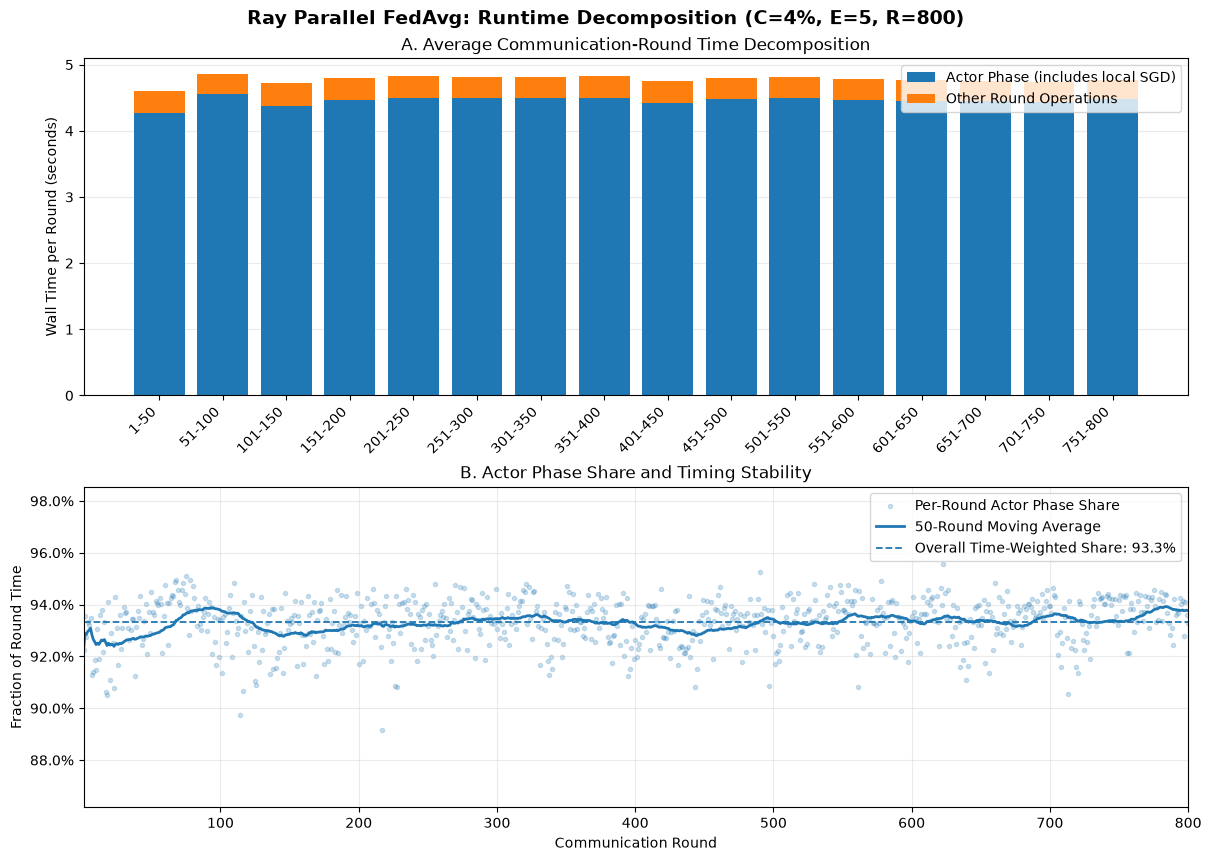


=== Non-Standard Plot Verification ===
Figure saved: Output\Part12_Ray_runtime_decomposition.png
Summary saved: Output\FedAvg_Ray_C04_E5_R800\runtime_decomposition_summary.json
800 rounds analyzed: PASSED
Wall-time decomposition: PASSED
Actor phase share: PASSED
Timing stability analyzed: PASSED
Formal checkpoints unchanged: PASSED

Runtime decomposition analysis completed.


In [47]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ==========================================================
# Part 1.2 - Non-Standard Plot
# Ray Runtime Decomposition and Timing Stability
#
# Analyze 800 completed communication rounds.
# No training, model loading, or test evaluation.
# ==========================================================

RUN_DIR = Path("Output/FedAvg_Ray_C04_E5_R800")
OUTPUT_DIR = Path("Output")

HISTORY_PATH = RUN_DIR / "training_history.csv"

FIGURE_PATH = (
    OUTPUT_DIR / "Part12_Ray_runtime_decomposition.png"
)

SUMMARY_PATH = (
    RUN_DIR / "runtime_decomposition_summary.json"
)

BLOCK_SIZE = 50
ROLLING_WINDOW = 50

assert HISTORY_PATH.exists()

# ----------------------------------------------------------
# 1. Read and verify the formal training history
# ----------------------------------------------------------

history = pd.read_csv(HISTORY_PATH)

required_columns = [
    "round",
    "actor_wall_seconds",
    "round_wall_seconds"
]

assert all(
    col in history.columns
    for col in required_columns
)

assert len(history) == 801

assert np.array_equal(
    history["round"].to_numpy(),
    np.arange(801)
)

# Exclude Round 0, which has no client training.
timing = history[
    history["round"] > 0
].copy()

assert len(timing) == 800

for col in [
    "actor_wall_seconds",
    "round_wall_seconds"
]:
    assert timing[col].notna().all()
    assert np.isfinite(timing[col]).all()
    assert (timing[col] > 0).all()

# ----------------------------------------------------------
# 2. Decompose communication-round wall time
# ----------------------------------------------------------

timing["other_wall_seconds"] = (
    timing["round_wall_seconds"]
    - timing["actor_wall_seconds"]
)

# Allow only negligible floating-point rounding error.
assert (
    timing["other_wall_seconds"] >= -1e-6
).all(), "Actor phase exceeds total round time."

timing["other_wall_seconds"] = (
    timing["other_wall_seconds"].clip(lower=0)
)

timing["actor_share"] = (
    timing["actor_wall_seconds"]
    / timing["round_wall_seconds"]
)

timing["actor_share_rolling"] = (
    timing["actor_share"]
    .rolling(
        window=ROLLING_WINDOW,
        min_periods=1
    )
    .mean()
)

# ----------------------------------------------------------
# 3. Aggregate timing in 50-round blocks
# ----------------------------------------------------------

timing["block_id"] = (
    (timing["round"] - 1) // BLOCK_SIZE
)

block_summary = (
    timing.groupby("block_id", as_index=False)
    .agg(
        actor_mean=("actor_wall_seconds", "mean"),
        other_mean=("other_wall_seconds", "mean"),
        round_mean=("round_wall_seconds", "mean"),
        actor_share_mean=("actor_share", "mean")
    )
)

block_summary["start_round"] = (
    block_summary["block_id"] * BLOCK_SIZE + 1
)

block_summary["end_round"] = (
    block_summary["start_round"] + BLOCK_SIZE - 1
)

block_labels = [
    f"{int(row.start_round)}-{int(row.end_round)}"
    for row in block_summary.itertuples()
]

assert len(block_summary) == 16

# ----------------------------------------------------------
# 4. Compute timing statistics
# ----------------------------------------------------------

mean_actor = float(
    timing["actor_wall_seconds"].mean()
)

mean_other = float(
    timing["other_wall_seconds"].mean()
)

mean_round = float(
    timing["round_wall_seconds"].mean()
)

total_actor = float(
    timing["actor_wall_seconds"].sum()
)

total_round = float(
    timing["round_wall_seconds"].sum()
)

overall_actor_share = total_actor / total_round

median_round = float(
    timing["round_wall_seconds"].median()
)

p95_round = float(
    timing["round_wall_seconds"].quantile(0.95)
)

min_round = float(
    timing["round_wall_seconds"].min()
)

max_round = float(
    timing["round_wall_seconds"].max()
)

first_100_mean = float(
    timing.iloc[:100]["round_wall_seconds"].mean()
)

last_100_mean = float(
    timing.iloc[-100:]["round_wall_seconds"].mean()
)

print("=== Ray Runtime Analysis ===")
print("Communication rounds:", len(timing))

print("\n=== Average Per-Round Time ===")
print("Mean Actor Phase:", f"{mean_actor:.4f}s")
print("Mean Other Phase:", f"{mean_other:.4f}s")
print("Mean Total Round:", f"{mean_round:.4f}s")

print(
    "Overall Actor Phase Share:",
    f"{overall_actor_share:.2%}"
)

print("\n=== Round-Time Distribution ===")
print("Minimum:", f"{min_round:.4f}s")
print("Median:", f"{median_round:.4f}s")
print("95th percentile:", f"{p95_round:.4f}s")
print("Maximum:", f"{max_round:.4f}s")

print("\n=== Timing Stability ===")
print("First 100 rounds:", f"{first_100_mean:.4f}s")
print("Last 100 rounds:", f"{last_100_mean:.4f}s")
print(
    "Last / First ratio:",
    f"{last_100_mean / first_100_mean:.4f}"
)

# ----------------------------------------------------------
# 5. Create the non-standard two-panel figure
# ----------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 8.5),
    gridspec_kw={"height_ratios": [1.05, 1.0]},
    constrained_layout=True
)

# Panel A: stacked timing decomposition
x = np.arange(len(block_summary))

ax1.bar(
    x,
    block_summary["actor_mean"],
    label="Actor Phase (includes local SGD)"
)

ax1.bar(
    x,
    block_summary["other_mean"],
    bottom=block_summary["actor_mean"],
    label="Other Round Operations"
)

ax1.set_title(
    "A. Average Communication-Round Time Decomposition"
)

ax1.set_ylabel("Wall Time per Round (seconds)")
ax1.set_xticks(x)
ax1.set_xticklabels(
    block_labels,
    rotation=45,
    ha="right"
)
ax1.grid(axis="y", alpha=0.25)
ax1.set_axisbelow(True)
ax1.legend(loc="upper right")

# Panel B: Actor phase share over all 800 rounds
ax2.scatter(
    timing["round"],
    timing["actor_share"] * 100,
    s=9,
    alpha=0.22,
    label="Per-Round Actor Phase Share"
)

ax2.plot(
    timing["round"],
    timing["actor_share_rolling"] * 100,
    linewidth=2,
    label="50-Round Moving Average"
)

ax2.axhline(
    overall_actor_share * 100,
    linestyle="--",
    linewidth=1.3,
    label=(
        "Overall Time-Weighted Share: "
        f"{overall_actor_share:.1%}"
    )
)

ax2.set_title(
    "B. Actor Phase Share and Timing Stability"
)

ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Fraction of Round Time")
ax2.set_xlim(1, 800)

# Display percentage on a 0-100 numeric axis.
ax2.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

share_min = float(
    (timing["actor_share"] * 100).min()
)
share_max = float(
    (timing["actor_share"] * 100).max()
)

ax2.set_ylim(
    max(0, share_min - 3),
    min(100, share_max + 3)
)

ax2.grid(True, alpha=0.25)
ax2.legend(loc="best")

fig.suptitle(
    "Ray Parallel FedAvg: Runtime Decomposition "
    "(C=4%, E=5, R=800)",
    fontsize=14,
    fontweight="bold"
)

fig.savefig(
    FIGURE_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ----------------------------------------------------------
# 6. Save reproducible quantitative evidence
# ----------------------------------------------------------

summary = {
    "experiment": "Ray FedAvg Runtime Decomposition",
    "communication_rounds": 800,
    "block_size": BLOCK_SIZE,
    "rolling_window": ROLLING_WINDOW,
    "mean_actor_phase_seconds": mean_actor,
    "mean_other_phase_seconds": mean_other,
    "mean_round_seconds": mean_round,
    "total_recorded_round_seconds": total_round,
    "overall_actor_phase_share": overall_actor_share,
    "minimum_round_seconds": min_round,
    "median_round_seconds": median_round,
    "p95_round_seconds": p95_round,
    "maximum_round_seconds": max_round,
    "first_100_round_mean_seconds": first_100_mean,
    "last_100_round_mean_seconds": last_100_mean,
    "last_to_first_round_time_ratio": (
        last_100_mean / first_100_mean
    ),
    "actor_phase_includes_actual_training": True,
    "pure_ray_overhead_isolated": False
}

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=4)

assert FIGURE_PATH.exists()
assert SUMMARY_PATH.exists()

print("\n=== Non-Standard Plot Verification ===")
print("Figure saved:", FIGURE_PATH)
print("Summary saved:", SUMMARY_PATH)
print("800 rounds analyzed: PASSED")
print("Wall-time decomposition: PASSED")
print("Actor phase share: PASSED")
print("Timing stability analyzed: PASSED")
print("Formal checkpoints unchanged: PASSED")

print("\nRuntime decomposition analysis completed.")


In [48]:

import os
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import ray

# ==========================================================
# Part 1.2 - Step 7.2
# Matched Serial vs. Ray Runtime Benchmark
#
# 5 rounds, 4 clients, E=5
# Same initial model and data
# 1 PyTorch CPU thread per client training task
#
# Includes local training, aggregation, evaluation
# and Ray Actor creation/cleanup
#
# No changes to formal R800 checkpoints
# ==========================================================

assert ray.is_initialized()
assert ray.cluster_resources().get("CPU", 0) >= 4

BENCH_ROUNDS = 5
BENCH_EPOCHS = 5
BENCH_LR = 0.01
BENCH_BATCH = 32
BENCH_SEED = 42

BENCH_DIR = Path(
    "Output/FedAvg_Ray_Correctness/Runtime_Benchmark"
)
BENCH_DIR.mkdir(parents=True, exist_ok=True)

saved_rng = torch.get_rng_state()
saved_threads = torch.get_num_threads()

def run_benchmark(mode):

    assert mode in ("serial", "ray")

    torch.manual_seed(BENCH_SEED)
    bench_model = FEMNISTMLP().cpu()

    records = []
    worker_times = []

    experiment_start = time.perf_counter()

    for round_number in range(1, BENCH_ROUNDS + 1):

        round_start = time.perf_counter()
        round_id = round_number - 1

        clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_id,
                client_fraction=0.04,
                seed=BENCH_SEED
            )
        ]

        assert len(clients) == 4

        global_state = {
            k: v.detach().cpu().clone()
            for k, v in bench_model.state_dict().items()
        }

        updates = []
        actor_phase = None
        max_worker_time = None

        if mode == "serial":

            for cid in clients:
                state, n, local_loss = train_one_client(
                    client_id=cid,
                    global_state=global_state,
                    local_epochs=BENCH_EPOCHS,
                    learning_rate=BENCH_LR,
                    batch_size=BENCH_BATCH,
                    round_id=round_id
                )

                updates.append((state, n))

        else:

            actors = []
            state_ref = None

            try:
                actor_start = time.perf_counter()

                for cid in clients:

                    idx = np.asarray(
                        client_splits[cid]["train_idx"],
                        dtype=np.int64
                    )

                    images = np.asarray(
                        [
                            train_data[cid]["images"][int(i)]
                            for i in idx
                        ],
                        dtype=np.float32
                    )

                    labels = np.asarray(
                        [
                            train_data[cid]["labels"][int(i)]
                            for i in idx
                        ],
                        dtype=np.int64
                    )

                    actors.append(
                        FEMNISTRayClientActor.remote(
                            cid, images, labels
                        )
                    )

                state_ref = ray.put(global_state)

                futures = [
                    actor.train.remote(
                        state_ref,
                        BENCH_EPOCHS,
                        BENCH_LR,
                        BENCH_BATCH,
                        round_id
                    )
                    for actor in actors
                ]

                results = ray.get(
                    futures,
                    timeout=180
                )

                actor_phase = (
                    time.perf_counter() - actor_start
                )

                assert len(results) == 4
                assert len({
                    int(r["pid"]) for r in results
                }) == 4

                max_worker_time = max(
                    float(r["elapsed_seconds"])
                    for r in results
                )

                worker_times.append(max_worker_time)

                for cid, result in zip(clients, results):

                    assert result["client_id"] == cid
                    assert result["cpu_threads"] == 1
                    assert result["gpu_ids"] == []

                    updates.append((
                        result["model_state"],
                        int(result["n_samples"])
                    ))

            finally:
                for actor in actors:
                    try:
                        ray.kill(actor)
                    except Exception as exc:
                        print("Cleanup warning:", str(exc))

                if state_ref is not None:
                    del state_ref

        # Same aggregation and evaluation for both modes.
        bench_model.load_state_dict(
            fedavg_aggregate(updates)
        )

        val = evaluate_global_model(
            bench_model,
            split="val",
            batch_size=128
        )

        round_wall = (
            time.perf_counter() - round_start
        )

        records.append({
            "mode": mode,
            "round": round_number,
            "round_wall_seconds": round_wall,
            "actor_phase_seconds": actor_phase,
            "max_worker_seconds": max_worker_time,
            "val_loss": float(val["loss"]),
            "val_accuracy": float(val["accuracy"])
        })

        print(
            f"{mode.upper():6s} | "
            f"Round {round_number} | "
            f"Wall: {round_wall:.3f}s | "
            f"Val Loss: {val['loss']:.6f} | "
            f"Val Acc: {val['accuracy']:.4%}"
        )

    total_elapsed = (
        time.perf_counter() - experiment_start
    )

    final_state = {
        k: v.detach().cpu().clone()
        for k, v in bench_model.state_dict().items()
    }

    return (
        pd.DataFrame(records),
        final_state,
        total_elapsed,
        worker_times
    )

try:
    # Match the per-client CPU threading configuration.
    torch.set_num_threads(1)

    print("=== Matched Runtime Benchmark ===")
    print("Rounds per mode:", BENCH_ROUNDS)
    print("Clients per round: 4")
    print("Local epochs:", BENCH_EPOCHS)
    print("CPU threads per training task: 1")
    print("Host PyTorch threads:", torch.get_num_threads())

    print("\n=== Serial FedAvg ===")

    serial_df, serial_state, serial_total, _ = (
        run_benchmark("serial")
    )

    print("\n=== Ray Parallel FedAvg ===")

    ray_df, ray_state, ray_total, worker_times = (
        run_benchmark("ray")
    )

    # ------------------------------------------------------
    # 1. Verify models remain numerically equivalent
    # ------------------------------------------------------

    model_difference = max(
        float(
            (
                serial_state[k].double()
                - ray_state[k].double()
            ).abs().max()
        )
        for k in serial_state
    )

    assert model_difference < 1e-5

    merged = serial_df.merge(
        ray_df,
        on="round",
        suffixes=("_serial", "_ray"),
        validate="one_to_one"
    )

    val_loss_difference = float(
        (
            merged["val_loss_serial"]
            - merged["val_loss_ray"]
        ).abs().max()
    )

    assert val_loss_difference < 1e-4

    # ------------------------------------------------------
    # 2. Compute matched wall-time comparison
    # ------------------------------------------------------

    mean_serial = float(
        serial_df["round_wall_seconds"].mean()
    )

    mean_ray = float(
        ray_df["round_wall_seconds"].mean()
    )

    speedup = serial_total / ray_total
    slowdown = ray_total / serial_total

    mean_actor_phase = float(
        ray_df["actor_phase_seconds"].mean()
    )

    mean_max_worker = float(np.mean(worker_times))

    # This is NOT pure overhead:
    # it also contains scheduling and transport delays,
    # plus work not covered by the Actor's internal timer.
    residual_actor_time = (
        mean_actor_phase - mean_max_worker
    )

    print("\n=== Matched Runtime Comparison ===")
    print("Serial total:", f"{serial_total:.3f}s")
    print("Ray total:", f"{ray_total:.3f}s")
    print("Serial mean round:", f"{mean_serial:.3f}s")
    print("Ray mean round:", f"{mean_ray:.3f}s")
    print("Ray / Serial time ratio:", f"{slowdown:.3f}x")
    print("Serial / Ray speedup:", f"{speedup:.3f}x")

    print("\n=== Ray Actor Phase Analysis ===")
    print(
        "Mean Actor phase:",
        f"{mean_actor_phase:.3f}s"
    )
    print(
        "Mean slowest Worker execution:",
        f"{mean_max_worker:.3f}s"
    )
    print(
        "Actor phase minus slowest Worker time:",
        f"{residual_actor_time:.3f}s"
    )

    print(
        "\nNote: The residual is not a direct "
        "measurement of pure Ray overhead."
    )

    print("\n=== Numerical Correctness ===")
    print(
        "Max parameter difference:",
        f"{model_difference:.10e}"
    )
    print(
        "Max validation loss difference:",
        f"{val_loss_difference:.10e}"
    )
    print("Serial-Ray equivalence: PASSED")

    # ------------------------------------------------------
    # 3. Save results
    # ------------------------------------------------------

    comparison_path = (
        BENCH_DIR / "matched_runtime_comparison.csv"
    )

    summary_path = (
        BENCH_DIR / "matched_runtime_summary.json"
    )

    pd.concat(
        [serial_df, ray_df],
        ignore_index=True
    ).to_csv(comparison_path, index=False)

    summary = {
        "test": "Matched Serial-Ray Runtime Benchmark",
        "rounds_per_mode": BENCH_ROUNDS,
        "clients_per_round": 4,
        "local_epochs": BENCH_EPOCHS,
        "cpu_threads_per_training_task": 1,
        "serial_total_seconds": serial_total,
        "ray_total_seconds": ray_total,
        "serial_mean_round_seconds": mean_serial,
        "ray_mean_round_seconds": mean_ray,
        "ray_over_serial_time_ratio": slowdown,
        "serial_over_ray_speedup": speedup,
        "mean_actor_phase_seconds": mean_actor_phase,
        "mean_max_worker_seconds": mean_max_worker,
        "residual_actor_phase_seconds": residual_actor_time,
        "max_model_parameter_difference": model_difference,
        "max_validation_loss_difference": val_loss_difference,
        "numerical_consistency_passed": True
    }

    with open(
        summary_path, "w", encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Benchmark Verification ===")
    print("Matched configuration: PASSED")
    print("Numerical consistency: PASSED")
    print("No held-out test data used: PASSED")
    print("Results saved:", comparison_path)
    print("Summary saved:", summary_path)

finally:
    torch.set_num_threads(saved_threads)
    torch.set_rng_state(saved_rng)
    gc.collect()

print("\nMatched runtime benchmark completed.")


=== Matched Runtime Benchmark ===
Rounds per mode: 5
Clients per round: 4
Local epochs: 5
CPU threads per training task: 1
Host PyTorch threads: 1

=== Serial FedAvg ===
SERIAL | Round 1 | Wall: 0.257s | Val Loss: 3.812934 | Val Acc: 5.4784%
SERIAL | Round 2 | Wall: 0.233s | Val Loss: 3.750976 | Val Acc: 5.7905%
SERIAL | Round 3 | Wall: 0.184s | Val Loss: 3.756501 | Val Acc: 5.9622%
SERIAL | Round 4 | Wall: 0.201s | Val Loss: 3.723845 | Val Acc: 5.9622%
SERIAL | Round 5 | Wall: 0.244s | Val Loss: 3.723890 | Val Acc: 9.9110%

=== Ray Parallel FedAvg ===
RAY    | Round 1 | Wall: 4.292s | Val Loss: 3.812934 | Val Acc: 5.4784%
RAY    | Round 2 | Wall: 5.074s | Val Loss: 3.750976 | Val Acc: 5.7905%
RAY    | Round 3 | Wall: 4.522s | Val Loss: 3.756501 | Val Acc: 5.9622%
RAY    | Round 4 | Wall: 4.669s | Val Loss: 3.723845 | Val Acc: 5.9622%
RAY    | Round 5 | Wall: 4.162s | Val Loss: 3.723890 | Val Acc: 9.9110%

=== Matched Runtime Comparison ===
Serial total: 1.120s
Ray total: 22.721s
Seria

In [49]:

import os
import numpy as np
import torch
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 1.1: Environment and Data Verification
#
# Read-only checks of existing training objects.
# No model training.
# No Laplace noise generation.
# No held-out test evaluation.
# ==========================================================

print("=== Part 2 Environment Verification ===")

required_objects = [
    "train_data",
    "client_splits",
    "FEMNISTMLP",
    "select_clients",
    "train_one_client",
    "fedavg_aggregate",
    "evaluate_global_model"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

print("Missing required objects:", missing_objects)

assert not missing_objects, (
    "Required Part 1 objects are missing. "
    "Restore the Part 1 setup cells, not the training cells."
)

print("Part 1 FedAvg functions: AVAILABLE")

# ----------------------------------------------------------
# 1. Verify client count and data partitions
# ----------------------------------------------------------

print("\n=== FEMNIST Dataset Verification ===")

NUM_CLIENTS = len(train_data)

assert NUM_CLIENTS == 100
assert len(client_splits) == NUM_CLIENTS

total_train = 0
total_val = 0
train_sizes = []
val_sizes = []

for cid in range(NUM_CLIENTS):

    client = train_data[cid]

    assert "images" in client
    assert "labels" in client

    train_idx = np.asarray(
        client_splits[cid]["train_idx"],
        dtype=np.int64
    )

    val_idx = np.asarray(
        client_splits[cid]["val_idx"],
        dtype=np.int64
    )

    n_original = len(client["labels"])

    assert len(client["images"]) == n_original
    assert len(train_idx) > 0
    assert len(val_idx) > 0

    assert len(np.unique(train_idx)) == len(train_idx)
    assert len(np.unique(val_idx)) == len(val_idx)

    assert np.all(train_idx >= 0)
    assert np.all(val_idx >= 0)

    assert np.all(train_idx < n_original)
    assert np.all(val_idx < n_original)

    assert len(
        np.intersect1d(train_idx, val_idx)
    ) == 0

    assert len(train_idx) + len(val_idx) == n_original

    total_train += len(train_idx)
    total_val += len(val_idx)

    train_sizes.append(len(train_idx))
    val_sizes.append(len(val_idx))

print("Total clients:", NUM_CLIENTS)
print("Total training samples:", total_train)
print("Total validation samples:", total_val)

print(
    "Training samples per client:",
    min(train_sizes), "to", max(train_sizes)
)

assert total_train == 25418
assert total_val == 6407

print("Client data partitions: PASSED")

# ----------------------------------------------------------
# 2. Inspect a sample image and training labels
# ----------------------------------------------------------

print("\n=== Image and Label Verification ===")

sample_image = np.asarray(
    train_data[0]["images"][0],
    dtype=np.float32
)

assert sample_image.shape == (28, 28)
assert np.isfinite(sample_image).all()

sample_min = float(sample_image.min())
sample_max = float(sample_image.max())

assert sample_min >= 0.0
assert sample_max <= 1.0

for cid in range(NUM_CLIENTS):

    labels = np.asarray(
        train_data[cid]["labels"],
        dtype=np.int64
    )

    assert labels.min() >= 0
    assert labels.max() < 62

print("Image shape:", sample_image.shape)
print("Sample pixel minimum:", sample_min)
print("Sample pixel maximum:", sample_max)
print("Number of model output classes:", 62)

print("Image and label checks: PASSED")

# ----------------------------------------------------------
# 3. Verify neural network without changing global RNG
# ----------------------------------------------------------

print("\n=== Model Architecture Verification ===")

with torch.random.fork_rng(devices=[]):

    model = FEMNISTMLP().cpu()
    model.eval()

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
    )

    with torch.inference_mode():

        dummy_image = torch.zeros(
            (2, 28, 28),
            dtype=torch.float32
        )

        dummy_output = model(dummy_image)

assert parameter_count == 108478
assert dummy_output.shape == (2, 62)

print("Model parameters:", parameter_count)
print("Output shape:", tuple(dummy_output.shape))
print("Model architecture: PASSED")

del model, dummy_image, dummy_output

# ----------------------------------------------------------
# 4. Verify FedAvg client sampling (C = 10%)
# ----------------------------------------------------------

print("\n=== FedAvg Sampling Verification ===")

selected_clients = select_clients(
    round_id=0,
    client_fraction=0.10,
    seed=42
)

selected_clients = [
    int(cid)
    for cid in selected_clients
]

assert len(selected_clients) == 10
assert len(set(selected_clients)) == 10

print("Selected clients:", selected_clients)
print("Clients per round:", len(selected_clients))

print("C = 10% sampling: PASSED")

# ----------------------------------------------------------
# 5. Prepare an independent Part 2 directory
# ----------------------------------------------------------

print("\n=== Part 2 Output Directory ===")

PART2_DIR = Path("Output/Part2_Laplace_FedAvg")

PART2_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Part 2 directory:", PART2_DIR)
print("Directory exists:", PART2_DIR.exists())

assert PART2_DIR.exists()

# Check for Part 1 reference without loading it.
baseline_path = Path(
    "Output/FedAvg_C10_E5_R800/best_checkpoint.pt"
)

print(
    "Part 1 baseline checkpoint found:",
    baseline_path.exists()
)

# ----------------------------------------------------------
# 6. Final summary
# ----------------------------------------------------------

print("\n=== Step 1.1 Summary ===")

print("Dataset structure: PASSED")
print("Train/validation partitions: PASSED")
print("Model architecture: PASSED")
print("FedAvg functions available: PASSED")
print("C = 10% sampling: PASSED")
print("Independent output directory: PASSED")

print("\nModel training: NOT STARTED")
print("Laplace noise injection: NOT STARTED")
print("Test dataset: NOT ACCESSED")
print("Existing checkpoints: UNCHANGED")

print("\nPart 2 environment verification completed.")


=== Part 2 Environment Verification ===
Missing required objects: []
Part 1 FedAvg functions: AVAILABLE

=== FEMNIST Dataset Verification ===
Total clients: 100
Total training samples: 25418
Total validation samples: 6407
Training samples per client: 94 to 314
Client data partitions: PASSED

=== Image and Label Verification ===
Image shape: (28, 28)
Sample pixel minimum: 0.0
Sample pixel maximum: 1.0
Number of model output classes: 62
Image and label checks: PASSED

=== Model Architecture Verification ===
Model parameters: 108478
Output shape: (2, 62)
Model architecture: PASSED

=== FedAvg Sampling Verification ===
Selected clients: [96, 71, 8, 60, 41, 94, 68, 9, 19, 82]
Clients per round: 10
C = 10% sampling: PASSED

=== Part 2 Output Directory ===
Part 2 directory: Output\Part2_Laplace_FedAvg
Directory exists: True
Part 1 baseline checkpoint found: True

=== Step 1.1 Summary ===
Dataset structure: PASSED
Train/validation partitions: PASSED
Model architecture: PASSED
FedAvg functions 

In [50]:

import json
import numpy as np
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 1.2: Laplace Noise Injection and Validation
#
# Fixed noise realization per client and image.
# No clipping or renormalization.
# Original training data remains unchanged.
# No model training or test-set access.
# ==========================================================

PART2_DIR = Path("Output/Part2_Laplace_FedAvg")
PART2_DIR.mkdir(parents=True, exist_ok=True)

NOISE_SEED = 2026
TEST_CLIENT = 22
TEST_SCALES = [0.0, 0.02, 0.10, 0.40]

# ----------------------------------------------------------
# 1. Define the Laplace perturbation function
# ----------------------------------------------------------

def make_perturbed_client_train(
    client_id,
    noise_scale,
    seed=2026
):
    """
    Return noisy training images and unchanged labels.

    Each pixel receives independent Laplace(0, b) noise.
    Noise is fixed for a given client and random seed.

    The original train_data is never modified.
    Validation and test data are not accessed.

    The same base random draws are used across b values,
    allowing controlled comparisons of noise strength.
    """

    cid = int(client_id)
    b = float(noise_scale)

    if not np.isfinite(b) or b < 0:
        raise ValueError(
            "Laplace noise scale must be finite and >= 0."
        )

    indices = np.asarray(
        client_splits[cid]["train_idx"],
        dtype=np.int64
    )

    clean_images = np.asarray(
        [
            train_data[cid]["images"][int(i)]
            for i in indices
        ],
        dtype=np.float32
    )

    labels = np.asarray(
        [
            train_data[cid]["labels"][int(i)]
            for i in indices
        ],
        dtype=np.int64
    )

    assert clean_images.shape == (len(labels), 28, 28)
    assert np.isfinite(clean_images).all()

    # Seed depends on client ID, not on noise scale.
    # This supports a paired comparison across b values.
    rng = np.random.default_rng(
        np.random.SeedSequence([int(seed), cid])
    )

    if b == 0.0:
        noisy_images = clean_images.copy()
    else:
        noise = rng.laplace(
            loc=0.0,
            scale=b,
            size=clean_images.shape
        ).astype(np.float32)

        noisy_images = clean_images + noise

    return (
        np.ascontiguousarray(noisy_images),
        labels.copy()
    )

# ----------------------------------------------------------
# 2. Preserve clean reference data for the test client
# ----------------------------------------------------------

train_indices = np.asarray(
    client_splits[TEST_CLIENT]["train_idx"],
    dtype=np.int64
)

clean_reference = np.asarray(
    [
        train_data[TEST_CLIENT]["images"][int(i)]
        for i in train_indices
    ],
    dtype=np.float32
).copy()

clean_labels = np.asarray(
    [
        train_data[TEST_CLIENT]["labels"][int(i)]
        for i in train_indices
    ],
    dtype=np.int64
).copy()

print("=== Laplace Noise Configuration ===")
print("Test client:", TEST_CLIENT)
print("Training images:", len(clean_reference))
print("Image shape:", clean_reference.shape[1:])
print("Pixel values tested:", clean_reference.size)
print("Noise scales:", TEST_SCALES)
print("Random seed:", NOISE_SEED)

# ----------------------------------------------------------
# 3. Test all selected noise scales
# ----------------------------------------------------------

noise_statistics = []

print("\n=== Laplace Noise Statistical Validation ===")

for b in TEST_SCALES:

    noisy_images, labels = make_perturbed_client_train(
        client_id=TEST_CLIENT,
        noise_scale=b,
        seed=NOISE_SEED
    )

    assert noisy_images.shape == clean_reference.shape
    assert noisy_images.dtype == np.float32
    assert np.array_equal(labels, clean_labels)
    assert np.isfinite(noisy_images).all()

    # Recover actual numerical perturbations.
    differences = (
        noisy_images.astype(np.float64)
        - clean_reference.astype(np.float64)
    )

    empirical_mean = float(differences.mean())
    empirical_variance = float(differences.var())
    empirical_std = float(differences.std())

    theoretical_variance = 2.0 * b**2
    theoretical_std = np.sqrt(2.0) * b

    out_of_range_fraction = float(
        np.mean(
            (noisy_images < 0.0)
            | (noisy_images > 1.0)
        )
    )

    if b == 0.0:

        # Zero noise must reproduce clean data exactly.
        assert np.array_equal(
            noisy_images,
            clean_reference
        )

        assert empirical_mean == 0.0
        assert empirical_variance == 0.0

        relative_variance_error = 0.0

    else:

        relative_variance_error = abs(
            empirical_variance - theoretical_variance
        ) / theoretical_variance

        # Conservative statistical tolerances for
        # approximately 200,000 independent noise values.
        assert abs(empirical_mean) < 0.02 * b
        assert relative_variance_error < 0.05

        # Nonzero noise must actually alter the images.
        assert not np.array_equal(
            noisy_images,
            clean_reference
        )

    noise_statistics.append({
        "noise_scale": b,
        "empirical_mean": empirical_mean,
        "empirical_variance": empirical_variance,
        "theoretical_variance": theoretical_variance,
        "relative_variance_error": relative_variance_error,
        "empirical_std": empirical_std,
        "theoretical_std": theoretical_std,
        "out_of_range_fraction": out_of_range_fraction
    })

    print(
        f"b={b:.2f} | "
        f"Mean={empirical_mean:+.6f} | "
        f"Var={empirical_variance:.6f} | "
        f"Expected Var={theoretical_variance:.6f} | "
        f"Rel Error={relative_variance_error:.2%} | "
        f"Outside [0,1]={out_of_range_fraction:.2%}"
    )

# ----------------------------------------------------------
# 4. Verify deterministic noise generation
# ----------------------------------------------------------

print("\n=== Reproducibility Verification ===")

images_a, labels_a = make_perturbed_client_train(
    TEST_CLIENT, 0.10, NOISE_SEED
)

images_b, labels_b = make_perturbed_client_train(
    TEST_CLIENT, 0.10, NOISE_SEED
)

assert np.array_equal(images_a, images_b)
assert np.array_equal(labels_a, labels_b)

print("Identical noise with same seed: PASSED")

# ----------------------------------------------------------
# 5. Verify invalid scale handling
# ----------------------------------------------------------

print("\n=== Invalid Scale Verification ===")

for invalid_b in [-0.01, float("nan"), float("inf")]:
    try:
        make_perturbed_client_train(
            TEST_CLIENT, invalid_b, NOISE_SEED
        )
    except ValueError:
        print(f"Invalid scale {invalid_b}: REJECTED")
    else:
        raise AssertionError(
            f"Invalid scale {invalid_b} was accepted."
        )

# ----------------------------------------------------------
# 6. Verify original data were not modified
# ----------------------------------------------------------

print("\n=== Original Data Integrity ===")

original_after = np.asarray(
    [
        train_data[TEST_CLIENT]["images"][int(i)]
        for i in train_indices
    ],
    dtype=np.float32
)

labels_after = np.asarray(
    [
        train_data[TEST_CLIENT]["labels"][int(i)]
        for i in train_indices
    ],
    dtype=np.int64
)

assert np.array_equal(
    original_after, clean_reference
)

assert np.array_equal(
    labels_after, clean_labels
)

print("Original training images unchanged: PASSED")
print("Original training labels unchanged: PASSED")

# ----------------------------------------------------------
# 7. Save diagnostic statistics
# ----------------------------------------------------------

result_path = (
    PART2_DIR / "laplace_noise_validation.json"
)

summary = {
    "test": "Laplace Noise Statistical Validation",
    "client_id": TEST_CLIENT,
    "num_images": int(len(clean_reference)),
    "num_pixel_values": int(clean_reference.size),
    "random_seed": NOISE_SEED,
    "noise_scales": TEST_SCALES,
    "statistics": noise_statistics,
    "reproducibility_passed": True,
    "original_data_unchanged": True,
    "clipping_applied": False,
    "passed": True
}

with open(result_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

assert result_path.exists()

print("\n=== Step 1.2 Summary ===")
print("Laplace noise generation: PASSED")
print("Noise mean and variance: PASSED")
print("Zero-noise equivalence: PASSED")
print("Fixed-seed reproducibility: PASSED")
print("Invalid noise scales rejected: PASSED")
print("Training labels unchanged: PASSED")
print("Original dataset unchanged: PASSED")
print("Clipping or renormalization: NOT APPLIED")

print("\nResults saved:", result_path)
print("Model training: NOT STARTED")
print("Test dataset: NOT ACCESSED")
print("Existing checkpoints: UNCHANGED")

print("\nPart 2 Step 1.2 completed successfully.")


=== Laplace Noise Configuration ===
Test client: 22
Training images: 257
Image shape: (28, 28)
Pixel values tested: 201488
Noise scales: [0.0, 0.02, 0.1, 0.4]
Random seed: 2026

=== Laplace Noise Statistical Validation ===
b=0.00 | Mean=+0.000000 | Var=0.000000 | Expected Var=0.000000 | Rel Error=0.00% | Outside [0,1]=0.00%
b=0.02 | Mean=+0.000058 | Var=0.000794 | Expected Var=0.000800 | Rel Error=0.76% | Outside [0,1]=46.66%
b=0.10 | Mean=+0.000288 | Var=0.019849 | Expected Var=0.020000 | Rel Error=0.76% | Outside [0,1]=47.84%
b=0.40 | Mean=+0.001152 | Var=0.317579 | Expected Var=0.320000 | Rel Error=0.76% | Outside [0,1]=53.26%

=== Reproducibility Verification ===
Identical noise with same seed: PASSED

=== Invalid Scale Verification ===
Invalid scale -0.01: REJECTED
Invalid scale nan: REJECTED
Invalid scale inf: REJECTED

=== Original Data Integrity ===
Original training images unchanged: PASSED
Original training labels unchanged: PASSED

=== Step 1.2 Summary ===
Laplace noise gene

=== Laplace Image Preview Configuration ===
Client: 22
Selected image indices: [180, 69, 119]
Labels: [24, 6, 2]
Noise scales: [0.0, 0.02, 0.05, 0.1, 0.2, 0.4]


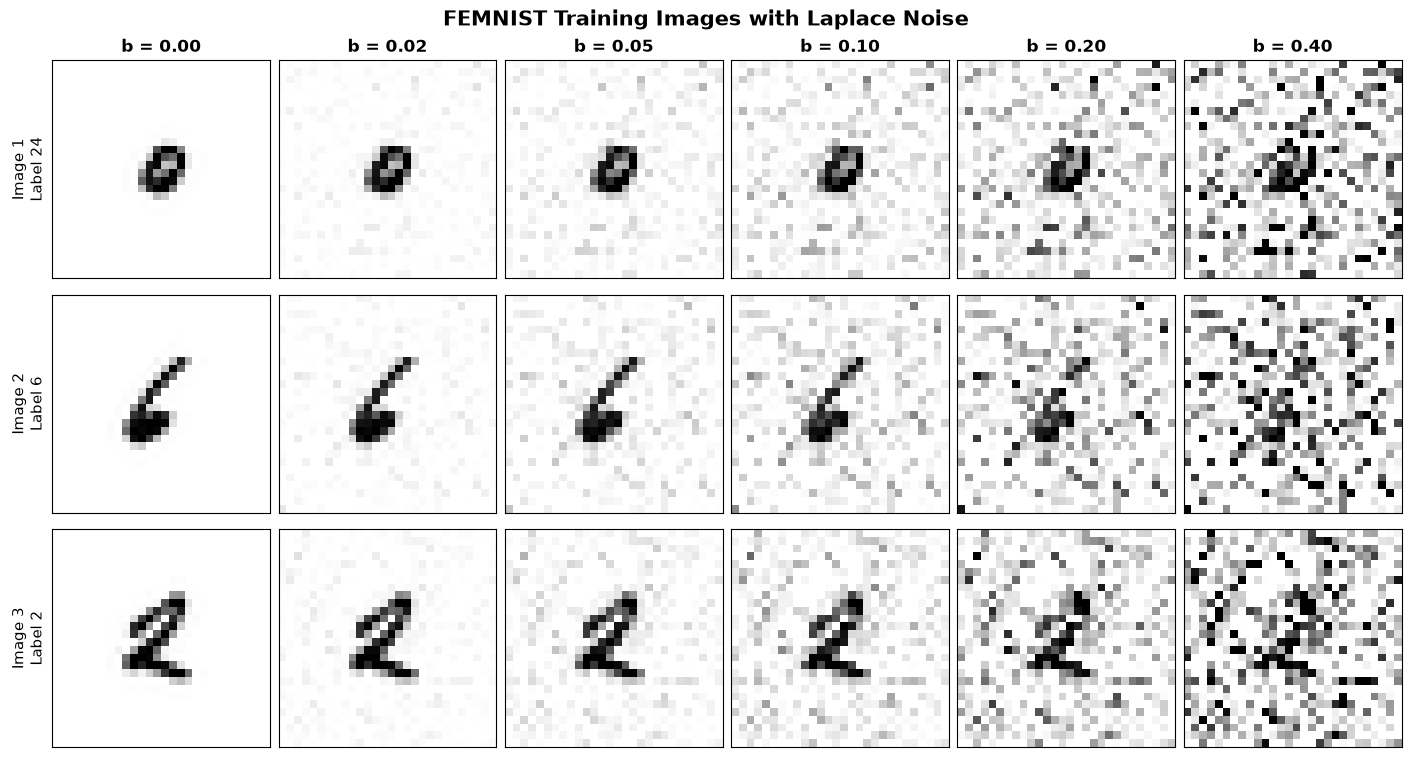


=== Perturbation Magnitude ===
b=0.00 | Mean Absolute Noise=0.000000 | RMS Noise=0.000000
b=0.02 | Mean Absolute Noise=0.019939 | RMS Noise=0.028177
b=0.05 | Mean Absolute Noise=0.049848 | RMS Noise=0.070443
b=0.10 | Mean Absolute Noise=0.099697 | RMS Noise=0.140886
b=0.20 | Mean Absolute Noise=0.199394 | RMS Noise=0.281771
b=0.40 | Mean Absolute Noise=0.398788 | RMS Noise=0.563543

=== Step 1.3 Summary ===
Same images across all noise scales: PASSED
Noise generation: PASSED
Original training data unchanged: PASSED
Visualization clipping only: YES
Training-data clipping: NO
Preview saved: Output\Part2_Laplace_Noise_Preview.png

Part 2 Step 1.3 completed successfully.


In [51]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 1.3: Visual Inspection of Laplace-Perturbed Images
#
# Display the same training images at different noise scales.
# No training or modification to original data.
# ==========================================================

assert "make_perturbed_client_train" in globals()

PART2_DIR = Path("Output/Part2_Laplace_FedAvg")
PART2_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_PATH = (
    Path("Output") / "Part2_Laplace_Noise_Preview.png"
)

PREVIEW_CLIENT = 22
PREVIEW_SEED = 2026
PREVIEW_SCALES = [0.0, 0.02, 0.05, 0.10, 0.20, 0.40]

# ----------------------------------------------------------
# 1. Load clean training images
# ----------------------------------------------------------

clean_images, clean_labels = make_perturbed_client_train(
    client_id=PREVIEW_CLIENT,
    noise_scale=0.0,
    seed=PREVIEW_SEED
)

assert clean_images.ndim == 3
assert clean_images.shape[1:] == (28, 28)

# ----------------------------------------------------------
# 2. Select three representative training images
# ----------------------------------------------------------

# Image standard deviation measures visual contrast.
# Choose images from different points in the distribution.
contrast = clean_images.std(axis=(1, 2))

sorted_indices = np.argsort(contrast)

positions = [
    int(0.40 * (len(sorted_indices) - 1)),
    int(0.65 * (len(sorted_indices) - 1)),
    int(0.85 * (len(sorted_indices) - 1))
]

selected_indices = [
    int(sorted_indices[pos])
    for pos in positions
]

assert len(set(selected_indices)) == 3

print("=== Laplace Image Preview Configuration ===")
print("Client:", PREVIEW_CLIENT)
print("Selected image indices:", selected_indices)
print("Labels:", clean_labels[selected_indices].tolist())
print("Noise scales:", PREVIEW_SCALES)

# ----------------------------------------------------------
# 3. Generate perturbations at each scale
# ----------------------------------------------------------

perturbed_by_scale = {}

for b in PREVIEW_SCALES:

    noisy_images, labels = make_perturbed_client_train(
        client_id=PREVIEW_CLIENT,
        noise_scale=b,
        seed=PREVIEW_SEED
    )

    assert np.array_equal(labels, clean_labels)
    assert np.isfinite(noisy_images).all()

    perturbed_by_scale[b] = noisy_images

# ----------------------------------------------------------
# 4. Plot identical images across noise scales
# ----------------------------------------------------------

n_rows = len(selected_indices)
n_cols = len(PREVIEW_SCALES)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 7.5),
    constrained_layout=True
)

for col, b in enumerate(PREVIEW_SCALES):

    noisy_images = perturbed_by_scale[b]

    for row, image_idx in enumerate(selected_indices):

        ax = axes[row, col]

        ax.imshow(
            noisy_images[image_idx],
            cmap="gray",
            vmin=0.0,
            vmax=1.0,
            interpolation="nearest"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        if row == 0:
            ax.set_title(
                f"b = {b:.2f}",
                fontsize=12,
                fontweight="bold"
            )

        if col == 0:
            ax.set_ylabel(
                f"Image {row + 1}\nLabel {clean_labels[image_idx]}",
                fontsize=11
            )

fig.suptitle(
    "FEMNIST Training Images with Laplace Noise",
    fontsize=15,
    fontweight="bold"
)

# Note: vmin/vmax only saturate the displayed grayscale.
# The underlying noisy arrays are NOT clipped.

fig.savefig(
    FIGURE_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ----------------------------------------------------------
# 5. Quantify noise magnitude for each column
# ----------------------------------------------------------

print("\n=== Perturbation Magnitude ===")

for b in PREVIEW_SCALES:

    noisy_images = perturbed_by_scale[b]

    differences = (
        noisy_images.astype(np.float64)
        - clean_images.astype(np.float64)
    )

    mean_absolute_noise = float(
        np.abs(differences).mean()
    )

    rms_noise = float(
        np.sqrt(np.mean(differences ** 2))
    )

    print(
        f"b={b:.2f} | "
        f"Mean Absolute Noise={mean_absolute_noise:.6f} | "
        f"RMS Noise={rms_noise:.6f}"
    )

# ----------------------------------------------------------
# 6. Final verification
# ----------------------------------------------------------

assert FIGURE_PATH.exists()

assert np.array_equal(
    perturbed_by_scale[0.0],
    clean_images
)

print("\n=== Step 1.3 Summary ===")
print("Same images across all noise scales: PASSED")
print("Noise generation: PASSED")
print("Original training data unchanged: PASSED")
print("Visualization clipping only: YES")
print("Training-data clipping: NO")
print("Preview saved:", FIGURE_PATH)

print("\nPart 2 Step 1.3 completed successfully.")


In [52]:

import json
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 1.4: Integrate Laplace Noise into Local SGD
#
# Verify b=0 equivalence against original Part 1.1.
# Verify b=0.1 produces valid, distinct model updates.
#
# No global FedAvg training.
# No held-out test data.
# No checkpoint loading or modification.
# ==========================================================

assert "make_perturbed_client_train" in globals()
assert "train_one_client" in globals()

PART2_DIR = Path("Output/Part2_Laplace_FedAvg")
PART2_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------
# 1. Define Laplace-noisy local SGD
# ----------------------------------------------------------

def train_one_client_laplace(
    client_id,
    global_state,
    local_epochs=5,
    learning_rate=0.01,
    batch_size=32,
    round_id=0,
    noise_scale=0.1,
    noise_seed=2026
):
    """
    Train a local FEMNIST model on fixed Laplace-noisy
    training images.

    Matches the Part 1.1 local SGD algorithm:
      - Same MLP architecture
      - SGD optimizer
      - Same deterministic mini-batch shuffling
      - Same local loss definition

    Returns:
      updated_state, n_samples, mean_local_loss
    """

    cid = int(client_id)

    assert local_epochs >= 1
    assert learning_rate > 0
    assert batch_size >= 1

    # Retrieve only this client's training partition.
    # No validation or test images are perturbed.
    images_np, labels_np = make_perturbed_client_train(
        client_id=cid,
        noise_scale=noise_scale,
        seed=noise_seed
    )

    n_samples = len(labels_np)

    assert images_np.shape == (n_samples, 28, 28)
    assert labels_np.shape == (n_samples,)
    assert n_samples > 0

    assert np.isfinite(images_np).all()
    assert labels_np.min() >= 0
    assert labels_np.max() < 62

    # Preserve noisy values outside [0, 1].
    # Do not clip or normalize the images.
    images = torch.from_numpy(images_np)
    labels = torch.from_numpy(labels_np)

    # Local model starts from the same server weights.
    local_model = FEMNISTMLP().cpu()
    local_model.load_state_dict(global_state)
    local_model.train()

    optimizer = torch.optim.SGD(
        local_model.parameters(),
        lr=learning_rate
    )

    # Same deterministic shuffling used in the
    # previously validated Part 1.1 / Ray implementation.
    generator = torch.Generator()
    generator.manual_seed(
        42 + round_id * 1000 + cid
    )

    total_loss = 0.0
    total_processed = 0
    optimizer_steps = 0

    for epoch in range(local_epochs):

        permutation = torch.randperm(
            n_samples,
            generator=generator
        )

        for start in range(0, n_samples, batch_size):

            indices = permutation[
                start:start + batch_size
            ]

            x = images[indices]
            y = labels[indices]

            optimizer.zero_grad(set_to_none=True)

            logits = local_model(x)

            loss = F.cross_entropy(
                logits,
                y
            )

            loss.backward()
            optimizer.step()

            total_loss += (
                float(loss.item()) * len(y)
            )

            total_processed += len(y)
            optimizer_steps += 1

    expected_steps = local_epochs * (
        (n_samples + batch_size - 1) // batch_size
    )

    assert total_processed == n_samples * local_epochs
    assert optimizer_steps == expected_steps

    updated_state = {
        k: v.detach().cpu().clone()
        for k, v in local_model.state_dict().items()
    }

    assert all(
        torch.isfinite(value).all().item()
        for value in updated_state.values()
    )

    mean_local_loss = total_loss / total_processed

    return (
        updated_state,
        n_samples,
        mean_local_loss
    )


# ----------------------------------------------------------
# 2. Prepare controlled initial global weights
# ----------------------------------------------------------

TEST_CLIENTS = [22, 25, 67]
TEST_EPOCHS = 2
TEST_LR = 0.01
TEST_BATCH = 32
TEST_ROUND_ID = 0
TEST_NOISE_SEED = 2026

saved_rng = torch.get_rng_state()
saved_threads = torch.get_num_threads()

def max_state_difference(state_a, state_b):
    assert set(state_a) == set(state_b)

    return max(
        float(
            (
                state_a[k].double()
                - state_b[k].double()
            ).abs().max()
        )
        for k in state_a
    )

try:
    torch.set_num_threads(1)
    torch.manual_seed(42)

    reference_model = FEMNISTMLP().cpu()

    reference_state = {
        k: v.detach().cpu().clone()
        for k, v in reference_model.state_dict().items()
    }

    print("=== Part 2 Local SGD Configuration ===")
    print("Test clients:", TEST_CLIENTS)
    print("Local epochs:", TEST_EPOCHS)
    print("Learning rate:", TEST_LR)
    print("Batch size:", TEST_BATCH)
    print("Noise scales: 0.0 and 0.1")
    print("Noise seed:", TEST_NOISE_SEED)
    print("PyTorch CPU threads:", torch.get_num_threads())

    diagnostics = []

    # ------------------------------------------------------
    # 3. Compare original SGD with Laplace SGD at b=0
    # ------------------------------------------------------

    print("\n=== Zero-Noise Equivalence ===")

    for cid in TEST_CLIENTS:

        original_state, original_n, original_loss = (
            train_one_client(
                client_id=cid,
                global_state=reference_state,
                local_epochs=TEST_EPOCHS,
                learning_rate=TEST_LR,
                batch_size=TEST_BATCH,
                round_id=TEST_ROUND_ID
            )
        )

        zero_state, zero_n, zero_loss = (
            train_one_client_laplace(
                client_id=cid,
                global_state=reference_state,
                local_epochs=TEST_EPOCHS,
                learning_rate=TEST_LR,
                batch_size=TEST_BATCH,
                round_id=TEST_ROUND_ID,
                noise_scale=0.0,
                noise_seed=TEST_NOISE_SEED
            )
        )

        assert original_n == zero_n

        parameter_difference = max_state_difference(
            original_state,
            zero_state
        )

        loss_difference = abs(
            float(original_loss) - float(zero_loss)
        )

        print(
            f"Client {cid:3d} | "
            f"Samples {zero_n:3d} | "
            f"Max Parameter Diff "
            f"{parameter_difference:.10e} | "
            f"Loss Diff {loss_difference:.10e}"
        )

        assert parameter_difference < 1e-5
        assert loss_difference < 1e-4

        # --------------------------------------------------
        # 4. Train the same client with nonzero noise
        # --------------------------------------------------

        noisy_state, noisy_n, noisy_loss = (
            train_one_client_laplace(
                client_id=cid,
                global_state=reference_state,
                local_epochs=TEST_EPOCHS,
                learning_rate=TEST_LR,
                batch_size=TEST_BATCH,
                round_id=TEST_ROUND_ID,
                noise_scale=0.1,
                noise_seed=TEST_NOISE_SEED
            )
        )

        assert noisy_n == original_n
        assert np.isfinite(noisy_loss)

        noisy_vs_clean = max_state_difference(
            noisy_state,
            original_state
        )

        noisy_vs_initial = max_state_difference(
            noisy_state,
            reference_state
        )

        assert noisy_vs_clean > 0
        assert noisy_vs_initial > 0

        diagnostics.append({
            "client_id": cid,
            "samples": int(noisy_n),
            "local_epochs": TEST_EPOCHS,
            "expected_optimizer_steps": int(
                TEST_EPOCHS
                * ((noisy_n + TEST_BATCH - 1) // TEST_BATCH)
            ),
            "zero_noise_parameter_difference":
                parameter_difference,
            "zero_noise_loss_difference": loss_difference,
            "noisy_vs_clean_parameter_difference":
                noisy_vs_clean,
            "noisy_vs_initial_parameter_difference":
                noisy_vs_initial,
            "clean_local_loss": float(original_loss),
            "noisy_local_loss": float(noisy_loss)
        })

    # ------------------------------------------------------
    # 5. Review the nonzero-noise update differences
    # ------------------------------------------------------

    print("\n=== Nonzero-Noise Local Training ===")

    for record in diagnostics:

        print(
            f"Client {record['client_id']:3d} | "
            f"Steps {record['expected_optimizer_steps']:3d} | "
            f"Clean Loss {record['clean_local_loss']:.4f} | "
            f"Noisy Loss {record['noisy_local_loss']:.4f} | "
            f"Update Diff "
            f"{record['noisy_vs_clean_parameter_difference']:.8e}"
        )

    # ------------------------------------------------------
    # 6. Save diagnostic evidence
    # ------------------------------------------------------

    result_path = (
        PART2_DIR / "laplace_local_sgd_validation.json"
    )

    summary = {
        "test": "Laplace Local SGD Validation",
        "test_clients": TEST_CLIENTS,
        "local_epochs": TEST_EPOCHS,
        "learning_rate": TEST_LR,
        "batch_size": TEST_BATCH,
        "noise_seed": TEST_NOISE_SEED,
        "diagnostics": diagnostics,
        "zero_noise_equivalence_passed": True,
        "nonzero_noise_updates_passed": True,
        "original_checkpoints_unchanged": True
    }

    with open(
        result_path,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Step 1.4 Summary ===")
    print("Original SGD compatibility: PASSED")
    print("b=0 numerical equivalence: PASSED")
    print("b=0.1 local training: PASSED")
    print("Client sample counts preserved: PASSED")
    print("Finite model updates: PASSED")
    print("Original Part 1 checkpoints: UNCHANGED")
    print("Held-out test dataset: NOT ACCESSED")
    print("Results saved:", result_path)

finally:
    torch.set_num_threads(saved_threads)
    torch.set_rng_state(saved_rng)

print("\nPart 2 Step 1.4 completed successfully.")


=== Part 2 Local SGD Configuration ===
Test clients: [22, 25, 67]
Local epochs: 2
Learning rate: 0.01
Batch size: 32
Noise scales: 0.0 and 0.1
Noise seed: 2026
PyTorch CPU threads: 1

=== Zero-Noise Equivalence ===
Client  22 | Samples 257 | Max Parameter Diff 0.0000000000e+00 | Loss Diff 0.0000000000e+00
Client  25 | Samples  94 | Max Parameter Diff 0.0000000000e+00 | Loss Diff 0.0000000000e+00
Client  67 | Samples 314 | Max Parameter Diff 0.0000000000e+00 | Loss Diff 0.0000000000e+00

=== Nonzero-Noise Local Training ===
Client  22 | Steps  18 | Clean Loss 4.0714 | Noisy Loss 4.0692 | Update Diff 5.65122953e-03
Client  25 | Steps   6 | Clean Loss 4.1077 | Noisy Loss 4.1075 | Update Diff 5.51041216e-04
Client  67 | Steps  20 | Clean Loss 3.9983 | Noisy Loss 3.9955 | Update Diff 2.60791183e-03

=== Step 1.4 Summary ===
Original SGD compatibility: PASSED
b=0 numerical equivalence: PASSED
b=0.1 local training: PASSED
Client sample counts preserved: PASSED
Finite model updates: PASSED
Ori

In [53]:

import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# ==========================================================
# Assignment 3 - Part 2
# Step 1.5: Laplace FedAvg Pilot Training
#
# Compare b=0.0 and b=0.1 over 10 communication rounds.
#
# C=10%, E=5, learning rate=0.01, batch size=32
# Same initialization and client selection in both runs.
#
# CPU-only Serial FedAvg
# No test-set evaluation
# No modifications to Part 1 checkpoints
# ==========================================================

assert "train_one_client_laplace" in globals()
assert "fedavg_aggregate" in globals()
assert "evaluate_global_model" in globals()

PILOT_ROUNDS = 10
PILOT_SCALES = [0.0, 0.1]
PILOT_FRACTION = 0.10
PILOT_EPOCHS = 5
PILOT_LR = 0.01
PILOT_BATCH = 32
PILOT_SEED = 42
PILOT_NOISE_SEED = 2026

PILOT_DIR = Path(
    "Output/Part2_Laplace_FedAvg/Pilot_C10_E5_R10"
)
PILOT_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_PATH = PILOT_DIR / "pilot_history.csv"
SUMMARY_PATH = PILOT_DIR / "pilot_summary.json"

# Prevent accidentally replacing completed evidence.
assert not HISTORY_PATH.exists(), (
    "Pilot history already exists. "
    "Inspect existing results before rerunning."
)

saved_rng = torch.get_rng_state()
saved_threads = torch.get_num_threads()

all_records = []
final_states = {}
pilot_times = {}

try:
    # Keep the pilot lightweight and deterministic.
    torch.set_num_threads(1)

    print("=== Laplace FedAvg Pilot Configuration ===")
    print("Noise scales:", PILOT_SCALES)
    print("Communication rounds:", PILOT_ROUNDS)
    print("Clients per round:", 10)
    print("Local epochs:", PILOT_EPOCHS)
    print("Learning rate:", PILOT_LR)
    print("Batch size:", PILOT_BATCH)
    print("PyTorch CPU threads:", torch.get_num_threads())
    print("Training mode: Serial FedAvg")

    # ------------------------------------------------------
    # 1. Run two independently initialized experiments
    # ------------------------------------------------------

    for b in PILOT_SCALES:

        print(f"\n=== Pilot Training: b={b:.2f} ===")

        # Exact same initial model for both noise scales.
        torch.manual_seed(PILOT_SEED)

        pilot_model = FEMNISTMLP().cpu()
        pilot_model.eval()

        initial_state = {
            k: v.detach().cpu().clone()
            for k, v in pilot_model.state_dict().items()
        }

        initial_val = evaluate_global_model(
            pilot_model,
            split="val",
            batch_size=128
        )

        all_records.append({
            "noise_scale": b,
            "round": 0,
            "val_loss": float(initial_val["loss"]),
            "val_accuracy": float(initial_val["accuracy"]),
            "participating_samples": 0,
            "round_wall_seconds": 0.0
        })

        print(
            "Initial validation accuracy:",
            f"{initial_val['accuracy']:.4%}"
        )

        run_start = time.perf_counter()

        for round_number in range(1, PILOT_ROUNDS + 1):

            round_start = time.perf_counter()
            round_id = round_number - 1

            selected_clients = [
                int(cid)
                for cid in select_clients(
                    round_id=round_id,
                    client_fraction=PILOT_FRACTION,
                    seed=PILOT_SEED
                )
            ]

            assert len(selected_clients) == 10
            assert len(set(selected_clients)) == 10

            global_state = {
                k: v.detach().cpu().clone()
                for k, v in pilot_model.state_dict().items()
            }

            client_updates = []
            participating_samples = 0

            # ----------------------------------------------
            # 2. Perform local SGD for all selected clients
            # ----------------------------------------------

            for cid in selected_clients:

                local_state, n_samples, local_loss = (
                    train_one_client_laplace(
                        client_id=cid,
                        global_state=global_state,
                        local_epochs=PILOT_EPOCHS,
                        learning_rate=PILOT_LR,
                        batch_size=PILOT_BATCH,
                        round_id=round_id,
                        noise_scale=b,
                        noise_seed=PILOT_NOISE_SEED
                    )
                )

                assert np.isfinite(local_loss)
                assert n_samples == len(
                    client_splits[cid]["train_idx"]
                )

                client_updates.append(
                    (local_state, n_samples)
                )

                participating_samples += n_samples

            # ----------------------------------------------
            # 3. Sample-weighted FedAvg aggregation
            # ----------------------------------------------

            aggregated_state = fedavg_aggregate(
                client_updates
            )

            assert all(
                torch.isfinite(value).all().item()
                for value in aggregated_state.values()
            )

            pilot_model.load_state_dict(
                aggregated_state
            )

            # ----------------------------------------------
            # 4. Evaluate on clean validation data
            # ----------------------------------------------

            val_metrics = evaluate_global_model(
                pilot_model,
                split="val",
                batch_size=128
            )

            assert val_metrics["samples"] == 6407
            assert np.isfinite(val_metrics["loss"])
            assert np.isfinite(val_metrics["accuracy"])

            round_wall = (
                time.perf_counter() - round_start
            )

            all_records.append({
                "noise_scale": b,
                "round": round_number,
                "val_loss": float(val_metrics["loss"]),
                "val_accuracy": float(
                    val_metrics["accuracy"]
                ),
                "participating_samples":
                    participating_samples,
                "round_wall_seconds": round_wall
            })

            if round_number in [1, 5, 10]:

                print(
                    f"Round {round_number:2d} | "
                    f"Val Loss: {val_metrics['loss']:.6f} | "
                    f"Val Acc: {val_metrics['accuracy']:.4%} | "
                    f"Samples: {participating_samples} | "
                    f"Wall: {round_wall:.3f}s"
                )

        pilot_times[str(b)] = (
            time.perf_counter() - run_start
        )

        final_states[str(b)] = {
            k: v.detach().cpu().clone()
            for k, v in pilot_model.state_dict().items()
        }

    # ------------------------------------------------------
    # 5. Compare both validation trajectories
    # ------------------------------------------------------

    pilot_history = pd.DataFrame(all_records)

    assert len(pilot_history) == (
        len(PILOT_SCALES) * (PILOT_ROUNDS + 1)
    )

    control = pilot_history[
        pilot_history["noise_scale"] == 0.0
    ].sort_values("round").reset_index(drop=True)

    noisy = pilot_history[
        pilot_history["noise_scale"] == 0.1
    ].sort_values("round").reset_index(drop=True)

    assert len(control) == len(noisy) == 11

    assert np.array_equal(
        control["round"].to_numpy(),
        noisy["round"].to_numpy()
    )

    initial_accuracy_diff = abs(
        float(control.iloc[0]["val_accuracy"])
        - float(noisy.iloc[0]["val_accuracy"])
    )

    assert initial_accuracy_diff == 0.0

    model_difference = max(
        float(
            (
                final_states["0.0"][key].double()
                - final_states["0.1"][key].double()
            ).abs().max()
        )
        for key in final_states["0.0"]
    )

    assert model_difference > 0
    assert np.isfinite(model_difference)

    control_final = control.iloc[-1]
    noisy_final = noisy.iloc[-1]

    accuracy_gap_pp = (
        float(control_final["val_accuracy"])
        - float(noisy_final["val_accuracy"])
    ) * 100.0

    print("\n=== Pilot Comparison ===")

    print(
        "b=0.00 final validation loss:",
        f"{control_final['val_loss']:.6f}"
    )

    print(
        "b=0.10 final validation loss:",
        f"{noisy_final['val_loss']:.6f}"
    )

    print(
        "b=0.00 final validation accuracy:",
        f"{control_final['val_accuracy']:.4%}"
    )

    print(
        "b=0.10 final validation accuracy:",
        f"{noisy_final['val_accuracy']:.4%}"
    )

    print(
        "Clean minus noisy accuracy:",
        f"{accuracy_gap_pp:+.4f} percentage points"
    )

    print(
        "Maximum final model parameter difference:",
        f"{model_difference:.10e}"
    )

    print("\n=== Pilot Training Times ===")

    for scale, elapsed in pilot_times.items():
        print(
            f"b={float(scale):.2f}: {elapsed:.3f}s"
        )

    # ------------------------------------------------------
    # 6. Save diagnostics
    # ------------------------------------------------------

    pilot_history.to_csv(
        HISTORY_PATH,
        index=False
    )

    summary = {
        "experiment": "Laplace FedAvg Pilot",
        "rounds": PILOT_ROUNDS,
        "client_fraction": PILOT_FRACTION,
        "local_epochs": PILOT_EPOCHS,
        "learning_rate": PILOT_LR,
        "batch_size": PILOT_BATCH,
        "model_seed": PILOT_SEED,
        "noise_seed": PILOT_NOISE_SEED,
        "noise_scales": PILOT_SCALES,
        "clean_final_val_loss": float(
            control_final["val_loss"]
        ),
        "noisy_final_val_loss": float(
            noisy_final["val_loss"]
        ),
        "clean_final_val_accuracy": float(
            control_final["val_accuracy"]
        ),
        "noisy_final_val_accuracy": float(
            noisy_final["val_accuracy"]
        ),
        "clean_minus_noisy_accuracy_pp":
            accuracy_gap_pp,
        "max_final_parameter_difference":
            model_difference,
        "training_times_seconds": pilot_times,
        "original_training_data_modified": False,
        "test_set_accessed": False,
        "passed": True
    }

    with open(
        SUMMARY_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Step 1.5 Summary ===")
    print("Both experiments completed: PASSED")
    print("Matched initialization: PASSED")
    print("Matched client sampling: PASSED")
    print("Weighted FedAvg aggregation: PASSED")
    print("Finite model updates: PASSED")
    print("Noisy model differs from clean model: PASSED")
    print("Clean validation evaluation: PASSED")
    print("Held-out test data: NOT ACCESSED")
    print("Formal checkpoints: UNCHANGED")
    print("History saved:", HISTORY_PATH)
    print("Summary saved:", SUMMARY_PATH)

finally:
    torch.set_num_threads(saved_threads)
    torch.set_rng_state(saved_rng)
    gc.collect()

print("\nPart 2 Step 1.5 completed.")


=== Laplace FedAvg Pilot Configuration ===
Noise scales: [0.0, 0.1]
Communication rounds: 10
Clients per round: 10
Local epochs: 5
Learning rate: 0.01
Batch size: 32
PyTorch CPU threads: 1
Training mode: Serial FedAvg

=== Pilot Training: b=0.00 ===
Initial validation accuracy: 1.8730%
Round  1 | Val Loss: 3.814985 | Val Acc: 5.2443% | Samples: 2582 | Wall: 0.585s
Round  5 | Val Loss: 3.721344 | Val Acc: 7.4606% | Samples: 2502 | Wall: 0.501s
Round 10 | Val Loss: 3.685930 | Val Acc: 6.2120% | Samples: 2614 | Wall: 0.577s

=== Pilot Training: b=0.10 ===
Initial validation accuracy: 1.8730%
Round  1 | Val Loss: 3.814189 | Val Acc: 5.1350% | Samples: 2582 | Wall: 0.630s
Round  5 | Val Loss: 3.720671 | Val Acc: 7.6011% | Samples: 2502 | Wall: 0.713s
Round 10 | Val Loss: 3.684900 | Val Acc: 7.2109% | Samples: 2614 | Wall: 0.535s

=== Pilot Comparison ===
b=0.00 final validation loss: 3.685930
b=0.10 final validation loss: 3.684900
b=0.00 final validation accuracy: 6.2120%
b=0.10 final valid

In [54]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path

# ==========================================================
# Part 2 - Step 2.1
# Formal Experiment Preflight
#
# 1. Check b=0 pilot against Part 1.1 baseline
# 2. Define correct noisy-training evaluation
# 3. Verify b=0 training metric equivalence
#
# No training
# No checkpoint loading
# No test-set access
# ==========================================================

PART1_HISTORY = Path(
    "Output/FedAvg_C10_E5_R800/training_history.csv"
)

PILOT_HISTORY = Path(
    "Output/Part2_Laplace_FedAvg/"
    "Pilot_C10_E5_R10/pilot_history.csv"
)

assert PILOT_HISTORY.exists()
assert "make_perturbed_client_train" in globals()

print("=== Part 2 Formal Experiment Preflight ===")

# ----------------------------------------------------------
# 1. Check the original b=0 baseline
# ----------------------------------------------------------

print("\n=== Zero-Noise Baseline Consistency ===")

pilot = pd.read_csv(PILOT_HISTORY)

pilot_clean = (
    pilot[pilot["noise_scale"] == 0.0]
    .sort_values("round")
    .reset_index(drop=True)
)

assert len(pilot_clean) == 11

if PART1_HISTORY.exists():

    original = pd.read_csv(PART1_HISTORY)

    original_first10 = (
        original[original["round"].between(0, 10)]
        .sort_values("round")
        .reset_index(drop=True)
    )

    assert len(original_first10) == 11

    max_val_loss_diff = float(
        np.max(
            np.abs(
                pilot_clean["val_loss"].to_numpy()
                - original_first10["val_loss"].to_numpy()
            )
        )
    )

    max_val_acc_diff = float(
        np.max(
            np.abs(
                pilot_clean["val_accuracy"].to_numpy()
                - original_first10["val_accuracy"].to_numpy()
            )
        )
    )

    print(
        "Max validation loss difference:",
        f"{max_val_loss_diff:.10e}"
    )

    print(
        "Max validation accuracy difference:",
        f"{max_val_acc_diff:.10e}"
    )

    baseline_match = (
        max_val_loss_diff < 1e-5
        and max_val_acc_diff < 1e-8
    )

    print(
        "Part 1 baseline equivalence:",
        "PASSED" if baseline_match else "REVIEW NEEDED"
    )

else:

    print("Part 1 training history not found.")
    print("Baseline reuse must be checked separately.")

# ----------------------------------------------------------
# 2. Define perturbed training-set evaluation
# ----------------------------------------------------------

def evaluate_perturbed_global_train(
    model,
    noise_scale,
    noise_seed=2026,
    batch_size=128
):
    """
    Evaluate the global model on each client's fixed
    Laplace-perturbed LOCAL TRAINING images.

    Does not modify original training data.
    Does not use validation or test images.
    """

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():

        for cid in range(len(train_data)):

            images_np, labels_np = (
                make_perturbed_client_train(
                    client_id=cid,
                    noise_scale=noise_scale,
                    seed=noise_seed
                )
            )

            n = len(labels_np)

            for start in range(0, n, batch_size):

                end = min(start + batch_size, n)

                x = torch.from_numpy(
                    images_np[start:end]
                )

                y = torch.from_numpy(
                    labels_np[start:end]
                )

                logits = model(x)

                loss_sum = F.cross_entropy(
                    logits,
                    y,
                    reduction="sum"
                )

                total_loss += float(loss_sum.item())

                total_correct += int(
                    (logits.argmax(dim=1) == y)
                    .sum()
                    .item()
                )

                total_samples += len(y)

    assert total_samples == 25418

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
        "samples": total_samples
    }

# ----------------------------------------------------------
# 3. Compare b=0 against original training evaluation
# ----------------------------------------------------------

print("\n=== Training Metric Equivalence ===")

with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)
    audit_model = FEMNISTMLP().cpu()

original_metrics = evaluate_global_model(
    audit_model,
    split="train",
    batch_size=128
)

zero_noise_metrics = evaluate_perturbed_global_train(
    audit_model,
    noise_scale=0.0,
    noise_seed=2026,
    batch_size=128
)

loss_diff = abs(
    original_metrics["loss"]
    - zero_noise_metrics["loss"]
)

accuracy_diff = abs(
    original_metrics["accuracy"]
    - zero_noise_metrics["accuracy"]
)

print(
    "Original train loss:",
    f"{original_metrics['loss']:.8f}"
)

print(
    "b=0 train loss:",
    f"{zero_noise_metrics['loss']:.8f}"
)

print(
    "Original train accuracy:",
    f"{original_metrics['accuracy']:.4%}"
)

print(
    "b=0 train accuracy:",
    f"{zero_noise_metrics['accuracy']:.4%}"
)

print(
    "Loss difference:",
    f"{loss_diff:.10e}"
)

print(
    "Accuracy difference:",
    f"{accuracy_diff:.10e}"
)

assert loss_diff < 1e-5
assert accuracy_diff < 1e-8

print("b=0 training metric equivalence: PASSED")

# ----------------------------------------------------------
# 4. Check evaluation with nonzero Laplace noise
# ----------------------------------------------------------

print("\n=== Perturbed Training Metric Verification ===")

noisy_metrics = evaluate_perturbed_global_train(
    audit_model,
    noise_scale=0.1,
    noise_seed=2026,
    batch_size=128
)

print("Noise scale:", 0.1)
print(
    "Perturbed train loss:",
    f"{noisy_metrics['loss']:.8f}"
)
print(
    "Perturbed train accuracy:",
    f"{noisy_metrics['accuracy']:.4%}"
)
print(
    "Evaluated samples:",
    noisy_metrics["samples"]
)

assert np.isfinite(noisy_metrics["loss"])
assert np.isfinite(noisy_metrics["accuracy"])
assert 0 <= noisy_metrics["accuracy"] <= 1

print("\n=== Step 2.1 Summary ===")
print("Noisy training evaluation: PASSED")
print("Zero-noise metric equivalence: PASSED")
print("Fixed Laplace noise: VERIFIED")
print("Original training data: UNCHANGED")
print("Held-out test data: NOT ACCESSED")
print("Existing checkpoints: UNCHANGED")

del audit_model

print("\nPart 2 formal experiment preflight completed.")


=== Part 2 Formal Experiment Preflight ===

=== Zero-Noise Baseline Consistency ===
Max validation loss difference: 4.8822410559e-08
Max validation accuracy difference: 0.0000000000e+00
Part 1 baseline equivalence: PASSED

=== Training Metric Equivalence ===
Original train loss: 4.14573111
b=0 train loss: 4.14573111
Original train accuracy: 2.2268%
b=0 train accuracy: 2.2268%
Loss difference: 0.0000000000e+00
Accuracy difference: 0.0000000000e+00
b=0 training metric equivalence: PASSED

=== Perturbed Training Metric Verification ===
Noise scale: 0.1
Perturbed train loss: 4.14619103
Perturbed train accuracy: 2.0025%
Evaluated samples: 25418

=== Step 2.1 Summary ===
Noisy training evaluation: PASSED
Zero-noise metric equivalence: PASSED
Fixed Laplace noise: VERIFIED
Original training data: UNCHANGED
Held-out test data: NOT ACCESSED
Existing checkpoints: UNCHANGED

Part 2 formal experiment preflight completed.


In [59]:

import os
import gc
import json
import time
import hashlib
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# ==========================================================
# Assignment 3 - Part 2
# Step 2.2: Formal Laplace FedAvg Training
#
# One noise scale per execution
# C=10%, E=5, R=800, SGD lr=0.01, batch=32
#
# Fixed Laplace noise per training image
# No clipping or renormalization
# Clean validation data
#
# Checkpoints every 10 rounds
# Automatic resume after interruption
# No held-out test evaluation
# ==========================================================

# ----------------------------------------------------------
# 1. Experimental configuration
# ----------------------------------------------------------

ACTIVE_B = 0.40

ALLOWED_SCALES = [0.02, 0.05, 0.10, 0.20, 0.40]

assert ACTIVE_B in ALLOWED_SCALES

TARGET_ROUNDS = 800
SAVE_EVERY = 10

CLIENT_FRACTION = 0.10
CLIENTS_PER_ROUND = 10
LOCAL_EPOCHS = 5
LEARNING_RATE = 0.01
BATCH_SIZE = 32

MODEL_SEED = 42
NOISE_SEED = 2026

SCALE_NAME = f"b{ACTIVE_B:.2f}"

RUN_DIR = (
    Path("Output/Part2_Laplace_FedAvg")
    / f"FedAvg_C10_E5_R800_{SCALE_NAME}"
)

RUN_DIR.mkdir(parents=True, exist_ok=True)

LATEST_PATH = RUN_DIR / "latest_checkpoint.pt"
BEST_PATH = RUN_DIR / "best_checkpoint.pt"
HISTORY_PATH = RUN_DIR / "training_history.csv"
CONFIG_PATH = RUN_DIR / "training_config.json"

assert "make_perturbed_client_train" in globals()
assert "train_one_client_laplace" in globals()
assert "fedavg_aggregate" in globals()
assert "evaluate_perturbed_global_train" in globals()

assert len(train_data) == 100
assert len(client_splits) == 100

try:
    import psutil
except ImportError:
    psutil = None

def available_ram_gb():
    if psutil is None:
        return None
    return psutil.virtual_memory().available / (1024 ** 3)

free_disk_gb = (
    shutil.disk_usage(RUN_DIR).free / (1024 ** 3)
)

assert free_disk_gb >= 1.0

if available_ram_gb() is not None:
    assert available_ram_gb() >= 4.0

print("=== Formal Laplace FedAvg Configuration ===")
print("Experiment:", SCALE_NAME)
print("Noise scale:", ACTIVE_B)
print("Communication rounds:", TARGET_ROUNDS)
print("Clients per round:", CLIENTS_PER_ROUND)
print("Local epochs:", LOCAL_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Model seed:", MODEL_SEED)
print("Noise seed:", NOISE_SEED)
print("Output directory:", RUN_DIR)
print("Available RAM (GB):", available_ram_gb())
print("Available disk (GB):", round(free_disk_gb, 2))

# ----------------------------------------------------------
# 2. Experiment configuration and split fingerprint
# ----------------------------------------------------------

config = {
    "experiment": f"Part2_Laplace_{SCALE_NAME}",
    "noise_scale": ACTIVE_B,
    "model_seed": MODEL_SEED,
    "noise_seed": NOISE_SEED,
    "num_clients": 100,
    "clients_per_round": CLIENTS_PER_ROUND,
    "client_fraction": CLIENT_FRACTION,
    "local_epochs": LOCAL_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "target_rounds": TARGET_ROUNDS,
    "noise_policy": "fixed_per_client_image",
    "training_clipping": False,
    "training_accuracy_dataset": "perturbed_train",
    "validation_dataset": "clean_val"
}

hasher = hashlib.sha256()

for cid in range(100):

    for split in ("train_idx", "val_idx"):

        idx = np.asarray(
            client_splits[cid][split],
            dtype=np.int64
        )

        hasher.update(cid.to_bytes(4, "little"))
        hasher.update(split.encode("ascii"))
        hasher.update(idx.tobytes())

split_fingerprint = hasher.hexdigest()

# ----------------------------------------------------------
# 3. Cache the fixed perturbed training dataset
# ----------------------------------------------------------

print("\n=== Preparing Fixed Laplace Training Data ===")

noisy_train_cache = {}

cache_bytes = 0

for cid in range(100):

    images_np, labels_np = make_perturbed_client_train(
        client_id=cid,
        noise_scale=ACTIVE_B,
        seed=NOISE_SEED
    )

    assert images_np.shape == (len(labels_np), 28, 28)
    assert np.isfinite(images_np).all()

    images_tensor = torch.from_numpy(
        np.ascontiguousarray(images_np)
    )

    labels_tensor = torch.from_numpy(
        np.ascontiguousarray(labels_np)
    )

    noisy_train_cache[cid] = (
        images_tensor,
        labels_tensor
    )

    cache_bytes += (
        images_tensor.numel() * images_tensor.element_size()
        + labels_tensor.numel() * labels_tensor.element_size()
    )

total_cached_samples = sum(
    len(noisy_train_cache[cid][1])
    for cid in range(100)
)

assert total_cached_samples == 25418

print("Cached clients:", len(noisy_train_cache))
print("Cached training samples:", total_cached_samples)
print("Approximate cache size (MiB):",
      round(cache_bytes / (1024 ** 2), 2))

# ----------------------------------------------------------
# 4. Define cached local training
# ----------------------------------------------------------

def train_laplace_cached(
    cid,
    global_state,
    round_id
):

    images, labels = noisy_train_cache[cid]

    n_samples = len(labels)

    local_model = FEMNISTMLP().cpu()
    local_model.load_state_dict(global_state)
    local_model.train()

    optimizer = torch.optim.SGD(
        local_model.parameters(),
        lr=LEARNING_RATE
    )

    generator = torch.Generator()
    generator.manual_seed(
        42 + round_id * 1000 + cid
    )

    total_loss = 0.0
    processed = 0

    for epoch in range(LOCAL_EPOCHS):

        permutation = torch.randperm(
            n_samples,
            generator=generator
        )

        for start in range(0, n_samples, BATCH_SIZE):

            indices = permutation[
                start:start + BATCH_SIZE
            ]

            x = images[indices]
            y = labels[indices]

            optimizer.zero_grad(set_to_none=True)

            logits = local_model(x)
            loss = F.cross_entropy(logits, y)

            loss.backward()
            optimizer.step()

            total_loss += float(loss.item()) * len(y)
            processed += len(y)

    assert processed == n_samples * LOCAL_EPOCHS

    state = {
        k: v.detach().cpu().clone()
        for k, v in local_model.state_dict().items()
    }

    assert all(
        torch.isfinite(v).all().item()
        for v in state.values()
    )

    return state, n_samples, total_loss / processed

# ----------------------------------------------------------
# 5. Define cached perturbed training evaluation
# ----------------------------------------------------------

def evaluate_laplace_cached(model):

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():

        for cid in range(100):

            images, labels = noisy_train_cache[cid]

            for start in range(0, len(labels), 128):

                x = images[start:start + 128]
                y = labels[start:start + 128]

                logits = model(x)

                loss = F.cross_entropy(
                    logits,
                    y,
                    reduction="sum"
                )

                total_loss += float(loss.item())

                total_correct += int(
                    (logits.argmax(dim=1) == y)
                    .sum()
                    .item()
                )

                total_samples += len(y)

    assert total_samples == 25418

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
        "samples": total_samples
    }

# ----------------------------------------------------------
# 6. Verify cached implementation against Step 1.4
# ----------------------------------------------------------

print("\n=== Cached Training Consistency Check ===")

saved_rng = torch.get_rng_state()
saved_threads = torch.get_num_threads()

try:
    torch.set_num_threads(1)

    torch.manual_seed(MODEL_SEED)

    audit_model = FEMNISTMLP().cpu()

    audit_state = {
        k: v.detach().cpu().clone()
        for k, v in audit_model.state_dict().items()
    }

    # Use exactly the same configuration in both paths.
    # The reference function receives E=5, not the earlier
    # E=2 edge-case setting.

    ref_state, ref_n, ref_loss = (
        train_one_client_laplace(
            client_id=22,
            global_state=audit_state,
            local_epochs=LOCAL_EPOCHS,
            learning_rate=LEARNING_RATE,
            batch_size=BATCH_SIZE,
            round_id=0,
            noise_scale=ACTIVE_B,
            noise_seed=NOISE_SEED
        )
    )

    cached_state, cached_n, cached_loss = (
        train_laplace_cached(
            cid=22,
            global_state=audit_state,
            round_id=0
        )
    )

    max_diff = max(
        float(
            (
                ref_state[k].double()
                - cached_state[k].double()
            ).abs().max()
        )
        for k in ref_state
    )

    loss_diff = abs(ref_loss - cached_loss)

    assert ref_n == cached_n
    assert max_diff < 1e-6
    assert loss_diff < 1e-6

    print("Reference client:", 22)
    print("Max parameter difference:", f"{max_diff:.10e}")
    print("Mean local loss difference:", f"{loss_diff:.10e}")
    print("Cached local SGD consistency: PASSED")

    # ------------------------------------------------------
    # 7. Initialize or resume the experiment
    # ------------------------------------------------------

    if LATEST_PATH.exists():

        assert CONFIG_PATH.exists(), (
            "Checkpoint exists without configuration."
        )

        with open(CONFIG_PATH, "r", encoding="utf-8") as f:
            previous_config = json.load(f)

        assert previous_config == config, (
            "Experiment configuration mismatch."
        )

        checkpoint = torch.load(
            LATEST_PATH,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["config"] == config
        assert (
            checkpoint["split_fingerprint"]
            == split_fingerprint
        )

        model = FEMNISTMLP().cpu()
        model.load_state_dict(checkpoint["model_state"])

        history = checkpoint["history"]

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in checkpoint["best_state"].items()
        }

        best_val_acc = float(checkpoint["best_val_acc"])
        best_val_loss = float(checkpoint["best_val_loss"])
        best_round = int(checkpoint["best_round"])
        completed_round = int(checkpoint["completed_round"])

        assert len(history) == completed_round + 1
        assert history[-1]["round"] == completed_round
        assert completed_round <= TARGET_ROUNDS

        print("\n=== Resuming Training ===")
        print("Completed round:", completed_round)
        print("Best round:", best_round)
        print("Best validation accuracy:",
              f"{best_val_acc:.4%}")

    else:

        assert not any([
            BEST_PATH.exists(),
            HISTORY_PATH.exists(),
            CONFIG_PATH.exists()
        ]), (
            "Partial experiment outputs exist. "
            "Inspect the directory before continuing."
        )

        torch.manual_seed(MODEL_SEED)

        model = FEMNISTMLP().cpu()

        initial_train = evaluate_laplace_cached(model)

        initial_val = evaluate_global_model(
            model,
            split="val",
            batch_size=128
        )

        assert initial_train["samples"] == 25418
        assert initial_val["samples"] == 6407

        history = [{
            "round": 0,
            "train_loss": float(initial_train["loss"]),
            "train_accuracy": float(
                initial_train["accuracy"]
            ),
            "val_loss": float(initial_val["loss"]),
            "val_accuracy": float(initial_val["accuracy"]),
            "participating_samples": 0,
            "selected_clients": "",
            "round_wall_seconds": 0.0
        }]

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        best_val_acc = float(initial_val["accuracy"])
        best_val_loss = float(initial_val["loss"])
        best_round = 0
        completed_round = 0

        with open(CONFIG_PATH, "w", encoding="utf-8") as f:
            json.dump(config, f, indent=4)

        print("\n=== Initial Global Model ===")
        print("Perturbed training accuracy:",
              f"{initial_train['accuracy']:.4%}")
        print("Clean validation accuracy:",
              f"{initial_val['accuracy']:.4%}")

    # ------------------------------------------------------
    # 8. Define atomic checkpoint saving
    # ------------------------------------------------------

    def save_laplace_checkpoint(round_number):

        checkpoint_data = {
            "completed_round": round_number,
            "model_state": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "best_state": best_state,
            "best_val_acc": best_val_acc,
            "best_val_loss": best_val_loss,
            "best_round": best_round,
            "history": history,
            "config": config,
            "split_fingerprint": split_fingerprint
        }

        tmp_latest = LATEST_PATH.with_suffix(".tmp")

        torch.save(checkpoint_data, tmp_latest)
        os.replace(tmp_latest, LATEST_PATH)

        best_data = {
            "round": best_round,
            "model_state": best_state,
            "val_accuracy": best_val_acc,
            "val_loss": best_val_loss,
            "config": config
        }

        tmp_best = BEST_PATH.with_suffix(".tmp")

        torch.save(best_data, tmp_best)
        os.replace(tmp_best, BEST_PATH)

        tmp_history = HISTORY_PATH.with_suffix(".tmp")

        pd.DataFrame(history).to_csv(
            tmp_history,
            index=False
        )

        os.replace(tmp_history, HISTORY_PATH)

    if not LATEST_PATH.exists():
        save_laplace_checkpoint(0)

    # ------------------------------------------------------
    # 9. Formal FedAvg training
    # ------------------------------------------------------

    print("\n=== Formal Laplace FedAvg Training ===")
    print("Noise scale:", ACTIVE_B)
    print("Starting round:", completed_round)
    print("Target round:", TARGET_ROUNDS)

    training_start = time.perf_counter()

    for round_number in range(
        completed_round + 1,
        TARGET_ROUNDS + 1
    ):

        round_start = time.perf_counter()
        round_id = round_number - 1

        selected_clients = [
            int(cid)
            for cid in select_clients(
                round_id=round_id,
                client_fraction=CLIENT_FRACTION,
                seed=MODEL_SEED
            )
        ]

        assert len(selected_clients) == CLIENTS_PER_ROUND
        assert len(set(selected_clients)) == CLIENTS_PER_ROUND

        global_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        updates = []
        participating_samples = 0

        # Ten sequential local client updates
        for cid in selected_clients:

            local_state, n, local_loss = (
                train_laplace_cached(
                    cid=cid,
                    global_state=global_state,
                    round_id=round_id
                )
            )

            assert np.isfinite(local_loss)

            updates.append(
                (local_state, n)
            )

            participating_samples += n

        # Sample-size-weighted FedAvg
        global_update = fedavg_aggregate(updates)

        model.load_state_dict(global_update)

        # Training metric: perturbed training images
        train_metrics = evaluate_laplace_cached(model)

        # Validation metric: clean validation images
        val_metrics = evaluate_global_model(
            model,
            split="val",
            batch_size=128
        )

        for metrics in (train_metrics, val_metrics):
            assert np.isfinite(metrics["loss"])
            assert np.isfinite(metrics["accuracy"])

        current_val_acc = float(
            val_metrics["accuracy"]
        )

        current_val_loss = float(
            val_metrics["loss"]
        )

        # Select the best checkpoint using clean validation.
        if (
            current_val_acc > best_val_acc
            or (
                current_val_acc == best_val_acc
                and current_val_loss < best_val_loss
            )
        ):

            best_val_acc = current_val_acc
            best_val_loss = current_val_loss
            best_round = round_number

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        round_wall = (
            time.perf_counter() - round_start
        )

        history.append({
            "round": round_number,
            "train_loss": float(train_metrics["loss"]),
            "train_accuracy": float(
                train_metrics["accuracy"]
            ),
            "val_loss": current_val_loss,
            "val_accuracy": current_val_acc,
            "participating_samples":
                participating_samples,
            "selected_clients": ",".join(
                str(cid) for cid in selected_clients
            ),
            "round_wall_seconds": round_wall
        })

        # --------------------------------------------------
        # 10. Checkpoint and progress
        # --------------------------------------------------

        if (
            round_number % SAVE_EVERY == 0
            or round_number == TARGET_ROUNDS
        ):

            save_laplace_checkpoint(round_number)

            elapsed = (
                time.perf_counter() - training_start
            )

            print(
                f"Round {round_number:3d} | "
                f"Train Loss: {train_metrics['loss']:.4f} | "
                f"Val Loss: {current_val_loss:.4f} | "
                f"Train Acc: {train_metrics['accuracy']:.2%} | "
                f"Val Acc: {current_val_acc:.2%} | "
                f"Best Val Acc: {best_val_acc:.2%} | "
                f"Round Wall: {round_wall:.2f}s | "
                f"Elapsed: {elapsed:.1f}s",
                flush=True
            )

            ram = available_ram_gb()

            if ram is not None and ram < 3.0:
                raise RuntimeError(
                    "Available RAM below 3 GB. "
                    "Progress has been saved."
                )

            gc.collect()

    # ------------------------------------------------------
    # 11. Final summary
    # ------------------------------------------------------

    final_record = history[-1]

    segment_elapsed = (
        time.perf_counter() - training_start
    )

    print("\n=== Formal Laplace FedAvg Summary ===")
    print("Noise scale:", ACTIVE_B)
    print("Completed rounds:", final_record["round"])
    print("Best round:", best_round)
    print("Best validation accuracy:",
          f"{best_val_acc:.4%}")
    print("Best validation loss:",
          f"{best_val_loss:.6f}")
    print("Final perturbed train accuracy:",
          f"{final_record['train_accuracy']:.4%}")
    print("Final validation accuracy:",
          f"{final_record['val_accuracy']:.4%}")
    print("Final validation loss:",
          f"{final_record['val_loss']:.6f}")
    print("History records:", len(history))
    print("Segment elapsed (s):",
          round(segment_elapsed, 2))

    print("\n=== Saved Files ===")
    print(LATEST_PATH)
    print(BEST_PATH)
    print(HISTORY_PATH)
    print(CONFIG_PATH)

    print("\nFormal Laplace FedAvg training completed.")

finally:
    torch.set_num_threads(saved_threads)
    torch.set_rng_state(saved_rng)

    # Explicitly release the temporary noisy dataset cache.
    if "noisy_train_cache" in globals():
        noisy_train_cache.clear()
        del noisy_train_cache

    gc.collect()

    print("\nTemporary noisy training cache released.")
    print("Original Part 1 checkpoints unchanged.")
    print("Held-out test dataset not accessed.")


=== Formal Laplace FedAvg Configuration ===
Experiment: b0.40
Noise scale: 0.4
Communication rounds: 800
Clients per round: 10
Local epochs: 5
Learning rate: 0.01
Batch size: 32
Model seed: 42
Noise seed: 2026
Output directory: Output\Part2_Laplace_FedAvg\FedAvg_C10_E5_R800_b0.40
Available RAM (GB): 15.454681396484375
Available disk (GB): 605.38

=== Preparing Fixed Laplace Training Data ===
Cached clients: 100
Cached training samples: 25418
Approximate cache size (MiB): 76.21

=== Cached Training Consistency Check ===
Reference client: 22
Max parameter difference: 0.0000000000e+00
Mean local loss difference: 0.0000000000e+00
Cached local SGD consistency: PASSED

=== Initial Global Model ===
Perturbed training accuracy: 1.6012%
Clean validation accuracy: 1.8730%

=== Formal Laplace FedAvg Training ===
Noise scale: 0.4
Starting round: 0
Target round: 800
Round  10 | Train Loss: 3.6838 | Val Loss: 3.6791 | Train Acc: 7.11% | Val Acc: 5.57% | Best Val Acc: 8.80% | Round Wall: 0.58s | Elap

In [60]:

import numpy as np
import pandas as pd
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 3.1: Six-Experiment Completeness Audit
#
# Verify all completed noise-scale experiments.
# No model loading or training.
# No held-out test evaluation.
# ==========================================================

OUTPUT_DIR = Path("Output")
PART2_DIR = OUTPUT_DIR / "Part2_Laplace_FedAvg"

NOISE_SCALES = [0.00, 0.02, 0.05, 0.10, 0.20, 0.40]
EXPECTED_ROUNDS = 800

REQUIRED_COLUMNS = [
    "round",
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy"
]

records = []

print("=== Part 2 Six-Experiment Audit ===")

for b in NOISE_SCALES:

    if b == 0.0:
        run_dir = OUTPUT_DIR / "FedAvg_C10_E5_R800"
    else:
        run_dir = (
            PART2_DIR
            / f"FedAvg_C10_E5_R800_b{b:.2f}"
        )

    history_path = run_dir / "training_history.csv"
    best_path = run_dir / "best_checkpoint.pt"
    latest_path = run_dir / "latest_checkpoint.pt"

    assert history_path.exists(), (
        f"Missing history for b={b:.2f}: {history_path}"
    )
    assert best_path.exists(), (
        f"Missing best checkpoint for b={b:.2f}"
    )
    assert latest_path.exists(), (
        f"Missing latest checkpoint for b={b:.2f}"
    )

    history = pd.read_csv(history_path)

    assert all(
        col in history.columns
        for col in REQUIRED_COLUMNS
    )

    assert len(history) == EXPECTED_ROUNDS + 1

    assert np.array_equal(
        history["round"].to_numpy(),
        np.arange(EXPECTED_ROUNDS + 1)
    )

    assert history[REQUIRED_COLUMNS].notna().all().all()

    for col in [
        "train_loss",
        "train_accuracy",
        "val_loss",
        "val_accuracy"
    ]:
        assert np.isfinite(history[col]).all()

    for col in ["train_accuracy", "val_accuracy"]:
        assert history[col].between(0, 1).all()

    assert (history["train_loss"] >= 0).all()
    assert (history["val_loss"] >= 0).all()

    best_row = history.loc[
        history["val_accuracy"].idxmax()
    ]

    final_row = history.iloc[-1]

    records.append({
        "noise_scale": b,
        "best_round": int(best_row["round"]),
        "best_val_accuracy": float(
            best_row["val_accuracy"]
        ),
        "best_val_loss": float(
            best_row["val_loss"]
        ),
        "final_train_accuracy": float(
            final_row["train_accuracy"]
        ),
        "final_train_loss": float(
            final_row["train_loss"]
        ),
        "final_val_accuracy": float(
            final_row["val_accuracy"]
        ),
        "final_val_loss": float(
            final_row["val_loss"]
        ),
        "history_records": len(history),
        "best_checkpoint_exists": True,
        "latest_checkpoint_exists": True,
        "train_data_type": (
            "clean" if b == 0.0 else "perturbed"
        )
    })

    print(
        f"b={b:.2f} | "
        f"Best Round={int(best_row['round']):3d} | "
        f"Best Val={best_row['val_accuracy']:.4%} | "
        f"Final Train={final_row['train_accuracy']:.4%} | "
        f"Final Val={final_row['val_accuracy']:.4%} | "
        f"History=801 | Checkpoints=OK"
    )

# ----------------------------------------------------------
# 2. Build consolidated result table
# ----------------------------------------------------------

summary_df = pd.DataFrame(records)

assert len(summary_df) == 6
assert summary_df["noise_scale"].is_unique
assert (summary_df["history_records"] == 801).all()

print("\n=== Consolidated Accuracy Summary ===")

display_columns = [
    "noise_scale",
    "best_round",
    "best_val_accuracy",
    "final_train_accuracy",
    "final_val_accuracy"
]

print(
    summary_df[display_columns].to_string(
        index=False,
        formatters={
            "noise_scale": lambda x: f"{x:.2f}",
            "best_val_accuracy": lambda x: f"{x:.4%}",
            "final_train_accuracy": lambda x: f"{x:.4%}",
            "final_val_accuracy": lambda x: f"{x:.4%}"
        }
    )
)

# ----------------------------------------------------------
# 3. Save consolidated evidence
# ----------------------------------------------------------

summary_path = (
    PART2_DIR / "all_noise_scales_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

assert summary_path.exists()

print("\n=== Step 3.1 Verification ===")
print("Six noise scales found: PASSED")
print("Six 800-round histories: PASSED")
print("All metrics finite: PASSED")
print("Best checkpoints present: PASSED")
print("Latest checkpoints present: PASSED")
print("Summary saved:", summary_path)

print("\nNo model weights loaded.")
print("No training performed.")
print("Held-out test dataset not accessed.")
print("\nPart 2 Step 3.1 completed successfully.")


=== Part 2 Six-Experiment Audit ===
b=0.00 | Best Round=796 | Best Val=66.2088% | Final Train=67.1571% | Final Val=65.8811% | History=801 | Checkpoints=OK
b=0.02 | Best Round=796 | Best Val=66.2244% | Final Train=67.0784% | Final Val=65.7562% | History=801 | Checkpoints=OK
b=0.05 | Best Round=796 | Best Val=65.8499% | Final Train=66.6417% | Final Val=65.6938% | History=801 | Checkpoints=OK
b=0.10 | Best Round=794 | Best Val=65.5689% | Final Train=66.0910% | Final Val=65.2099% | History=801 | Checkpoints=OK
b=0.20 | Best Round=777 | Best Val=63.3526% | Final Train=64.2183% | Final Val=62.9624% | History=801 | Checkpoints=OK
b=0.40 | Best Round=750 | Best Val=56.7504% | Final Train=58.1832% | Final Val=56.0481% | History=801 | Checkpoints=OK

=== Consolidated Accuracy Summary ===
noise_scale  best_round best_val_accuracy final_train_accuracy final_val_accuracy
       0.00         796          66.2088%             67.1571%           65.8811%
       0.02         796          66.2244%      

=== Part 2 Accuracy Curve Verification ===
b=0.00 | Records=801 | Final Train=67.1571% | Final Val=65.8811%
b=0.02 | Records=801 | Final Train=67.0784% | Final Val=65.7562%
b=0.05 | Records=801 | Final Train=66.6417% | Final Val=65.6938%
b=0.10 | Records=801 | Final Train=66.0910% | Final Val=65.2099%
b=0.20 | Records=801 | Final Train=64.2183% | Final Val=62.9624%
b=0.40 | Records=801 | Final Train=58.1832% | Final Val=56.0481%


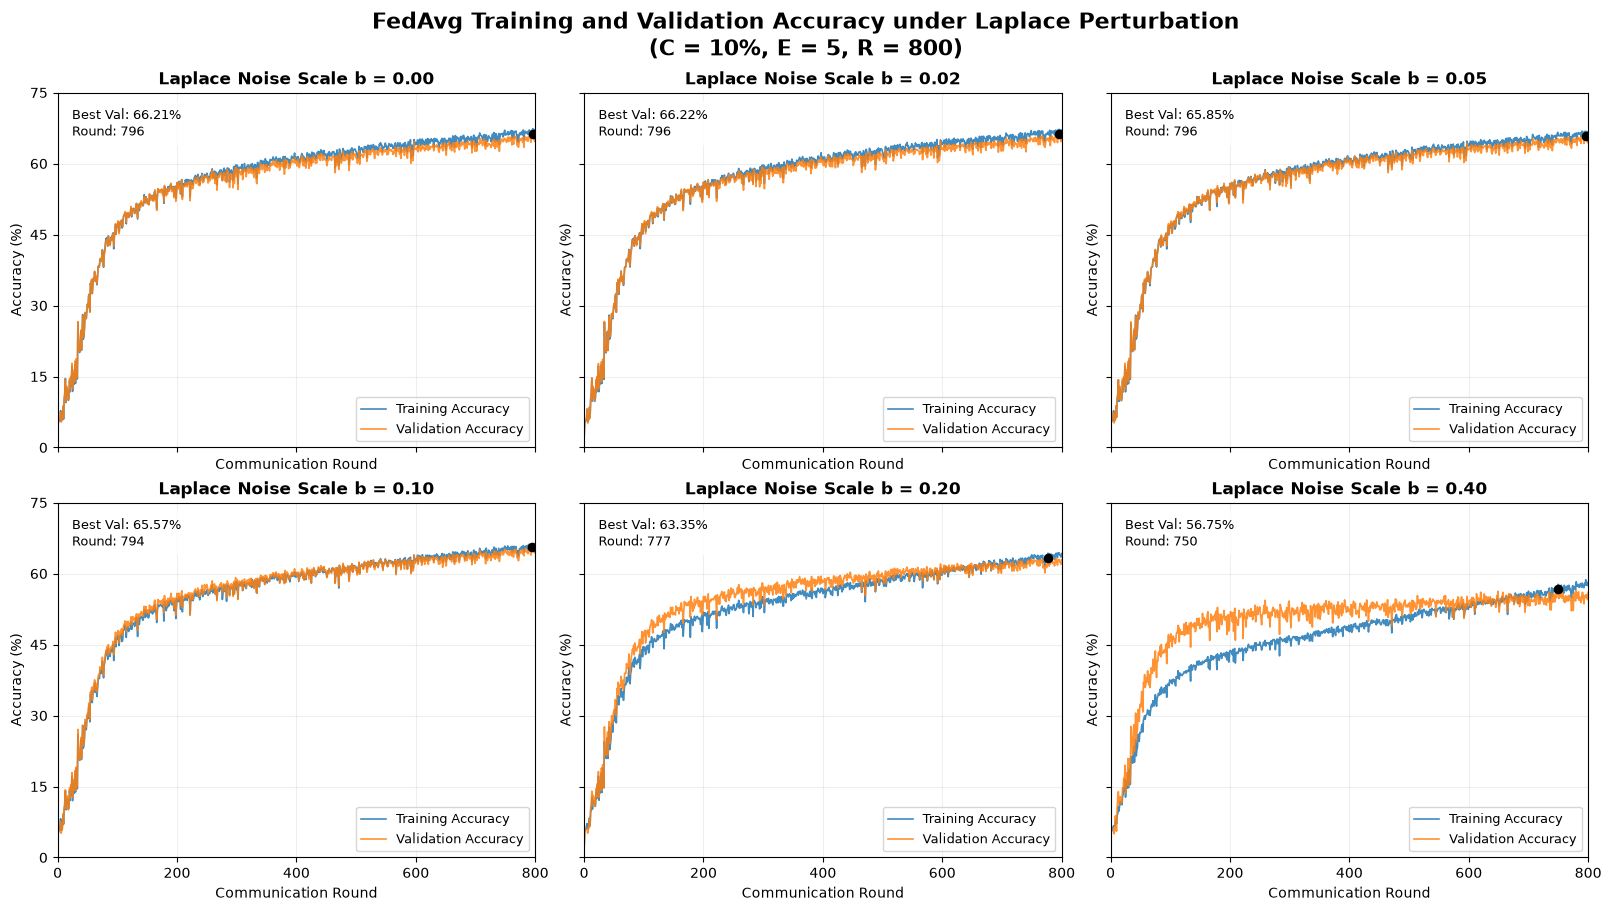


=== Accuracy Curve Summary ===
b=0.00 | Best Round=796 | Best Val=66.2088% | Final Train=67.1571% | Final Val=65.8811%
b=0.02 | Best Round=796 | Best Val=66.2244% | Final Train=67.0784% | Final Val=65.7562%
b=0.05 | Best Round=796 | Best Val=65.8499% | Final Train=66.6417% | Final Val=65.6938%
b=0.10 | Best Round=794 | Best Val=65.5689% | Final Train=66.0910% | Final Val=65.2099%
b=0.20 | Best Round=777 | Best Val=63.3526% | Final Train=64.2183% | Final Val=62.9624%
b=0.40 | Best Round=750 | Best Val=56.7504% | Final Train=58.1832% | Final Val=56.0481%

=== Step 3.2 Verification ===
Six training histories loaded: PASSED
800 rounds per experiment: PASSED
Training curves plotted: PASSED
Validation curves plotted: PASSED
Best validation rounds marked: PASSED
Consistent axis scales: PASSED
Figure saved: Output\Part2_Training_Validation_Accuracy.png

No model training performed.
Held-out test dataset not accessed.
Formal checkpoints unchanged.

Part 2 Step 3.2 completed successfully.


In [61]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 3.2: Training and Validation Accuracy Curves
#
# Six noise scales, 800 communication rounds
# 2 x 3 panel figure
#
# No model training or checkpoint loading
# No held-out test evaluation
# ==========================================================

OUTPUT_DIR = Path("Output")
PART2_DIR = OUTPUT_DIR / "Part2_Laplace_FedAvg"

FIGURE_PATH = (
    OUTPUT_DIR
    / "Part2_Training_Validation_Accuracy.png"
)

NOISE_SCALES = [
    0.00, 0.02, 0.05,
    0.10, 0.20, 0.40
]

EXPECTED_ROUNDS = 800

# ----------------------------------------------------------
# 1. Load and verify all six training histories
# ----------------------------------------------------------

histories = {}

print("=== Part 2 Accuracy Curve Verification ===")

for b in NOISE_SCALES:

    if b == 0.0:
        run_dir = OUTPUT_DIR / "FedAvg_C10_E5_R800"
    else:
        run_dir = (
            PART2_DIR
            / f"FedAvg_C10_E5_R800_b{b:.2f}"
        )

    history_path = run_dir / "training_history.csv"

    assert history_path.exists(), (
        f"Missing history for b={b:.2f}"
    )

    df = pd.read_csv(history_path)

    assert len(df) == EXPECTED_ROUNDS + 1

    assert np.array_equal(
        df["round"].to_numpy(),
        np.arange(EXPECTED_ROUNDS + 1)
    )

    for column in [
        "train_accuracy",
        "val_accuracy"
    ]:
        assert df[column].notna().all()
        assert np.isfinite(df[column]).all()
        assert df[column].between(0, 1).all()

    histories[b] = df

    print(
        f"b={b:.2f} | "
        f"Records={len(df)} | "
        f"Final Train={df.iloc[-1]['train_accuracy']:.4%} | "
        f"Final Val={df.iloc[-1]['val_accuracy']:.4%}"
    )

# ----------------------------------------------------------
# 2. Create six-panel accuracy figure
# ----------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, b in zip(axes.flat, NOISE_SCALES):

    df = histories[b]

    rounds = df["round"].to_numpy()

    train_accuracy = (
        df["train_accuracy"].to_numpy() * 100
    )

    val_accuracy = (
        df["val_accuracy"].to_numpy() * 100
    )

    # Training accuracy
    ax.plot(
        rounds,
        train_accuracy,
        linewidth=1.2,
        alpha=0.85,
        label="Training Accuracy"
    )

    # Validation accuracy
    ax.plot(
        rounds,
        val_accuracy,
        linewidth=1.2,
        alpha=0.85,
        label="Validation Accuracy"
    )

    # Locate best validation accuracy
    best_index = int(
        np.argmax(val_accuracy)
    )

    best_round = int(
        rounds[best_index]
    )

    best_accuracy = float(
        val_accuracy[best_index]
    )

    ax.scatter(
        [best_round],
        [best_accuracy],
        s=35,
        zorder=5,
        color="black"
    )

    ax.set_title(
        f"Laplace Noise Scale b = {b:.2f}",
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        0.03,
        0.96,
        (
            f"Best Val: {best_accuracy:.2f}%\n"
            f"Round: {best_round}"
        ),
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=9,
        bbox={
            "facecolor": "white",
            "alpha": 0.85,
            "edgecolor": "none",
            "pad": 4
        }
    )

    ax.set_xlim(0, 800)
    ax.set_ylim(0, 75)

    ax.set_xticks(
        np.arange(0, 801, 200)
    )

    ax.set_yticks(
        np.arange(0, 76, 15)
    )

    ax.grid(
        True,
        alpha=0.2
    )

    ax.set_xlabel(
        "Communication Round"
    )

    ax.set_ylabel(
        "Accuracy (%)"
    )

    ax.legend(
        loc="lower right",
        fontsize=9
    )

fig.suptitle(
    "FedAvg Training and Validation Accuracy "
    "under Laplace Perturbation\n"
    "(C = 10%, E = 5, R = 800)",
    fontsize=16,
    fontweight="bold"
)

# ----------------------------------------------------------
# 3. Save the final figure
# ----------------------------------------------------------

fig.savefig(
    FIGURE_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert FIGURE_PATH.exists()

# ----------------------------------------------------------
# 4. Verify final output and key observations
# ----------------------------------------------------------

print("\n=== Accuracy Curve Summary ===")

for b in NOISE_SCALES:

    df = histories[b]

    best_row = df.loc[
        df["val_accuracy"].idxmax()
    ]

    final_row = df.iloc[-1]

    print(
        f"b={b:.2f} | "
        f"Best Round={int(best_row['round']):3d} | "
        f"Best Val={best_row['val_accuracy']:.4%} | "
        f"Final Train={final_row['train_accuracy']:.4%} | "
        f"Final Val={final_row['val_accuracy']:.4%}"
    )

print("\n=== Step 3.2 Verification ===")
print("Six training histories loaded: PASSED")
print("800 rounds per experiment: PASSED")
print("Training curves plotted: PASSED")
print("Validation curves plotted: PASSED")
print("Best validation rounds marked: PASSED")
print("Consistent axis scales: PASSED")
print("Figure saved:", FIGURE_PATH)

print("\nNo model training performed.")
print("Held-out test dataset not accessed.")
print("Formal checkpoints unchanged.")

print("\nPart 2 Step 3.2 completed successfully.")


In [62]:

import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 3.3: Final Held-out Test Evaluation
#
# Evaluate all six Round-800 models.
# Use clean, previously held-out test images.
#
# Validate checkpoints against training history first.
# No training, no model selection using test results.
# ==========================================================

OUTPUT_DIR = Path("Output")
PART2_DIR = OUTPUT_DIR / "Part2_Laplace_FedAvg"

NOISE_SCALES = [0.00, 0.02, 0.05, 0.10, 0.20, 0.40]

RESULTS_PATH = (
    PART2_DIR / "final_test_accuracy_by_noise.csv"
)

JSON_PATH = (
    PART2_DIR / "final_test_evaluation.json"
)

EXPECTED_ROUND = 800
EXPECTED_TEST_SAMPLES = 3621

assert "FEMNISTMLP" in globals()
assert "evaluate_global_model" in globals()
assert not RESULTS_PATH.exists(), (
    "Final test results already exist. "
    "Inspect them before repeating the evaluation."
)

saved_threads = torch.get_num_threads()

# ----------------------------------------------------------
# 1. Extract the final model state from a checkpoint
# ----------------------------------------------------------

def extract_final_model_state(checkpoint, expected_keys):

    if not isinstance(checkpoint, dict):
        raise TypeError("Unexpected checkpoint format.")

    # Plain state dictionary
    if (
        set(checkpoint.keys()) == expected_keys
        and all(
            torch.is_tensor(v)
            for v in checkpoint.values()
        )
    ):
        return checkpoint

    candidate_keys = [
        "model_state",
        "model_state_dict",
        "global_model_state",
        "global_model_state_dict",
        "global_state",
        "global_state_dict",
        "final_state",
        "state_dict",
        "model_weights",
        "model"
    ]

    for key in candidate_keys:

        candidate = checkpoint.get(key)

        if (
            isinstance(candidate, dict)
            and set(candidate.keys()) == expected_keys
            and all(
                torch.is_tensor(v)
                for v in candidate.values()
            )
        ):
            return candidate

    # Accept only an unambiguous final-model dictionary.
    matches = []

    for key, value in checkpoint.items():

        if "best" in str(key).lower():
            continue

        if (
            isinstance(value, dict)
            and set(value.keys()) == expected_keys
            and all(
                torch.is_tensor(v)
                for v in value.values()
            )
        ):
            matches.append((key, value))

    if len(matches) == 1:
        return matches[0][1]

    raise ValueError(
        "Cannot identify final model weights. "
        f"Available checkpoint keys: "
        f"{list(checkpoint.keys())}"
    )

# ----------------------------------------------------------
# 2. Load and verify six final models
# ----------------------------------------------------------

try:
    torch.set_num_threads(1)

    expected_keys = set(
        FEMNISTMLP().state_dict().keys()
    )

    models = {}
    history_metrics = {}

    print("=== Final Checkpoint Verification ===")

    for b in NOISE_SCALES:

        if b == 0.0:
            run_dir = OUTPUT_DIR / "FedAvg_C10_E5_R800"
        else:
            run_dir = (
                PART2_DIR
                / f"FedAvg_C10_E5_R800_b{b:.2f}"
            )

        checkpoint_path = (
            run_dir / "latest_checkpoint.pt"
        )

        history_path = (
            run_dir / "training_history.csv"
        )

        assert checkpoint_path.exists()
        assert history_path.exists()

        history = pd.read_csv(history_path)

        assert len(history) == 801
        assert int(history.iloc[-1]["round"]) == 800

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        if "completed_round" in checkpoint:
            assert int(
                checkpoint["completed_round"]
            ) == EXPECTED_ROUND

        final_state = extract_final_model_state(
            checkpoint,
            expected_keys
        )

        model = FEMNISTMLP().cpu()
        model.load_state_dict(
            final_state,
            strict=True
        )
        model.eval()

        assert all(
            torch.isfinite(parameter).all().item()
            for parameter in model.parameters()
        )

        # Confirm the loaded model is truly the
        # Round-800 model recorded in training history.
        validation = evaluate_global_model(
            model,
            split="val",
            batch_size=128
        )

        recorded_accuracy = float(
            history.iloc[-1]["val_accuracy"]
        )

        recorded_loss = float(
            history.iloc[-1]["val_loss"]
        )

        accuracy_diff = abs(
            validation["accuracy"] - recorded_accuracy
        )

        loss_diff = abs(
            validation["loss"] - recorded_loss
        )

        assert validation["samples"] == 6407
        assert accuracy_diff < 1e-8, (
            f"Round-800 accuracy mismatch at b={b}"
        )
        assert loss_diff < 1e-4, (
            f"Round-800 loss mismatch at b={b}"
        )

        models[b] = model

        history_metrics[b] = {
            "final_train_accuracy": float(
                history.iloc[-1]["train_accuracy"]
            ),
            "final_val_accuracy": recorded_accuracy,
            "best_val_accuracy": float(
                history["val_accuracy"].max()
            )
        }

        print(
            f"b={b:.2f} | "
            f"Round=800 | "
            f"Val Acc={validation['accuracy']:.4%} | "
            f"Acc Diff={accuracy_diff:.3e} | "
            f"Loss Diff={loss_diff:.3e} | "
            f"PASSED"
        )

    assert len(models) == 6

    print("\nAll six final checkpoints verified.")

    # ------------------------------------------------------
    # 3. Load the clean, held-out test dataset
    # ------------------------------------------------------

    print("\n=== Held-out Test Dataset Verification ===")

    if "test_data" in globals():
        test_source = test_data
    else:
        test_source = np.load(
            "test_data.npy",
            allow_pickle=True
        )

    if (
        isinstance(test_source, np.ndarray)
        and test_source.dtype == object
        and test_source.size == 1
    ):
        test_source = test_source.reshape(-1)[0]

    assert isinstance(test_source, dict)

    test_images_np = np.asarray(
        test_source["images"],
        dtype=np.float32
    )

    test_labels_np = np.asarray(
        test_source["labels"],
        dtype=np.int64
    )

    n_test = len(test_labels_np)

    assert n_test == EXPECTED_TEST_SAMPLES

    if test_images_np.shape == (n_test, 784):
        test_images_np = test_images_np.reshape(
            n_test, 28, 28
        )

    assert test_images_np.shape == (
        n_test, 28, 28
    )

    assert np.isfinite(test_images_np).all()
    assert test_labels_np.shape == (n_test,)

    assert test_labels_np.min() >= 0
    assert test_labels_np.max() < 62

    # No Laplace noise is added to the held-out test set.
    test_images = torch.from_numpy(
        np.ascontiguousarray(test_images_np)
    )

    test_labels = torch.from_numpy(
        np.ascontiguousarray(test_labels_np)
    )

    print("Test samples:", n_test)
    print("Test image shape:", tuple(test_images.shape))
    print("Test label shape:", tuple(test_labels.shape))
    print("Distinct test classes:",
          len(np.unique(test_labels_np)))
    print("Test perturbation: NONE")

    # ------------------------------------------------------
    # 4. Define the same test evaluation for all models
    # ------------------------------------------------------

    def evaluate_clean_test(model, batch_size=128):

        model.eval()

        total_loss = 0.0
        total_correct = 0

        with torch.inference_mode():

            for start in range(0, n_test, batch_size):

                x = test_images[
                    start:start + batch_size
                ]

                y = test_labels[
                    start:start + batch_size
                ]

                logits = model(x)

                loss_sum = F.cross_entropy(
                    logits,
                    y,
                    reduction="sum"
                )

                total_loss += float(
                    loss_sum.item()
                )

                total_correct += int(
                    (logits.argmax(dim=1) == y)
                    .sum()
                    .item()
                )

        return {
            "loss": total_loss / n_test,
            "accuracy": total_correct / n_test,
            "correct": total_correct,
            "samples": n_test
        }

    # ------------------------------------------------------
    # 5. Evaluate all six final models once
    # ------------------------------------------------------

    print("\n=== Final Round-800 Test Results ===")

    results = []

    for b in NOISE_SCALES:

        metrics = evaluate_clean_test(
            models[b],
            batch_size=128
        )

        assert np.isfinite(metrics["loss"])
        assert 0 <= metrics["accuracy"] <= 1

        record = {
            "noise_scale": b,
            "round": 800,
            "final_train_accuracy":
                history_metrics[b][
                    "final_train_accuracy"
                ],
            "final_val_accuracy":
                history_metrics[b][
                    "final_val_accuracy"
                ],
            "test_accuracy": metrics["accuracy"],
            "test_loss": metrics["loss"],
            "test_correct": metrics["correct"],
            "test_samples": metrics["samples"]
        }

        results.append(record)

        print(
            f"b={b:.2f} | "
            f"Train={record['final_train_accuracy']:.4%} | "
            f"Val={record['final_val_accuracy']:.4%} | "
            f"Test={metrics['accuracy']:.4%} | "
            f"Test Loss={metrics['loss']:.6f} | "
            f"Correct={metrics['correct']}/{n_test}"
        )

    # ------------------------------------------------------
    # 6. Consolidate and save final evaluation
    # ------------------------------------------------------

    results_df = pd.DataFrame(results)

    assert len(results_df) == 6

    baseline_test_accuracy = float(
        results_df.loc[
            results_df["noise_scale"] == 0.0,
            "test_accuracy"
        ].iloc[0]
    )

    results_df["test_accuracy_drop_pp"] = (
        baseline_test_accuracy
        - results_df["test_accuracy"]
    ) * 100.0

    results_df.to_csv(
        RESULTS_PATH,
        index=False
    )

    json_summary = {
        "experiment": "Part 2 Final Test Evaluation",
        "model_round": 800,
        "noise_scales": NOISE_SCALES,
        "test_samples": n_test,
        "test_data_perturbed": False,
        "checkpoint_type": "latest",
        "training_performed": False,
        "results": results_df.to_dict(
            orient="records"
        )
    }

    with open(
        JSON_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            json_summary,
            f,
            indent=4
        )

    print("\n=== Test Accuracy Drop from Baseline ===")

    for row in results_df.itertuples():

        print(
            f"b={row.noise_scale:.2f} | "
            f"Test Accuracy={row.test_accuracy:.4%} | "
            f"Drop={row.test_accuracy_drop_pp:+.4f} pp"
        )

    print("\n=== Step 3.3 Summary ===")
    print("Six Round-800 models loaded: PASSED")
    print("Checkpoint/history matching: PASSED")
    print("Clean held-out test evaluation: PASSED")
    print("Identical test set for all models: PASSED")
    print("Test-set model selection: NONE")
    print("Training performed: NO")
    print("Original checkpoints modified: NO")
    print("Results saved:", RESULTS_PATH)
    print("JSON saved:", JSON_PATH)

finally:
    torch.set_num_threads(saved_threads)

    if "models" in locals():
        models.clear()

print("\nPart 2 Step 3.3 completed successfully.")


=== Final Checkpoint Verification ===
b=0.00 | Round=800 | Val Acc=65.8811% | Acc Diff=0.000e+00 | Loss Diff=1.215e-07 | PASSED
b=0.02 | Round=800 | Val Acc=65.7562% | Acc Diff=0.000e+00 | Loss Diff=0.000e+00 | PASSED
b=0.05 | Round=800 | Val Acc=65.6938% | Acc Diff=0.000e+00 | Loss Diff=2.220e-16 | PASSED
b=0.10 | Round=800 | Val Acc=65.2099% | Acc Diff=0.000e+00 | Loss Diff=2.220e-16 | PASSED
b=0.20 | Round=800 | Val Acc=62.9624% | Acc Diff=0.000e+00 | Loss Diff=0.000e+00 | PASSED
b=0.40 | Round=800 | Val Acc=56.0481% | Acc Diff=0.000e+00 | Loss Diff=0.000e+00 | PASSED

All six final checkpoints verified.

=== Held-out Test Dataset Verification ===
Test samples: 3621
Test image shape: (3621, 28, 28)
Test label shape: (3621,)
Distinct test classes: 62
Test perturbation: NONE

=== Final Round-800 Test Results ===
b=0.00 | Train=67.1571% | Val=65.8811% | Test=66.9705% | Test Loss=1.281479 | Correct=2425/3621
b=0.02 | Train=67.0784% | Val=65.7562% | Test=66.6667% | Test Loss=1.282568 | C

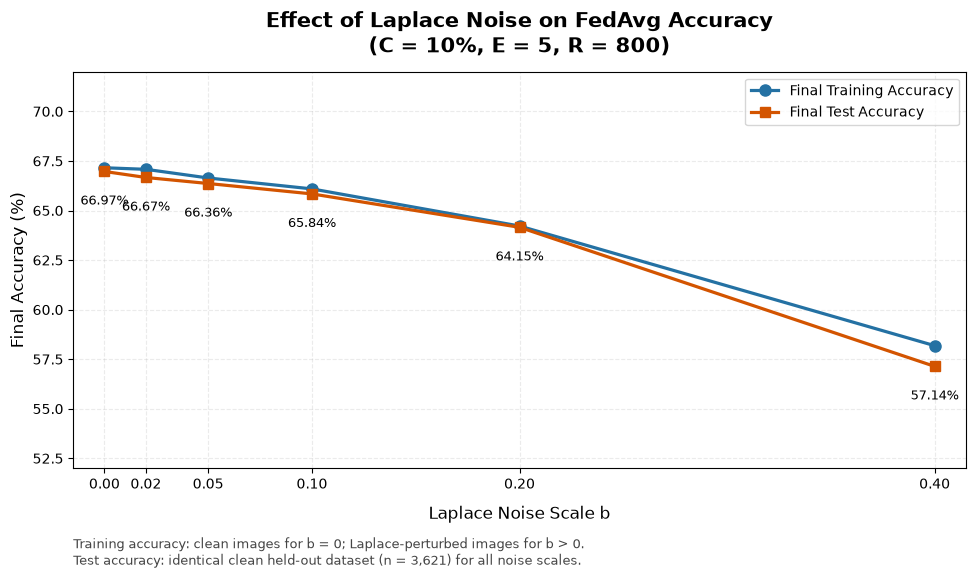

=== Step 3.5 Verification ===
Numeric noise-scale axis: PASSED
Original accuracy values: UNCHANGED
Legend moved to upper-right: YES
Notes placed below plotting area: YES
Figure saved: Output\Part2_Final_Accuracy_vs_Noise_Scale.png
No training or test reevaluation performed.

Part 2 Step 3.5 completed successfully.


In [64]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================================
# Part 2 - Step 3.5
# Refine final accuracy plot for the PDF report.
#
# Fix overlapping legend and explanatory text.
# Keep all experimental values unchanged.
# No training, no checkpoint loading, no test rerun.
# ==========================================================

output_dir = Path("Output")
results_path = (
    output_dir
    / "Part2_Laplace_FedAvg"
    / "final_test_accuracy_by_noise.csv"
)

figure_path = (
    output_dir
    / "Part2_Final_Accuracy_vs_Noise_Scale.png"
)

df = (
    pd.read_csv(results_path)
    .sort_values("noise_scale")
    .reset_index(drop=True)
)

expected_scales = np.array(
    [0.00, 0.02, 0.05, 0.10, 0.20, 0.40]
)

np.testing.assert_allclose(
    df["noise_scale"].to_numpy(),
    expected_scales,
    atol=1e-10,
    rtol=0
)

assert (df["round"] == 800).all()
assert (df["test_samples"] == 3621).all()

b = df["noise_scale"].to_numpy()
train_acc = df["final_train_accuracy"].to_numpy() * 100
test_acc = df["test_accuracy"].to_numpy() * 100

# ----------------------------------------------------------
# Create refined figure
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(10.5, 6.5))

fig.subplots_adjust(
    left=0.11,
    right=0.96,
    top=0.84,
    bottom=0.23
)

ax.plot(
    b, train_acc,
    color="#2471A3",
    marker="o",
    markersize=8,
    linewidth=2.3,
    label="Final Training Accuracy"
)

ax.plot(
    b, test_acc,
    color="#D35400",
    marker="s",
    markersize=7,
    linewidth=2.3,
    label="Final Test Accuracy"
)

# Annotate the six observed test accuracies.
for x, y in zip(b, test_acc):
    ax.annotate(
        f"{y:.2f}%",
        xy=(x, y),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=9
    )

ax.set_title(
    "Effect of Laplace Noise on FedAvg Accuracy\n"
    "(C = 10%, E = 5, R = 800)",
    fontsize=15,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Laplace Noise Scale b",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Final Accuracy (%)",
    fontsize=12
)

ax.set_xticks(b)
ax.set_xticklabels([f"{x:.2f}" for x in b])

ax.set_xlim(-0.015, 0.415)
ax.set_ylim(52, 72)

ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

# Move legend to the empty upper-right area.
ax.legend(
    loc="upper right",
    fontsize=10,
    frameon=True
)

# Place explanatory notes BELOW the plot, not inside it.
fig.text(
    0.11,
    0.075,
    "Training accuracy: clean images for b = 0; "
    "Laplace-perturbed images for b > 0.\n"
    "Test accuracy: identical clean held-out dataset "
    "(n = 3,621) for all noise scales.",
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

# Save the corrected image.
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert figure_path.exists()

print("=== Step 3.5 Verification ===")
print("Numeric noise-scale axis: PASSED")
print("Original accuracy values: UNCHANGED")
print("Legend moved to upper-right: YES")
print("Notes placed below plotting area: YES")
print("Figure saved:", figure_path)
print("No training or test reevaluation performed.")
print("\nPart 2 Step 3.5 completed successfully.")


In [6]:

import json
import numpy as np
import torch
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 4.1: Edge Cases
#
# Tests:
# 1. Zero-noise identity
# 2. Invalid noise scales
# 3. Out-of-range pixel values
# 4. Noise reproducibility
# 5. Extreme-noise numerical stability
# 6. Batch-size boundaries
#
# No global FedAvg training.
# No checkpoint loading.
# No held-out test evaluation.
# ==========================================================

OUT_DIR = Path("Output/Part2_Laplace_FedAvg")
OUT_DIR.mkdir(parents=True, exist_ok=True)

RESULT_PATH = OUT_DIR / "laplace_edge_cases.json"

assert "train_data" in globals()
assert "client_splits" in globals()
assert "FEMNISTMLP" in globals()
assert "make_perturbed_client_train" in globals()
assert "train_one_client_laplace" in globals()

CID = 25
SEED = 2026

saved_rng = torch.get_rng_state()
saved_threads = torch.get_num_threads()

results = {}

try:
    torch.set_num_threads(1)

    train_indices = np.asarray(
        client_splits[CID]["train_idx"],
        dtype=np.int64
    )

    original_images = np.asarray(
        [train_data[CID]["images"][int(i)]
         for i in train_indices],
        dtype=np.float32
    ).copy()

    original_labels = np.asarray(
        [train_data[CID]["labels"][int(i)]
         for i in train_indices],
        dtype=np.int64
    ).copy()

    n = len(original_labels)
    assert n == 94

    print("=== Part 2 Edge Cases ===")
    print("Client:", CID)
    print("Training samples:", n)
    print("CPU threads:", torch.get_num_threads())

    # ------------------------------------------------------
    # 1. Zero-noise identity
    # ------------------------------------------------------

    print("\n=== Edge Case 1: Zero Noise ===")

    images_zero, labels_zero = make_perturbed_client_train(
        CID, noise_scale=0.0, seed=SEED
    )

    zero_diff = float(
        np.max(np.abs(images_zero - original_images))
    )

    np.testing.assert_array_equal(
        labels_zero, original_labels
    )

    assert zero_diff == 0.0

    results["zero_noise"] = {
        "max_pixel_difference": zero_diff,
        "passed": True
    }

    print("Max pixel difference:", zero_diff)
    print("Labels unchanged: YES")
    print("Result: PASSED")

    # ------------------------------------------------------
    # 2. Invalid noise scales
    # ------------------------------------------------------

    print("\n=== Edge Case 2: Invalid Noise Scales ===")

    invalid_values = [
        -0.01,
        float("nan"),
        float("inf"),
        float("-inf")
    ]

    rejection_count = 0

    for bad_b in invalid_values:

        try:
            make_perturbed_client_train(
                CID, noise_scale=bad_b, seed=SEED
            )

        except ValueError:
            rejection_count += 1
            print(f"b={bad_b}: REJECTED")

        else:
            raise AssertionError(
                f"Invalid noise scale accepted: {bad_b}"
            )

    assert rejection_count == len(invalid_values)

    results["invalid_scales"] = {
        "tested": len(invalid_values),
        "rejected": rejection_count,
        "passed": True
    }

    print("Result: PASSED")

    # ------------------------------------------------------
    # 3. Out-of-range pixels: no clipping
    # ------------------------------------------------------

    print("\n=== Edge Case 3: No Pixel Clipping ===")

    images_04, labels_04 = make_perturbed_client_train(
        CID, noise_scale=0.4, seed=SEED
    )

    below_zero = int(np.count_nonzero(images_04 < 0))
    above_one = int(np.count_nonzero(images_04 > 1))

    outside_fraction = (
        below_zero + above_one
    ) / images_04.size

    assert below_zero > 0
    assert above_one > 0
    assert outside_fraction > 0

    np.testing.assert_array_equal(
        labels_04, original_labels
    )

    results["no_clipping"] = {
        "noise_scale": 0.4,
        "below_zero": below_zero,
        "above_one": above_one,
        "outside_fraction": outside_fraction,
        "passed": True
    }

    print("Pixels below 0:", below_zero)
    print("Pixels above 1:", above_one)
    print("Outside [0,1]:", f"{outside_fraction:.4%}")
    print("Result: PASSED")

    # ------------------------------------------------------
    # 4. Fixed-noise reproducibility
    # ------------------------------------------------------

    print("\n=== Edge Case 4: Reproducibility ===")

    noise_a, _ = make_perturbed_client_train(
        CID, noise_scale=0.2, seed=SEED
    )

    noise_b, _ = make_perturbed_client_train(
        CID, noise_scale=0.2, seed=SEED
    )

    noise_c, _ = make_perturbed_client_train(
        CID, noise_scale=0.2, seed=SEED + 1
    )

    same_seed_diff = float(
        np.max(np.abs(noise_a - noise_b))
    )

    different_seed_diff = float(
        np.max(np.abs(noise_a - noise_c))
    )

    assert same_seed_diff == 0.0
    assert different_seed_diff > 0.0

    results["reproducibility"] = {
        "same_seed_max_diff": same_seed_diff,
        "different_seed_max_diff": different_seed_diff,
        "passed": True
    }

    print(
        "Same-seed max difference:",
        f"{same_seed_diff:.10e}"
    )
    print(
        "Different-seed max difference:",
        f"{different_seed_diff:.10e}"
    )
    print("Result: PASSED")

    # ------------------------------------------------------
    # 5. Extreme-noise numerical stability
    # ------------------------------------------------------

    print("\n=== Edge Case 5: Extreme Noise Local SGD ===")

    torch.manual_seed(42)
    initial_model = FEMNISTMLP().cpu()

    initial_state = {
        k: v.detach().clone()
        for k, v in initial_model.state_dict().items()
    }

    extreme_records = []

    for b in [0.0, 0.4, 1.0, 2.0]:

        updated_state, count, mean_loss = (
            train_one_client_laplace(
                client_id=CID,
                global_state=initial_state,
                local_epochs=2,
                learning_rate=0.01,
                batch_size=32,
                round_id=0,
                noise_scale=b,
                noise_seed=SEED
            )
        )

        assert count == n
        assert np.isfinite(mean_loss)

        assert all(
            torch.isfinite(value).all().item()
            for value in updated_state.values()
        )

        update_norm_sq = sum(
            float(
                (
                    updated_state[k].double()
                    - initial_state[k].double()
                ).square().sum()
            )
            for k in initial_state
        )

        update_norm = float(np.sqrt(update_norm_sq))

        assert np.isfinite(update_norm)
        assert update_norm > 0

        extreme_records.append({
            "noise_scale": b,
            "mean_local_loss": float(mean_loss),
            "update_l2_norm": update_norm,
            "parameters_finite": True
        })

        print(
            f"b={b:.2f} | "
            f"Loss={mean_loss:.6f} | "
            f"Update L2={update_norm:.6f} | "
            f"Finite=YES"
        )

    results["extreme_noise"] = {
        "experiments": extreme_records,
        "passed": True
    }

    # ------------------------------------------------------
    # 6. Boundary batch sizes
    # ------------------------------------------------------

    print("\n=== Edge Case 6: Batch Size Boundaries ===")

    batch_records = []

    for batch_size in [32, 128, 1]:

        updated_state, count, mean_loss = (
            train_one_client_laplace(
                client_id=CID,
                global_state=initial_state,
                local_epochs=1,
                learning_rate=0.01,
                batch_size=batch_size,
                round_id=0,
                noise_scale=0.1,
                noise_seed=SEED
            )
        )

        expected_steps = (
            n + batch_size - 1
        ) // batch_size

        assert count == n
        assert np.isfinite(mean_loss)

        assert all(
            torch.isfinite(value).all().item()
            for value in updated_state.values()
        )

        batch_records.append({
            "batch_size": batch_size,
            "expected_steps": expected_steps,
            "mean_local_loss": float(mean_loss)
        })

        print(
            f"Batch={batch_size:3d} | "
            f"Samples={count:3d} | "
            f"Steps={expected_steps:3d} | "
            f"Loss={mean_loss:.6f} | PASSED"
        )

    results["batch_boundaries"] = {
        "experiments": batch_records,
        "passed": True
    }

    # ------------------------------------------------------
    # 7. Verify original training data unchanged
    # ------------------------------------------------------

    current_images = np.asarray(
        [train_data[CID]["images"][int(i)]
         for i in train_indices],
        dtype=np.float32
    )

    current_labels = np.asarray(
        [train_data[CID]["labels"][int(i)]
         for i in train_indices],
        dtype=np.int64
    )

    np.testing.assert_array_equal(
        original_images, current_images
    )

    np.testing.assert_array_equal(
        original_labels, current_labels
    )

    # ------------------------------------------------------
    # 8. Save evidence
    # ------------------------------------------------------

    summary = {
        "experiment": "Part 2 Edge Cases",
        "client_id": CID,
        "training_samples": n,
        "edge_cases": results,
        "all_passed": True,
        "original_client_data_unchanged": True,
        "full_fedavg_training_performed": False,
        "held_out_test_accessed": False
    }

    with open(
        RESULT_PATH, "w", encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Step 4.1 Summary ===")

    for name, result in results.items():
        print(
            f"{name}: "
            f"{'PASSED' if result['passed'] else 'FAILED'}"
        )

    print("Original training data unchanged: PASSED")
    print("Held-out test dataset accessed: NO")
    print("Checkpoints modified: NO")
    print("Evidence saved:", RESULT_PATH)

finally:
    torch.set_num_threads(saved_threads)
    torch.set_rng_state(saved_rng)

print("\nPart 2 Step 4.1 completed successfully.")


=== Part 2 Edge Cases ===
Client: 25
Training samples: 94
CPU threads: 1

=== Edge Case 1: Zero Noise ===
Max pixel difference: 0.0
Labels unchanged: YES
Result: PASSED

=== Edge Case 2: Invalid Noise Scales ===
b=-0.01: REJECTED
b=nan: REJECTED
b=inf: REJECTED
b=-inf: REJECTED
Result: PASSED

=== Edge Case 3: No Pixel Clipping ===
Pixels below 0: 5323
Pixels above 1: 33793
Outside [0,1]: 53.0775%
Result: PASSED

=== Edge Case 4: Reproducibility ===
Same-seed max difference: 0.0000000000e+00
Different-seed max difference: 2.6559777260e+00
Result: PASSED

=== Edge Case 5: Extreme Noise Local SGD ===
b=0.00 | Loss=4.107654 | Update L2=0.099676 | Finite=YES
b=0.40 | Loss=4.113650 | Update L2=0.105528 | Finite=YES
b=1.00 | Loss=4.114487 | Update L2=0.141561 | Finite=YES
b=2.00 | Loss=4.099520 | Update L2=0.234847 | Finite=YES

=== Edge Case 6: Batch Size Boundaries ===
Batch= 32 | Samples= 94 | Steps=  3 | Loss=4.153431 | PASSED
Batch=128 | Samples= 94 | Steps=  1 | Loss=4.167101 | PASSED


In [1]:

import gc
import json
import numpy as np
from pathlib import Path

# ==========================================================
# Part 2 - Step 4.2.1A
# Lightweight Laplace Statistical Validation
#
# Independent of previous notebook variables.
# Only one client and one noise scale.
# Avoid large concatenations and model loading.
#
# No training.
# No checkpoint loading.
# No test-set access.
# ==========================================================

CLIENT_ID = 25
NOISE_SCALE = 0.10
NOISE_SEED = 2026

OUTPUT_DIR = Path("Output/Part2_Laplace_FedAvg")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESULT_PATH = (
    OUTPUT_DIR / "laplace_statistical_smoke_b0.10.json"
)

print("=== Lightweight Laplace Statistical Validation ===")

# ----------------------------------------------------------
# 1. Restore data if the kernel was restarted
# ----------------------------------------------------------

if "train_data" not in globals():
    train_data = np.load(
        "train_data.npy",
        allow_pickle=True
    )

assert len(train_data) == 100

if "client_splits" not in globals():

    client_splits = {}

    for cid in range(100):

        n = len(train_data[cid]["labels"])

        rng = np.random.default_rng(42 + cid)

        indices = rng.permutation(n)

        n_train = int(0.8 * n)

        client_splits[cid] = {
            "train_idx": indices[:n_train],
            "val_idx": indices[n_train:]
        }

print("Training data: READY")
print("Client splits: READY")

# ----------------------------------------------------------
# 2. Restore the original Laplace noise function
# ----------------------------------------------------------

if "make_perturbed_client_train" not in globals():

    def make_perturbed_client_train(
        client_id,
        noise_scale,
        seed=2026
    ):

        cid = int(client_id)
        b = float(noise_scale)

        if not np.isfinite(b) or b < 0:
            raise ValueError("Invalid noise scale.")

        indices = np.asarray(
            client_splits[cid]["train_idx"],
            dtype=np.int64
        )

        clean = np.asarray(
            [
                train_data[cid]["images"][int(i)]
                for i in indices
            ],
            dtype=np.float32
        )

        labels = np.asarray(
            [
                train_data[cid]["labels"][int(i)]
                for i in indices
            ],
            dtype=np.int64
        )

        rng = np.random.default_rng(
            np.random.SeedSequence(
                [int(seed), cid]
            )
        )

        if b == 0.0:
            noisy = clean.copy()
        else:
            noise = rng.laplace(
                loc=0.0,
                scale=b,
                size=clean.shape
            ).astype(np.float32)

            noisy = clean + noise

        return np.ascontiguousarray(noisy), labels.copy()

# ----------------------------------------------------------
# 3. Generate a small amount of actual training noise
# ----------------------------------------------------------

clean_images, clean_labels = (
    make_perturbed_client_train(
        CLIENT_ID,
        noise_scale=0.0,
        seed=NOISE_SEED
    )
)

noisy_images, noisy_labels = (
    make_perturbed_client_train(
        CLIENT_ID,
        noise_scale=NOISE_SCALE,
        seed=NOISE_SEED
    )
)

assert len(clean_labels) == 94

np.testing.assert_array_equal(
    clean_labels,
    noisy_labels
)

# Standardized noise Z = (X' - X) / b
# Calculations use float64 for statistical precision.

z = (
    noisy_images.astype(np.float64)
    - clean_images.astype(np.float64)
) / NOISE_SCALE

assert z.shape == (94, 28, 28)
assert np.isfinite(z).all()

print("Client:", CLIENT_ID)
print("Training images:", len(clean_labels))
print("Pixel samples:", z.size)
print("Noise scale:", NOISE_SCALE)

# ----------------------------------------------------------
# 4. Check theoretical Laplace properties
# ----------------------------------------------------------

empirical_mean = float(np.mean(z))
empirical_abs_mean = float(np.mean(np.abs(z)))
empirical_variance = float(np.var(z))
empirical_tail = float(np.mean(np.abs(z) > 2))

expected_tail = float(np.exp(-2))

print("\n=== Laplace Distribution Statistics ===")

print(
    f"Mean(Z): {empirical_mean:+.6f} "
    f"| Expected: 0.000000"
)

print(
    f"Mean(|Z|): {empirical_abs_mean:.6f} "
    f"| Expected: 1.000000"
)

print(
    f"Var(Z): {empirical_variance:.6f} "
    f"| Expected: 2.000000"
)

print(
    f"P(|Z| > 2): {empirical_tail:.6f} "
    f"| Expected: {expected_tail:.6f}"
)

assert abs(empirical_mean) < 0.03
assert abs(empirical_abs_mean - 1.0) < 0.03
assert abs(empirical_variance - 2.0) / 2.0 < 0.07
assert abs(empirical_tail - expected_tail) < 0.015

print("Distribution moment checks: PASSED")
print("Exponential tail check: PASSED")

# ----------------------------------------------------------
# 5. Lightweight correlation checks
# ----------------------------------------------------------

# Horizontal neighboring pixels.
horizontal_corr = float(
    np.corrcoef(
        z[:, :, :-1].ravel(),
        z[:, :, 1:].ravel()
    )[0, 1]
)

# Same pixel location in consecutive images.
image_corr = float(
    np.corrcoef(
        z[:-1].ravel(),
        z[1:].ravel()
    )[0, 1]
)

print("\n=== Noise Correlation Checks ===")

print(
    "Horizontal pixel correlation:",
    f"{horizontal_corr:+.6f}"
)

print(
    "Across-image correlation:",
    f"{image_corr:+.6f}"
)

assert abs(horizontal_corr) < 0.04
assert abs(image_corr) < 0.04

print("Empirical correlation checks: PASSED")

# ----------------------------------------------------------
# 6. Save a small diagnostic JSON file
# ----------------------------------------------------------

summary = {
    "client_id": CLIENT_ID,
    "noise_scale": NOISE_SCALE,
    "pixel_samples": int(z.size),
    "mean": empirical_mean,
    "mean_absolute": empirical_abs_mean,
    "variance": empirical_variance,
    "tail_probability": empirical_tail,
    "expected_tail_probability": expected_tail,
    "horizontal_correlation": horizontal_corr,
    "across_image_correlation": image_corr,
    "passed": True,
    "training_performed": False,
    "test_set_accessed": False
}

with open(RESULT_PATH, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

# Release temporary statistical arrays.
del z, clean_images, noisy_images
gc.collect()

print("\n=== Step 4.2.1A Summary ===")
print("Small-sample statistical validation: PASSED")
print("Laplace moments: PASSED")
print("Exponential tail probability: PASSED")
print("Sample correlation checks: PASSED")
print("Temporary arrays released: YES")
print("Training performed: NO")
print("Checkpoint loading: NO")
print("Held-out test accessed: NO")
print("Results saved:", RESULT_PATH)

print("\nStep 4.2.1A completed successfully.")


=== Lightweight Laplace Statistical Validation ===
Training data: READY
Client splits: READY
Client: 25
Training images: 94
Pixel samples: 73696
Noise scale: 0.1

=== Laplace Distribution Statistics ===
Mean(Z): +0.000794 | Expected: 0.000000
Mean(|Z|): 0.994903 | Expected: 1.000000
Var(Z): 1.979670 | Expected: 2.000000
P(|Z| > 2): 0.134824 | Expected: 0.135335
Distribution moment checks: PASSED
Exponential tail check: PASSED

=== Noise Correlation Checks ===
Horizontal pixel correlation: -0.000048
Across-image correlation: +0.002705
Empirical correlation checks: PASSED

=== Step 4.2.1A Summary ===
Small-sample statistical validation: PASSED
Laplace moments: PASSED
Exponential tail probability: PASSED
Sample correlation checks: PASSED
Temporary arrays released: YES
Training performed: NO
Checkpoint loading: NO
Held-out test accessed: NO
Results saved: Output\Part2_Laplace_FedAvg\laplace_statistical_smoke_b0.10.json

Step 4.2.1A completed successfully.


In [2]:

import gc
import csv
import json
import numpy as np
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 4.2.1B: Cross-Scale Laplace Validation
#
# One client, three noise scales.
# Process one scale at a time to limit memory use.
#
# No training.
# No checkpoint loading.
# No held-out test access.
# ==========================================================

assert "make_perturbed_client_train" in globals()
assert "client_splits" in globals()

CID = 25
SEED = 2026
SCALES = [0.02, 0.10, 0.40]

OUT_DIR = Path("Output/Part2_Laplace_FedAvg")
OUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = OUT_DIR / "laplace_statistical_validation.csv"
JSON_PATH = OUT_DIR / "laplace_statistical_validation.json"

# ----------------------------------------------------------
# 1. Load the clean reference once
# ----------------------------------------------------------

clean, clean_labels = make_perturbed_client_train(
    client_id=CID,
    noise_scale=0.0,
    seed=SEED
)

assert clean.shape == (94, 28, 28)

expected_tail = float(np.exp(-2.0))
records = []

print("=== Cross-Scale Laplace Validation ===")
print("Client:", CID)
print("Training images:", len(clean_labels))
print("Pixel samples per scale:", clean.size)

# ----------------------------------------------------------
# 2. Process noise scales sequentially
# ----------------------------------------------------------

for b in SCALES:

    noisy, labels = make_perturbed_client_train(
        client_id=CID,
        noise_scale=b,
        seed=SEED
    )

    np.testing.assert_array_equal(
        labels, clean_labels
    )

    # Small float64 array for accurate statistics.
    z = (
        noisy.astype(np.float64)
        - clean.astype(np.float64)
    ) / b

    assert np.isfinite(z).all()

    mean_z = float(np.mean(z))
    mean_abs_z = float(np.mean(np.abs(z)))
    variance_z = float(np.var(z))
    tail_probability = float(
        np.mean(np.abs(z) > 2.0)
    )

    # Same lightweight correlation checks
    # as the successful Step 4.2.1A.
    horizontal_corr = float(
        np.corrcoef(
            z[:, :, :-1].ravel(),
            z[:, :, 1:].ravel()
        )[0, 1]
    )

    image_corr = float(
        np.corrcoef(
            z[:-1].ravel(),
            z[1:].ravel()
        )[0, 1]
    )

    # Actual unstandardized noise statistics.
    empirical_mean_abs_noise = b * mean_abs_z
    empirical_noise_variance = b * b * variance_z

    # ------------------------------------------------------
    # 3. Apply pre-specified acceptance criteria
    # ------------------------------------------------------

    passed = all([
        abs(mean_z) < 0.03,
        abs(mean_abs_z - 1.0) < 0.03,
        abs(variance_z - 2.0) / 2.0 < 0.07,
        abs(tail_probability - expected_tail) < 0.015,
        abs(horizontal_corr) < 0.04,
        abs(image_corr) < 0.04
    ])

    record = {
        "noise_scale": b,
        "pixel_samples": int(z.size),
        "standardized_mean": mean_z,
        "standardized_mean_abs": mean_abs_z,
        "standardized_variance": variance_z,
        "tail_probability": tail_probability,
        "horizontal_correlation": horizontal_corr,
        "across_image_correlation": image_corr,
        "actual_mean_abs_noise": empirical_mean_abs_noise,
        "theoretical_mean_abs_noise": b,
        "actual_noise_variance": empirical_noise_variance,
        "theoretical_noise_variance": 2.0 * b * b,
        "passed": passed
    }

    records.append(record)

    print(f"\n=== Noise Scale b={b:.2f} ===")
    print(f"Mean(Z):       {mean_z:+.6f}")
    print(f"Mean(|Z|):     {mean_abs_z:.6f}")
    print(f"Var(Z):        {variance_z:.6f}")
    print(f"P(|Z| > 2):    {tail_probability:.6f}")
    print(f"Horizontal r:  {horizontal_corr:+.6f}")
    print(f"Across-image r:{image_corr:+.6f}")

    print(
        "Mean(|noise|):",
        f"{empirical_mean_abs_noise:.6f}",
        "| Expected:",
        f"{b:.6f}"
    )

    print(
        "Var(noise):",
        f"{empirical_noise_variance:.6f}",
        "| Expected:",
        f"{2.0 * b * b:.6f}"
    )

    print("Result:", "PASSED" if passed else "FAILED")

    assert passed, (
        f"Laplace validation failed for b={b}"
    )

    # Release temporary arrays before next scale.
    del noisy, labels, z
    gc.collect()

# ----------------------------------------------------------
# 4. Save compact evidence
# ----------------------------------------------------------

assert len(records) == 3
assert all(r["passed"] for r in records)

with open(CSV_PATH, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(records[0].keys())
    )
    writer.writeheader()
    writer.writerows(records)

summary = {
    "experiment": "Cross-Scale Laplace Validation",
    "client_id": CID,
    "noise_seed": SEED,
    "noise_scales": SCALES,
    "pixels_per_scale": int(clean.size),
    "records": records,
    "all_passed": True,
    "full_fedavg_training_performed": False,
    "held_out_test_accessed": False
}

with open(JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

del clean, clean_labels
gc.collect()

# ----------------------------------------------------------
# 5. Summary
# ----------------------------------------------------------

print("\n=== Step 4.2.1B Summary ===")

for r in records:
    print(
        f"b={r['noise_scale']:.2f} | "
        f"MeanAbs={r['standardized_mean_abs']:.6f} | "
        f"Variance={r['standardized_variance']:.6f} | "
        f"Tail={r['tail_probability']:.6f} | PASSED"
    )

print("\nAll three noise scales: PASSED")
print("Theoretical scale calibration: PASSED")
print("Pixel correlation checks: PASSED")
print("Temporary arrays released: YES")
print("Full FedAvg training: NOT PERFORMED")
print("Held-out test accessed: NO")
print("CSV saved:", CSV_PATH)
print("JSON saved:", JSON_PATH)

print("\nStep 4.2.1B completed successfully.")


=== Cross-Scale Laplace Validation ===
Client: 25
Training images: 94
Pixel samples per scale: 73696

=== Noise Scale b=0.02 ===
Mean(Z):       +0.000794
Mean(|Z|):     0.994903
Var(Z):        1.979670
P(|Z| > 2):    0.134824
Horizontal r:  -0.000048
Across-image r:+0.002705
Mean(|noise|): 0.019898 | Expected: 0.020000
Var(noise): 0.000792 | Expected: 0.000800
Result: PASSED

=== Noise Scale b=0.10 ===
Mean(Z):       +0.000794
Mean(|Z|):     0.994903
Var(Z):        1.979670
P(|Z| > 2):    0.134824
Horizontal r:  -0.000048
Across-image r:+0.002705
Mean(|noise|): 0.099490 | Expected: 0.100000
Var(noise): 0.019797 | Expected: 0.020000
Result: PASSED

=== Noise Scale b=0.40 ===
Mean(Z):       +0.000794
Mean(|Z|):     0.994903
Var(Z):        1.979670
P(|Z| > 2):    0.134824
Horizontal r:  -0.000048
Across-image r:+0.002705
Mean(|noise|): 0.397961 | Expected: 0.400000
Var(noise): 0.316747 | Expected: 0.320000
Result: PASSED

=== Step 4.2.1B Summary ===
b=0.02 | MeanAbs=0.994903 | Variance=1.

In [4]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ==========================================================
# Part 2 - Step 4.2.2A
# Restore model and Local SGD after Kernel restart
#
# No global FedAvg training.
# No checkpoint loading.
# No held-out test access.
# ==========================================================

assert "train_data" in globals()
assert "client_splits" in globals()
assert "make_perturbed_client_train" in globals()

# ----------------------------------------------------------
# 1. Restore FEMNISTMLP
# ----------------------------------------------------------

class FEMNISTMLP(nn.Module):

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 62)

    def forward(self, x):
        x = x.reshape(x.shape[0], 784)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


# ----------------------------------------------------------
# 2. Restore Laplace Local SGD
# ----------------------------------------------------------

def train_one_client_laplace(
    client_id,
    global_state,
    local_epochs=5,
    learning_rate=0.01,
    batch_size=32,
    round_id=0,
    noise_scale=0.1,
    noise_seed=2026
):

    cid = int(client_id)

    assert local_epochs >= 1
    assert learning_rate > 0
    assert batch_size >= 1

    images_np, labels_np = make_perturbed_client_train(
        client_id=cid,
        noise_scale=noise_scale,
        seed=noise_seed
    )

    n_samples = len(labels_np)

    images = torch.from_numpy(
        np.ascontiguousarray(images_np)
    )

    labels = torch.from_numpy(
        np.asarray(labels_np, dtype=np.int64)
    )

    local_model = FEMNISTMLP().cpu()
    local_model.load_state_dict(global_state)
    local_model.train()

    optimizer = torch.optim.SGD(
        local_model.parameters(),
        lr=learning_rate
    )

    generator = torch.Generator()
    generator.manual_seed(
        42 + round_id * 1000 + cid
    )

    total_loss = 0.0
    total_processed = 0

    for epoch in range(local_epochs):

        permutation = torch.randperm(
            n_samples,
            generator=generator
        )

        for start in range(0, n_samples, batch_size):

            idx = permutation[
                start:start + batch_size
            ]

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = local_model(images[idx])

            loss = F.cross_entropy(
                logits,
                labels[idx]
            )

            loss.backward()
            optimizer.step()

            total_loss += (
                float(loss.item()) * len(idx)
            )
            total_processed += len(idx)

    assert total_processed == n_samples * local_epochs

    updated_state = {
        k: v.detach().cpu().clone()
        for k, v in local_model.state_dict().items()
    }

    mean_loss = total_loss / total_processed

    assert np.isfinite(mean_loss)
    assert all(
        torch.isfinite(v).all().item()
        for v in updated_state.values()
    )

    return updated_state, n_samples, mean_loss


# ----------------------------------------------------------
# 3. Verify restored functions
# ----------------------------------------------------------

print("=== Part 2 Function Recovery ===")

previous_rng = torch.get_rng_state()
previous_threads = torch.get_num_threads()

try:
    torch.set_num_threads(1)

    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)

        model = FEMNISTMLP().cpu()

        initial_state = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }

    num_parameters = sum(
        p.numel() for p in model.parameters()
    )

    assert num_parameters == 108478

    updated_state, n_samples, mean_loss = (
        train_one_client_laplace(
            client_id=25,
            global_state=initial_state,
            local_epochs=1,
            learning_rate=0.01,
            batch_size=32,
            round_id=0,
            noise_scale=0.0
        )
    )

    assert n_samples == 94

    print("FEMNISTMLP: READY")
    print("Model parameters:", num_parameters)
    print("train_one_client_laplace: READY")
    print("Client:", 25)
    print("Training samples:", n_samples)
    print("Smoke-test local epochs:", 1)
    print("Local loss:", f"{mean_loss:.6f}")
    print("Finite parameters: PASSED")

finally:
    torch.set_num_threads(previous_threads)
    torch.set_rng_state(previous_rng)

print("\n=== Recovery Summary ===")

required = [
    "train_data",
    "client_splits",
    "FEMNISTMLP",
    "make_perturbed_client_train",
    "train_one_client_laplace"
]

for name in required:
    print(
        f"{name}: "
        f"{'READY' if name in globals() else 'MISSING'}"
    )

assert all(name in globals() for name in required)

print("\nEnvironment recovery: PASSED")
print("Full FedAvg training: NOT PERFORMED")
print("Original checkpoints: UNCHANGED")
print("Held-out test accessed: NO")


=== Part 2 Function Recovery ===
FEMNISTMLP: READY
Model parameters: 108478
train_one_client_laplace: READY
Client: 25
Training samples: 94
Smoke-test local epochs: 1
Local loss: 4.152938
Finite parameters: PASSED

=== Recovery Summary ===
train_data: READY
client_splits: READY
FEMNISTMLP: READY
make_perturbed_client_train: READY
train_one_client_laplace: READY

Environment recovery: PASSED
Full FedAvg training: NOT PERFORMED
Original checkpoints: UNCHANGED
Held-out test accessed: NO


In [5]:

import gc
import json
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 4.2.2: Zero-Noise Algorithmic Equivalence
#
# Compare:
# 1. Independent clean-input SGD reference
# 2. Laplace SGD with b=0
# 3. Laplace SGD with b=0.1
#
# Three clients, two local epochs only.
#
# No global FedAvg training.
# No checkpoint loading.
# No held-out test access.
# ==========================================================

assert "train_data" in globals()
assert "client_splits" in globals()
assert "FEMNISTMLP" in globals()
assert "train_one_client_laplace" in globals()

OUT_DIR = Path("Output/Part2_Laplace_FedAvg")
OUT_DIR.mkdir(parents=True, exist_ok=True)

RESULT_PATH = (
    OUT_DIR / "zero_noise_equivalence.json"
)

CLIENT_IDS = [0, 25, 67]

LOCAL_EPOCHS = 2
LEARNING_RATE = 0.01
BATCH_SIZE = 32
ROUND_ID = 0
NOISE_SEED = 2026

# ----------------------------------------------------------
# 1. Independent clean SGD reference
# ----------------------------------------------------------

def independent_clean_sgd(
    client_id,
    global_state,
    local_epochs=2,
    learning_rate=0.01,
    batch_size=32,
    round_id=0
):
    cid = int(client_id)

    train_idx = np.asarray(
        client_splits[cid]["train_idx"],
        dtype=np.int64
    )

    # Read original images directly.
    # Do not call the Laplace noise function.
    images = np.asarray(
        [
            train_data[cid]["images"][int(i)]
            for i in train_idx
        ],
        dtype=np.float32
    )

    labels = np.asarray(
        [
            train_data[cid]["labels"][int(i)]
            for i in train_idx
        ],
        dtype=np.int64
    )

    x = torch.from_numpy(images)
    y = torch.from_numpy(labels)

    n = len(labels)

    reference_model = FEMNISTMLP().cpu()
    reference_model.load_state_dict(global_state)
    reference_model.train()

    optimizer = torch.optim.SGD(
        reference_model.parameters(),
        lr=learning_rate
    )

    generator = torch.Generator()
    generator.manual_seed(
        42 + round_id * 1000 + cid
    )

    total_loss = 0.0
    processed = 0

    for epoch in range(local_epochs):

        permutation = torch.randperm(
            n,
            generator=generator
        )

        for start in range(0, n, batch_size):

            idx = permutation[
                start:start + batch_size
            ]

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = reference_model(x[idx])

            loss = F.cross_entropy(
                logits,
                y[idx]
            )

            loss.backward()
            optimizer.step()

            total_loss += (
                float(loss.item()) * len(idx)
            )

            processed += len(idx)

    assert processed == n * local_epochs

    state = {
        k: v.detach().cpu().clone()
        for k, v in reference_model.state_dict().items()
    }

    mean_loss = total_loss / processed

    return state, n, mean_loss


# ----------------------------------------------------------
# 2. Save computational settings
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()
saved_threads = torch.get_num_threads()

records = []

try:
    torch.set_num_threads(1)

    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)

        initial_model = FEMNISTMLP().cpu()

        initial_state = {
            k: v.detach().clone()
            for k, v in initial_model.state_dict().items()
        }

    print("=== Zero-Noise SGD Equivalence ===")
    print("Clients:", CLIENT_IDS)
    print("Local epochs:", LOCAL_EPOCHS)
    print("Learning rate:", LEARNING_RATE)
    print("Batch size:", BATCH_SIZE)
    print("CPU threads:", torch.get_num_threads())

    # ------------------------------------------------------
    # 3. Compare clients independently
    # ------------------------------------------------------

    for cid in CLIENT_IDS:

        print(f"\n=== Client {cid} ===")

        # Independent reference without noise code.
        state_ref, n_ref, loss_ref = (
            independent_clean_sgd(
                client_id=cid,
                global_state=initial_state,
                local_epochs=LOCAL_EPOCHS,
                learning_rate=LEARNING_RATE,
                batch_size=BATCH_SIZE,
                round_id=ROUND_ID
            )
        )

        # Part 2 implementation with b=0.
        state_zero, n_zero, loss_zero = (
            train_one_client_laplace(
                client_id=cid,
                global_state=initial_state,
                local_epochs=LOCAL_EPOCHS,
                learning_rate=LEARNING_RATE,
                batch_size=BATCH_SIZE,
                round_id=ROUND_ID,
                noise_scale=0.0,
                noise_seed=NOISE_SEED
            )
        )

        # Part 2 implementation with b=0.1.
        state_noisy, n_noisy, loss_noisy = (
            train_one_client_laplace(
                client_id=cid,
                global_state=initial_state,
                local_epochs=LOCAL_EPOCHS,
                learning_rate=LEARNING_RATE,
                batch_size=BATCH_SIZE,
                round_id=ROUND_ID,
                noise_scale=0.1,
                noise_seed=NOISE_SEED
            )
        )

        assert n_ref == n_zero == n_noisy

        # --------------------------------------------------
        # 4. Maximum parameter differences
        # --------------------------------------------------

        max_zero_diff = max(
            float(
                (
                    state_ref[k].double()
                    - state_zero[k].double()
                ).abs().max()
            )
            for k in state_ref
        )

        max_noisy_diff = max(
            float(
                (
                    state_ref[k].double()
                    - state_noisy[k].double()
                ).abs().max()
            )
            for k in state_ref
        )

        # Euclidean distance between model parameters.
        zero_norm = float(np.sqrt(sum(
            float(
                (
                    state_ref[k].double()
                    - state_zero[k].double()
                ).square().sum()
            )
            for k in state_ref
        )))

        noisy_norm = float(np.sqrt(sum(
            float(
                (
                    state_ref[k].double()
                    - state_noisy[k].double()
                ).square().sum()
            )
            for k in state_ref
        )))

        loss_difference = abs(
            loss_ref - loss_zero
        )

        # Exact zero-noise agreement is expected
        # under deterministic CPU execution.
        assert max_zero_diff == 0.0
        assert zero_norm == 0.0
        assert loss_difference == 0.0

        # Positive noise must affect the update.
        assert max_noisy_diff > 0.0
        assert noisy_norm > 0.0

        assert np.isfinite(loss_noisy)

        print("Training samples:", n_ref)

        print(
            "Clean reference loss:",
            f"{loss_ref:.8f}"
        )

        print(
            "Laplace b=0 loss:",
            f"{loss_zero:.8f}"
        )

        print(
            "Laplace b=0.1 loss:",
            f"{loss_noisy:.8f}"
        )

        print(
            "Max parameter difference (b=0):",
            f"{max_zero_diff:.12e}"
        )

        print(
            "Parameter L2 difference (b=0):",
            f"{zero_norm:.12e}"
        )

        print(
            "Max parameter difference (b=0.1):",
            f"{max_noisy_diff:.12e}"
        )

        print(
            "Parameter L2 difference (b=0.1):",
            f"{noisy_norm:.12e}"
        )

        print("Zero-noise equivalence: PASSED")
        print("Nonzero-noise effect: PASSED")

        records.append({
            "client_id": cid,
            "training_samples": n_ref,
            "reference_loss": float(loss_ref),
            "zero_noise_loss": float(loss_zero),
            "positive_noise_loss": float(loss_noisy),
            "zero_noise_max_parameter_diff":
                max_zero_diff,
            "zero_noise_parameter_l2_diff":
                zero_norm,
            "positive_noise_max_parameter_diff":
                max_noisy_diff,
            "positive_noise_parameter_l2_diff":
                noisy_norm,
            "zero_noise_equivalence_passed": True,
            "positive_noise_effect_passed": True
        })

        # Release client-specific model states.
        del state_ref, state_zero, state_noisy
        gc.collect()

    # ------------------------------------------------------
    # 5. Save evidence
    # ------------------------------------------------------

    summary = {
        "experiment": "Zero-Noise SGD Equivalence",
        "clients": CLIENT_IDS,
        "local_epochs": LOCAL_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "round_id": ROUND_ID,
        "noise_seed": NOISE_SEED,
        "records": records,
        "all_passed": True,
        "global_fedavg_training_performed": False,
        "checkpoint_loading_performed": False,
        "held_out_test_accessed": False
    }

    with open(
        RESULT_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Step 4.2.2 Summary ===")

    for record in records:
        print(
            f"Client {record['client_id']:2d} | "
            f"Samples={record['training_samples']:3d} | "
            f"b=0 MaxDiff="
            f"{record['zero_noise_max_parameter_diff']:.3e} | "
            f"b=0.1 MaxDiff="
            f"{record['positive_noise_max_parameter_diff']:.3e}"
        )

    assert len(records) == 3

    print("\nZero-noise algorithmic equivalence: PASSED")
    print("Positive-noise parameter effect: PASSED")
    print("All three clients verified: YES")
    print("Full FedAvg training: NOT PERFORMED")
    print("Checkpoint loading: NO")
    print("Held-out test accessed: NO")
    print("Evidence saved:", RESULT_PATH)

finally:
    torch.set_num_threads(saved_threads)
    torch.set_rng_state(saved_rng)

print("\nStep 4.2.2 completed successfully.")


=== Zero-Noise SGD Equivalence ===
Clients: [0, 25, 67]
Local epochs: 2
Learning rate: 0.01
Batch size: 32
CPU threads: 1

=== Client 0 ===
Training samples: 275
Clean reference loss: 4.02189235
Laplace b=0 loss: 4.02189235
Laplace b=0.1 loss: 4.02283460
Max parameter difference (b=0): 0.000000000000e+00
Parameter L2 difference (b=0): 0.000000000000e+00
Max parameter difference (b=0.1): 1.369169796817e-03
Parameter L2 difference (b=0.1): 3.731744209562e-02
Zero-noise equivalence: PASSED
Nonzero-noise effect: PASSED

=== Client 25 ===
Training samples: 94
Clean reference loss: 4.10765376
Laplace b=0 loss: 4.10765376
Laplace b=0.1 loss: 4.10746006
Max parameter difference (b=0): 0.000000000000e+00
Parameter L2 difference (b=0): 0.000000000000e+00
Max parameter difference (b=0.1): 5.510412156582e-04
Parameter L2 difference (b=0.1): 1.977436431998e-02
Zero-noise equivalence: PASSED
Nonzero-noise effect: PASSED

=== Client 67 ===
Training samples: 314
Clean reference loss: 3.99834204
Laplac

In [6]:

import gc
import json
import numpy as np
import torch
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 4.2.3
# Controlled FedAvg Aggregation Validation
#
# Tests:
# 1. Sample-weighted aggregation
# 2. Independent NumPy reference
# 3. Client-order invariance
# 4. Weighted vs. unweighted aggregation
# 5. Propagation of Laplace noise to global updates
#
# No 800-round training.
# No checkpoint loading.
# No held-out test evaluation.
# ==========================================================

assert "FEMNISTMLP" in globals()
assert "train_one_client_laplace" in globals()
assert "client_splits" in globals()

CLIENT_IDS = [0, 25, 67]
NOISE_SCALES = [0.0, 0.1, 0.4]

LOCAL_EPOCHS = 2
LEARNING_RATE = 0.01
BATCH_SIZE = 32
ROUND_ID = 0
NOISE_SEED = 2026

OUT_DIR = Path("Output/Part2_Laplace_FedAvg")
OUT_DIR.mkdir(parents=True, exist_ok=True)

RESULT_PATH = (
    OUT_DIR / "fedavg_aggregation_noise_validation.json"
)

# ----------------------------------------------------------
# 1. Sample-weighted FedAvg aggregation
# ----------------------------------------------------------

def controlled_weighted_fedavg(
    states,
    sample_counts
):
    total = int(sum(sample_counts))
    assert total > 0
    assert len(states) == len(sample_counts)

    aggregated = {}

    for key in states[0]:

        accumulator = torch.zeros_like(
            states[0][key],
            dtype=torch.float64
        )

        for state, count in zip(
            states, sample_counts
        ):
            accumulator += (
                state[key].double() * int(count)
            )

        aggregated[key] = (
            accumulator / total
        ).to(dtype=states[0][key].dtype)

    return aggregated


def max_state_difference(state_a, state_b):
    return max(
        float(
            (
                state_a[k].double()
                - state_b[k].double()
            ).abs().max()
        )
        for k in state_a
    )


def state_l2_difference(state_a, state_b):
    return float(np.sqrt(sum(
        float(
            (
                state_a[k].double()
                - state_b[k].double()
            ).square().sum()
        )
        for k in state_a
    )))


# ----------------------------------------------------------
# 2. Verify client sample weights
# ----------------------------------------------------------

sample_counts = [
    len(client_splits[cid]["train_idx"])
    for cid in CLIENT_IDS
]

assert sample_counts == [275, 94, 314]

total_samples = sum(sample_counts)
assert total_samples == 683

weights = [
    n / total_samples
    for n in sample_counts
]

assert abs(sum(weights) - 1.0) < 1e-12

print("=== Controlled FedAvg Validation ===")
print("Clients:", CLIENT_IDS)
print("Training samples:", sample_counts)
print("Total training samples:", total_samples)

for cid, count, weight in zip(
    CLIENT_IDS, sample_counts, weights
):
    print(
        f"Client {cid:2d} | "
        f"n={count:3d} | "
        f"Weight={weight:.6%}"
    )

# ----------------------------------------------------------
# 3. Controlled experiments
# ----------------------------------------------------------

saved_rng = torch.get_rng_state()
saved_threads = torch.get_num_threads()

records = []
baseline_global_state = None

try:
    torch.set_num_threads(1)

    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        initial_model = FEMNISTMLP().cpu()

        initial_state = {
            k: v.detach().cpu().clone()
            for k, v in initial_model.state_dict().items()
        }

    for b in NOISE_SCALES:

        print(f"\n=== Noise Scale b={b:.2f} ===")

        local_states = []
        observed_counts = []
        local_losses = []
        local_update_norms = []

        # --------------------------------------------------
        # 4. Train three clients from same global state
        # --------------------------------------------------

        for cid in CLIENT_IDS:

            state, count, loss = (
                train_one_client_laplace(
                    client_id=cid,
                    global_state=initial_state,
                    local_epochs=LOCAL_EPOCHS,
                    learning_rate=LEARNING_RATE,
                    batch_size=BATCH_SIZE,
                    round_id=ROUND_ID,
                    noise_scale=b,
                    noise_seed=NOISE_SEED
                )
            )

            assert np.isfinite(loss)

            local_states.append(state)
            observed_counts.append(count)
            local_losses.append(float(loss))

            update_norm = state_l2_difference(
                state, initial_state
            )

            local_update_norms.append(update_norm)

            print(
                f"Client {cid:2d} | "
                f"Samples={count:3d} | "
                f"Loss={loss:.6f} | "
                f"Local update L2={update_norm:.6f}"
            )

        assert observed_counts == sample_counts

        # --------------------------------------------------
        # 5. Apply sample-weighted FedAvg
        # --------------------------------------------------

        weighted_state = controlled_weighted_fedavg(
            local_states, observed_counts
        )

        # --------------------------------------------------
        # 6. Independent NumPy weighted reference
        # --------------------------------------------------

        max_reference_error = 0.0

        for key in weighted_state:

            reference = np.zeros(
                local_states[0][key].shape,
                dtype=np.float64
            )

            for state, count in zip(
                local_states, observed_counts
            ):
                reference += (
                    state[key].numpy().astype(np.float64)
                    * count
                )

            reference /= total_samples

            reference_float32 = reference.astype(
                np.float32
            )

            difference = float(
                np.max(
                    np.abs(
                        weighted_state[key].numpy()
                        - reference_float32
                    )
                )
            )

            max_reference_error = max(
                max_reference_error,
                difference
            )

        assert max_reference_error <= 1e-7

        # --------------------------------------------------
        # 7. Verify client-order invariance
        # --------------------------------------------------

        reversed_state = controlled_weighted_fedavg(
            list(reversed(local_states)),
            list(reversed(observed_counts))
        )

        permutation_error = max_state_difference(
            weighted_state,
            reversed_state
        )

        assert permutation_error <= 1e-7

        # --------------------------------------------------
        # 8. Compare with incorrect uniform weighting
        # --------------------------------------------------

        uniform_state = {}

        for key in weighted_state:

            uniform_state[key] = (
                sum(
                    state[key].double()
                    for state in local_states
                ) / len(local_states)
            ).float()

        weighted_uniform_gap = state_l2_difference(
            weighted_state,
            uniform_state
        )

        assert weighted_uniform_gap > 0.0

        # --------------------------------------------------
        # 9. Measure global parameter update
        # --------------------------------------------------

        global_update_norm = state_l2_difference(
            weighted_state,
            initial_state
        )

        assert np.isfinite(global_update_norm)
        assert global_update_norm > 0

        if b == 0.0:
            baseline_global_state = {
                k: v.clone()
                for k, v in weighted_state.items()
            }

            noise_effect_l2 = 0.0
            noise_effect_max = 0.0

        else:
            noise_effect_l2 = state_l2_difference(
                weighted_state,
                baseline_global_state
            )

            noise_effect_max = max_state_difference(
                weighted_state,
                baseline_global_state
            )

            assert noise_effect_l2 > 0.0
            assert noise_effect_max > 0.0

        assert all(
            torch.isfinite(v).all().item()
            for v in weighted_state.values()
        )

        # --------------------------------------------------
        # 10. Save metrics
        # --------------------------------------------------

        record = {
            "noise_scale": b,
            "client_ids": CLIENT_IDS,
            "sample_counts": observed_counts,
            "sample_weights": weights,
            "local_losses": local_losses,
            "local_update_l2_norms": local_update_norms,
            "global_update_l2_norm":
                global_update_norm,
            "numpy_reference_max_error":
                max_reference_error,
            "permutation_max_error":
                permutation_error,
            "weighted_uniform_l2_difference":
                weighted_uniform_gap,
            "difference_from_zero_noise_l2":
                noise_effect_l2,
            "difference_from_zero_noise_max":
                noise_effect_max,
            "passed": True
        }

        records.append(record)

        print("\nAggregation verification:")
        print(
            "NumPy reference max error:",
            f"{max_reference_error:.12e}"
        )

        print(
            "Client permutation max error:",
            f"{permutation_error:.12e}"
        )

        print(
            "Weighted vs uniform L2:",
            f"{weighted_uniform_gap:.8f}"
        )

        print(
            "Global update L2:",
            f"{global_update_norm:.8f}"
        )

        print(
            "Difference from b=0 global model L2:",
            f"{noise_effect_l2:.8f}"
        )

        print("Weighted aggregation: PASSED")
        print("Client-order invariance: PASSED")
        print("Global parameters finite: PASSED")

        del local_states
        del reversed_state
        del uniform_state
        del weighted_state
        gc.collect()

    # ------------------------------------------------------
    # 11. Save results
    # ------------------------------------------------------

    assert len(records) == len(NOISE_SCALES)

    summary = {
        "experiment": (
            "Controlled FedAvg Aggregation "
            "and Noise Propagation"
        ),
        "clients": CLIENT_IDS,
        "training_samples": sample_counts,
        "total_samples": total_samples,
        "local_epochs": LOCAL_EPOCHS,
        "noise_scales": NOISE_SCALES,
        "results": records,
        "all_passed": True,
        "full_fedavg_training_performed": False,
        "held_out_test_accessed": False
    }

    with open(
        RESULT_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=4)

    print("\n=== Step 4.2.3 Summary ===")

    for record in records:
        print(
            f"b={record['noise_scale']:.2f} | "
            f"GlobalUpdateL2="
            f"{record['global_update_l2_norm']:.6f} | "
            f"NoiseEffectL2="
            f"{record['difference_from_zero_noise_l2']:.6f} | "
            f"ReferenceError="
            f"{record['numpy_reference_max_error']:.3e} | "
            f"PASSED"
        )

    print("\nIndependent weighted reference: PASSED")
    print("Client permutation invariance: PASSED")
    print("Unequal client weights verified: PASSED")
    print("Noise propagation to aggregation: PASSED")
    print("All aggregated parameters finite: PASSED")
    print("Full 800-round training: NOT PERFORMED")
    print("Held-out test accessed: NO")
    print("Evidence saved:", RESULT_PATH)

finally:
    torch.set_num_threads(saved_threads)
    torch.set_rng_state(saved_rng)

print("\nStep 4.2.3 completed successfully.")


=== Controlled FedAvg Validation ===
Clients: [0, 25, 67]
Training samples: [275, 94, 314]
Total training samples: 683
Client  0 | n=275 | Weight=40.263543%
Client 25 | n= 94 | Weight=13.762811%
Client 67 | n=314 | Weight=45.973646%

=== Noise Scale b=0.00 ===
Client  0 | Samples=275 | Loss=4.021892 | Local update L2=0.216081
Client 25 | Samples= 94 | Loss=4.107654 | Local update L2=0.099676
Client 67 | Samples=314 | Loss=3.998342 | Local update L2=0.245288

Aggregation verification:
NumPy reference max error: 0.000000000000e+00
Client permutation max error: 0.000000000000e+00
Weighted vs uniform L2: 0.04054523
Global update L2: 0.19672733
Difference from b=0 global model L2: 0.00000000
Weighted aggregation: PASSED
Client-order invariance: PASSED
Global parameters finite: PASSED

=== Noise Scale b=0.10 ===
Client  0 | Samples=275 | Loss=4.022835 | Local update L2=0.218668
Client 25 | Samples= 94 | Loss=4.107460 | Local update L2=0.099797
Client 67 | Samples=314 | Loss=3.995529 | Local 

In [7]:

import gc
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 4.2.4: Client-Level Validation Analysis
#
# Evaluate six final Round-800 models on the same
# clean validation samples for all 100 clients.
#
# No training.
# No best-checkpoint model selection.
# No held-out test access.
# No plotting in this step.
# ==========================================================

assert "train_data" in globals()
assert "client_splits" in globals()
assert "FEMNISTMLP" in globals()

OUT_DIR = Path("Output/Part2_Laplace_FedAvg")
OUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = (
    OUT_DIR / "part2_client_validation_accuracy.csv"
)

JSON_PATH = (
    OUT_DIR / "part2_client_validation_summary.json"
)

NOISE_SCALES = [
    0.00, 0.02, 0.05, 0.10, 0.20, 0.40
]

# Previously verified final Round-800
# validation accuracies, in percent.
EXPECTED_VAL_ACCURACY = {
    0.00: 65.8811,
    0.02: 65.7562,
    0.05: 65.6938,
    0.10: 65.2099,
    0.20: 62.9624,
    0.40: 56.0481
}

def noise_key(b):
    return f"{b:.2f}"

def final_checkpoint_path(b):

    if b == 0.0:
        return Path(
            "Output/FedAvg_C10_E5_R800/"
            "latest_checkpoint.pt"
        )

    return (
        OUT_DIR
        / f"FedAvg_C10_E5_R800_b{b:.2f}"
        / "latest_checkpoint.pt"
    )

print("=== Client-Level Validation Preflight ===")

for b in NOISE_SCALES:

    path = final_checkpoint_path(b)

    print(
        f"b={b:.2f} | "
        f"{'FOUND' if path.exists() else 'MISSING'}"
    )

    assert path.exists(), (
        f"Final checkpoint missing: {path}"
    )

total_val = sum(
    len(client_splits[cid]["val_idx"])
    for cid in range(100)
)

assert total_val == 6407

print("Clients:", 100)
print("Total validation samples:", total_val)
print("All checkpoints located: PASSED")

# ----------------------------------------------------------
# 1. Initialize results
# ----------------------------------------------------------

client_records = {}

for cid in range(100):

    n_val = len(
        client_splits[cid]["val_idx"]
    )

    assert n_val > 0

    client_records[cid] = {
        "client_id": cid,
        "val_samples": int(n_val)
    }

model_summaries = []

saved_threads = torch.get_num_threads()

try:
    torch.set_num_threads(1)

    # ------------------------------------------------------
    # 2. Evaluate one checkpoint at a time
    # ------------------------------------------------------

    for b in NOISE_SCALES:

        print(f"\n=== Evaluating Final Model b={b:.2f} ===")

        checkpoint = torch.load(
            final_checkpoint_path(b),
            map_location="cpu",
            weights_only=True
        )

        # A final checkpoint is required,
        # not the best-validation checkpoint.
        if "completed_round" in checkpoint:
            assert int(
                checkpoint["completed_round"]
            ) == 800

        state = checkpoint.get("model_state")

        if state is None:
            raise KeyError(
                "Checkpoint has no model_state. "
                f"Available keys: {list(checkpoint.keys())}"
            )

        model = FEMNISTMLP().cpu()
        model.load_state_dict(
            state,
            strict=True
        )
        model.eval()

        total_correct = 0
        total_count = 0

        client_accuracies = []

        # --------------------------------------------------
        # 3. Evaluate each client's clean validation set
        # --------------------------------------------------

        with torch.inference_mode():

            for cid in range(100):

                val_indices = np.asarray(
                    client_splits[cid]["val_idx"],
                    dtype=np.int64
                )

                images = np.asarray(
                    [
                        train_data[cid]["images"][int(i)]
                        for i in val_indices
                    ],
                    dtype=np.float32
                )

                labels = np.asarray(
                    [
                        train_data[cid]["labels"][int(i)]
                        for i in val_indices
                    ],
                    dtype=np.int64
                )

                assert images.shape == (
                    len(labels), 28, 28
                )

                assert np.isfinite(images).all()

                correct = 0

                # Small inference batches.
                for start in range(
                    0, len(labels), 128
                ):

                    end = min(
                        start + 128,
                        len(labels)
                    )

                    x = torch.from_numpy(
                        np.ascontiguousarray(
                            images[start:end]
                        )
                    )

                    logits = model(x)

                    assert torch.isfinite(
                        logits
                    ).all()

                    predictions = (
                        logits.argmax(dim=1)
                        .cpu().numpy()
                    )

                    correct += int(
                        np.sum(
                            predictions
                            == labels[start:end]
                        )
                    )

                n_val = len(labels)

                accuracy = (
                    100.0 * correct / n_val
                )

                key = noise_key(b)

                client_records[cid][
                    f"correct_b{key}"
                ] = correct

                client_records[cid][
                    f"accuracy_b{key}"
                ] = accuracy

                total_correct += correct
                total_count += n_val

                client_accuracies.append(
                    accuracy
                )

        assert total_count == 6407

        global_accuracy = (
            100.0 * total_correct / total_count
        )

        expected = EXPECTED_VAL_ACCURACY[b]

        difference = abs(
            global_accuracy - expected
        )

        # The expected value was reported
        # to four decimal places.
        assert difference < 0.01, (
            f"Validation mismatch at b={b}: "
            f"observed={global_accuracy:.6f}, "
            f"expected={expected:.6f}"
        )

        summary = {
            "noise_scale": b,
            "completed_round": 800,
            "correct_predictions": total_correct,
            "validation_samples": total_count,
            "weighted_validation_accuracy":
                global_accuracy,
            "expected_validation_accuracy":
                expected,
            "accuracy_difference_pp":
                difference,
            "mean_client_accuracy":
                float(np.mean(client_accuracies)),
            "median_client_accuracy":
                float(np.median(client_accuracies))
        }

        model_summaries.append(summary)

        print("Correct predictions:", total_correct)
        print("Validation samples:", total_count)

        print(
            "Weighted validation accuracy:",
            f"{global_accuracy:.4f}%"
        )

        print(
            "Original Round-800 accuracy:",
            f"{expected:.4f}%"
        )

        print(
            "Difference:",
            f"{difference:.6f} pp"
        )

        print(
            "Median client accuracy:",
            f"{summary['median_client_accuracy']:.4f}%"
        )

        print("Round-800 consistency: PASSED")

        del model, state, checkpoint
        gc.collect()

    # ------------------------------------------------------
    # 4. Client-level changes from b=0
    # ------------------------------------------------------

    print("\n=== Client-Level Noise Sensitivity ===")

    sensitivity_summaries = []

    for b in NOISE_SCALES[1:]:

        key = noise_key(b)

        deltas = []

        for cid in range(100):

            baseline_acc = client_records[cid][
                "accuracy_b0.00"
            ]

            current_acc = client_records[cid][
                f"accuracy_b{key}"
            ]

            delta = (
                current_acc - baseline_acc
            )

            client_records[cid][
                f"delta_pp_b{key}"
            ] = delta

            deltas.append(delta)

        deltas = np.asarray(
            deltas, dtype=np.float64
        )

        declines = int(
            np.sum(deltas < -1e-10)
        )

        improvements = int(
            np.sum(deltas > 1e-10)
        )

        unchanged = int(
            np.sum(np.abs(deltas) <= 1e-10)
        )

        assert (
            declines + improvements + unchanged
        ) == 100

        record = {
            "noise_scale": b,
            "clients_declined": declines,
            "clients_improved": improvements,
            "clients_unchanged": unchanged,
            "median_client_change_pp":
                float(np.median(deltas)),
            "mean_client_change_pp":
                float(np.mean(deltas)),
            "min_client_change_pp":
                float(np.min(deltas)),
            "max_client_change_pp":
                float(np.max(deltas))
        }

        sensitivity_summaries.append(record)

        print(
            f"b={b:.2f} | "
            f"Declined={declines:3d} | "
            f"Improved={improvements:3d} | "
            f"Unchanged={unchanged:3d} | "
            f"MedianChange="
            f"{record['median_client_change_pp']:+.3f} pp"
        )

    # ------------------------------------------------------
    # 5. Save results
    # ------------------------------------------------------

    results_df = pd.DataFrame(
        list(client_records.values())
    ).sort_values("client_id")

    assert len(results_df) == 100
    assert not results_df.isna().any().any()

    results_df.to_csv(
        CSV_PATH,
        index=False
    )

    result_json = {
        "experiment":
            "Client-Level Clean Validation Analysis",
        "model_round": 800,
        "clients": 100,
        "total_validation_samples": 6407,
        "noise_scales": NOISE_SCALES,
        "model_summaries": model_summaries,
        "sensitivity_summaries":
            sensitivity_summaries,
        "all_round800_accuracies_verified": True,
        "training_performed": False,
        "held_out_test_accessed": False
    }

    with open(
        JSON_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            result_json,
            f,
            indent=4
        )

    print("\n=== Step 4.2.4 Summary ===")

    print("Final models evaluated:", len(NOISE_SCALES))
    print("Clients evaluated:", len(results_df))
    print("Validation samples per model:", total_val)

    print(
        "All Round-800 accuracies reproduced: PASSED"
    )

    print(
        "Client-level changes quantified: PASSED"
    )

    print("Training performed: NO")
    print("Held-out test accessed: NO")
    print("Client accuracy CSV saved:", CSV_PATH)
    print("Analysis summary JSON saved:", JSON_PATH)

finally:
    torch.set_num_threads(saved_threads)

print("\nStep 4.2.4 completed successfully.")


=== Client-Level Validation Preflight ===
b=0.00 | FOUND
b=0.02 | FOUND
b=0.05 | FOUND
b=0.10 | FOUND
b=0.20 | FOUND
b=0.40 | FOUND
Clients: 100
Total validation samples: 6407
All checkpoints located: PASSED

=== Evaluating Final Model b=0.00 ===
Correct predictions: 4221
Validation samples: 6407
Weighted validation accuracy: 65.8811%
Original Round-800 accuracy: 65.8811%
Difference: 0.000032 pp
Median client accuracy: 65.8216%
Round-800 consistency: PASSED

=== Evaluating Final Model b=0.02 ===
Correct predictions: 4213
Validation samples: 6407
Weighted validation accuracy: 65.7562%
Original Round-800 accuracy: 65.7562%
Difference: 0.000004 pp
Median client accuracy: 65.6483%
Round-800 consistency: PASSED

=== Evaluating Final Model b=0.05 ===
Correct predictions: 4209
Validation samples: 6407
Weighted validation accuracy: 65.6938%
Original Round-800 accuracy: 65.6938%
Difference: 0.000028 pp
Median client accuracy: 65.2754%
Round-800 consistency: PASSED

=== Evaluating Final Model b=

In [8]:

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from pathlib import Path

# ==========================================================
# Assignment 3 - Part 2
# Step 4.3: Non-Standard Visualization
#
# Client-Level Robustness Heatmap
#
# 100 clients x 5 nonzero Laplace noise scales.
#
# No training.
# No checkpoint loading.
# No model inference.
# No held-out test access.
# ==========================================================

CSV_PATH = Path(
    "Output/Part2_Laplace_FedAvg/"
    "part2_client_validation_accuracy.csv"
)

FIGURE_PATH = Path(
    "Output/Part2_Client_Robustness_Heatmap.png"
)

assert CSV_PATH.exists(), (
    f"Missing validation CSV: {CSV_PATH}"
)

FIGURE_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

print("=== Client Robustness Heatmap: Data Verification ===")

# ----------------------------------------------------------
# 1. Load saved validation results only
# ----------------------------------------------------------

df = pd.read_csv(CSV_PATH)

NOISE_SCALES = [0.02, 0.05, 0.10, 0.20, 0.40]

DELTA_COLUMNS = [
    f"delta_pp_b{b:.2f}"
    for b in NOISE_SCALES
]

required_columns = [
    "client_id",
    "val_samples",
    "accuracy_b0.00"
] + DELTA_COLUMNS

assert all(
    col in df.columns
    for col in required_columns
)

assert len(df) == 100
assert df["client_id"].nunique() == 100
assert int(df["val_samples"].sum()) == 6407
assert df[DELTA_COLUMNS].notna().all().all()

# ----------------------------------------------------------
# 2. Verify each delta against actual accuracy
# ----------------------------------------------------------

for b in NOISE_SCALES:

    delta_col = f"delta_pp_b{b:.2f}"
    accuracy_col = f"accuracy_b{b:.2f}"

    calculated_delta = (
        df[accuracy_col].to_numpy()
        - df["accuracy_b0.00"].to_numpy()
    )

    saved_delta = df[delta_col].to_numpy()

    np.testing.assert_allclose(
        calculated_delta,
        saved_delta,
        rtol=0,
        atol=1e-10
    )

print("Clients:", len(df))
print("Validation samples:", int(df["val_samples"].sum()))
print("Accuracy differences verified: PASSED")

# ----------------------------------------------------------
# 3. Verify previously reported client counts
# ----------------------------------------------------------

expected_declines = {
    0.02: 24,
    0.05: 27,
    0.10: 45,
    0.20: 68,
    0.40: 91
}

decline_counts = []

print("\n=== Client-Level Sensitivity ===")

for b in NOISE_SCALES:

    delta = df[
        f"delta_pp_b{b:.2f}"
    ].to_numpy(dtype=np.float64)

    declined = int(np.sum(delta < -1e-10))
    improved = int(np.sum(delta > 1e-10))
    unchanged = int(np.sum(np.abs(delta) <= 1e-10))

    assert declined == expected_declines[b]
    assert declined + improved + unchanged == 100

    decline_counts.append(declined)

    print(
        f"b={b:.2f} | "
        f"Declined={declined:2d} | "
        f"Improved={improved:2d} | "
        f"Unchanged={unchanged:2d} | "
        f"Median={np.median(delta):+.3f} pp"
    )

# ----------------------------------------------------------
# 4. Sort clients by sensitivity to b=0.40
# ----------------------------------------------------------

sorted_df = df.sort_values(
    by="delta_pp_b0.40",
    ascending=True,
    kind="stable"
).reset_index(drop=True)

heatmap_data = sorted_df[
    DELTA_COLUMNS
].to_numpy(dtype=np.float64)

client_ids = sorted_df[
    "client_id"
].to_numpy(dtype=np.int64)

assert heatmap_data.shape == (100, 5)
assert np.isfinite(heatmap_data).all()

# Use a symmetric color scale centered at zero.
max_abs_change = float(
    np.max(np.abs(heatmap_data))
)

assert max_abs_change > 0

norm = TwoSlopeNorm(
    vmin=-max_abs_change,
    vcenter=0.0,
    vmax=max_abs_change
)

# ----------------------------------------------------------
# 5. Create a single lightweight heatmap figure
# ----------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 11),
    dpi=100
)

im = ax.imshow(
    heatmap_data,
    aspect="auto",
    interpolation="nearest",
    cmap="RdBu",
    norm=norm
)

x_labels = [
    f"b = {b:.2f}\n{count} declined"
    for b, count in zip(
        NOISE_SCALES,
        decline_counts
    )
]

ax.set_xticks(
    np.arange(len(NOISE_SCALES))
)

ax.set_xticklabels(
    x_labels,
    fontsize=10
)

# Show selected client IDs instead of all 100 labels.
tick_positions = np.array(
    [0, 9, 19, 29, 39, 49, 59, 69, 79, 89, 99]
)

ax.set_yticks(tick_positions)

ax.set_yticklabels(
    [str(client_ids[i]) for i in tick_positions],
    fontsize=9
)

ax.set_xlabel(
    "Training-time Laplace noise scale",
    fontsize=11,
    labelpad=13
)

ax.set_ylabel(
    "Client ID (ordered by change at b = 0.40)",
    fontsize=11
)

ax.set_title(
    "Client-Level Sensitivity to Laplace Noise\n"
    "Final Round-800 Models on Clean Validation Data",
    fontsize=13,
    fontweight="bold",
    pad=18
)

# Column separators only; avoid a dense grid.
ax.set_xticks(
    np.arange(-0.5, 5, 1),
    minor=True
)

ax.grid(
    which="minor",
    axis="x",
    linewidth=0.7,
    color="white",
    alpha=0.7
)

ax.tick_params(
    which="minor",
    bottom=False
)

# ----------------------------------------------------------
# 6. Colorbar and notes
# ----------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.045,
    pad=0.035
)

cbar.set_label(
    "Change from b = 0 (percentage points)",
    fontsize=10
)

fig.text(
    0.50,
    0.035,
    "Negative: lower client accuracy    "
    "Positive: higher client accuracy\n"
    "Each cell compares the same clean validation "
    "samples across final models.",
    ha="center",
    va="center",
    fontsize=9
)

fig.subplots_adjust(
    left=0.16,
    right=0.88,
    top=0.90,
    bottom=0.13
)

# ----------------------------------------------------------
# 7. Save and close the figure
# ----------------------------------------------------------

fig.savefig(
    FIGURE_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

assert FIGURE_PATH.exists()
assert FIGURE_PATH.stat().st_size > 0

gc.collect()

# ----------------------------------------------------------
# 8. Final verification
# ----------------------------------------------------------

print("\n=== Step 4.3 Summary ===")

print("Heatmap dimensions: 100 clients x 5 scales")
print(
    "Maximum absolute client accuracy change:",
    f"{max_abs_change:.4f} pp"
)

print("All client changes verified: PASSED")
print("Color scale centered at zero: PASSED")
print("Figure saved:", FIGURE_PATH)
print(
    "Figure size:",
    f"{FIGURE_PATH.stat().st_size / 1024:.1f} KB"
)

print("Models loaded: NO")
print("Training performed: NO")
print("Held-out test accessed: NO")
print("Temporary figure closed: YES")

print("\nStep 4.3 completed successfully.")


=== Client Robustness Heatmap: Data Verification ===
Clients: 100
Validation samples: 6407
Accuracy differences verified: PASSED

=== Client-Level Sensitivity ===
b=0.02 | Declined=24 | Improved=15 | Unchanged=61 | Median=+0.000 pp
b=0.05 | Declined=27 | Improved=20 | Unchanged=53 | Median=+0.000 pp
b=0.10 | Declined=45 | Improved=25 | Unchanged=30 | Median=+0.000 pp
b=0.20 | Declined=68 | Improved=16 | Unchanged=16 | Median=-2.649 pp
b=0.40 | Declined=91 | Improved= 5 | Unchanged= 4 | Median=-9.273 pp

=== Step 4.3 Summary ===
Heatmap dimensions: 100 clients x 5 scales
Maximum absolute client accuracy change: 24.6377 pp
All client changes verified: PASSED
Color scale centered at zero: PASSED
Figure saved: Output\Part2_Client_Robustness_Heatmap.png
Figure size: 104.9 KB
Models loaded: NO
Training performed: NO
Held-out test accessed: NO
Temporary figure closed: YES

Step 4.3 completed successfully.
